In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install condacolab
import condacolab; condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:12
🔁 Restarting kernel...


In [1]:
!mamba install -y -c conda-forge gromacs
!gmx --version | grep -i -E "version|GPU support"

[+] 0.0s
[+] 0.0s
[+] 0.1s
conda-forge/linux-64   1%
conda-forge/noarch     1%[+] 0.2s
conda-forge/linux-64   9%
conda-forge/noarch    16%[+] 0.3s
conda-forge/linux-64  14%
conda-forge/noarch    25%[+] 0.4s
conda-forge/linux-64  18%
conda-forge/noarch    35%[+] 0.5s
conda-forge/linux-64  23%
conda-forge/noarch    44%[+] 0.6s
conda-forge/linux-64  27%
conda-forge/noarch    51%[+] 0.7s
conda-forge/linux-64  31%
conda-forge/noarch    62%[+] 0.8s
conda-forge/linux-64  36%
conda-forge/noarch    71%[+] 0.9s
conda-forge/linux-64  41%
conda-forge/noarch    80%[+] 1.0s
conda-forge/linux-64  44%
conda-forge/noarch    86%[+] 1.1s
conda-forge/linux-64  48%
conda-forge/noarch    95%conda-forge/noarch                                
[+] 1.2s
conda-forge/linux-64  54%[+] 1.3s
conda-forge/linux-64  59%[+] 1.4s
conda-forge/linux-64  64%[+] 1.5s
conda-forge/linux-64  69%[+] 1.6s
conda-forge/linux-64  75%[+] 1.7s
conda-forge/linux-64  78%[+] 1.8s
conda-forge/linux-64  83%[+] 1.9s
conda-forge/linux-64  89

In [2]:
import os
W='/content/drive/MyDrive/Legumin Hexamer MD'
os.makedirs(W, exist_ok=True); os.chdir(W)

In [ ]:
!ls -lh

total 28K
-rw-r--r-- 1 root root  20K Oct 12 11:47 condacolab_install.log
drwx------ 5 root root 4.0K Oct 12 11:46 drive
drwxr-xr-x 1 root root 4.0K Sep 30 13:28 sample_data


In [ ]:
!mamba install -y -c conda-forge gromacs=2026.3
!gmx --version | grep -E "version|GPU support"

conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache
[+] 0.0s
[+] 0.0s

Pinned packages:

  - python=3.13

Pinned packages:

  - python_abi[version="=3.13",build="*cp313*"]

Pinned packages:

  - cuda-version=13

Pinned packages:

  - python=3.13


Transaction

  Prefix: /usr/local

  All requested packages already installed


Transaction starting

Transaction finished

  gmx --version
GROMACS version:     2026.3-conda_forge
MPI version:         built in
GPU support:         OpenCL
Colvars support:     enabled (version 2025-10-13)
OpenCL version:      3.0


In [ ]:
%%writefile specbond.dat
1
CYS  SG  1  CYS  SG  1  0.25  CYS2  CYS2

Writing specbond.dat


In [ ]:
!gmx pdb2gmx -f legumin_run2_hexamer_22-517.pdb -o hex.gro -p topol.top -ff amber99sb-ildn -water tip3p -ignh 2>&1 | tee pdb2gmx.log
!grep -c Linking pdb2gmx.log

               :-) GROMACS - gmx pdb2gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx pdb2gmx -f legumin_run2_hexamer_22-517.pdb -o hex.gro -p topol.top -ff amber99sb-ildn -water tip3p -ignh

Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/aminoacids.r2b
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/dna.r2b
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/rna.r2b
All occupancies are one
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/atomtypes.atp
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/aminoacids.rtp
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/dna.rtp
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/rna.rtp
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/aminoacid

In [ ]:
!grep -c Linking pdb2gmx.log
!ls *.itp
!python check_topology.py topol_Protein_chain_A.itp hex.gro

0
posre_Protein_chain_A.itp  posre_Protein_chain_E.itp  topol_Protein_chain_C.itp
posre_Protein_chain_B.itp  posre_Protein_chain_F.itp  topol_Protein_chain_D.itp
posre_Protein_chain_C.itp  topol_Protein_chain_A.itp  topol_Protein_chain_E.itp
posre_Protein_chain_D.itp  topol_Protein_chain_B.itp  topol_Protein_chain_F.itp
atoms in first moleculetype: 7833; bonds: 7904
SG-SG bonds: 0 (expect 12)
non-disulfide bonds > 0.20 nm: 0 (expect 0)


In [ ]:
!ls -l specbond.dat
!cat specbond.dat
!grep -n -i "specbond" pdb2gmx.log
!pwd

-rw------- 1 root root 43 Oct  6 11:53 specbond.dat
1
CYS  SG  1  CYS  SG  1  0.25  CYS2  CYS2
35:1 out of 1 lines of specbond.dat converted successfully
61:1 out of 1 lines of specbond.dat converted successfully
87:1 out of 1 lines of specbond.dat converted successfully
113:1 out of 1 lines of specbond.dat converted successfully
139:1 out of 1 lines of specbond.dat converted successfully
165:1 out of 1 lines of specbond.dat converted successfully
/content/drive/MyDrive/Legumin Hexamer MD


In [ ]:
%%writefile specbond.dat
1
CYS  SG  1  CYS  SG  1  0.21  CYS2  CYS2

Overwriting specbond.dat


In [ ]:
!gmx pdb2gmx -f legumin_run2_hexamer_22-517.pdb -o hex.gro -p topol.top -ff amber99sb-ildn -water tip3p -ignh 2>&1 | tee pdb2gmx.log
!grep -c Linking pdb2gmx.log
!python check_topology.py topol_Protein_chain_A.itp hex.gro

               :-) GROMACS - gmx pdb2gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx pdb2gmx -f legumin_run2_hexamer_22-517.pdb -o hex.gro -p topol.top -ff amber99sb-ildn -water tip3p -ignh

Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/aminoacids.r2b
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/dna.r2b
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/rna.r2b
All occupancies are one
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/atomtypes.atp
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/aminoacids.rtp
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/dna.rtp
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/rna.rtp
Opening force field file /usr/local/share/gromacs/top/amber99sb-ildn.ff/aminoacid

In [ ]:
!gmx editconf -f hex.gro -o box.gro -c -d 1.0 -bt dodecahedron
!gmx solvate -cp box.gro -cs spc216.gro -o solv.gro -p topol.top 2>&1 | tail -6

               :-) GROMACS - gmx editconf, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx editconf -f hex.gro -o box.gro -c -d 1.0 -bt dodecahedron

Note that major changes are planned in future for editconf, to improve usability and utility.
Read 46974 atoms
Volume: 1250.7 nm^3, corresponds to roughly 562800 electrons
No velocities found
    system size : 10.496 10.758 11.076 (nm)
    diameter    : 12.104               (nm)
    center      :  0.088  0.074  0.071 (nm)
    box vectors : 10.496 10.758 11.076 (nm)
    box angles  :  90.00  90.00  90.00 (degrees)
    box volume  :1250.70               (nm^3)
    shift       : 10.490 10.504  4.916 (nm)
new center      : 10.578 10.578  4.987 (nm)
new box vectors : 14.104 14.104 14.104 (nm)
new box angles  :  60.00  60.00  90.00 (degrees)
new box volume  :1983.85               (nm^3)

GROMACS reminds you: "I love deadlines. 

In [ ]:
!gmx grompp -f ions.mdp -c solv.gro -p topol.top -o ions.tpr -maxwarn 1
!echo SOL | gmx genion -s ions.tpr -o ions.gro -p topol.top -pname NA -nname CL -neutral -conc 0.15 2>&1 | tail -12

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx grompp -f ions.mdp -c solv.gro -p topol.top -o ions.tpr -maxwarn 1


-------------------------------------------------------
Program:     gmx grompp, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File 'ions.mdp' does not exist or is not accessible.
    The file could not be opened.
      Reason: No such file or directory
      (call to fopen() returned error code 2)

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------

Error in user inpu

In [ ]:
common = """cutoff-scheme = Verlet
nstlist = 20
coulombtype = PME
rcoulomb = 1.0
vdwtype = Cut-off
rvdw = 1.0
DispCorr = EnerPres
pbc = xyz
"""
em_base = "integrator = steep\nemtol = 1000.0\nemstep = 0.01\nnsteps = 50000\n"
md_base = """integrator = md
dt = 0.002
constraint_algorithm = lincs
constraints = h-bonds
lincs_iter = 1
lincs_order = 4
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau_t = 0.1 0.1
ref_t = 310 310
comm-mode = Linear
nstcomm = 100
"""
npt_p = """pcoupl = C-rescale
pcoupltype = isotropic
tau_p = 2.0
ref_p = 1.0
compressibility = 4.5e-5
"""
files = {
 "ions.mdp": em_base + common,
 "em.mdp":   em_base + "nstenergy = 500\nnstlog = 500\n" + common,
 "nvt.mdp":  "define = -DPOSRES\nnsteps = 50000\nnstxout-compressed = 5000\nnstenergy = 1000\nnstlog = 1000\ncontinuation = no\ngen_vel = yes\ngen_temp = 310\ngen_seed = -1\npcoupl = no\n" + md_base + common,
 "npt.mdp":  "define = -DPOSRES\nnsteps = 50000\nnstxout-compressed = 5000\nnstenergy = 1000\nnstlog = 1000\ncontinuation = yes\ngen_vel = no\nrefcoord_scaling = com\n" + npt_p + md_base + common,
 "md.mdp":   "nsteps = 500000\nnstxout-compressed = 5000\nnstenergy = 5000\nnstlog = 5000\ncontinuation = yes\ngen_vel = no\n" + npt_p + md_base + common,
}
for name, text in files.items():
    open(name, "w").write(text)

In [ ]:
!ls *.mdp solv.gro
!grep -E "ref_t|gen_temp" nvt.mdp npt.mdp md.mdp

em.mdp	ions.mdp  md.mdp  npt.mdp  nvt.mdp  solv.gro
nvt.mdp:gen_temp = 310
nvt.mdp:ref_t = 310 310
npt.mdp:ref_t = 310 310
md.mdp:ref_t = 310 310


In [ ]:
!gmx grompp -f ions.mdp -c solv.gro -p topol.top -o ions.tpr -maxwarn 1
!echo SOL | gmx genion -s ions.tpr -o ions.gro -p topol.top -pname NA -nname CL -neutral -conc 0.15 2>&1 | tail -12

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx grompp -f ions.mdp -c solv.gro -p topol.top -o ions.tpr -maxwarn 1

Setting the LD random seed to -546305

Generated 2145 of the 2145 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

Excluding 2 bonded neighbours molecule type 'SOL'

NOTE 1 [file topol.top, line 56]:
  System has non-zero total charge: -36.000000
  Total charge s

In [ ]:
!ls -lh ions.gro
!tail -8 topol.top

-rw------- 1 root root 8.6M Oct  6 12:09 ions.gro
Protein_chain_B     1
Protein_chain_C     1
Protein_chain_D     1
Protein_chain_E     1
Protein_chain_F     1
SOL         50962
NA               215
CL               179


In [ ]:
!gmx grompp -f em.mdp -c ions.gro -p topol.top -o em.tpr

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx grompp -f em.mdp -c ions.gro -p topol.top -o em.tpr

Setting the LD random seed to -55083845

Generated 2145 of the 2145 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'NA'

Excluding 1 bonded neighbours molecule type 'CL'
Analysing r

In [ ]:
!ls -lh em.tpr
!gmx mdrun -deffnm em -v 2>&1 | tail -25
!grep -i -E "gpu|opencl" em.log | head

-rw------- 1 root root 13M Oct  6 12:12 em.tpr
Step= 3305, Dmax= 1.1e-02 nm, Epot= -3.18614e+06 Fmax= 1.51730e+04, atom= 28770
Step= 3306, Dmax= 1.3e-02 nm, Epot= -3.18626e+06 Fmax= 4.80434e+03, atom= 28770
Step= 3308, Dmax= 7.7e-03 nm, Epot= -3.18627e+06 Fmax= 7.14728e+03, atom= 28770
Step= 3309, Dmax= 9.2e-03 nm, Epot= -3.18630e+06 Fmax= 7.22545e+03, atom= 28770
Step= 3310, Dmax= 1.1e-02 nm, Epot= -3.18630e+06 Fmax= 9.98305e+03, atom= 28770
Step= 3311, Dmax= 1.3e-02 nm, Epot= -3.18632e+06 Fmax= 1.06893e+04, atom= 28770
Step= 3313, Dmax= 8.0e-03 nm, Epot= -3.18639e+06 Fmax= 1.70221e+03, atom= 28770
Step= 3314, Dmax= 9.6e-03 nm, Epot= -3.18640e+06 Fmax= 1.32702e+04, atom= 28770
Step= 3315, Dmax= 1.2e-02 nm, Epot= -3.18649e+06 Fmax= 4.60044e+03, atom= 28770
Step= 3317, Dmax= 6.9e-03 nm, Epot= -3.18651e+06 Fmax= 6.13556e+03, atom= 28770
Step= 3318, Dmax= 8.3e-03 nm, Epot= -3.18653e+06 Fmax= 6.71216e+03, atom= 28770
Step= 3319, Dmax= 9.9e-03 nm, Epot= -3.18654e+06 Fmax= 8.73274e+03, atom=

In [ ]:
!tail -30 em.log

    3.11930e+05    3.14612e+05   -3.33558e+04   -4.03547e+06    3.27224e+04
      Potential Pres. DC (bar) Pressure (bar)
   -3.18655e+06   -2.79528e+02   -2.77909e+03

           Step           Time
           3322     3322.00000

           Step           Time
           3323     3323.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    1.15741e+04    4.27353e+04    1.22747e+05    3.68077e+03    4.22000e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.11930e+05    3.14615e+05   -3.33558e+04   -4.03548e+06    3.27183e+04
      Potential Pres. DC (bar) Pressure (bar)
   -3.18663e+06   -2.79528e+02   -2.77865e+03


Steepest Descents converged to Fmax < 1000 in 3324 steps
Potential Energy  = -3.1866335e+06
Maximum force     =  8.7745361e+02 on atom 28770
Norm of force     =  9.7511394e+00

    D O M A I N   D E C O M P O S I T I O N   S T A T I S T I C S

 av. #atoms communicated per step for forc

In [ ]:
!ls -lh em.gro

-rw------- 1 root root 8.6M Oct  6 12:50 em.gro


In [ ]:
!gmx check -f em.gro

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f em.gro

Checking file em.gro
Reading frames from gro file 'Protein in water', 200254 atoms.
Reading frame       0 time    0.000   
# Atoms  200254
Precision 0.001 (nm)
Last frame          0 time    0.000   


Item        #frames Timestep (ps)
Step             0
Time             0
Lambda           0
Coords           1
Velocities       0
Forces           0
Box              1

GROMACS reminds you: "Wedged as we are between two eternities of idleness, there is no excuse for being idle now" (Anthony Burgess)



In [ ]:
!grep -E "Steepest Descents|Potential Energy|Maximum force|converged|steps" em.log | tail -20

   nsteps                         = 50000
  updated every 20 steps, buffer 0.050 nm, rlist 1.050 nm
Initiating Steepest Descents
Started Steepest Descents on rank 0 Tue Oct  6 12:27:51 2026
Steepest Descents:
   Number of steps    =        50000
Steepest Descents converged to Fmax < 1000 in 3324 steps
Potential Energy  = -3.1866335e+06
Maximum force     =  8.7745361e+02 on atom 28770


In [ ]:
!ls

 box.gro			  '#posre_Protein_chain_C.itp.1#'
 bridging_core_pairs.csv	   posre_Protein_chain_D.itp
 check_topology.py		  '#posre_Protein_chain_D.itp.1#'
 em.edr				   posre_Protein_chain_E.itp
 em.gro				  '#posre_Protein_chain_E.itp.1#'
 em.log				   posre_Protein_chain_F.itp
 em.mdp				  '#posre_Protein_chain_F.itp.1#'
 em.tpr				   solv.gro
 em.trr				   specbond.dat
 hex.gro			   topol_Protein_chain_A.itp
'#hex.gro.1#'			  '#topol_Protein_chain_A.itp.1#'
 ions.gro			   topol_Protein_chain_B.itp
 ions.mdp			  '#topol_Protein_chain_B.itp.1#'
 ions.tpr			   topol_Protein_chain_C.itp
 legumin_run2_hexamer_22-517.pdb  '#topol_Protein_chain_C.itp.1#'
 make_core_ndx.py		   topol_Protein_chain_D.itp
 md.mdp				  '#topol_Protein_chain_D.itp.1#'
 mdout.mdp			   topol_Protein_chain_E.itp
 npt.mdp			  '#topol_Protein_chain_E.itp.1#'
 nvt.mdp			   topol_Protein_chain_F.itp
 pdb2gmx.log			  '#topol_Protein_chain_F.itp.1#'
 posre_Protein_chain_A.itp	   topol.top
'#posre_Protein_chain_A.itp.1#'   

In [ ]:
!gmx grompp -f nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx grompp -f nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr

Setting the LD random seed to -1363363969

Generated 2145 of the 2145 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbou

In [ ]:
!gmx mdrun -deffnm nvt -nb gpu

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -deffnm nvt -nb gpu

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file nvt.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.156


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/taskassignment/findallgputasks.cpp (line 89)

Fatal error:
Cannot run short-ranged nonbonded interactions on a GPU because no GPU is
detected.

For more information a

In [ ]:
!nvidia-smi

Mon Oct 19 18:32:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!gmx mdrun -version

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         OpenCL
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     clFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_artifacts/gro

In [ ]:
!gmx mdrun -version | grep -i -E "GPU|OpenCL|CUDA"

GPU support:         OpenCL
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
GPU FFT library:     clFFT
Multi-GPU FFT:       none
OpenCL include dir:  /usr/local/include
OpenCL library:      /usr/local/lib/libOpenCL.so
OpenCL version:      3.0


In [ ]:
!which -a gmx

/usr/local/bin/gmx


In [ ]:
!find /usr/local /usr/bin /opt -type f -name "gmx" 2>/dev/null

/usr/local/bin/gmx
/usr/local/bin.AVX2_256/gmx
/usr/local/bin.SSE2/gmx
/usr/local/bin.AVX_256/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_h26635d9_100/bin.AVX2_256/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_h26635d9_100/bin.SSE2/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_h26635d9_100/bin/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_h26635d9_100/bin.AVX_256/gmx


In [ ]:
!clinfo | grep -E "Platform Name|Device Name|Device Type" | head -20

In [ ]:
!conda list | grep -i gromacs

gromacs                    2026.3           nompi_h26635d9_100     conda-forge


In [3]:
!conda install -c conda-forge gromacs=2026.3=*cuda*

Retrieving notices: - \ done
Channels:
 - conda-forge
Platform: linux-64
Solving environment: \ | / - failed

LibMambaUnsatisfiableError: Encountered problems while solving:
  - nothing provides __cuda needed by gromacs-2026.3-mpi_openmpi_cuda_h56f47eb_0

Could not solve for environment specs
The following package could not be installed
└─ gromacs ==2026.3 *cuda* is not installable because it requires
   └─ __cuda =* *, which is missing on the system.



In [4]:
!conda create -n gmx_cuda -c conda-forge \
  python=3.11 \
  cuda-version=12.9 \
  gromacs=2026.3=*cuda*

Retrieving notices: - done
Channels:
 - conda-forge
Platform: linux-64
Solving environment: \ | / failed

LibMambaUnsatisfiableError: Encountered problems while solving:
  - nothing provides __cuda needed by gromacs-2026.3-mpi_openmpi_cuda_h56f47eb_0

Could not solve for environment specs
The following package could not be installed
└─ gromacs ==2026.3 *cuda* is not installable because it requires
   └─ __cuda =* *, which is missing on the system.



In [ ]:
!conda init bash

no change     /usr/local/condabin/conda
no change     /usr/local/bin/conda
no change     /usr/local/bin/activate
no change     /usr/local/bin/deactivate
no change     /usr/local/etc/profile.d/conda.sh
no change     /usr/local/etc/fish/conf.d/conda.fish
no change     /usr/local/shell/condabin/Conda.psm1
no change     /usr/local/shell/condabin/conda-hook.ps1
no change     /usr/local/lib/python3.13/site-packages/xontrib/conda.xsh
no change     /usr/local/etc/profile.d/conda.csh
modified      /root/.bashrc

==> For changes to take effect, close and re-open your current shell. <==



In [ ]:
! source ~/.bashrc

In [ ]:
!eval "$(conda shell.bash hook)"

In [ ]:
!conda activate gmx_cuda


CondaError: Run 'conda init' before 'conda activate'



In [ ]:
!conda run -n gmx_cuda gmx mdrun -version | grep -i -E "GPU|CUDA|OpenCL"

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
CUDA compiler:       /usr/local/envs/gmx_cuda/bin/nvcc (NVIDIA 12.9.86)
CUDA compiler flags:  -O3 -DNDEBUG -use_fast_math -static-global-template-stub=false -Xptxas=-warn-double-usage -Xptxas=-Werror -diag-suppress=177 -use_fast_math -static-global-template-stub=false -Xptxas=-warn-double-usage -Xptxas=-Werror -diag-suppress=177 -O3 -DNDEBUG
CUDA targets:        50;52-real;60-real;61-real;70-real;75-real;80-real;86-real;89-real;90-real;120
CUDA driver:         13.0
CUDA runtime:        12.90


In [ ]:
!conda run -n gmx_cuda gmx mdrun -deffnm nvt -nb gpu

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -deffnm nvt -nb gpu


Back Off! I just backed up nvt.log to ./#nvt.log.1#
Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file nvt.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.156


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordin

In [ ]:
!gmx grompp -f npt.mdp -c nvt.gro -r nvt.gro -p topol.top -o npt.tpr

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx grompp -f npt.mdp -c nvt.gro -r nvt.gro -p topol.top -o npt.tpr

Setting the LD random seed to -172368233

Generated 2145 of the 2145 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbo

In [ ]:
!conda run -n gmx_cuda gmx mdrun -deffnm npt -nb gpu

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -deffnm npt -nb gpu

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file npt.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the 

In [ ]:
!conda run -n gmx_cuda gmx energy -f npt.edr -o npt_equilibration.xvg

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx energy -f npt.edr -o npt_equilibration.xvg

Opened npt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Position-Rest.  12  Potential     
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
 17  Pres.-DC        18  Pressure        19  Constr.-rmsd    20  Box-X         
 21  Box-Y           22  Box-Z   

In [ ]:
!conda run -n gmx_cuda gmx energy -f npt.edr -o npt_equilibration.xvg

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx energy -f npt.edr -o npt_equilibration.xvg

Opened npt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Position-Rest.  12  Potential     
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
 17  Pres.-DC        18  Pressure        19  Constr.-rmsd    20  Box-X         
 21  Box-Y           22  Box-Z   

In [ ]:
!printf "16\n18\n24\n0\n" | conda run -n gmx_cuda gmx energy -f npt.edr -o npt_equilibration.xvg

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx energy -f npt.edr -o npt_equilibration.xvg

Opened npt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Position-Rest.  12  Potential     
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
 17  Pres.-DC        18  Pressure        19  Constr.-rmsd    20  Box-X         
 21  Box-Y           22  Box-Z   

In [ ]:
!conda run -n gmx_cuda gmx energy -f npt.edr -o npt_equilibration.xvg -select 'name "Temperature" "Pressure" "Density"'

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx energy -f npt.edr -o npt_equilibration.xvg -select 'name "Temperature" "Pressure" "Density"'


-------------------------------------------------------
Program:     gmx energy, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
    Unknown command-line option -select

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
ERROR conda.cli.main_run:execute(148): `conda run gmx energy -f npt.edr -o npt_equilibration.xvg -select name "Temperature" "Press

In [ ]:
!printf "16\n18\n24\n0\n" | /usr/local/envs/gmx_cuda/bin/gmx energy -f npt.edr -o npt_equilibration.xvg

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx energy -f npt.edr -o npt_equilibration.xvg

Opened npt.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Position-Rest.  12  Potential     
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
 17  Pres.-DC        18  Pressure        19  Constr.-rmsd    20  Box-X         
 21  Box-Y           22  Box-Z   

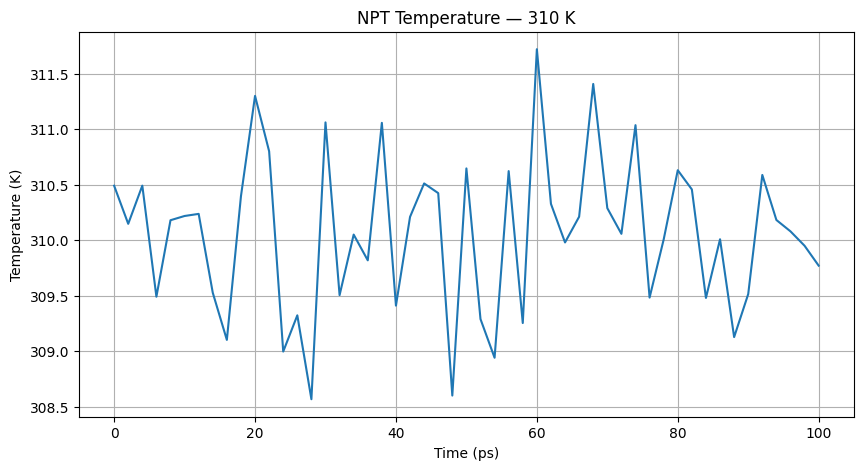

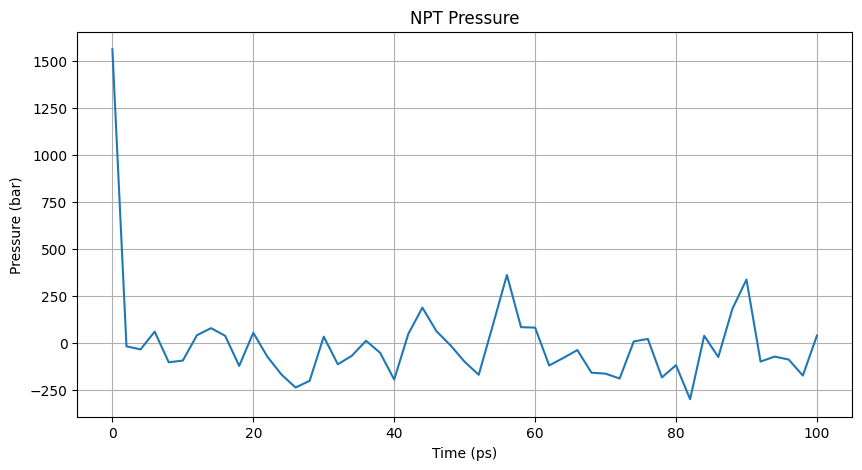

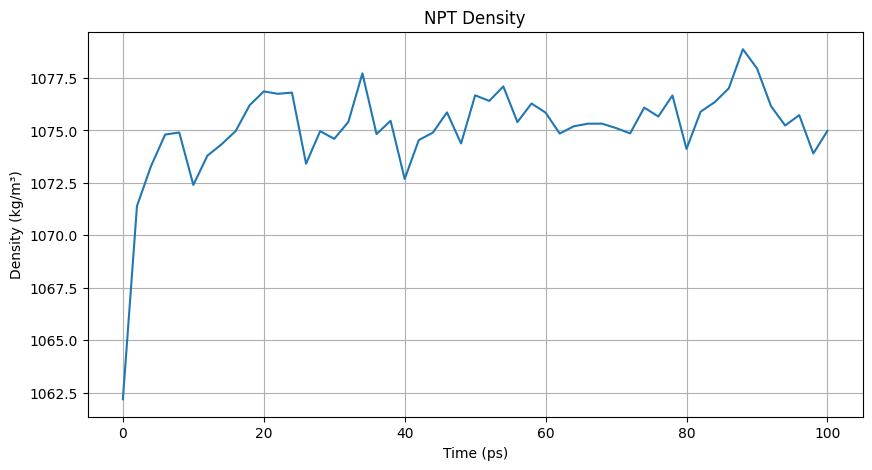

In [ ]:
import matplotlib.pyplot as plt

data = []
with open("npt_equilibration.xvg") as f:
    for line in f:
        if not line.startswith(("#", "@")):
            data.append([float(x) for x in line.split()])

import numpy as np
data = np.array(data)

plt.figure(figsize=(10,5))
plt.plot(data[:,0], data[:,1])
plt.xlabel("Time (ps)")
plt.ylabel("Temperature (K)")
plt.title("NPT Temperature — 310 K")
plt.grid()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(data[:,0], data[:,2])
plt.xlabel("Time (ps)")
plt.ylabel("Pressure (bar)")
plt.title("NPT Pressure")
plt.grid()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(data[:,0], data[:,3])
plt.xlabel("Time (ps)")
plt.ylabel("Density (kg/m³)")
plt.title("NPT Density")
plt.grid()
plt.show()

In [ ]:
import numpy as np

data = []

with open("npt_equilibration.xvg") as f:
    for line in f:
        if not line.startswith(("#", "@")):
            data.append([float(x) for x in line.split()])

data = np.array(data)

mid = len(data)//2

for name, col, unit in [
    ("Temperature", 1, "K"),
    ("Pressure", 2, "bar"),
    ("Density", 3, "kg/m³")
]:
    first = np.mean(data[:mid, col])
    second = np.mean(data[mid:, col])
    print(f"{name}:")
    print(f"  First half : {first:.3f} {unit}")
    print(f"  Second half: {second:.3f} {unit}")
    print(f"  Difference : {second-first:.3f} {unit}")
    print()

Temperature:
  First half : 309.997 K
  Second half: 310.118 K
  Difference : 0.121 K

Pressure:
  First half : 25.899 bar
  Second half: -35.423 bar
  Difference : -61.322 bar

Density:
  First half : 1074.300 kg/m³
  Second half: 1075.886 kg/m³
  Difference : 1.586 kg/m³



In [ ]:
!grep -E "^(integrator|dt|nsteps|ref_t|tcoupl|pcoupl)" md.mdp

nsteps = 500000
pcoupl = C-rescale
pcoupltype = isotropic
integrator = md
dt = 0.002
tcoupl = V-rescale
ref_t = 310 310


In [ ]:
!conda run -n gmx_cuda gmx mdrun -deffnm md -nb gpu -cpt 5 -cpnum > md_terminal.log 2>&1 &

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && conda run -n gmx_cuda gmx mdrun -deffnm md -nb gpu -cpt 5 -cpnum > md_terminal.log 2>&1 &

In [ ]:
!cat "/content/drive/MyDrive/Legumin Hexamer MD/md_terminal.log"

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -deffnm md -nb gpu -cpt 5 -cpnum


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/options/options.cpp (line 184)
Function:    void gmx::internal::OptionSectionImpl::finish()

Error in user input:
Invalid input values
  In option s
    Required option was not provided, and the default file 'topol' does not
    exist or is not accessible.
    The following extensions were tried to complete the file name:
      .tpr

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
ERROR conda.cli.main_run:execute(148): `conda

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && conda run -n gmx_cuda gmx grompp -f md.mdp -c npt.gro -p topol.top -o md.tpr

Setting the LD random seed to -1348714525

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && conda run -n gmx_cuda gmx mdrun -deffnm md -nb gpu -cpt 5 -cpnum > md_terminal.log 2>&1 &

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && tail -n 6 md.log

       Time:     8896.350     4448.185      200.0
                         1h14:08
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       19.424        1.236        8.896           22.510 
Finished mdrun on rank 0 Tue Oct  6 16:49:40 2026



In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && conda run -n gmx_cuda gmx convert-tpr -s md.tpr -extend 4000 -o md_ext.tpr

Input file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                    500000     
  Runtime for the run                             1000 ps  
  Run end step                                  500000     
  Run end time                                    1000 ps  

Extending remaining runtime by 4000 ps

Output file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                   2500000     
  Runtime for the run                             5000 ps  
  Run end step                                 2500000     
  Run end time                                    5000 ps  

             :-) GROMACS - gmx convert-tpr, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexam

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && nohup conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -deffnm md -cpi md.cpt -nb gpu -cpt 5 -cpnum -maxh 4 > md_ext_terminal.log 2>&1 &

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && conda run -n gmx_cuda gmx check -s md_ext.tpr

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -s md_ext.tpr


-------------------------------------------------------
Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
    Unknown command-line option -s

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
ERROR conda.cli.main_run:execute(148): `conda run gmx check -s md_ext.tpr` failed. (See above for error)


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && conda run -n gmx_cuda gmx dump -s md_ext.tpr | grep -E "init_step|init_t|nsteps|delta_t"

   nsteps                         = 2500000
                 :-) GROMACS - gmx dump, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx dump -s md_ext.tpr

Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)

GROMACS reminds you: "Hey, it's me - Pandora. Welcome to my new unboxing video!" (Anonymous)



In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && nohup conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -deffnm md_5ns -cpi md_step500000.cpt -nb gpu -cpt 5 -cpnum -maxh 4 > md_5ns_terminal.log 2>&1 &

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && nohup conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -deffnm md_5ns -cpi md_step500000.cpt -nb gpu -cpt 5 -cpnum -maxh 4 > md_5ns_terminal.log 2>&1 &

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && cat md_5ns_terminal.log

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_ext.tpr -deffnm md_5ns -cpi md_step500000.cpt -nb gpu -cpt 5 -cpnum -maxh 4


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/mdrunutility/handlerestart.cpp (line 212)
Function:    void gmx::{anonymous}::throwBecauseOfMissingOutputFiles(const std::filesystem::__cxx11::path&, gmx::ArrayRef<const gmx_file_position_t>, int, const t_filenm*, size_t)

Inconsistency in user input:
Some output files listed in the checkpoint file md_step500000.cpt are not
present or not named as the output files by the current program:)
Expected output files that are present:

Expected output files that are not present or named differently:
  md.log
  md.xtc
  md.edr

To keep your sim

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && nohup conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -deffnm md_5ns -cpi md_step500000.cpt -noappend -nb gpu -cpt 5 -cpnum -maxh 4 > md_5ns_terminal.log 2>&1 &

In [ ]:
!gmx check -f '#md.xtc.1#'

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f #md.xtc.1#

Value is #md.xtc.1#
Checking file #md.xtc.1#

-------------------------------------------------------
Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/fileio/trxio.cpp (line 1088)

Fatal error:
Not supported in read_first_frame: #md.xtc.1#. Please make sure that the file
is a trajectory.
GROMACS is not compiled with plug-in support. Thus it cannot read non-GROMACS
trajectory formats using the VMD plug-ins.
Please compile with plug-in support if you want to read non-GROMACS trajectory
formats.

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------


In [ ]:
!ls -lh "#md.xtc.1#" "#md.edr.1#" "#md.log.1#"

-rw------- 1 root root 65K Oct  6 16:52 '#md.edr.1#'
-rw------- 1 root root 91K Oct  6 16:52 '#md.log.1#'
-rw------- 1 root root 72M Oct  6 16:52 '#md.xtc.1#'


In [ ]:
!cp "#md.xtc.1#" md_1ns_backup.xtc

In [ ]:
!gmx check -f md_1ns_backup.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_1ns_backup.xtc

Checking file md_1ns_backup.xtc
Reading frame       0 time    0.000   
# Atoms  200254
Precision 0.001 (nm)
Last frame        100 time 1000.000   


Item        #frames Timestep (ps)
Step           101    10
Time           101    10
Lambda           0
Coords         101    10
Velocities       0
Forces           0
Box            101    10

GROMACS reminds you: "Science grows like a weed every year." (Kary Mullis)



In [ ]:
!gmx rms -s md.tpr -f md_1ns_backup.xtc -o rmsd_1ns.xvg

                 :-) GROMACS - gmx rms, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx rms -s md.tpr -f md_1ns_backup.xtc -o rmsd_1ns.xvg

Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for least squares fit
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 32220 elements
Group     9 (    SideChain-H) has 12024 elements
Group    10 (    Prot-Masses) has 46974 elements
Group    11 (    non-Protein) ha

In [ ]:
!gmx rms -s md.tpr -f md_1ns_backup.xtc -o rmsd_1ns.xvg

                 :-) GROMACS - gmx rms, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx rms -s md.tpr -f md_1ns_backup.xtc -o rmsd_1ns.xvg

Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for least squares fit
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 32220 elements
Group     9 (    SideChain-H) has 12024 elements
Group    10 (    Prot-Masses) has 46974 elements
Group    11 (    non-Protein) ha

In [ ]:
!gmx gyrate -s md.tpr -f md_1ns_backup.xtc -o rg_1ns.xvg

                :-) GROMACS - gmx gyrate, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx gyrate -s md.tpr -f md_1ns_backup.xtc -o rg_1ns.xvg

Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Available static index groups:
 Group  0 "System" (200254 atoms)
 Group  1 "Protein" (46974 atoms)
 Group  2 "Protein-H" (23934 atoms)
 Group  3 "C-alpha" (2976 atoms)
 Group  4 "Backbone" (8928 atoms)
 Group  5 "MainChain" (11910 atoms)
 Group  6 "MainChain+Cb" (14664 atoms)
 Group  7 "MainChain+H" (14754 atoms)
 Group  8 "SideChain" (32220 atoms)
 Group  9 "SideChain-H" (12024 atoms)
 Group 10 "Prot-Masses" (46974 atoms)
 Group 11 "non-Protein" (153280 atoms)
 Group 12 "Water" (152886 atoms)
 Group 13 "SOL" (152886 atoms)
 Group 14 "non-Water" (47368 atoms)
 Group 15 "Ion" (394 atoms)
 Group 16 

In [ ]:
!gmx rmsf -s md.tpr -f md_1ns_backup.xtc -o rmsf_1ns.xvg -res

                 :-) GROMACS - gmx rmsf, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx rmsf -s md.tpr -f md_1ns_backup.xtc -o rmsf_1ns.xvg -res

Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Select group(s) for root mean square calculation
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 32220 elements
Group     9 (    SideChain-H) has 12024 elements
Group    10 (    Prot-Masses) has 46974 elements
Group    11

In [ ]:
!gmx sasa -s md.tpr -f md_1ns_backup.xtc -o sasa_1ns.xvg

                 :-) GROMACS - gmx sasa, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx sasa -s md.tpr -f md_1ns_backup.xtc -o sasa_1ns.xvg

Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Available static index groups:
 Group  0 "System" (200254 atoms)
 Group  1 "Protein" (46974 atoms)
 Group  2 "Protein-H" (23934 atoms)
 Group  3 "C-alpha" (2976 atoms)
 Group  4 "Backbone" (8928 atoms)
 Group  5 "MainChain" (11910 atoms)
 Group  6 "MainChain+Cb" (14664 atoms)
 Group  7 "MainChain+H" (14754 atoms)
 Group  8 "SideChain" (32220 atoms)
 Group  9 "SideChain-H" (12024 atoms)
 Group 10 "Prot-Masses" (46974 atoms)
 Group 11 "non-Protein" (153280 atoms)
 Group 12 "Water" (152886 atoms)
 Group 13 "SOL" (152886 atoms)
 Group 14 "non-Water" (47368 atoms)
 Group 15 "Ion" (394 atoms)
 Group 16 "

In [ ]:
!gmx hbond -s md.tpr -f md_1ns_backup.xtc -o hbonds_1ns.xvg

                :-) GROMACS - gmx hbond, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx hbond -s md.tpr -f md_1ns_backup.xtc -o hbonds_1ns.xvg


-------------------------------------------------------
Program:     gmx hbond, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -o
    File name 'hbonds_1ns.xvg' cannot be used for this option.
    Only the following extensions are possible:
      .ndx

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------


In [ ]:
!cp "#md.edr.1#" md_1ns_backup.edr

In [ ]:
!gmx energy -f md_1ns_backup.edr -o energy_1ns.xvg

                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx energy -f md_1ns_backup.edr -o energy_1ns.xvg

Opened md_1ns_backup.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential       12  Kinetic-En.   
 13  Total-Energy    14  Conserved-En.   15  Temperature     16  Pres.-DC      
 17  Pressure        18  Constr.-rmsd    19  Box-X           20  Box-Y         
 21  Box-Z           22  Volume          23  Den

In [ ]:
!gmx hbond -s md.tpr -f md_1ns_backup.xtc -num hbnum_1ns.xvg

                :-) GROMACS - gmx hbond, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx hbond -s md.tpr -f md_1ns_backup.xtc -num hbnum_1ns.xvg

Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Available static index groups:
 Group  0 "System" (200254 atoms)
 Group  1 "Protein" (46974 atoms)
 Group  2 "Protein-H" (23934 atoms)
 Group  3 "C-alpha" (2976 atoms)
 Group  4 "Backbone" (8928 atoms)
 Group  5 "MainChain" (11910 atoms)
 Group  6 "MainChain+Cb" (14664 atoms)
 Group  7 "MainChain+H" (14754 atoms)
 Group  8 "SideChain" (32220 atoms)
 Group  9 "SideChain-H" (12024 atoms)
 Group 10 "Prot-Masses" (46974 atoms)
 Group 11 "non-Protein" (153280 atoms)
 Group 12 "Water" (152886 atoms)
 Group 13 "SOL" (152886 atoms)
 Group 14 "non-Water" (47368 atoms)
 Group 15 "Ion" (394 atoms)
 Group 

In [ ]:
!ls -lh rmsd_1ns.xvg rg_1ns.xvg rmsf_1ns.xvg sasa_1ns.xvg hbnum_1ns.xvg energy_1ns.xvg

-rw------- 1 root root  16K Oct  6 18:48 energy_1ns.xvg
-rw------- 1 root root 3.0K Oct  6 18:49 hbnum_1ns.xvg
-rw------- 1 root root 5.5K Oct  6 18:43 rg_1ns.xvg
-rw------- 1 root root 3.2K Oct  6 18:41 rmsd_1ns.xvg
-rw------- 1 root root  45K Oct  6 18:44 rmsf_1ns.xvg
-rw------- 1 root root 2.8K Oct  6 18:45 sasa_1ns.xvg


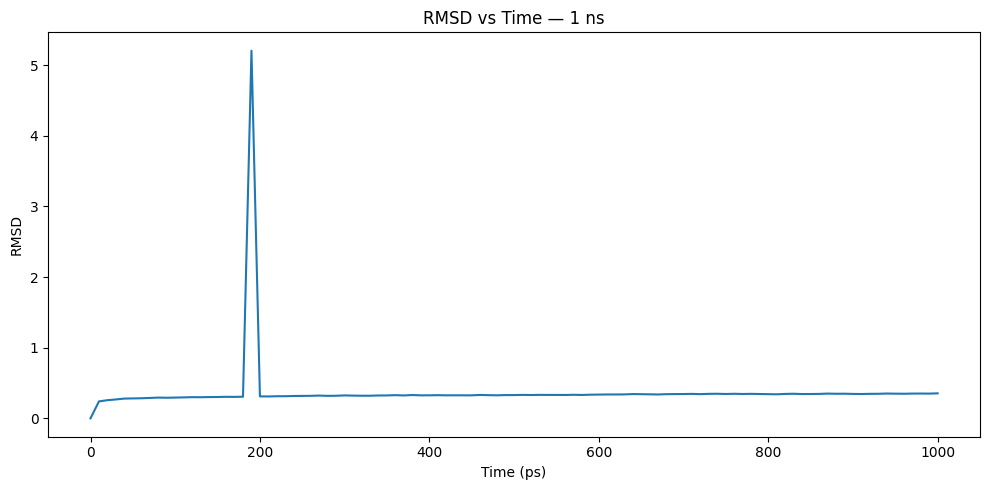

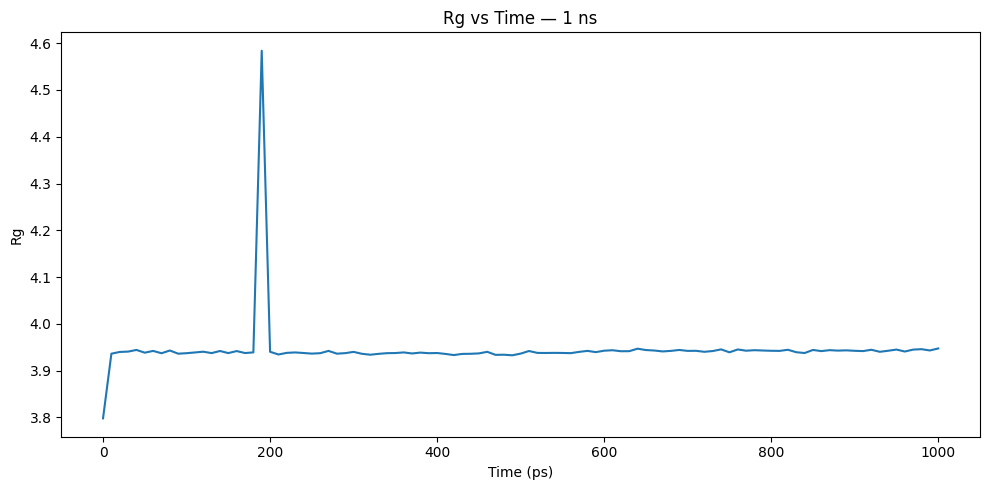

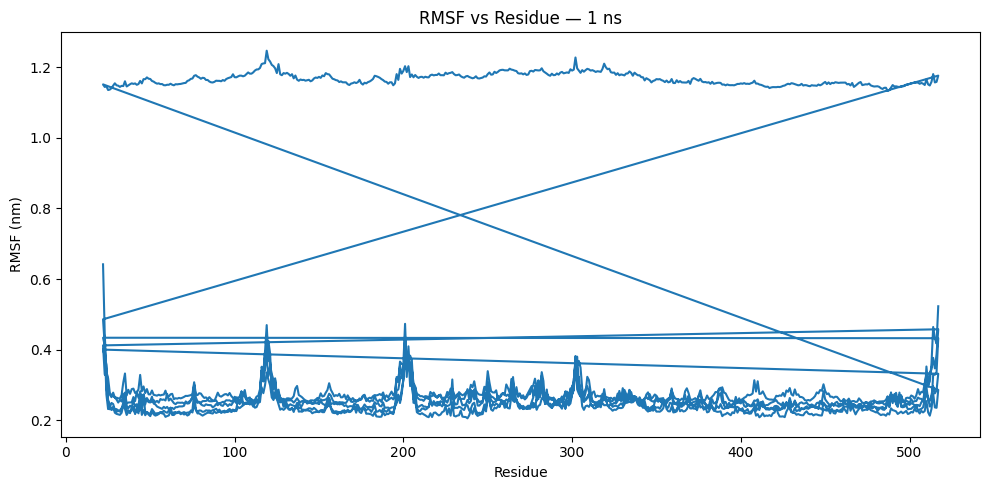

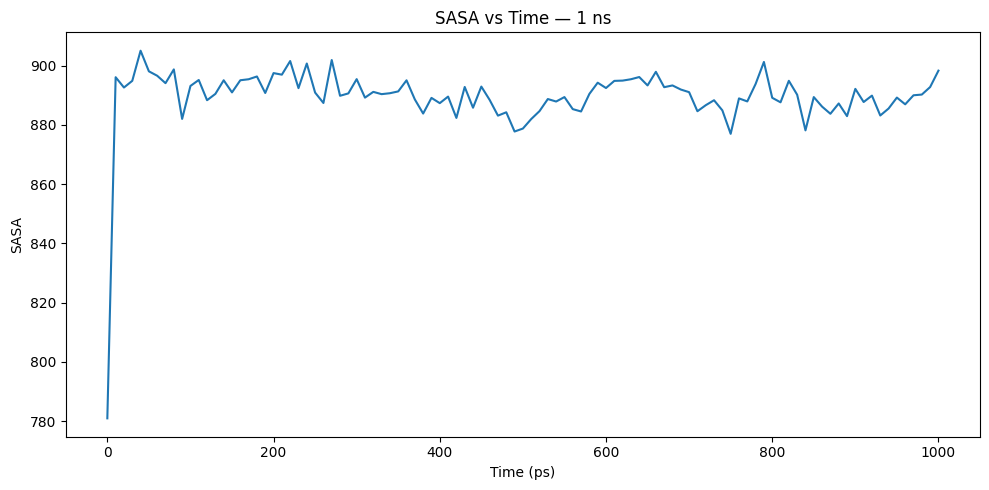

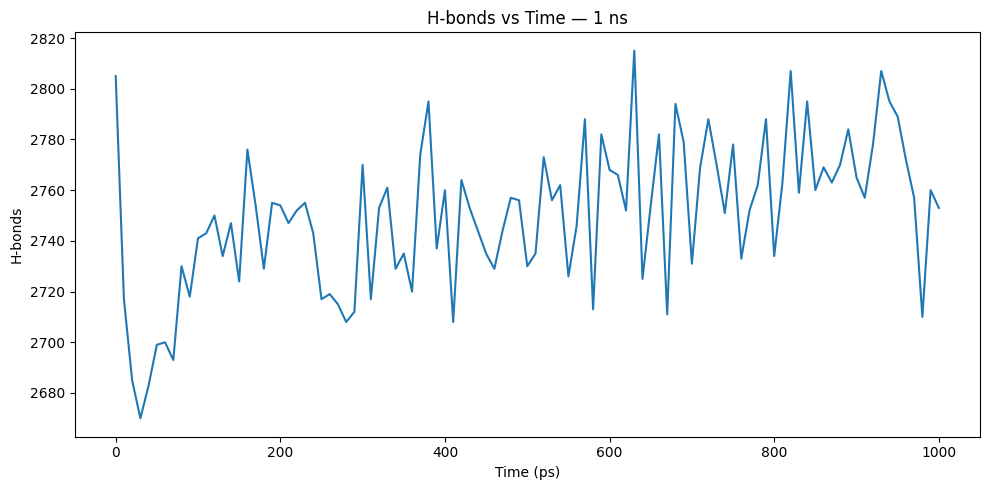

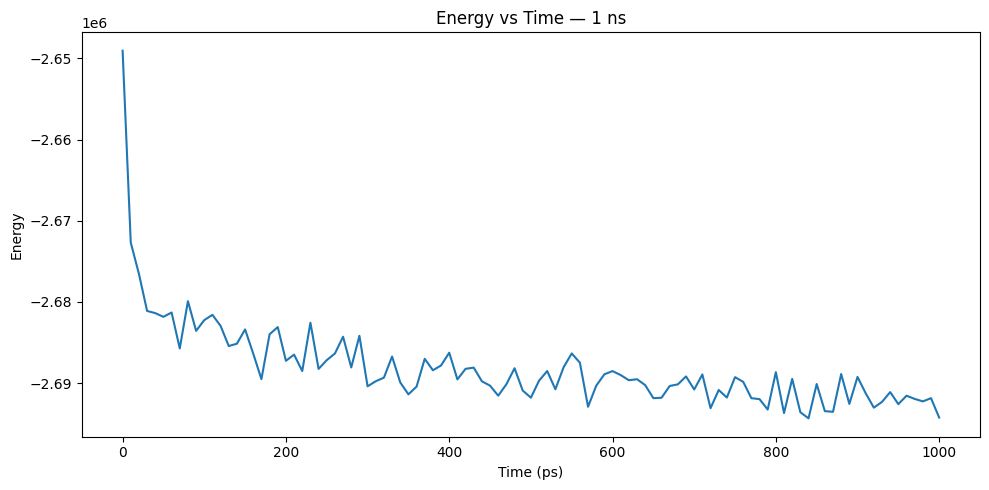

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

files = {
    "RMSD": "rmsd_1ns.xvg",
    "Rg": "rg_1ns.xvg",
    "RMSF": "rmsf_1ns.xvg",
    "SASA": "sasa_1ns.xvg",
    "H-bonds": "hbnum_1ns.xvg",
    "Energy": "energy_1ns.xvg"
}

def read_xvg(filename):
    data = []
    with open(filename) as f:
        for line in f:
            if line.startswith(("@", "#")):
                continue
            parts = line.split()
            if len(parts) >= 2:
                try:
                    data.append([float(x) for x in parts])
                except ValueError:
                    pass
    return np.array(data)

# Plot each analysis separately
for name, filename in files.items():
    if not os.path.exists(filename):
        print(f"Missing: {filename}")
        continue

    data = read_xvg(filename)

    if data.size == 0:
        print(f"No readable data: {filename}")
        continue

    plt.figure(figsize=(10, 5))

    if name == "Energy":
        # Energy file contains multiple columns
        plt.plot(data[:,0], data[:,1])
        plt.xlabel("Time (ps)")
        plt.ylabel("Energy")
        plt.title("Energy vs Time — 1 ns")
    elif name == "RMSF":
        plt.plot(data[:,0], data[:,1])
        plt.xlabel("Residue")
        plt.ylabel("RMSF (nm)")
        plt.title("RMSF vs Residue — 1 ns")
    else:
        plt.plot(data[:,0], data[:,1])
        plt.xlabel("Time (ps)")
        plt.ylabel(name)
        plt.title(f"{name} vs Time — 1 ns")

    plt.tight_layout()
    plt.show()

In [ ]:
!gmx make_ndx -f md.tpr -o chains_1ns.ndx

               :-) GROMACS - gmx make_ndx, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx make_ndx -f md.tpr -o chains_1ns.ndx


Reading structure file
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Going to read 0 old index file(s)
Analysing residue names:
There are:  2976    Protein residues
There are: 50962      Water residues
There are:   394        Ion residues
Analysing Protein...

  0 System              : 200254 atoms
  1 Protein             : 46974 atoms
  2 Protein-H           : 23934 atoms
  3 C-alpha             :  2976 atoms
  4 Backbone            :  8928 atoms
  5 MainChain           : 11910 atoms
  6 MainChain+Cb        : 14664 atoms
  7 MainChain+H         : 14754 atoms
  8 SideChain           : 32220 atoms
  9 SideChain-H         : 12024 atoms
 10 Prot-Masses      

In [ ]:
!gmx rmsf -s md.tpr -f md_1ns_backup.xtc -o rmsf_1ns.xvg -res

                 :-) GROMACS - gmx rmsf, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx rmsf -s md.tpr -f md_1ns_backup.xtc -o rmsf_1ns.xvg -res

Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Select group(s) for root mean square calculation
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 32220 elements
Group     9 (    SideChain-H) has 12024 elements
Group    10 (    Prot-Masses) has 46974 elements
Group    11

In [ ]:
!gmx make_ndx -f md.tpr -o chains_1ns.ndx

               :-) GROMACS - gmx make_ndx, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx make_ndx -f md.tpr -o chains_1ns.ndx


Reading structure file
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Going to read 0 old index file(s)
Analysing residue names:
There are:  2976    Protein residues
There are: 50962      Water residues
There are:   394        Ion residues
Analysing Protein...

  0 System              : 200254 atoms
  1 Protein             : 46974 atoms
  2 Protein-H           : 23934 atoms
  3 C-alpha             :  2976 atoms
  4 Backbone            :  8928 atoms
  5 MainChain           : 11910 atoms
  6 MainChain+Cb        : 14664 atoms
  7 MainChain+H         : 14754 atoms
  8 SideChain           : 32220 atoms
  9 SideChain-H         : 12024 atoms
 10 Prot-Masses      

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"
!ls -lh --time-style=long-iso *md.xtc* *md.edr* *md.log*
!cp "#md.xtc.1#" md_run1.xtc
!cp "#md.edr.1#" md_run1.edr
!cp "#md.log.1#" md_run1.log

-rw------- 1 root root 49K 2026-10-06 17:48  md.edr
-rw------- 1 root root 65K 2026-10-06 16:52 '#md.edr.1#'
-rw------- 1 root root 72K 2026-10-06 17:48  md.log
-rw------- 1 root root 91K 2026-10-06 16:52 '#md.log.1#'
-rw------- 1 root root 54M 2026-10-06 17:48  md.xtc
-rw------- 1 root root 72M 2026-10-06 16:52 '#md.xtc.1#'


In [ ]:
!gmx check -f md_run1.xtc 2>&1 | grep -i -E "step|time|frame"

Reading frame       0 time    0.000   
Last frame        100 time 1000.000   
Item        #frames Timestep (ps)
Step           101    10
Time           101    10


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && mkdir -p run1 && cp md.tpr run1/md_run1.tpr && mv md_run1.xtc md_run1.edr md_run1.log run1/ && ls -lh run1

total 88M
-rw------- 1 root root 65K Oct  7 12:23 md_run1.edr
-rw------- 1 root root 91K Oct  7 12:23 md_run1.log
-rw------- 1 root root 16M Oct  7 12:27 md_run1.tpr
-rw------- 1 root root 72M Oct  7 12:23 md_run1.xtc


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD/run1" && echo 1 1 0 | gmx trjconv -s md_run1.tpr -f md_run1.xtc -o md_run1_c.xtc -pbc cluster -center

               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD/run1
Command line:
  gmx trjconv -s md_run1.tpr -f md_run1.xtc -o md_run1_c.xtc -pbc cluster -center

Note that major changes are planned in future for trjconv, to improve usability and utility.
Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file md_run1.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_run1.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for clustering
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 1

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD/run1" && echo 1 | gmx gyrate -s md_run1.tpr -f md_run1_c.xtc -o rg.xvg

                :-) GROMACS - gmx gyrate, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD/run1
Command line:
  gmx gyrate -s md_run1.tpr -f md_run1_c.xtc -o rg.xvg

Reading file md_run1.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_run1.tpr, VERSION 2026.3-conda_forge (single precision)
Last frame        100 time 1000.000   
Analyzed 101 frames, last time 1000.000

GROMACS reminds you: "The programmer got stuck in the shower because the instructions on the shampoo bottle said: Lather, Rinse, Repeat." (Anonymous)



In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD/run1" && echo 4 4 | gmx rms -s md_run1.tpr -f md_run1_c.xtc -o rmsd_bb.xvg

                 :-) GROMACS - gmx rms, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD/run1
Command line:
  gmx rms -s md_run1.tpr -f md_run1_c.xtc -o rmsd_bb.xvg

Reading file md_run1.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_run1.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for least squares fit
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 32220 elements
Group     9 (    SideChain-H) has 12024 elements
Group    10 (    Prot-Masses) has 46974 elements
Group    11 (    

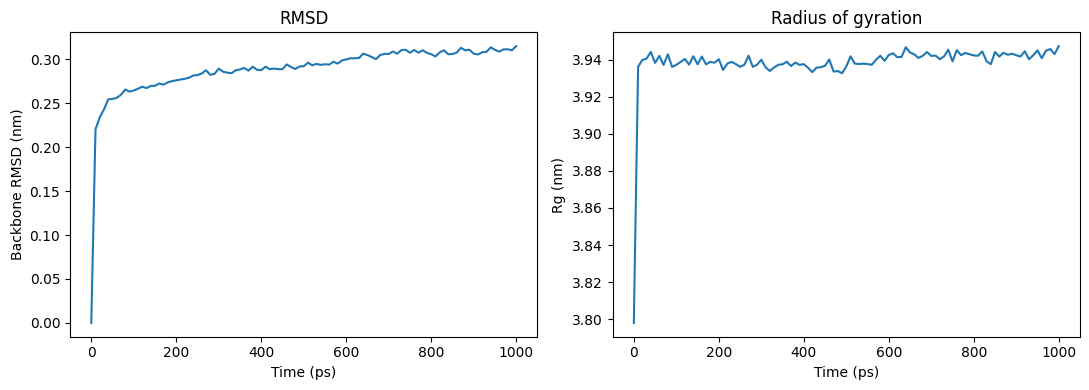

RMSD max: 0.315 nm at 1000 ps
RMSD last: 0.315 nm
Rg min/max: 3.798 / 3.947 nm


In [ ]:
import numpy as np, matplotlib.pyplot as plt
d = "/content/drive/MyDrive/Legumin Hexamer MD/run1/"

def load(f):
    return np.loadtxt(d + f, comments=("#", "@"))

rmsd = load("rmsd_bb.xvg")   # time (ps), RMSD (nm)
rg   = load("rg.xvg")        # time (ps), Rg total, Rg x, y, z (nm)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(rmsd[:, 0], rmsd[:, 1])
ax[0].set(xlabel="Time (ps)", ylabel="Backbone RMSD (nm)", title="RMSD")
ax[1].plot(rg[:, 0], rg[:, 1])
ax[1].set(xlabel="Time (ps)", ylabel="Rg (nm)", title="Radius of gyration")
plt.tight_layout()
plt.show()

print("RMSD max: %.3f nm at %d ps" % (rmsd[:, 1].max(), rmsd[rmsd[:, 1].argmax(), 0]))
print("RMSD last: %.3f nm" % rmsd[-1, 1])
print("Rg min/max: %.3f / %.3f nm" % (rg[:, 1].min(), rg[:, 1].max()))

In [ ]:
!conda env list


# conda environments:
#
# * -> active
# + -> frozen
base                     /usr/local



In [ ]:
!conda run -n gmx_cuda gmx --version


EnvironmentLocationNotFound: Not a conda environment: /usr/local/envs/gmx_cuda



In [ ]:
!conda env list


# conda environments:
#
# * -> active
# + -> frozen
base                     /usr/local



In [ ]:
!conda create -n gmx_cuda -c conda-forge gromacs=2026.3 -y

Retrieving notices: - \ done
Channels:
 - conda-forge
Platform: linux-64
Solving environment: | / done

## Package Plan ##

  environment location: /usr/local/envs/gmx_cuda

  added / updated specs:
    - gromacs=2026.3


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    icu-78.3                   |  py310h44b86e0_2        13.8 MB  conda-forge
    libgcc-16.2.0              |       ha9f2e26_7         1.0 MB  conda-forge
    libgfortran-16.2.0         |       h69a702a_7          28 KB  conda-forge
    libgfortran5-16.2.0        |       h6b99dfc_7         2.4 MB  conda-forge
    libgomp-16.2.0             |       he0feb66_7         626 KB  conda-forge
    libiconv-1.18              |       h0cb94f2_3         771 KB  conda-forge
    liblzma-5.8.3              |       hb03c661_1         110 KB  conda-forge
    libstdcxx-16.2.0           |       h934c35e_7         6.3 MB  conda-forge
  

In [ ]:
!conda run -n gmx_cuda gmx --version

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/b

In [ ]:
!conda create -n gmx_cuda -c conda-forge gromacs=2026.3 opencl-headers ocl-icd-system -y

Channels:
 - conda-forge
Platform: linux-64
Solving environment: | / done

## Package Plan ##

  environment location: /usr/local/envs/gmx_cuda

  added / updated specs:
    - gromacs=2026.3
    - ocl-icd-system
    - opencl-headers


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ocl-icd-system-1.0.0       |                1           4 KB  conda-forge
    ------------------------------------------------------------
                                           Total:           4 KB

The following NEW packages will be INSTALLED:

  _openmp_mutex      conda-forge/linux-64::_openmp_mutex-4.5-20_gnu 
  fftw               conda-forge/linux-64::fftw-3.3.11-nompi_h3b011a4_100 
  gromacs            conda-forge/linux-64::gromacs-2026.3-nompi_h26635d9_100 
  libgcc             conda-forge/linux-64::libgcc-16.2.0-ha9f2e26_7 
  libgfortran        conda-forge/linux-64::libgfortran-16.2.0-h69a702a

In [ ]:
!conda run -n gmx_cuda gmx --version

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         OpenCL
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     clFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root

In [ ]:
!conda remove -n gmx_cuda --all -y


Remove all packages in environment /usr/local/envs/gmx_cuda:


## Package Plan ##

  environment location: /usr/local/envs/gmx_cuda


The following packages will be REMOVED:

  _openmp_mutex-4.5-20_gnu
  fftw-3.3.11-nompi_h3b011a4_100
  gromacs-2026.3-nompi_h26635d9_100
  libgcc-16.2.0-ha9f2e26_7
  libgfortran-16.2.0-h69a702a_7
  libgfortran5-16.2.0-h6b99dfc_7
  libgomp-16.2.0-he0feb66_7
  libhwloc-2.13.0-default_he001693_1000
  libiconv-1.18-h0cb94f2_3
  liblzma-5.8.3-hb03c661_1
  libstdcxx-16.2.0-h934c35e_7
  libxml2-2.15.4-ha7a5771_0
  libxml2-16-2.15.4-hbdfff7e_0
  libzlib-1.3.2-h25fd6f3_3
  ocl-icd-2.3.4-hb03c661_1
  ocl-icd-system-1.0.0-1
  opencl-headers-2025.06.13-hecca717_0




Preparing transaction: - done
Verifying transaction: | / - done
Executing transaction: | done


In [ ]:
!conda create -n gmx_cuda -c conda-forge gromacs=2026.3 cuda-version=12.4 -y

Channels:
 - conda-forge
Platform: linux-64
Solving environment: \ | done

## Package Plan ##

  environment location: /usr/local/envs/gmx_cuda

  added / updated specs:
    - cuda-version=12.4
    - gromacs=2026.3


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    cuda-version-12.4          |       h3060b56_3          21 KB  conda-forge
    ------------------------------------------------------------
                                           Total:          21 KB

The following NEW packages will be INSTALLED:

  _openmp_mutex      conda-forge/linux-64::_openmp_mutex-4.5-20_gnu 
  cuda-version       conda-forge/noarch::cuda-version-12.4-h3060b56_3 
  fftw               conda-forge/linux-64::fftw-3.3.11-nompi_h3b011a4_100 
  gromacs            conda-forge/linux-64::gromacs-2026.3-nompi_h26635d9_100 
  libgcc             conda-forge/linux-64::libgcc-16.2.0-ha9f2e26_7 
  libgfortran    

In [ ]:
!conda run -n gmx_cuda gmx --version

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         OpenCL
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     clFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root

In [ ]:
!conda remove -n gmx_cuda --all -y


Remove all packages in environment /usr/local/envs/gmx_cuda:


## Package Plan ##

  environment location: /usr/local/envs/gmx_cuda


The following packages will be REMOVED:

  _openmp_mutex-4.5-20_gnu
  cuda-version-12.4-h3060b56_3
  fftw-3.3.11-nompi_h3b011a4_100
  gromacs-2026.3-nompi_h26635d9_100
  libgcc-16.2.0-ha9f2e26_7
  libgfortran-16.2.0-h69a702a_7
  libgfortran5-16.2.0-h6b99dfc_7
  libgomp-16.2.0-he0feb66_7
  libhwloc-2.13.0-default_he001693_1000
  libiconv-1.18-h0cb94f2_3
  liblzma-5.8.3-hb03c661_1
  libstdcxx-16.2.0-h934c35e_7
  libxml2-2.15.4-ha7a5771_0
  libxml2-16-2.15.4-hbdfff7e_0
  libzlib-1.3.2-h25fd6f3_3
  ocl-icd-2.3.4-hb03c661_1
  opencl-headers-2025.06.13-hecca717_0




Preparing transaction: - done
Verifying transaction: | / - done
Executing transaction: | done


In [ ]:
!conda search -c conda-forge "gromacs*"

Loading channels: - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ | / - \ 

In [ ]:
!nvidia-smi

Wed Oct  7 13:00:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!conda create -n gmx_cuda -c conda-forge "gromacs=2026.3=nompi_cuda_h39c90b0_0" -y

Channels:
 - conda-forge
Platform: linux-64
Solving environment: - \ | done

## Package Plan ##

  environment location: /usr/local/envs/gmx_cuda

  added / updated specs:
    - gromacs==2026.3=nompi_cuda_h39c90b0_0


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    gdb-14.2                   |  py312heaf2220_0         6.0 MB  conda-forge
    libpython-3.12.15          |h0c77377_1_cpython         8.4 MB  conda-forge
    python-3.12.15             |h5f976f7_1_cpython        22.0 MB  conda-forge
    python_abi-3.12            |          9_cp312           7 KB  conda-forge
    ------------------------------------------------------------
                                           Total:        36.4 MB

The following NEW packages will be INSTALLED:

  _openmp_mutex      conda-forge/linux-64::_openmp_mutex-4.5-20_gnu 
  alsa-lib           conda-forge/linux-64::alsa-lib-1.2.16.1-h7cc23a3_1

In [ ]:
!conda run -n gmx_cuda gmx --version

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/b

In [ ]:
!conda run -n gmx_cuda gmx mdrun -version

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstoc

In [ ]:
!conda run -n gmx_cuda gmx check -f md_5ns_step702320.cpt

Checking file md_5ns_step702320.cpt
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_5ns_step702320.cpt


# Atoms  200254

Last frame         -1 time 1404.640   


Item        #frames Timestep (ps)
Step             1
Time             1
Lambda           1
Coords           1
Velocities       1
Forces           0
Box              1

GROMACS reminds you: "We can make it into a friend class. But I don't like having friends." (Joe Jordan)



In [ ]:
!conda run -n gmx_cuda gmx check -s md_ext.tpr

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -s md_ext.tpr


-------------------------------------------------------
Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
    Unknown command-line option -s

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
ERROR conda.cli.main_run:execute(148): `conda run gmx check -s md_ext.tpr` failed. (See above for error)


In [ ]:
!conda run -n gmx_cuda gmx dump -s md_ext.tpr | grep -E "init_t|tinit|nsteps|delta_t"

   tinit                          = 0
   nsteps                         = 2500000
                 :-) GROMACS - gmx dump, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx dump -s md_ext.tpr

Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)

GROMACS reminds you: "The Path Of the Righteous Man is Beset On All Sides With the Iniquities Of the Selfish and the Tyranny Of Evil Men." (Pulp Fiction)



In [ ]:
!conda run -n gmx_cuda gmx check -f md_5ns_step702320.cpt

Checking file md_5ns_step702320.cpt
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_5ns_step702320.cpt


# Atoms  200254

Last frame         -1 time 1404.640   


Item        #frames Timestep (ps)
Step             1
Time             1
Lambda           1
Coords           1
Velocities       1
Forces           0
Box              1

GROMACS reminds you: "AH ....Satisfaction" (IRIX imapd)



In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"

nohup conda run -n gmx_cuda gmx mdrun \
-s md_ext.tpr \
-cpi md_5ns_step702320.cpt \
-deffnm md_5ns \
-nb gpu \
-cpt 5 \
-cpnum \
> md_5ns_continue.log 2>&1 &

In [ ]:
!tail -40 "/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_continue.log"

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -nb gpu -cpt 5 -cpnum


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/mdrunutility/handlerestart.cpp (line 212)
Function:    void gmx::{anonymous}::throwBecauseOfMissingOutputFiles(const std::filesystem::__cxx11::path&, gmx::ArrayRef<const gmx_file_position_t>, int, const t_filenm*, size_t)

Inconsistency in user input:
Some output files listed in the checkpoint file md_5ns_step702320.cpt are not
present or not named as the output files by the current program:)
Expected output files that are present:

Expected output files that are not present or named differently:
  md_5ns.part0002.log
  md_5ns.part0002.xtc


In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"

nohup conda run -n gmx_cuda gmx mdrun \
-s md_ext.tpr \
-cpi md_5ns_step702320.cpt \
-deffnm md_5ns \
-noappend \
-nb gpu \
-cpt 5 \
-cpnum \
> md_5ns_continue.log 2>&1 &

In [ ]:
!cat "/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_continue.log"

In [ ]:
!ps aux | grep "[g]mx mdrun"

root       11127  0.5  0.4 116684 57856 ?        S    13:16   0:00 /usr/local/bin/python /usr/local/bin/conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum
root       11196 88.1  3.4 5738464 463660 ?      Rl   13:16   1:14 gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum
root       11239  0.6  0.4 116688 58324 ?        S    13:16   0:00 /usr/local/bin/python /usr/local/bin/conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum
root       11305 75.1  3.3 5684120 438656 ?      Rl   13:17   0:53 gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum


In [ ]:
!kill 11305

In [ ]:
!ps aux | grep "[g]mx mdrun"

root       11127  0.2  0.4 116684 57856 ?        S    13:16   0:00 /usr/local/bin/python /usr/local/bin/conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum
root       11196 98.3  3.4 5738464 463676 ?      Rl   13:16   2:59 gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum


In [ ]:
!tail -30 "/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_continue.log"



1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 2 OpenMP threads 


Back Off! I just backed up md_5ns.part0003.xtc to ./#md_5ns.part0003.xtc.1#

Back Off! I just backed up md_5ns.part0003.edr to ./#md_5ns.part0003.edr.1#
starting mdrun 'Protein in water'
2500000 steps,   5000.0 ps (continuing from step 702320,   1404.6 ps).


Received the TERM signal, stopping within 80 steps


               Core t (s)   Wall t (s)        (%)
       Time:      248.017      124.015      200.0
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:        6.467        3.711       26.722            7.494 

GROMACS reminds you: "The most exciting phrase to hear in science, the one that heralds new discoveries, is not "Eureka" but 

In [ ]:
!ps aux | grep "[g]mx mdrun"

root       11127  0.1  0.4 116684 57856 ?        S    13:16   0:00 /usr/local/bin/python /usr/local/bin/conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum
root       11196  132  3.4 5738464 463696 ?      Rl   13:16   7:55 gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum


In [ ]:
!ls -lh "/content/drive/MyDrive/Legumin Hexamer MD"/md_5ns.part0003*

-rw------- 1 root root 2.4K Oct  7 13:19 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns.part0003.edr'
-rw------- 1 root root  28K Oct  7 13:19 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns.part0003.log'
-rw------- 1 root root 730K Oct  7 13:18 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns.part0003.xtc'


In [ ]:
!tail -20 "/content/drive/MyDrive/Legumin Hexamer MD/md_5ns.part0003.log"

 Write traj.               1    2          2       0.273          1.092   0.2
 GPU constr. setup         1    2          1       0.018          0.074   0.0
 Kinetic energy            1    2       1857       7.145         28.580   5.8
 Rest                                              7.543         30.174   6.1
--------------------------------------------------------------------------------
 Total                                           124.015        496.059 100.0
--------------------------------------------------------------------------------
 Breakdown of PME mesh activities
--------------------------------------------------------------------------------
 Wait PME GPU gather       1    2       4641       0.011          0.043   0.0
 Reduce GPU PME F          1    2       4641       0.345          1.379   0.3
 Launch PME GPU ops.       1    2      37128       0.640          2.559   0.5
--------------------------------------------------------------------------------

               Co

In [ ]:
!ps aux | grep "[g]mx mdrun"

root       11127  0.0  0.4 116684 57856 ?        S    13:16   0:00 /usr/local/bin/python /usr/local/bin/conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum
root       11196  145  3.4 5738464 463712 ?      Rl   13:16  13:24 gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum


In [ ]:
!ls -lh "/content/drive/MyDrive/Legumin Hexamer MD"/md_5ns_step*.cpt

-rw------- 1 root root 4.6M Oct  6 18:00 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step532800.cpt'
-rw------- 1 root root 4.6M Oct  6 18:05 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step566640.cpt'
-rw------- 1 root root 4.6M Oct  6 18:10 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step600800.cpt'
-rw------- 1 root root 4.6M Oct  6 18:15 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step634960.cpt'
-rw------- 1 root root 4.6M Oct  6 18:20 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step668720.cpt'
-rw------- 1 root root 4.6M Oct  6 18:25 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step702320.cpt'
-rw------- 1 root root 4.6M Oct  7 13:19 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step706960.cpt'
-rw------- 1 root root 4.6M Oct  7 13:21 '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step722800.cpt'


In [ ]:
!ps aux | grep "[g]mx mdrun"

root       11127  0.0  0.4 116684 57856 ?        S    13:16   0:00 /usr/local/bin/python /usr/local/bin/conda run -n gmx_cuda gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum
root       11196  149  3.4 5738464 463712 ?      Rl   13:16  16:14 gmx mdrun -s md_ext.tpr -cpi md_5ns_step702320.cpt -deffnm md_5ns -noappend -nb gpu -cpt 5 -cpnum


In [ ]:
!ps -o pid,ppid,stat,etime,pcpu,pmem,cmd -p 11127,11196

    PID    PPID STAT     ELAPSED %CPU %MEM CMD
  11127       1 S          11:56  0.0  0.4 /usr/local/bin/python /usr/local/bin/
  11196   11128 Rl         11:53  150  3.4 gmx mdrun -s md_ext.tpr -cpi md_5ns_s


In [ ]:
!tail -5 "/content/drive/MyDrive/Legumin Hexamer MD/md_5ns.part0003.log"

       Time:      248.017      124.015      200.0
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:        6.467        3.711       26.722            7.494 
Finished mdrun on rank 0 Wed Oct  7 13:19:20 2026



In [ ]:
!kill 11196

In [ ]:
!ps -o pid,ppid,stat,etime,pcpu,pmem,cmd -p 11127,11196

    PID    PPID STAT     ELAPSED %CPU %MEM CMD


In [ ]:
!ps aux | grep "[g]mx mdrun"

In [ ]:
!conda run -n gmx_cuda gmx check -f "/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step772320.cpt"

Checking file /content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step772320.cpt
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f '/content/drive/MyDrive/Legumin Hexamer MD/md_5ns_step772320.cpt'


# Atoms  200254

Last frame         -1 time 1544.640   


Item        #frames Timestep (ps)
Step             1
Time             1
Lambda           1
Coords           1
Velocities       1
Forces           0
Box              1

GROMACS reminds you: "FORTRAN, the infantile disorder, by now nearly 20 years old, is hopelessly inadequate for whatever computer application you have in mind today: it is now too clumsy, too risky, and too expensive to use." (Edsger Dijkstra, 1970)



In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"

conda run -n gmx_cuda gmx mdrun \
-s md_ext.tpr \
-cpi md_5ns_step772320.cpt \
-deffnm md_5ns \
-noappend \
-nb gpu \
-cpt 5 \
-cpnum

In [ ]:
D = "/content/drive/MyDrive/Legumin Hexamer MD"
!cd "{D}" && ls -lh md_5ns* | head -50
!cd "{D}" && for f in md_5ns.part*.xtc; do echo "== $f"; gmx check -f "$f" 2>&1 | grep -E "Reading frame|Last frame|#frames"; done
!cd "{D}" && tail -n 8 md_5ns.part0004.log

-rw------- 1 root root 2.1K Oct  7 13:30 md_5ns_continue.log
-rw------- 1 root root  27K Oct  6 18:25 md_5ns.part0002.edr
-rw------- 1 root root  48K Oct  6 18:25 md_5ns.part0002.log
-rw------- 1 root root  30M Oct  6 18:25 md_5ns.part0002.xtc
-rw------- 1 root root 2.4K Oct  7 13:17 md_5ns.part0003.edr
-rw------- 1 root root  28K Oct  7 13:17 md_5ns.part0003.log
-rw------- 1 root root 730K Oct  7 13:17 md_5ns.part0003.xtc
-rw------- 1 root root  63K Oct  7 15:00 md_5ns.part0004.edr
-rw------- 1 root root  83K Oct  7 15:00 md_5ns.part0004.log
-rw------- 1 root root  66M Oct  7 14:55 md_5ns.part0004.xtc
-rw------- 1 root root 4.6M Oct  7 14:14 md_5ns_step1000000.cpt
-rw------- 1 root root 4.6M Oct  7 14:19 md_5ns_step1028880.cpt
-rw------- 1 root root 4.6M Oct  7 14:24 md_5ns_step1057680.cpt
-rw------- 1 root root 4.6M Oct  7 14:29 md_5ns_step1086560.cpt
-rw------- 1 root root 4.6M Oct  7 14:34 md_5ns_step1115280.cpt
-rw------- 1 root root 4.6M Oct  7 14:39 md_5ns_step1144240.cpt
-rw---

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
for f in run1/md_run1.xtc md_5ns.part0002.xtc md_5ns.part0004.xtc; do
  echo "== $f"; gmx check -f "$f" 2>&1 | grep -E "Reading frame|Last frame|#frames"
done
ls -lh *.tpr run1/*.tpr

== run1/md_run1.xtc
Reading frame       0 time    0.000   
Last frame        100 time 1000.000   
Item        #frames Timestep (ps)
== md_5ns.part0002.xtc
Reading frame       0 time 1000.000   
Last frame         40 time 1400.000   
Item        #frames Timestep (ps)
== md_5ns.part0004.xtc
Reading frame       0 time 1550.000   
Reading frame      90 time 2450.000   
Item        #frames Timestep (ps)
-rw------- 1 root root 13M Oct  6 12:12 em.tpr
-rw------- 1 root root 13M Oct  6 12:09 ions.tpr
-rw------- 1 root root 16M Oct  6 16:51 md_ext.tpr
-rw------- 1 root root 16M Oct  6 15:34 md.tpr
-rw------- 1 root root 18M Oct  6 15:02 npt.tpr
-rw------- 1 root root 18M Oct  6 14:26 nvt.tpr
-rw------- 1 root root 16M Oct  7 12:27 run1/md_run1.tpr


In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
gmx check -f md_5ns.part0003.xtc 2>&1 | grep -E "Reading frame|Last frame|#frames"

Reading frame       0 time 1410.000   
Last frame          0 time 1410.000   
Item        #frames Timestep (ps)


In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
mkdir -p /content/tmp
gmx trjcat -f run1/md_run1.xtc md_5ns.part0002.xtc md_5ns.part0004.xtc -o /content/tmp/all.xtc
echo 1 1 0 | gmx trjconv -s run1/md_run1.tpr -f /content/tmp/all.xtc -o /content/tmp/c.xtc -pbc cluster -center
echo 1 | gmx gyrate -s run1/md_run1.tpr -f /content/tmp/c.xtc -o /content/tmp/rg.xvg
echo 4 4 | gmx rms -s run1/md_run1.tpr -f /content/tmp/c.xtc -o /content/tmp/rmsd.xvg

Note that major changes are planned in future for trjcat, to improve usability and utility.

lasttime 0

lasttime 990

lasttime 1400
Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for clustering
Selected 1: 'Protein'
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 0: 'System'
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering

                :-) GROMACS - gmx trjcat, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx trjcat -f run1/md_run1.xtc md_5ns.part0002.xtc md_5ns.part0004.xtc -o /content/tmp/all.xtc

Reading frame       1 time 1560.000   

Summary of files and start times used:

          File                Start time       Time step
---------------------------------------------------------
         run1/md_run1.xtc        0.000 ps       10.000 ps
      md_5ns.part0002.xtc     1000.000 ps       10.000 ps
      md_5ns.part0004.xtc     1550.000 ps       10.000 ps

Reading frame       0 time    0.000   
Continue writing frames from run1/md_run1.xtc t=0 ps, frame=0      
Last frame        100 time 1000.000   
Reading frame       0 time 1000.000   
Continue writing frames from md_5ns.part0002.xtc t=1000 ps, frame=100      
Last frame         40 time 1400.000   
might be a gap or overlap tha

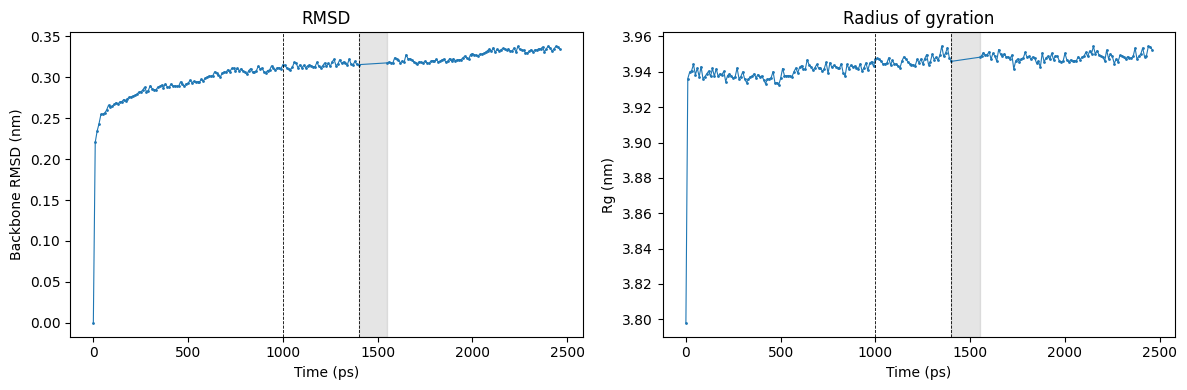

RMSD max 0.338 nm at 2400 ps, last 0.334 nm
Rg min/max (after 50 ps): 3.933 / 3.955 nm


In [ ]:
import numpy as np, matplotlib.pyplot as plt
load = lambda f: np.loadtxt("/content/tmp/" + f, comments=("#", "@"))
rmsd, rg = load("rmsd.xvg"), load("rg.xvg")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, d, yl, t in [(ax[0], rmsd, "Backbone RMSD (nm)", "RMSD"), (ax[1], rg, "Rg (nm)", "Radius of gyration")]:
    a.plot(d[:, 0], d[:, 1], ".-", ms=2, lw=0.8)
    a.axvspan(1400, 1550, color="gray", alpha=0.2)
    for x in (1000, 1400): a.axvline(x, ls="--", lw=0.6, c="k")
    a.set(xlabel="Time (ps)", ylabel=yl, title=t)
plt.tight_layout(); plt.show()

print("RMSD max %.3f nm at %d ps, last %.3f nm" % (rmsd[:,1].max(), rmsd[rmsd[:,1].argmax(),0], rmsd[-1,1]))
print("Rg min/max (after 50 ps): %.3f / %.3f nm" % (rg[5:,1].min(), rg[5:,1].max()))

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
ls -l md_5ns.part0003.*
gmx check -f md_5ns.part0003.xtc 2>&1 | grep -E "Reading frame|Last frame|#frames|rror|nexpected"
tail -n 12 md_5ns.part0003.log
grep -m2 -i -E "Reading checkpoint|generated:" md_5ns.part0004.log

-rw------- 1 root root   2448 Oct  7 13:17 md_5ns.part0003.edr
-rw------- 1 root root  28575 Oct  7 13:17 md_5ns.part0003.log
-rw------- 1 root root 746960 Oct  7 13:17 md_5ns.part0003.xtc
Reading frame       0 time 1410.000   
Last frame          0 time 1410.000   
Item        #frames Timestep (ps)
--------------------------------------------------------------------------------
 Wait PME GPU gather       1    2       4641       0.011          0.043   0.0
 Reduce GPU PME F          1    2       4641       0.345          1.379   0.3
 Launch PME GPU ops.       1    2      37128       0.640          2.559   0.5
--------------------------------------------------------------------------------

               Core t (s)   Wall t (s)        (%)
       Time:      248.017      124.015      200.0
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:        6.467        3.711       26.722            7.494 
Finished mdrun on rank 0 Wed Oct  7 13:19:20 2026

Reading che

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
ls -lh ./#* 2>/dev/null
for f in ./#md_5ns*xtc*; do echo "== $f"; gmx check -f "$f" 2>&1 | grep -E "Reading frame|Last frame|#frames"; done
tail -n 15 md_5ns_continue.log

-rw------- 1 root root 6.6M Oct  6 19:04 ./#chains_1ns.ndx.1#
-rw------- 1 root root 2.1M Oct  6 11:59 ./#hex.gro.1#
-rw------- 1 root root  11K Oct  7 13:30 ./#md_5ns.part0003.edr.1#
-rw------- 1 root root  37K Oct  7 13:30 ./#md_5ns.part0003.log.1#
-rw------- 1 root root  10M Oct  7 13:30 ./#md_5ns.part0003.xtc.1#
-rw------- 1 root root  65K Oct  6 16:52 ./#md.edr.1#
-rw------- 1 root root  91K Oct  6 16:52 ./#md.log.1#
-rw------- 1 root root  72M Oct  6 16:52 ./#md.xtc.1#
-rw------- 1 root root  17K Oct  6 14:53 ./#nvt.log.1#
-rw------- 1 root root 122K Oct  6 11:59 ./#posre_Protein_chain_A.itp.1#
-rw------- 1 root root 122K Oct  6 11:59 ./#posre_Protein_chain_B.itp.1#
-rw------- 1 root root 122K Oct  6 11:59 ./#posre_Protein_chain_C.itp.1#
-rw------- 1 root root 122K Oct  6 11:59 ./#posre_Protein_chain_D.itp.1#
-rw------- 1 root root 122K Oct  6 11:59 ./#posre_Protein_chain_E.itp.1#
-rw------- 1 root root 122K Oct  6 11:59 ./#posre_Protein_chain_F.itp.1#
-rw------- 1 root root 3.2K

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
mkdir -p /content/tmp
cp "./#md_5ns.part0003.xtc.1#" /content/tmp/p3.xtc
gmx check -f /content/tmp/p3.xtc 2>&1 | grep -E "Reading frame|Last frame|#frames"

Reading frame       0 time 1410.000   
Last frame         13 time 1540.000   
Item        #frames Timestep (ps)


In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
B="complete_0-2.5ns_backup"
mkdir -p "$B"

# trajectory segments (backup file renamed so it has no # in its name)
cp -n run1/md_run1.xtc                      "$B/seg1_0-1000ps.xtc"
cp -n md_5ns.part0002.xtc                   "$B/seg2_1000-1400ps.xtc"
cp -n "./#md_5ns.part0003.xtc.1#"           "$B/seg3_1410-1540ps.xtc"
cp -n md_5ns.part0004.xtc                   "$B/seg4_1550-2450ps.xtc"

# run files: tpr, restart checkpoints, energy/log files
cp -n md_ext.tpr run1/md_run1.tpr           "$B/"
cp -n md_5ns_step702320.cpt md_5ns_step772320.cpt md_5ns_step1259280.cpt "$B/"
cp -n md_5ns.part0002.edr md_5ns.part0002.log md_5ns.part0004.edr md_5ns.part0004.log "$B/"
cp -n "./#md_5ns.part0003.log.1#" "$B/seg3_1410-1540ps.log"
cp -n "./#md_5ns.part0003.edr.1#" "$B/seg3_1410-1540ps.edr"

# system files needed to reuse the run
cp -n npt.gro topol.top topol_Protein_chain_*.itp posre_Protein_chain_*.itp *.mdp "$B/" 2>/dev/null

# join all four segments into one complete trajectory
gmx trjcat -f "$B/seg1_0-1000ps.xtc" "$B/seg2_1000-1400ps.xtc" "$B/seg3_1410-1540ps.xtc" "$B/seg4_1550-2450ps.xtc" -o "$B/ALL_0-2450ps.xtc"

# check it, and list the folder
gmx check -f "$B/ALL_0-2450ps.xtc" 2>&1 | grep -E "Reading frame|Last frame|#frames"
ls -lh "$B"

Note that major changes are planned in future for trjcat, to improve usability and utility.

lasttime 0

lasttime 990

lasttime 1400

lasttime 1540
Reading frame       0 time    0.000   
Reading frame     200 time 2000.000   
Item        #frames Timestep (ps)
total 424M
-rw------- 1 root root 176M Oct  8 07:36 ALL_0-2450ps.xtc
-rw------- 1 root root  220 Oct  8 07:35 em.mdp
-rw------- 1 root root  191 Oct  8 07:35 ions.mdp
-rw------- 1 root root  27K Oct  8 07:35 md_5ns.part0002.edr
-rw------- 1 root root  48K Oct  8 07:35 md_5ns.part0002.log
-rw------- 1 root root  63K Oct  8 07:35 md_5ns.part0004.edr
-rw------- 1 root root  83K Oct  8 07:35 md_5ns.part0004.log
-rw------- 1 root root 4.6M Oct  8 07:35 md_5ns_step1259280.cpt
-rw------- 1 root root 4.6M Oct  8 07:35 md_5ns_step702320.cpt
-rw------- 1 root root 4.6M Oct  8 07:35 md_5ns_step772320.cpt
-rw------- 1 root root  16M Oct  8 07:35 md_ext.tpr
-rw------- 1 root root  547 Oct  8 07:35 md.mdp
-rw------- 1 root root  11K Oct  8 07:3

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
                :-) GROMACS - gmx trjcat, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Wor

In [ ]:
import os, sys, time, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
try:
    import mdtraj as md
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mdtraj"], check=True)
    import mdtraj as md

BASE = "/content/drive/MyDrive/Legumin Hexamer MD"
BK = f"{BASE}/complete_0-2.5ns_backup"
XTC, TPR = f"{BK}/ALL_0-2450ps.xtc", f"{BASE}/run1/md_run1.tpr"
OUT, TMP = f"{BK}/analysis_0-2450ps", "/content/tmp"
os.makedirs(OUT, exist_ok=True); os.makedirs(TMP, exist_ok=True)

PX, PP = f"{TMP}/prot.xtc", f"{TMP}/prot.pdb"
if not (os.path.exists(PX) and os.path.exists(PP)):
    subprocess.run(f'echo 1 1 1 | gmx trjconv -s "{TPR}" -f "{XTC}" -o {PX} -pbc cluster -center', shell=True, check=True)
    subprocess.run(f'echo 1 | gmx trjconv -s "{TPR}" -f "{XTC}" -o {PP} -dump 0', shell=True, check=True)

traj = md.load(PX, top=PP); top = traj.topology
T = traj.n_frames
res = list(top.residues); n_res = len(res)
seq = np.array([r.resSeq for r in res])
chain_of_res = np.concatenate([[0], np.cumsum(np.diff(seq) < 0)])
n_ch = int(chain_of_res.max()) + 1
names = [chr(65 + i) for i in range(n_ch)]
label = [f"{names[c]}_{s}" for c, s in zip(chain_of_res, seq)]
atom_res = np.array([a.residue.index for a in top.atoms])

COL = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]
LS = ["-", "--", ":", "-.", (0, (5, 1)), (0, (3, 1, 1, 1))]
LINKER = (256, 335)

def save(name):
    plt.tight_layout(); plt.savefig(f"{OUT}/{name}.png", dpi=200); plt.show(); print("saved", name + ".png")

def per_res(vals, ylabel, title, fname):
    fig, ax = plt.subplots(figsize=(11, 4))
    for c in range(n_ch):
        m = chain_of_res == c
        ax.plot(seq[m], vals[m], color=COL[c], ls=LS[c], lw=1.3, label=f"Chain {names[c]}")
    ax.axvspan(*LINKER, color="gray", alpha=0.15)
    ax.set(xlabel="Residue number", ylabel=ylabel, title=title); ax.legend(ncol=6, fontsize=8); save(fname)

print(f"frames {T}, atoms {traj.n_atoms}, residues {n_res}, chains {n_ch}")

frames 247, atoms 46974, residues 2976, chains 6


1 frame takes 13.1 s -> about 10.9 min for 50 frames
SASA frame 1/50  (13 s)
SASA frame 6/50  (76 s)
SASA frame 11/50  (139 s)
SASA frame 16/50  (203 s)
SASA frame 21/50  (267 s)
SASA frame 26/50  (329 s)
SASA frame 31/50  (392 s)
SASA frame 36/50  (457 s)
SASA frame 41/50  (523 s)
SASA frame 46/50  (588 s)


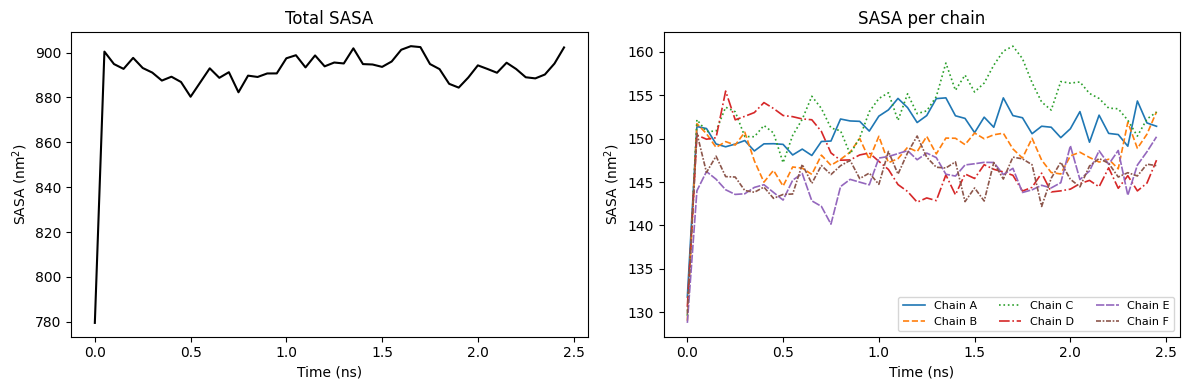

saved sasa_time.png


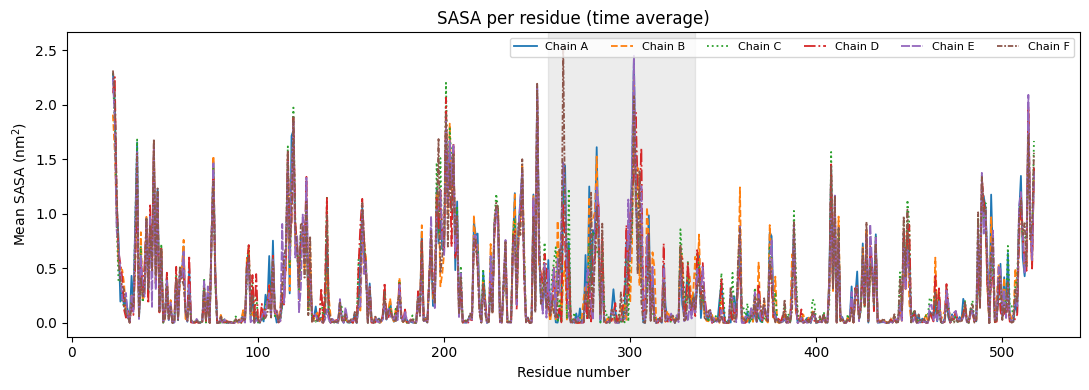

saved sasa_residue.png


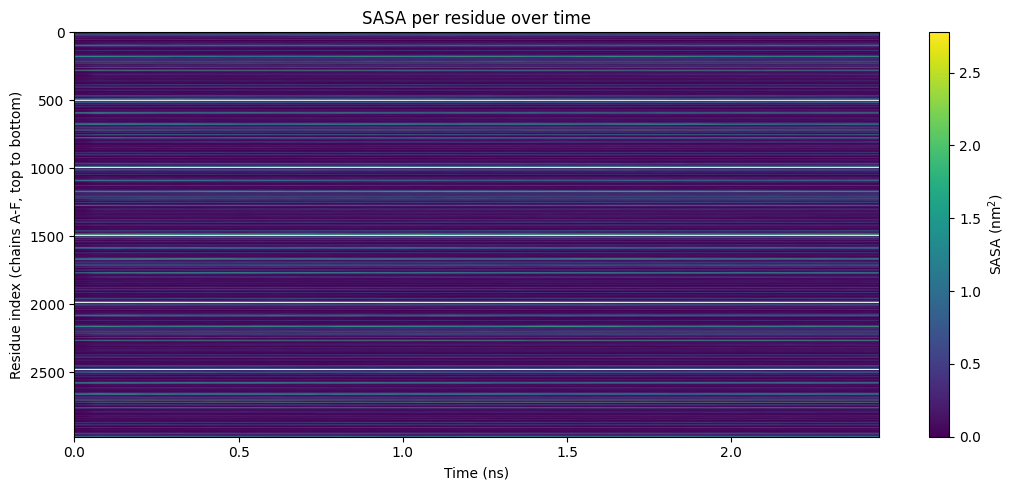

saved sasa_heatmap.png
Total SASA (nm2): first 780, last 902


In [ ]:
STRIDE, NPTS = 5, 240
sub = traj[::STRIDE]; Ts = sub.n_frames; ts = sub.time; t_ns = ts / 1000.0

t0 = time.time()
md.shrake_rupley(sub[0], probe_radius=0.14, n_sphere_points=NPTS, mode="residue")
per = time.time() - t0
print(f"1 frame takes {per:.1f} s -> about {per * Ts / 60:.1f} min for {Ts} frames", flush=True)

sasa = np.zeros((Ts, n_res)); t0 = time.time()
for s in range(Ts):
    sasa[s] = md.shrake_rupley(sub[s], probe_radius=0.14, n_sphere_points=NPTS, mode="residue")[0]
    if s % 5 == 0:
        print(f"SASA frame {s + 1}/{Ts}  ({time.time() - t0:.0f} s)", flush=True)

sasa_ch = [sasa[:, chain_of_res == c].sum(1) for c in range(n_ch)]
df = pd.DataFrame({"time_ps": ts, "sasa_total_nm2": sasa.sum(1)})
for c in range(n_ch):
    df[f"sasa_chain{names[c]}_nm2"] = sasa_ch[c]
df.to_csv(f"{OUT}/sasa_vs_time.csv", index=False)
pd.DataFrame(sasa, index=ts, columns=label).to_csv(f"{OUT}/sasa_residue_time_matrix.csv", index_label="time_ps")
pd.DataFrame({"chain": [names[c] for c in chain_of_res], "resSeq": seq,
              "mean_sasa_nm2": sasa.mean(0), "sd_sasa_nm2": sasa.std(0)}).to_csv(f"{OUT}/sasa_per_residue.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t_ns, sasa.sum(1), "k"); ax[0].set(xlabel="Time (ns)", ylabel="SASA (nm$^2$)", title="Total SASA")
for c in range(n_ch):
    ax[1].plot(t_ns, sasa_ch[c], color=COL[c], ls=LS[c], lw=1.2, label=f"Chain {names[c]}")
ax[1].set(xlabel="Time (ns)", ylabel="SASA (nm$^2$)", title="SASA per chain"); ax[1].legend(ncol=3, fontsize=8)
save("sasa_time")

per_res(sasa.mean(0), "Mean SASA (nm$^2$)", "SASA per residue (time average)", "sasa_residue")

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(sasa.T, aspect="auto", cmap="viridis", extent=[t_ns[0], t_ns[-1], n_res, 0])
for c in range(1, n_ch):
    ax.axhline(np.flatnonzero(chain_of_res == c)[0], color="w", lw=0.6)
ax.set(xlabel="Time (ns)", ylabel="Residue index (chains A-F, top to bottom)", title="SASA per residue over time")
fig.colorbar(im, label="SASA (nm$^2$)"); save("sasa_heatmap")
print("Total SASA (nm2): first %.0f, last %.0f" % (sasa.sum(1)[0], sasa.sum(1)[-1]))

6000 donor hydrogens, 9246 acceptor atoms
frame 0/247  total H-bonds 2726  (0 s)


/tmp/ipykernel_4816/2575597307.py:15: RuntimeWarning: invalid value encountered in divide
  cosang = (v1 * v2).sum(1) / (np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1))


frame 25/247  total H-bonds 2612  (1 s)
frame 50/247  total H-bonds 2606  (2 s)
frame 75/247  total H-bonds 2658  (3 s)
frame 100/247  total H-bonds 2627  (5 s)
frame 125/247  total H-bonds 2622  (7 s)
frame 150/247  total H-bonds 2648  (8 s)
frame 175/247  total H-bonds 2643  (9 s)
frame 200/247  total H-bonds 2682  (10 s)
frame 225/247  total H-bonds 2627  (11 s)


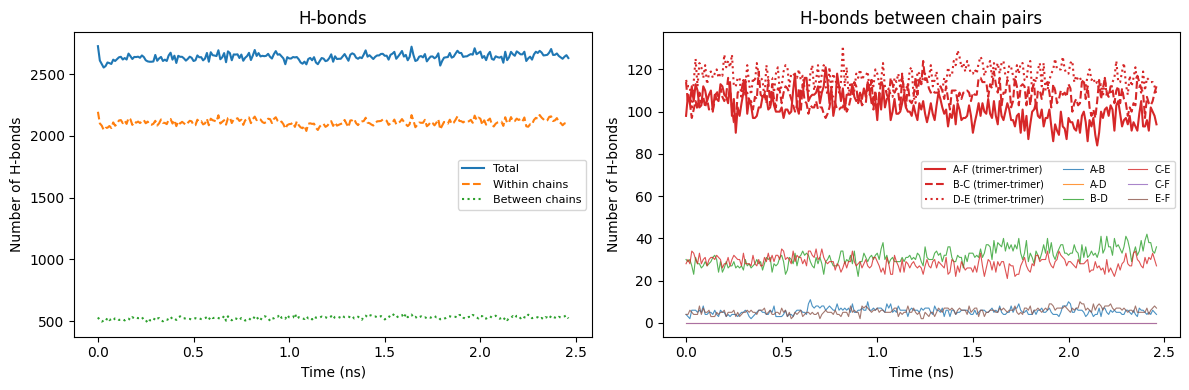

saved hbonds_time.png


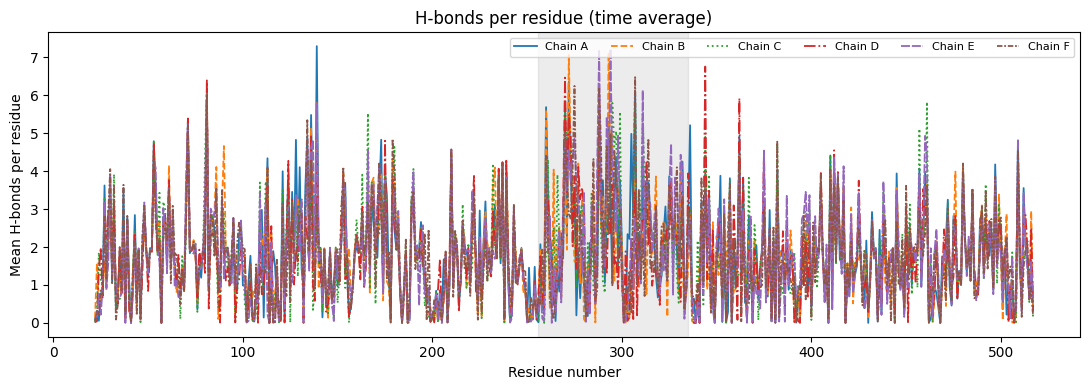

saved hbonds_residue.png


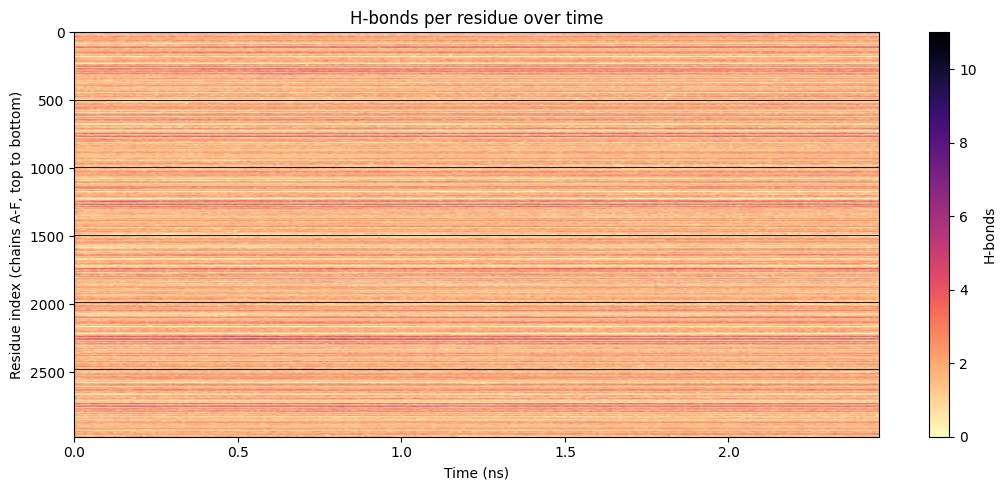

saved hbonds_heatmap.png
Mean H-bonds, last 1 ns: total 2649 | within chains 2116 | between chains 534 | trimer-trimer 322


In [ ]:
from scipy.spatial import cKDTree
BRIDGE = ["A-F", "B-C", "D-E"]                          # trimer-trimer chain pairs
INTRA_TRIMER = ["A-B", "A-D", "B-D", "C-E", "C-F", "E-F"]
t_ns = traj.time / 1000.0

def find_hbonds(xyz, don, hyd, acc, rmax=0.35, amax=30.0):
    lists = cKDTree(xyz[acc]).query_ball_point(xyz[don], r=rmax)
    cnt = np.array([len(l) for l in lists])
    if cnt.sum() == 0:
        return np.empty(0, int), np.empty(0, int)
    di = np.repeat(np.arange(len(don)), cnt)
    ai = np.concatenate([np.asarray(l, dtype=int) for l in lists if len(l)])
    D, A = don[di], acc[ai]
    v1, v2 = xyz[hyd[di]] - xyz[D], xyz[A] - xyz[D]
    cosang = (v1 * v2).sum(1) / (np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1))
    dres, ares = atom_res[D], atom_res[A]
    neighbour = (np.abs(dres - ares) <= 1) & (chain_of_res[dres] == chain_of_res[ares])
    ok = (cosang > np.cos(np.radians(amax))) & ~neighbour
    return dres[ok], ares[ok]

elem = np.array([a.element.symbol for a in top.atoms])
H = np.flatnonzero(elem == "H"); heavy = np.flatnonzero(elem != "H")
_, j = cKDTree(traj.xyz[0][heavy]).query(traj.xyz[0][H])
parent = heavy[j]; isdon = np.isin(elem[parent], ["N", "O"])
don, hyd = parent[isdon], H[isdon]
acc = np.flatnonzero(np.isin(elem, ["N", "O"]))
print(f"{len(don)} donor hydrogens, {len(acc)} acceptor atoms", flush=True)

pairs = [(i, j) for i in range(n_ch) for j in range(i, n_ch)]
pname = [f"{names[i]}-{names[j]}" for i, j in pairs]
hb_pair = np.zeros((T, len(pairs))); hb_res = np.zeros((T, n_res)); t0 = time.time()
for t in range(T):
    d, a = find_hbonds(traj.xyz[t], don, hyd, acc)
    cd, cc = chain_of_res[d], chain_of_res[a]
    lo, hi = np.minimum(cd, cc), np.maximum(cd, cc)
    for k, (i, j) in enumerate(pairs):
        hb_pair[t, k] = np.sum((lo == i) & (hi == j))
    hb_res[t] = np.bincount(d, minlength=n_res) + np.bincount(a, minlength=n_res)
    if t % 25 == 0:
        print(f"frame {t}/{T}  total H-bonds {int(hb_pair[t].sum())}  ({time.time() - t0:.0f} s)", flush=True)

is_intra = np.array([i == j for i, j in pairs])
col = lambda ns: hb_pair[:, [pname.index(n) for n in ns if n in pname]].sum(1)
df = pd.DataFrame({"time_ps": traj.time, "hbonds_total": hb_pair.sum(1),
                   "hbonds_within_chain": hb_pair[:, is_intra].sum(1),
                   "hbonds_between_chains": hb_pair[:, ~is_intra].sum(1),
                   "hbonds_trimer_trimer": col(BRIDGE),
                   "hbonds_within_trimers_between_chains": col(INTRA_TRIMER)})
for k, n in enumerate(pname):
    df[f"hb_{n}"] = hb_pair[:, k]
df.to_csv(f"{OUT}/hbonds_vs_time.csv", index=False)
pd.DataFrame(hb_res, index=traj.time, columns=label).to_csv(f"{OUT}/hbonds_residue_time_matrix.csv", index_label="time_ps")
pd.DataFrame({"chain": [names[c] for c in chain_of_res], "resSeq": seq,
              "mean_hbonds_per_residue": hb_res.mean(0)}).to_csv(f"{OUT}/hbonds_per_residue.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for key, lab, ls in [("hbonds_total", "Total", "-"), ("hbonds_within_chain", "Within chains", "--"),
                     ("hbonds_between_chains", "Between chains", ":")]:
    ax[0].plot(t_ns, df[key], ls=ls, label=lab)
ax[0].set(xlabel="Time (ns)", ylabel="Number of H-bonds", title="H-bonds"); ax[0].legend(fontsize=8)
for n, ls in zip(BRIDGE, ["-", "--", ":"]):
    ax[1].plot(t_ns, hb_pair[:, pname.index(n)], color="tab:red", ls=ls, lw=1.5, label=f"{n} (trimer-trimer)")
for n, c_ in zip(INTRA_TRIMER, COL):
    ax[1].plot(t_ns, hb_pair[:, pname.index(n)], color=c_, lw=0.8, alpha=0.8, label=n)
ax[1].set(xlabel="Time (ns)", ylabel="Number of H-bonds", title="H-bonds between chain pairs")
ax[1].legend(ncol=3, fontsize=7); save("hbonds_time")

per_res(hb_res.mean(0), "Mean H-bonds per residue", "H-bonds per residue (time average)", "hbonds_residue")

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(hb_res.T, aspect="auto", cmap="magma_r", extent=[t_ns[0], t_ns[-1], n_res, 0])
for c in range(1, n_ch):
    ax.axhline(np.flatnonzero(chain_of_res == c)[0], color="k", lw=0.6)
ax.set(xlabel="Time (ns)", ylabel="Residue index (chains A-F, top to bottom)", title="H-bonds per residue over time")
fig.colorbar(im, label="H-bonds"); save("hbonds_heatmap")

last = traj.time >= traj.time[-1] - 1000
print("Mean H-bonds, last 1 ns: total %.0f | within chains %.0f | between chains %.0f | trimer-trimer %.0f"
      % tuple(df[k][last].mean() for k in ["hbonds_total", "hbonds_within_chain", "hbonds_between_chains", "hbonds_trimer_trimer"]))

In [ ]:
# ============================================================
# DSSP ANALYSIS ONLY — COLAB READY
# Legumin Hexamer MD
# ============================================================

import os
import time
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ------------------------------------------------------------
# Install MDTraj if needed
# ------------------------------------------------------------

try:
    import mdtraj as md
except ImportError:
    subprocess.run(
        ["pip", "install", "-q", "mdtraj"],
        check=True
    )
    import mdtraj as md


# ============================================================
# PATHS
# ============================================================

BASE = "/content/drive/MyDrive/Legumin Hexamer MD"

BK = f"{BASE}/complete_0-2.5ns_backup"

XTC = f"{BK}/ALL_0-2450ps.xtc"

TPR = f"{BASE}/run1/md_run1.tpr"

OUT = f"{BK}/analysis_0-2450ps"

TMP = "/content/tmp"

os.makedirs(OUT, exist_ok=True)
os.makedirs(TMP, exist_ok=True)


# ============================================================
# COLORS / LINE STYLES
# ============================================================

COL = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red",
    "tab:purple",
    "tab:brown"
]

LS = [
    "-",
    "--",
    ":",
    "-.",
    (0, (5, 1)),
    (0, (3, 1, 1, 1))
]


# ============================================================
# SAVE FUNCTION
# ============================================================

def save(name):
    plt.tight_layout()
    plt.savefig(
        f"{OUT}/{name}.png",
        dpi=200
    )
    plt.close()
    print(
        "saved",
        name + ".png",
        flush=True
    )


# ============================================================
# LOAD / CREATE PROTEIN-ONLY TRAJECTORY
# ============================================================

PX = f"{TMP}/prot.xtc"
PP = f"{TMP}/prot.pdb"

print("Checking protein trajectory files...", flush=True)

if not (
    os.path.exists(PX)
    and os.path.exists(PP)
):

    print(
        "prot.xtc / prot.pdb not found.",
        "Creating them with GROMACS...",
        flush=True
    )

    cmd1 = (
        f'printf "1\\n1\\n1\\n" | '
        f'gmx trjconv '
        f'-s "{TPR}" '
        f'-f "{XTC}" '
        f'-o "{PX}" '
        f'-pbc cluster '
        f'-center'
    )

    result = subprocess.run(
        cmd1,
        shell=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    print(
        "\n".join(
            result.stdout.strip().splitlines()[-10:]
        )
    )

    if result.returncode != 0:
        raise RuntimeError(
            "Failed to create protein trajectory."
        )

    cmd2 = (
        f'printf "1\\n" | '
        f'gmx trjconv '
        f'-s "{TPR}" '
        f'-f "{XTC}" '
        f'-o "{PP}" '
        f'-dump 0'
    )

    result = subprocess.run(
        cmd2,
        shell=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    print(
        "\n".join(
            result.stdout.strip().splitlines()[-10:]
        )
    )

    if result.returncode != 0:
        raise RuntimeError(
            "Failed to create protein PDB."
        )

else:

    print(
        "Existing prot.xtc and prot.pdb found.",
        flush=True
    )


# ============================================================
# LOAD TRAJECTORY WITH MDTraj
# ============================================================

print("\nLoading trajectory with MDTraj...", flush=True)

t0 = time.time()

traj = md.load(
    PX,
    top=PP
)

top = traj.topology

T = traj.n_frames

t_ns = traj.time / 1000.0

print(
    f"Frames: {T}",
    flush=True
)

print(
    f"Atoms: {traj.n_atoms}",
    flush=True
)

print(
    f"Time: {traj.time[0]:.1f} → "
    f"{traj.time[-1]:.1f} ps",
    flush=True
)


# ============================================================
# TOPOLOGY / RESIDUE INFORMATION
# ============================================================

res = list(top.residues)

n_res = len(res)

seq = np.array([
    r.resSeq
    for r in res
])

# Detect chains from residue-number resets
chain_of_res = np.concatenate([
    [0],
    np.cumsum(
        np.diff(seq) < 0
    )
])

n_ch = int(
    chain_of_res.max()
) + 1

names = [
    chr(65 + i)
    for i in range(n_ch)
]

label = [
    f"{names[c]}_{s}"
    for c, s in zip(
        chain_of_res,
        seq
    )
]

print(
    f"Residues: {n_res}",
    flush=True
)

print(
    f"Chains: {n_ch} "
    f"({', '.join(names)})",
    flush=True
)


# ============================================================
# LINKER REGION
# ============================================================

LINKER = (256, 335)


def shade(ax):

    ax.axvspan(
        *LINKER,
        color="gray",
        alpha=0.15
    )


# ============================================================
# DSSP
# ============================================================

print(
    "\nStarting DSSP analysis...",
    flush=True
)

parts = []

for s in range(
    0,
    T,
    25
):

    end = min(
        s + 25,
        T
    )

    parts.append(
        md.compute_dssp(
            traj[s:end],
            simplified=False
        )
    )

    print(
        f"DSSP frames "
        f"{end}/{T}  "
        f"({time.time() - t0:.0f} s)",
        flush=True
    )


# Combine DSSP chunks

dssp = np.concatenate(
    parts
)


# Replace blank DSSP states with coil

dssp = np.where(
    dssp == " ",
    "C",
    dssp
)


# ============================================================
# DSSP CODES
# ============================================================

codes = [
    "H",
    "G",
    "I",
    "E",
    "B",
    "T",
    "S",
    "C"
]

cnames = {
    "H": "alpha-helix",
    "G": "3-10 helix",
    "I": "pi-helix",
    "E": "strand",
    "B": "beta-bridge",
    "T": "turn",
    "S": "bend",
    "C": "coil"
}

ccol = [
    "#d62728",
    "#ff9896",
    "#e377c2",
    "#1f77b4",
    "#aec7e8",
    "#2ca02c",
    "#bcbd22",
    "#bbbbbb"
]


# ============================================================
# MAJOR DSSP GROUPS
# ============================================================

groups = {

    "Helix (H+G+I)": [
        "H",
        "G",
        "I"
    ],

    "Sheet (E+B)": [
        "E",
        "B"
    ],

    "Turn/bend (T+S)": [
        "T",
        "S"
    ],

    "Coil": [
        "C"
    ]
}


# ============================================================
# DSSP FRACTIONS
# ============================================================

frac = {
    c:
    (dssp == c).mean(1) * 100
    for c in codes
}

gfrac = {
    g:
    sum(
        frac[c]
        for c in cs
    )
    for g, cs in groups.items()
}


# ============================================================
# DSSP VS TIME CSV
# ============================================================

df = pd.DataFrame({
    "time_ps": traj.time
})

for c in codes:

    df[
        f"percent_{cnames[c]}"
    ] = frac[c]

for g in groups:

    df[
        f"percent_{g}"
    ] = gfrac[g]

df.to_csv(
    f"{OUT}/dssp_vs_time.csv",
    index=False
)

print(
    "saved dssp_vs_time.csv",
    flush=True
)


# ============================================================
# DSSP CODE PER FRAME
# ============================================================

pd.DataFrame(
    dssp,
    index=traj.time,
    columns=label
).to_csv(
    f"{OUT}/dssp_codes_per_frame.csv",
    index_label="time_ps"
)

print(
    "saved dssp_codes_per_frame.csv",
    flush=True
)


# ============================================================
# PER-RESIDUE DSSP PROFILE
# ============================================================

rp = pd.DataFrame({

    "chain": [
        names[c]
        for c in chain_of_res
    ],

    "resSeq": seq

})


for c in codes:

    rp[
        f"percent_{cnames[c]}"
    ] = (
        dssp == c
    ).mean(0) * 100


for g, cs in groups.items():

    rp[
        f"percent_{g}"
    ] = sum(
        (
            dssp == c
        ).mean(0) * 100
        for c in cs
    )


rp.to_csv(
    f"{OUT}/dssp_per_residue.csv",
    index=False
)

print(
    "saved dssp_per_residue.csv",
    flush=True
)


# ============================================================
# PLOT 1 — ALL DSSP STRUCTURES VS TIME
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 4.5)
)

for c, k in zip(
    codes,
    ccol
):

    ax.plot(
        t_ns,
        frac[c],
        color=k,
        label=f"{c} {cnames[c]}"
    )


ax.set(
    xlabel="Time (ns)",
    ylabel="Residues (%)",
    title="All DSSP secondary structures"
)

ax.legend(
    ncol=2,
    fontsize=8
)

save(
    "dssp_all_time"
)


# ============================================================
# PLOT 2 — MAJOR DSSP GROUPS VS TIME
# ============================================================

fig, axs = plt.subplots(
    2,
    2,
    figsize=(11, 7),
    sharex=True
)

group_colors = [
    "#d62728",
    "#1f77b4",
    "#2ca02c",
    "#777777"
]

for ax, (g, k) in zip(
    axs.flat,
    zip(
        groups,
        group_colors
    )
):

    ax.plot(
        t_ns,
        gfrac[g],
        color=k
    )

    ax.set(
        title=g,
        ylabel="Residues (%)"
    )


for ax in axs[1]:

    ax.set_xlabel(
        "Time (ns)"
    )


save(
    "dssp_major_time"
)


# ============================================================
# PLOT 3 — DSSP PER-RESIDUE PROFILE
# ============================================================

fig, axs = plt.subplots(
    2,
    2,
    figsize=(12, 7),
    sharex=True
)

for ax, g in zip(
    axs.flat,
    groups
):

    v = rp[
        f"percent_{g}"
    ].values

    for c in range(n_ch):

        m = (
            chain_of_res == c
        )

        ax.plot(
            seq[m],
            v[m],
            color=COL[c],
            ls=LS[c],
            lw=1,
            label=f"Chain {names[c]}"
        )

    shade(ax)

    ax.set(
        title=g,
        ylabel="% of time"
    )


for ax in axs[1]:

    ax.set_xlabel(
        "Residue number"
    )


axs[0, 0].legend(
    ncol=3,
    fontsize=7
)

save(
    "dssp_residue_profile"
)


# ============================================================
# PLOT 4 — DSSP MAP / HEATMAP
# ============================================================

cidx = np.vectorize(
    {
        c: i
        for i, c in enumerate(codes)
    }.get
)(
    dssp,
    7
)


fig, axs = plt.subplots(
    3,
    2,
    figsize=(12, 10),
    sharex=True
)


for c, ax in zip(
    range(n_ch),
    axs.flat
):

    m = (
        chain_of_res == c
    )

    ax.imshow(
        cidx[:, m].T,
        aspect="auto",
        cmap=ListedColormap(ccol),
        vmin=-0.5,
        vmax=7.5,
        interpolation="nearest",
        extent=[
            t_ns[0],
            t_ns[-1],
            seq[m][-1],
            seq[m][0]
        ]
    )

    ax.set(
        title=f"Chain {names[c]}",
        ylabel="Residue"
    )


for ax in axs[-1]:

    ax.set_xlabel(
        "Time (ns)"
    )


fig.legend(
    handles=[
        Patch(
            color=k,
            label=f"{c} {cnames[c]}"
        )
        for c, k in zip(
            codes,
            ccol
        )
    ],

    loc="lower center",

    ncol=8,

    fontsize=8
)


plt.tight_layout(
    rect=(0, 0.04, 1, 1)
)

plt.savefig(
    f"{OUT}/dssp_map.png",
    dpi=200
)

plt.close()

print(
    "saved dssp_map.png",
    flush=True
)


# ============================================================
# MEAN DSSP DURING LAST 1 ns
# ============================================================

last_1ns = (
    traj.time >=
    traj.time[-1] - 1000
)


print(
    "\nMean % last 1 ns: "
    +
    " | ".join(
        f"{g} "
        f"{gfrac[g][last_1ns].mean():.1f}"
        for g in groups
    )
)


# ============================================================
# FINISHED
# ============================================================

print(
    f"\nDone in "
    f"{time.time() - t0:.0f} s."
)

print(
    f"Files are in:\n{OUT}"
)

Checking protein trajectory files...
Existing prot.xtc and prot.pdb found.

Loading trajectory with MDTraj...
Frames: 247
Atoms: 46974
Time: 0.0 → 2460.0 ps
Residues: 2976
Chains: 6 (A, B, C, D, E, F)

Starting DSSP analysis...
DSSP frames 25/247  (5 s)
DSSP frames 50/247  (8 s)
DSSP frames 75/247  (9 s)
DSSP frames 100/247  (11 s)
DSSP frames 125/247  (13 s)
DSSP frames 150/247  (16 s)
DSSP frames 175/247  (19 s)
DSSP frames 200/247  (22 s)
DSSP frames 225/247  (24 s)
DSSP frames 247/247  (25 s)
saved dssp_vs_time.csv
saved dssp_codes_per_frame.csv
saved dssp_per_residue.csv
saved dssp_all_time.png
saved dssp_major_time.png
saved dssp_residue_profile.png
saved dssp_map.png

Mean % last 1 ns: Helix (H+G+I) 11.1 | Sheet (E+B) 27.1 | Turn/bend (T+S) 26.9 | Coil 35.0

Done in 30 s.
Files are in:
/content/drive/MyDrive/Legumin Hexamer MD/complete_0-2.5ns_backup/analysis_0-2450ps


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -lh *.cpt *.tpr 2>/dev/null | tail -20

-rw------- 1 root root 4.6M Oct  6 16:57 md_step32320.cpt
-rw------- 1 root root 4.6M Oct  6 15:40 md_step33280.cpt
-rw------- 1 root root 4.6M Oct  6 17:42 md_step333520.cpt
-rw------- 1 root root 4.6M Oct  6 16:25 md_step336080.cpt
-rw------- 1 root root 4.6M Oct  6 17:47 md_step366560.cpt
-rw------- 1 root root 4.6M Oct  6 16:30 md_step369840.cpt
-rw------- 1 root root 4.6M Oct  6 17:48 md_step372240.cpt
-rw------- 1 root root 4.6M Oct  6 16:35 md_step403920.cpt
-rw------- 1 root root 4.6M Oct  6 16:40 md_step438000.cpt
-rw------- 1 root root 4.6M Oct  6 16:45 md_step472240.cpt
-rw------- 1 root root 4.6M Oct  6 16:49 md_step500000.cpt
-rw------- 1 root root 4.6M Oct  6 17:02 md_step65840.cpt
-rw------- 1 root root 4.6M Oct  6 15:45 md_step66480.cpt
-rw------- 1 root root 4.6M Oct  6 17:07 md_step99120.cpt
-rw------- 1 root root 4.6M Oct  6 15:50 md_step99920.cpt
-rw------- 1 root root  16M Oct  6 15:34 md.tpr
-rw------- 1 root root 4.6M Oct  6 15:13 npt.cpt
-rw------- 1 root root  

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"
!ls -lh md_5ns_step1259280.cpt
!gmx check -f md_5ns_step1259280.cpt

-rw------- 1 root root 4.6M Oct  7 14:59 md_5ns_step1259280.cpt
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_5ns_step1259280.cpt

Checking file md_5ns_step1259280.cpt

# Atoms  200254
Last frame         -1 time 2518.560   


Item        #frames Timestep (ps)
Step             1
Time             1
Lambda           1
Coords           1
Velocities       1
Forces           0
Box              1

GROMACS reminds you: "After a few talks we usually sit down to do some work... or drinking." (Mike Klein)



In [ ]:
!ls -l /usr/local/bin*/gmx 2>/dev/null

-rwxrwxr-x 2 root root 129648 Jul 28 18:54 /usr/local/bin.AVX2_256/gmx
-rwxrwxr-x 2 root root 129648 Jul 28 18:54 /usr/local/bin.AVX_256/gmx
-rwxrwxr-x 1 root root    791 Oct  8 14:13 /usr/local/bin/gmx
-rwxrwxr-x 2 root root 129648 Jul 28 18:54 /usr/local/bin.SSE2/gmx


In [ ]:
!conda activate gmx_cuda


CondaError: Run 'conda init' before 'conda activate'



In [ ]:
! conda init conda activate gmx_cuda

usage: conda init [-h] [--all] [--condabin] [--user] [--no-user] [--system]
                  [--reverse] [--json] [--console CONSOLE] [-v] [-q] [-d]
                  [SHELLS ...]
conda init: error: argument SHELLS: invalid choice: 'conda' (choose from bash, fish, tcsh, xonsh, zsh, powershell)


In [ ]:
!source /usr/local/envs/gmx_cuda/bin/activate

/bin/bash: line 1: /usr/local/envs/gmx_cuda/bin/activate: No such file or directory


In [ ]:
!find /usr/local -type f -name "gmx" -executable 2>/dev/null

/usr/local/bin/gmx
/usr/local/bin.AVX2_256/gmx
/usr/local/bin.SSE2/gmx
/usr/local/bin.AVX_256/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_cuda_h39c90b0_0/bin.AVX2_256/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_cuda_h39c90b0_0/bin.SSE2/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_cuda_h39c90b0_0/bin/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_cuda_h39c90b0_0/bin.AVX_256/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_h26635d9_100/bin.AVX2_256/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_h26635d9_100/bin.SSE2/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_h26635d9_100/bin/gmx
/usr/local/pkgs/gromacs-2026.3-nompi_h26635d9_100/bin.AVX_256/gmx
/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
/usr/local/envs/gmx_cuda/bin.SSE2/gmx
/usr/local/envs/gmx_cuda/bin/gmx
/usr/local/envs/gmx_cuda/bin.AVX_256/gmx


In [ ]:
!/usr/local/envs/gmx_cuda/bin/gmx --version

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/b

In [ ]:
!/usr/local/envs/gmx_cuda/bin/gmx mdrun -version

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstoc

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -lh md_5ns.tpr md_5ns_step1259280.cpt 2>/dev/null

-rw------- 1 root root 4.6M Oct  7 14:59 md_5ns_step1259280.cpt


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx check -s md.tpr -f md_5ns_step1259280.cpt

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -s md.tpr -f md_5ns_step1259280.cpt


-------------------------------------------------------
Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
    Unknown command-line option -s

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx dump -s md.tpr | grep -E "^(integrator|dt|nsteps|init_step|init_t|tinit)" | tail -20

                 :-) GROMACS - gmx dump, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx dump -s md.tpr

Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)

GROMACS reminds you: "A computer without COBOL and FORTRAN is like a piece of chocolate cake without ketchup or mustard." (Unix fortune program)



In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!find . -maxdepth 2 -type f \( -name "md_5ns.part0004*" -o -name "md_5ns*1259280*" \) -ls

      187  67099 -rw-------   1 root     root     68708632 Oct  7 14:55 ./md_5ns.part0004.xtc
      188   4696 -rw-------   1 root     root      4808296 Oct  7 14:59 ./md_5ns_step1259280.cpt
      189     83 -rw-------   1 root     root        84596 Oct  7 15:00 ./md_5ns.part0004.log
      190     63 -rw-------   1 root     root        64008 Oct  7 15:00 ./md_5ns.part0004.edr
      390   4696 -rw-------   1 root     root      4808296 Oct  8 07:35 ./complete_0-2.5ns_backup/md_5ns_step1259280.cpt
      393     63 -rw-------   1 root     root        64008 Oct  8 07:35 ./complete_0-2.5ns_backup/md_5ns.part0004.edr
      394     83 -rw-------   1 root     root        84596 Oct  8 07:35 ./complete_0-2.5ns_backup/md_5ns.part0004.log


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx mdrun \
-s md.tpr \
-cpi md_5ns_step1259280.cpt \
-deffnm md_5ns \
-nsteps 0 \
-nb gpu \
-pme gpu \
-bonded gpu \
-update gpu \
-gpu_id 0 \
-ntmpi 1 \
-ntomp 4

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md.tpr -cpi md_5ns_step1259280.cpt -deffnm md_5ns -nsteps 0 -nb gpu -pme gpu -bonded gpu -update gpu -gpu_id 0 -ntmpi 1 -ntomp 4


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/mdrunutility/handlerestart.cpp (line 212)
Function:    void gmx::{anonymous}::throwBecauseOfMissingOutputFiles(const std::filesystem::__cxx11::path&, gmx::ArrayRef<const gmx_file_position_t>, int, const t_filenm*, size_t)

Inconsistency in user input:
Some output files listed in the checkpoint file md_5ns_step1259280.cpt are not
present or not named as the output files by the current program:)
Expected output files that are present:

Expected output files that are not present or named di

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx dump -cp md_5ns_step1259280.cpt 2>&1 | grep -E "part0004|xtc|edr|log" | head -30

output filename = md_5ns.part0004.log
output filename = md_5ns.part0004.xtc
output filename = md_5ns.part0004.edr


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -li md_5ns.part0004.log md_5ns.part0004.xtc md_5ns.part0004.edr

190 -rw------- 1 root root    64008 Oct  7 15:00 md_5ns.part0004.edr
189 -rw------- 1 root root    84596 Oct  7 15:00 md_5ns.part0004.log
187 -rw------- 1 root root 68708632 Oct  7 14:55 md_5ns.part0004.xtc


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx mdrun \
-s md.tpr \
-cpi md_5ns_step1259280.cpt \
-deffnm md_5ns \
-nsteps 0 \
-noappend \
-nb gpu \
-pme gpu \
-bonded gpu \
-update gpu \
-gpu_id 0 \
-ntmpi 1 \
-ntomp 4

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md.tpr -cpi md_5ns_step1259280.cpt -deffnm md_5ns -nsteps 0 -noappend -nb gpu -pme gpu -bonded gpu -update gpu -gpu_id 0 -ntmpi 1 -ntomp 4

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)

Overriding nsteps with value passed on the command line: 0 steps, 0 ps
Changing nstlist from 20 to 80, rlist from 1.022 to 1.156


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 r

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx mdrun \
-s md.tpr \
-cpi md_5ns_step1259280.cpt \
-deffnm md_5ns \
-noappend \
-cpt 10 \
-nb gpu \
-pme gpu \
-bonded gpu \
-update gpu \
-gpu_id 0 \
-ntmpi 1 \
-ntomp 2

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md.tpr -cpi md_5ns_step1259280.cpt -deffnm md_5ns -noappend -cpt 10 -nb gpu -pme gpu -bonded gpu -update gpu -gpu_id 0 -ntmpi 1 -ntomp 2


Back Off! I just backed up md_5ns.part0005.log to ./#md_5ns.part0005.log.1#
Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md.tpr, VERSION 2026.3-conda_forge (single precision)

-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/f

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!gmx check -f md_ext.tpr

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_ext.tpr


-------------------------------------------------------
Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File name 'md_ext.tpr' cannot be used for this option.
    Only the following extensions are possible:
      .xtc, .trr, .cpt, .gro, .g96, .pdb, .tng, .h5md

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------


In [ ]:
!/usr/local/envs/gmx_cuda/bin/gmx check -f md_ext.tpr

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_ext.tpr


-------------------------------------------------------
Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File name 'md_ext.tpr' cannot be used for this option.
    Only the following extensions are possible:
      .xtc, .trr, .cpt, .gro, .g96, .pdb, .tng, .h5md

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx dump -s md_ext.tpr | grep -E "nsteps|init_step|delta_t"

                 :-) GROMACS - gmx dump, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx dump -s md_ext.tpr

Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)
   nsteps                         = 2500000

GROMACS reminds you: "The soul? There's nothing but chemistry here" (Breaking Bad)



In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx mdrun \
-s md_ext.tpr \
-cpi md_5ns_step1259280.cpt \
-deffnm md_5ns \
-nsteps 0 \
-cpt 10 \
-nb gpu \
-pme gpu \
-bonded gpu \
-update gpu \
-gpu_id 0 \
-ntmpi 1 \
-ntomp 2

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_ext.tpr -cpi md_5ns_step1259280.cpt -deffnm md_5ns -nsteps 0 -cpt 10 -nb gpu -pme gpu -bonded gpu -update gpu -gpu_id 0 -ntmpi 1 -ntomp 2


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/mdrunutility/handlerestart.cpp (line 212)
Function:    void gmx::{anonymous}::throwBecauseOfMissingOutputFiles(const std::filesystem::__cxx11::path&, gmx::ArrayRef<const gmx_file_position_t>, int, const t_filenm*, size_t)

Inconsistency in user input:
Some output files listed in the checkpoint file md_5ns_step1259280.cpt are not
present or not named as the output files by the current program:)
Expected output files that are present:

Expected output files that are not present

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx mdrun \
-s md_ext.tpr \
-cpi md_5ns_step1259280.cpt \
-deffnm md_5ns \
-noappend \
-nsteps 0 \
-cpt 10 \
-nb gpu \
-pme gpu \
-bonded gpu \
-update gpu \
-gpu_id 0 \
-ntmpi 1 \
-ntomp 2

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_ext.tpr -cpi md_5ns_step1259280.cpt -deffnm md_5ns -noappend -nsteps 0 -cpt 10 -nb gpu -pme gpu -bonded gpu -update gpu -gpu_id 0 -ntmpi 1 -ntomp 2


Back Off! I just backed up md_5ns.part0005.log to ./#md_5ns.part0005.log.2#
Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)

Overriding nsteps with value passed on the command line: 0 steps, 0 ps
Changing nstlist from 20 to 80, rlist from 1

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx mdrun \
-s md_ext.tpr \
-cpi md_5ns_step1259280.cpt \
-deffnm md_5ns \
-noappend \
-cpt 10 \
-nb gpu \
-pme gpu \
-bonded gpu \
-update gpu \
-gpu_id 0 \
-ntmpi 1 \
-ntomp 2

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_ext.tpr -cpi md_5ns_step1259280.cpt -deffnm md_5ns -noappend -cpt 10 -nb gpu -pme gpu -bonded gpu -update gpu -gpu_id 0 -ntmpi 1 -ntomp 2


Back Off! I just backed up md_5ns.part0005.log to ./#md_5ns.part0005.log.3#
Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.156


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -lh md_ext.tpr md_5ns.cpt md_5ns_prev.cpt

-rw------- 1 root root 4.6M Oct  8 16:03 md_5ns.cpt
-rw------- 1 root root 4.6M Oct  8 16:03 md_5ns_prev.cpt
-rw------- 1 root root  16M Oct  6 16:51 md_ext.tpr


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin/gmx check -f md_5ns.cpt

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_5ns.cpt

Checking file md_5ns.cpt

# Atoms  200254
Last frame         -1 time 3986.560   


Item        #frames Timestep (ps)
Step             1
Time             1
Lambda           1
Coords           1
Velocities       1
Forces           0
Box              1

GROMACS reminds you: "If you thought that science was certain - well, that is just an error on your part." (Richard Feynman)



In [ ]:
!/usr/local/envs/gmx_cuda/bin/gmx mdrun \
-s md_ext.tpr \
-cpi md_5ns.cpt \
-deffnm md_5ns \
-noappend \
-cpt 10 \
-nb gpu \
-pme gpu \
-bonded gpu \
-update gpu \
-gpu_id 0 \
-ntmpi 1 \
-ntomp 2

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_ext.tpr -cpi md_5ns.cpt -deffnm md_5ns -noappend -cpt 10 -nb gpu -pme gpu -bonded gpu -update gpu -gpu_id 0 -ntmpi 1 -ntomp 2

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged and

In [ ]:
%%bash
for f in ALL_0-2450ps.xtc md_5ns.part0005.xtc md_5ns.part0006.xtc; do
  echo "== $f"; gmx check -f $f 2>&1 | grep -E "Reading frame|Last frame|Step|Time|Coords"
done

tail -n 12 md_5ns.part0005.log
tail -n 12 md_5ns.part0006.log

gmx check -s1 md_run1.tpr 2>&1 | grep -E "nsteps|dt"
gmx check -s1 md_ext.tpr 2>&1 | grep -E "nsteps|dt"

== ALL_0-2450ps.xtc
== md_5ns.part0005.xtc
Reading frame       0 time 2520.000   
Reading frame     140 time 3920.000   
Item        #frames Timestep (ps)
Step           147    10
Time           147    10
Coords         147    10
== md_5ns.part0006.xtc
Reading frame       0 time 3990.000   
Reading frame     100 time 4990.000   
Item        #frames Timestep (ps)
Step           102    10
Time           102    10
Coords         102    10
        2030000     4060.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.90473e+04    1.03340e+05    1.24590e+05    7.07762e+03    4.34421e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.15114e+05    2.18102e+05   -3.33785e+04   -3.53128e+06    1.97252e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.69422e+06    5.49828e+05   -2.14439e+06   -1.94974e+06    3.11318e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2

CalledProcessError: Command 'b'for f in ALL_0-2450ps.xtc md_5ns.part0005.xtc md_5ns.part0006.xtc; do\n  echo "== $f"; gmx check -f $f 2>&1 | grep -E "Reading frame|Last frame|Step|Time|Coords"\ndone\n\ntail -n 12 md_5ns.part0005.log\ntail -n 12 md_5ns.part0006.log\n\ngmx check -s1 md_run1.tpr 2>&1 | grep -E "nsteps|dt"\ngmx check -s1 md_ext.tpr 2>&1 | grep -E "nsteps|dt"\n'' returned non-zero exit status 1.

In [ ]:
%%bash
ls -lh ALL_0-2450ps.xtc
gmx check -f ALL_0-2450ps.xtc 2>&1 | tail -n 15
echo "=== part0005 log"; tail -n 25 md_5ns.part0005.log | head -n 8
echo "=== part0006 log"; grep -A1 "Step           Time" md_5ns.part0006.log | tail -n 3
for t in md_run1.tpr md_ext.tpr; do echo "== $t"; gmx dump -s $t 2>/dev/null | grep -E "nsteps|init-step|tinit|delta-t"; done

Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File 'ALL_0-2450ps.xtc' does not exist or is not accessible.
    The file could not be opened.
      Reason: No such file or directory
      (call to fopen() returned error code 2)

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
=== part0005 log
        2025000     4050.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.90051e+04    1.01451e+05    1.24285e+05    6.58770e+03    4.37293e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.16163e+05    2.17522e+05   -3.33946e+04   

ls: cannot access 'ALL_0-2450ps.xtc': No such file or directory


In [ ]:
%%bash
ls -lh complete_0-2.5ns_backup
for f in complete_0-2.5ns_backup/*.xtc; do
  echo "== $f"; gmx check -f $f 2>&1 | grep -E "Reading frame|Time"
done

total 424M
-rw------- 1 root root 176M Oct  8 07:35 ALL_0-2450ps.xtc
drwx------ 2 root root 4.0K Oct  8 07:48 analysis_0-2450ps
-rw------- 1 root root  220 Oct  8 07:35 em.mdp
-rw------- 1 root root  191 Oct  8 07:35 ions.mdp
-rw------- 1 root root  27K Oct  8 07:35 md_5ns.part0002.edr
-rw------- 1 root root  48K Oct  8 07:35 md_5ns.part0002.log
-rw------- 1 root root  63K Oct  8 07:35 md_5ns.part0004.edr
-rw------- 1 root root  83K Oct  8 07:35 md_5ns.part0004.log
-rw------- 1 root root 4.6M Oct  8 07:35 md_5ns_step1259280.cpt
-rw------- 1 root root 4.6M Oct  8 07:35 md_5ns_step702320.cpt
-rw------- 1 root root 4.6M Oct  8 07:35 md_5ns_step772320.cpt
-rw------- 1 root root  16M Oct  8 07:35 md_ext.tpr
-rw------- 1 root root  547 Oct  8 07:35 md.mdp
-rw------- 1 root root  11K Oct  8 07:35 mdout.mdp
-rw------- 1 root root  16M Oct  8 07:35 md_run1.tpr
-rw------- 1 root root  14M Oct  8 07:35 npt.gro
-rw------- 1 root root  587 Oct  8 07:35 npt.mdp
-rw------- 1 root root  514 Oct  8 07:

In [ ]:
%%bash
ls -lh run1 | grep -i xtc
ls -lh *part0004* 2>/dev/null

-rw------- 1 root root  73M Oct  7 12:28 md_run1_c.xtc
-rw------- 1 root root  72M Oct  7 12:23 md_run1.xtc
-rw------- 1 root root 63K Oct  7 15:00 md_5ns.part0004.edr
-rw------- 1 root root 83K Oct  7 15:00 md_5ns.part0004.log
-rw------- 1 root root 66M Oct  7 14:55 md_5ns.part0004.xtc


In [ ]:
%%bash
gmx check -f md_5ns.part0004.xtc 2>&1 | grep -E "Reading frame|Last frame|Time"
grep -B1 -A1 "Step           Time" md_5ns.part0004.log | tail -n 4

Reading frame       0 time 1550.000   
Reading frame      90 time 2450.000   
Item        #frames Timestep (ps)
Time            92    10
--

           Step           Time
        1255000     2510.00000


In [ ]:
%%bash
gmx trjcat -f complete_0-2.5ns_backup/ALL_0-2450ps.xtc \
  md_5ns.part0005.xtc md_5ns.part0006.xtc \
  -o ALL_0-5000ps.xtc
gmx check -f ALL_0-5000ps.xtc 2>&1 | tail -n 8

Note that major changes are planned in future for trjcat, to improve usability and utility.

lasttime 0

lasttime 2460

lasttime 3980
Coords         496
Velocities       0
Forces           0
Box            496

GROMACS reminds you: "Statistics: The only science that enables different experts using the same figures to draw different conclusions." (Evan Esar)

Checking file ALL_0-5000ps.xtc


                :-) GROMACS - gmx trjcat, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx trjcat -f complete_0-2.5ns_backup/ALL_0-2450ps.xtc md_5ns.part0005.xtc md_5ns.part0006.xtc -o ALL_0-5000ps.xtc

Reading frame       1 time 4000.000   

Summary of files and start times used:

          File                Start time       Time step
---------------------------------------------------------
complete_0-2.5ns_backup/ALL_0-2450ps.xtc        0.000 ps       10.000 ps
      md_5ns.part0005.xtc     2520.000 ps       10.000 ps
      md_5ns.part0006.xtc     3990.000 ps       10.000 ps

Reading frame       0 time    0.000   
Continue writing frames from complete_0-2.5ns_backup/ALL_0-2450ps.xtc t=0 ps, frame=0      
Reading frame     200 time 2000.000    ->  frame    200 time 2000.000 ps     
might be a gap or overlap that couldn't be corrected automatically.
Reading frame    

In [ ]:
%%bash
set -u
mkdir -p graphs/{trajectory,data,plots,logs,scripts}
exec > >(tee graphs/logs/full_run_log.txt) 2>&1
TPR=md_ext.tpr

echo "### 1. JOIN (gap 2460-2520 ps expected)"
gmx trjcat -f complete_0-2.5ns_backup/ALL_0-2450ps.xtc md_5ns.part0005.xtc md_5ns.part0006.xtc -o ALL_0-5000ps.xtc
gmx check -f ALL_0-5000ps.xtc 2>&1 | tail -n 10 | tee graphs/logs/check_joined.txt

echo "### 2. PBC FIX"
echo "System" | gmx trjconv -s $TPR -f ALL_0-5000ps.xtc -pbc nojump -o nj.xtc
printf "Protein\nSystem\n" | gmx trjconv -s $TPR -f nj.xtc -center -pbc mol -ur compact -o cen.xtc
printf "Backbone\nSystem\n" | gmx trjconv -s $TPR -f cen.xtc -fit rot+trans -o ALL_0-5000ps_fit.xtc
rm -f nj.xtc cen.xtc

F=ALL_0-5000ps_fit.xtc
echo "### 3. ANALYSIS"
printf "Backbone\nBackbone\n" | gmx rms -s $TPR -f $F -o graphs/data/rmsd_backbone.xvg
printf "Protein\n"            | gmx gyrate -s $TPR -f $F -o graphs/data/gyrate.xvg
printf "C-alpha\n"            | gmx rmsf -s $TPR -f $F -res -o graphs/data/rmsf_ca.xvg
printf "Protein\n"            | gmx sasa -s $TPR -f $F -o graphs/data/sasa.xvg
printf "Protein\nProtein\n"   | gmx hbond -s $TPR -f $F -num graphs/data/hbond_num.xvg
printf "Protein\n"            | gmx dssp -s $TPR -f $F -o graphs/data/dssp.dat -num graphs/data/dssp_num.xvg

echo "### 4. PLOTS"
cat > graphs/scripts/plot.py <<'EOF'
import glob, os
import numpy as np
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt

def load(fn):
    rows, title, xl, yl = [], os.path.basename(fn), "", ""
    for l in open(fn):
        if l.startswith("@"):
            if "title" in l and "subtitle" not in l: title = l.split('"')[1]
            elif "xaxis" in l: xl = l.split('"')[1]
            elif "yaxis" in l: yl = l.split('"')[1]
        elif not l.startswith("#") and l.strip():
            rows.append([float(x) for x in l.split()])
    return np.array(rows), title, xl, yl

for fn in sorted(glob.glob("graphs/data/*.xvg")):
    d, t, xl, yl = load(fn)
    plt.figure(figsize=(8, 4))
    for i in range(1, d.shape[1]):
        plt.plot(d[:, 0], d[:, i], lw=1, label=f"col {i}" if d.shape[1] > 2 else None)
    if "rmsf" not in fn:
        plt.axvspan(2460, 2520, color="gray", alpha=0.3, label="unsaved gap")
    plt.title(t); plt.xlabel(xl); plt.ylabel(yl); plt.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(fn.replace("/data/", "/plots/").replace(".xvg", ".png"), dpi=200)
    plt.close()
EOF
python3 graphs/scripts/plot.py

echo "### 5. SAVE COPIES"
cp ALL_0-5000ps.xtc ALL_0-5000ps_fit.xtc graphs/trajectory/
cp $TPR md_5ns.part0005.edr md_5ns.part0006.edr md_5ns.part0005.log md_5ns.part0006.log graphs/logs/ 2>/dev/null
cp md_5ns.part0006.gro graphs/trajectory/ 2>/dev/null
cat > graphs/README.txt <<'EOF'
Legumin hexamer apo MD, 0-5000 ps, 310 K.
Joined from: ALL_0-2450ps.xtc (0-2460 ps) + part0005 (2520-3980) + part0006 (3990-5000).
Frames 2470-2510 ps were not saved (session interruption). Do not use for time-correlation analysis.
PBC: nojump -> center/mol/compact -> fit rot+trans on backbone.
EOF
ls -lhR graphs | head -n 60

### 1. JOIN (gap 2460-2520 ps expected)
                :-) GROMACS - gmx trjcat, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx trjcat -f complete_0-2.5ns_backup/ALL_0-2450ps.xtc md_5ns.part0005.xtc md_5ns.part0006.xtc -o ALL_0-5000ps.xtc

Reading frame       1 time 4000.000   

Summary of files and start times used:

          File                Start time       Time step
---------------------------------------------------------
complete_0-2.5ns_backup/ALL_0-2450ps.xtc        0.000 ps       10.000 ps
      md_5ns.part0005.xtc     2520.000 ps       10.000 ps
      md_5ns.part0006.xtc     3990.000 ps       10.000 ps


Back Off! I just backed up ALL_0-5000ps.xtc to ./#ALL_0-5000ps.xtc.1#
Reading frame       0 time    0.000   
Continue writing frames from complete_0-2.5ns_backup/ALL_0-2450ps.xtc t=0 ps, frame=0      
Reading frame     200 time 2000.000    ->  frame    

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"
!ls -lh

/content
total 2.1G
-rw------- 1 root root 357M Oct  9 13:54  ALL_0-5000ps_fit.xtc
-rw------- 1 root root 354M Oct  9 13:52  ALL_0-5000ps.xtc
-rw------- 1 root root 354M Oct  9 13:52 '#ALL_0-5000ps.xtc.1#'
-rw------- 1 root root 2.1M Oct  6 12:05  box.gro
-rw------- 1 root root 4.2K Oct  6 11:42  bridging_core_pairs.csv
-rw------- 1 root root 6.9M Oct  6 19:05  chains_1ns.ndx
-rw------- 1 root root 6.6M Oct  6 19:04 '#chains_1ns.ndx.1#'
-rw------- 1 root root 1.6K Oct  6 11:47  check_topology.py
drwx------ 2 root root 4.0K Oct  8 07:35  complete_0-2.5ns_backup
drwx------ 2 root root 4.0K Oct  8 09:11  DSSP
-rw------- 1 root root 526K Oct  6 12:27  em.edr
-rw------- 1 root root 8.6M Oct  6 12:50  em.gro
-rw------- 1 root root 1.3M Oct  6 12:27  em.log
-rw------- 1 root root  220 Oct  6 12:08  em.mdp
-rw------- 1 root root  13M Oct  6 12:12  em.tpr
-rw------- 1 root root 2.3M Oct  6 12:51  em.trr
-rw------- 1 root root  16K Oct  6 18:48  energy_1ns.xvg
drwx------ 2 root root 4.0K Oct  9 

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"

echo "=== md_ext.tpr settings ==="
gmx dump -s md_ext.tpr | grep -E 'nsteps|dt[[:space:]]*=|init-step|continuation'

echo "=== md_5ns checkpoint ==="
gmx dump -cp md_5ns.cpt | grep -E 'step|t[[:space:]]*=' | head -n 10

echo "=== Production TPR files ==="
ls -lh *.tpr

=== md_ext.tpr settings ===
   dt                             = 0.002
   nsteps                         = 2500000
   init-step                      = 0
   continuation                   = true
=== md_5ns checkpoint ===
generating host = 8ce584d1fb63
#Nose-Hoover T-chains for barostat  = 0
step = 2500000
t = 5000.000000
Is modular simulator checkpoint = 0
energy_nsteps = 4999
energy_nsteps_sim = 506720
=== Production TPR files ===
-rw------- 1 root root 13M Oct  6 12:12 em.tpr
-rw------- 1 root root 13M Oct  6 12:09 ions.tpr
-rw------- 1 root root 16M Oct  6 16:51 md_ext.tpr
-rw------- 1 root root 16M Oct  6 15:34 md.tpr
-rw------- 1 root root 18M Oct  6 15:02 npt.tpr
-rw------- 1 root root 18M Oct  6 14:26 nvt.tpr


                 :-) GROMACS - gmx dump, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx dump -s md_ext.tpr

Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)

GROMACS reminds you: "A ship in port is safe, but that is not what ships are for. Sail out to sea and do new things." (Grace Hopper, developer of COBOL)

                 :-) GROMACS - gmx dump, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx dump -cp md_5ns.cpt


GROMACS reminds you: "Energy is a very subtle concept. It is very, very difficult to get right." (Richard Feynman)



In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"

gmx convert-tpr \
  -s md_ext.tpr \
  -nsteps 5000000 \
  -o md_10ns.tpr

Input file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                   2500000     
  Runtime for the run                             5000 ps  
  Run end step                                 2500000     
  Run end time                                    5000 ps  


Output file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                   5000000     
  Runtime for the run                            10000 ps  
  Run end step                                 5000000     
  Run end time                                   10000 ps  



             :-) GROMACS - gmx convert-tpr, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx convert-tpr -s md_ext.tpr -nsteps 5000000 -o md_10ns.tpr

Reading file md_ext.tpr, VERSION 2026.3-conda_forge (single precision)
Setting nsteps to 5000000

GROMACS reminds you: "Should we force science down the throats of those that have no taste for it? Is it our duty to drag them kicking and screaming into the twenty-first century? I am afraid that it is." (George Porter)



In [ ]:
!nvidia-smi

Sun Oct 11 07:02:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!which gmx
!gmx --version

/usr/local/bin/gmx
                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         OpenCL
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     clFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_ar

In [ ]:
!conda create -n gmx_cuda -c conda-forge "gromacs=2026.3=nompi_cuda_h39c90b0_0" -y

Channels:
 - conda-forge
Platform: linux-64
Solving environment: | / - done

## Package Plan ##

  environment location: /usr/local/envs/gmx_cuda

  added / updated specs:
    - gromacs==2026.3=nompi_cuda_h39c90b0_0


The following NEW packages will be INSTALLED:

  _openmp_mutex      conda-forge/linux-64::_openmp_mutex-4.5-20_gnu 
  alsa-lib           conda-forge/linux-64::alsa-lib-1.2.16.1-h7cc23a3_1 
  binutils           conda-forge/linux-64::binutils-2.46.1-default_h4852527_103 
  binutils_impl_lin~ conda-forge/linux-64::binutils_impl_linux-64-2.46.1-default_hfdba357_103 
  binutils_linux-64  conda-forge/linux-64::binutils_linux-64-2.46.1-default_h4852527_103 
  bzip2              conda-forge/linux-64::bzip2-1.0.8-hda65f42_10 
  c-compiler         conda-forge/linux-64::c-compiler-1.11.0-h4d9bdce_0 
  ca-certificates    conda-forge/noarch::ca-certificates-2026.7.22-hbd8a1cb_0 
  conda-gcc-specs    conda-forge/linux-64::conda-gcc-specs-14.4.0-h611768e_7 
  cuda-cccl_linux-64 co

In [ ]:
!which gmx
!gmx --version

/usr/local/bin/gmx
                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         OpenCL
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     clFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_artifacts/gromacs_1785262702042/_bu

In [ ]:
%%bash
source /usr/local/etc/profile.d/conda.sh 2>/dev/null || true
conda activate /usr/local/envs/gmx_cuda

echo "=== GROMACS executable ==="
which gmx

echo "=== GROMACS version and GPU support ==="
gmx --version

=== GROMACS executable ===
/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
=== GROMACS version and GPU support ===
                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled

In [ ]:
%%bash
source /usr/local/etc/profile.d/conda.sh 2>/dev/null || true
conda activate /usr/local/envs/gmx_cuda
cd "/content/drive/MyDrive/Legumin Hexamer MD"

gmx mdrun \
  -s md_10ns.tpr \
  -cpi md_5ns.cpt \
  -deffnm md_10ns \
  -noappend \
  -cpt 5 \
  -nb gpu \
  -pme gpu

In [ ]:
import os, glob, re

BASE = "/content/drive/MyDrive/Legumin Hexamer MD"
os.chdir(BASE)

print("=== CHECKPOINTS ===")
for f in sorted(glob.glob("md_10ns*.cpt")):
    print(f, f"{os.path.getsize(f)/1e6:.2f} MB")

print("\n=== TRAJECTORY SEGMENTS ===")
segments = sorted(
    glob.glob("md_10ns.part*.xtc"),
    key=lambda f: int(re.search(r"part(\d+)", f).group(1))
)
for f in segments:
    print(os.path.basename(f), f"{os.path.getsize(f)/1e6:.2f} MB")

nums = [int(re.search(r"part(\d+)", f).group(1))
        for f in segments]
if nums:
    print("Segment numbers found:", nums)
    print("Missing segment numbers:",
          sorted(set(range(min(nums), max(nums)+1)) - set(nums)))
else:
    print("NO PART XTC FILES FOUND")

print("\n=== RUN INPUT ===")
for f in ["md_10ns.tpr", "md_10ns.cpt", "md_10ns_prev.cpt"]:
    print(f, "PRESENT" if os.path.isfile(f) else "MISSING")

print("\n=== LATEST LOG PROGRESS ===")
logs = sorted(glob.glob("md_10ns.part*.log"))
if logs:
    log = max(logs, key=lambda f: int(
        re.search(r"part(\d+)", f).group(1)))
    print("Latest log:", log)
    with open(log, errors="replace") as h:
        lines = h.readlines()
    for line in lines[-100:]:
        if any(x in line.lower() for x in
               ["step", "time", "writing checkpoint", "finished mdrun",
                "gpu", "error", "performance", "ns/day"]):
            print(line.rstrip())
else:
    print("No part logs found")

print("\n=== RELATED FILES ===")
for pattern in ["md_10ns*.edr", "md_10ns*.tpr", "md_10ns*.gro",
                "md_10ns*.xtc", "md_10ns*.trr"]:
    for f in sorted(glob.glob(pattern)):
        print(os.path.basename(f), f"{os.path.getsize(f)/1e6:.2f} MB")

=== CHECKPOINTS ===
md_10ns.cpt 4.81 MB
md_10ns_prev.cpt 4.81 MB

=== TRAJECTORY SEGMENTS ===
md_10ns.part0007.xtc 114.26 MB
Segment numbers found: [7]
Missing segment numbers: []

=== RUN INPUT ===
md_10ns.tpr PRESENT
md_10ns.cpt PRESENT
md_10ns_prev.cpt PRESENT

=== LATEST LOG PROGRESS ===
Latest log: md_10ns.part0007.log
Writing checkpoint, step 3228480 at Sun Oct 11 09:11:20 2026
           Step           Time
           Step           Time
           Step           Time
           Step           Time
           Step           Time
           Step           Time
           Step           Time
Writing checkpoint, step 3260480 at Sun Oct 11 09:16:20 2026

=== RELATED FILES ===
md_10ns.part0007.edr 0.10 MB
md_10ns.tpr 16.00 MB
md_10ns.part0007.xtc 114.26 MB


In [ ]:
import os, subprocess

os.environ["PATH"] = (
    "/usr/local/envs/gmx_cuda/bin.AVX2_256:"
    + os.environ["PATH"]
)

!gmx --version
!nvidia-smi

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_artifacts/gromacs_1785262689

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -lh md_10ns.cpt md_10ns_prev.cpt md_10ns.tpr md_10ns.part0007.xtc

/content
-rw------- 1 root root 4.6M Oct 11 09:16 md_10ns.cpt
-rw------- 1 root root 109M Oct 11 09:16 md_10ns.part0007.xtc
-rw------- 1 root root 4.6M Oct 11 09:16 md_10ns_prev.cpt
-rw------- 1 root root  16M Oct 11 06:58 md_10ns.tpr


In [ ]:
!gmx check -f md_10ns.part0007.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_10ns.part0007.xtc

Checking file md_10ns.part0007.xtc
Reading frame       0 time 5000.000   
# Atoms  200254
Precision 0.001 (nm)
Reading frame     150 time 6500.000   


Item        #frames Timestep (ps)
Step           153    10
Time           153    10
Lambda           0
Coords         153    10
Velocities       0
Forces           0
Box            153    10

GROMACS reminds you: "An expert is a person who has made all the mistakes that can be made in a very narrow field." (Niels Bohr)



In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -lh md_10ns.cpt md_10ns.tpr md_10ns.log

/content
ls: cannot access 'md_10ns.log': No such file or directory
-rw------- 1 root root 4.6M Oct 11 09:16 md_10ns.cpt
-rw------- 1 root root  16M Oct 11 06:58 md_10ns.tpr


In [ ]:
!gmx dump -cp md_10ns.cpt 2>/dev/null | grep -E 'step =|t =|time ='

generation time = Sun Oct 11 09:16:20 2026
generating host = 456240d123c7
step = 3260480
t = 6520.960000
Is modular simulator checkpoint = 0


In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"
!tail -n 30 md_10ns.part0007.log

/content

           Step           Time
        3255000     6510.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.90069e+04    1.02385e+05    1.24210e+05    6.74524e+03    4.33055e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.15174e+05    2.22233e+05   -3.35233e+04   -3.53421e+06    1.29559e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.70172e+06    5.47129e+05   -2.15459e+06   -1.86470e+06    3.09790e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.82339e+02    1.09074e+02    0.00000e+00

           Step           Time
        3260000     6520.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.96402e+04    1.02518e+05    1.24696e+05    6.77537e+03    4.33005e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.15272e+05    2.16704e+05   -3.34831e+04

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -lh md_10ns.cpt md_10ns_prev.cpt md_10ns.tpr

/content
-rw------- 1 root root 4.6M Oct 11 09:16 md_10ns.cpt
-rw------- 1 root root 4.6M Oct 11 09:16 md_10ns_prev.cpt
-rw------- 1 root root  16M Oct 11 06:58 md_10ns.tpr


In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"
!gmx mdrun -deffnm md_10ns -s md_10ns.tpr -cpi md_10ns.cpt -append -ntomp 4

/content
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -deffnm md_10ns -s md_10ns.tpr -cpi md_10ns.cpt -append -ntomp 4


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/mdrunutility/handlerestart.cpp (line 212)
Function:    void gmx::{anonymous}::throwBecauseOfMissingOutputFiles(const std::filesystem::__cxx11::path&, gmx::ArrayRef<const gmx_file_position_t>, int, const t_filenm*, size_t)

Inconsistency in user input:
Some output files listed in the checkpoint file md_10ns.cpt are not present or
not named as the output files by the current program:)
Expected output files that are present:

Expected output files that are not present or named differently:
  md_10ns.part0007.log
  md_10ns.part0007.xtc
  md_10ns.pa

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"
!gmx mdrun -deffnm md_10ns -s md_10ns.tpr -cpi md_10ns.cpt -noappend -ntomp 4

/content
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -deffnm md_10ns -s md_10ns.tpr -cpi md_10ns.cpt -noappend -ntomp 4

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_10ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain 

In [ ]:
import os, glob

base = "/content/drive/MyDrive/Legumin Hexamer MD"

print("=== CHECKPOINTS ===")
for f in ["md_10ns.cpt", "md_10ns_prev.cpt", "md_10ns.tpr"]:
    p = os.path.join(base, f)
    print(f, "PRESENT" if os.path.exists(p) else "MISSING",
          f"{os.path.getsize(p)/1024**2:.2f} MB" if os.path.exists(p) else "")

print("\n=== OUTPUT FILES ===")
for f in sorted(glob.glob(os.path.join(base, "md_10ns.part000*. *".replace(" ", "")))):
    print(os.path.basename(f), f"{os.path.getsize(f)/1024**2:.2f} MB")

print("\n=== BACKUP FILES ===")
for f in sorted(glob.glob(os.path.join(base, "backup_latest", "*"))):
    print(os.path.basename(f), f"{os.path.getsize(f)/1024**2:.2f} MB")

=== CHECKPOINTS ===
md_10ns.cpt PRESENT 4.59 MB
md_10ns_prev.cpt PRESENT 4.59 MB
md_10ns.tpr PRESENT 15.26 MB

=== OUTPUT FILES ===
md_10ns.part0007.edr 0.10 MB
md_10ns.part0007.log 0.11 MB
md_10ns.part0007.xtc 108.97 MB
md_10ns.part0008.edr 0.11 MB
md_10ns.part0008.log 0.12 MB
md_10ns.part0008.xtc 121.79 MB

=== BACKUP FILES ===
md_10ns.cpt 4.59 MB
md_10ns.part0007.edr 0.10 MB
md_10ns.part0007.log 0.11 MB
md_10ns.part0007.xtc 108.97 MB
md_10ns.part0008.edr 0.11 MB
md_10ns.part0008.log 0.12 MB
md_10ns.part0008.xtc 121.79 MB
md_10ns.tpr 15.26 MB
md_10ns_prev.cpt 4.59 MB


In [ ]:
import subprocess
import os
import re

base = "/content/drive/MyDrive/Legumin Hexamer MD"
gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

for name in ["md_10ns.cpt", "md_10ns_prev.cpt"]:
    path = os.path.join(base, name)
    print(f"\n=== {name} ===")

    result = subprocess.run(
        [gmx, "dump", "-cp", path],
        capture_output=True, text=True
    )
    output = result.stdout + result.stderr

    # Print checkpoint step/time lines, if available
    matches = [
        line for line in output.splitlines()
        if re.search(r"\bstep\s*=|\btime\s*=", line, re.I)
    ]
    print("\n".join(matches[:20]) if matches else output[-1500:])


=== md_10ns.cpt ===
generation time = Mon Oct 12 11:18:27 2026
step = 4067120

=== md_10ns_prev.cpt ===
generation time = Mon Oct 12 11:03:27 2026
step = 3965200


In [ ]:
import os, glob, subprocess

base = "/content/drive/MyDrive/Legumin Hexamer MD"
gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

def inspect(label, cmd):
    print(f"\n{'='*15} {label} {'='*15}")
    result = subprocess.run(
        cmd, cwd=base, capture_output=True, text=True
    )
    output = result.stdout + result.stderr
    print(output[-4500:] if output else "(No output)")

# 1. Inspect both trajectory segments
for f in sorted(glob.glob(os.path.join(base, "md_10ns.part*.xtc"))):
    inspect(os.path.basename(f), [gmx, "check", "-f", f])

# 2. Inspect both energy files
for f in sorted(glob.glob(os.path.join(base, "md_10ns.part*.edr"))):
    inspect(os.path.basename(f), [gmx, "check", "-e", f])

# 3. Inspect the final log entries
for f in sorted(glob.glob(os.path.join(base, "md_10ns.part*.log"))):
    print(f"\n{'='*15} {os.path.basename(f)} {'='*15}")
    with open(f, errors="replace") as log:
        lines = log.readlines()
    print("".join(lines[-18:]))

# 4. Check checkpoint step and TPR timestep
for name, args in [
    ("LATEST CHECKPOINT", ["dump", "-cp", os.path.join(base, "md_10ns.cpt")]),
    ("RUN INPUT", ["dump", "-s", os.path.join(base, "md_10ns.tpr")])
]:
    result = subprocess.run(
        [gmx] + args, cwd=base, capture_output=True, text=True
    )
    print(f"\n=== {name} ===")
    lines = (result.stdout + result.stderr).splitlines()
    for line in lines:
        if any(k in line.lower() for k in [
            "step =", "time =", "delta-t", "init-step", "nsteps"
        ]):
            print(line)


=============== md_10ns.part0007.xtc ===============
Checking file /content/drive/MyDrive/Legumin Hexamer MD/md_10ns.part0007.xtc
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f '/content/drive/MyDrive/Legumin Hexamer MD/md_10ns.part0007.xtc'


Reading frame       0 time 5000.000   
# Atoms  200254
Precision 0.001 (nm)

Reading frame       1 time 5010.000   
Reading frame       2 time 5020.000   
Reading frame       3 time 5030.000   
Reading frame       4 time 5040.000   
Reading frame       5 time 5050.000   
Reading frame       6 time 5060.000   
Reading frame       7 time 5070.000   
Reading frame       8 time 5080.000   
Reading frame       9 time 5090.000   
Reading frame      10 time 5100.000   
Reading frame      11 time 5110.000   
Reading frame      12 time 5120.000   
Reading fram

In [ ]:
import os, subprocess

base = "/content/drive/MyDrive/Legumin Hexamer MD"
gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

for folder in [base, os.path.join(base, "backup_latest")]:
    print("\nFOLDER:", folder)
    for name in ["md_10ns.cpt", "md_10ns_prev.cpt"]:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            result = subprocess.run(
                [gmx, "dump", "-cp", path],
                capture_output=True, text=True
            )
            print("\n", name)
            for line in (result.stdout + result.stderr).splitlines():
                if any(k in line.lower() for k in
                       ["generation time", "step =", "time ="]):
                    print(line)
        else:
            print(name, "NOT FOUND")


FOLDER: /content/drive/MyDrive/Legumin Hexamer MD

 md_10ns.cpt
generation time = Mon Oct 12 11:18:27 2026
step = 4067120

 md_10ns_prev.cpt
generation time = Mon Oct 12 11:03:27 2026
step = 3965200

FOLDER: /content/drive/MyDrive/Legumin Hexamer MD/backup_latest

 md_10ns.cpt
generation time = Mon Oct 12 11:18:27 2026
step = 4067120

 md_10ns_prev.cpt
generation time = Mon Oct 12 11:03:27 2026
step = 3965200


In [ ]:
import subprocess, os

base = "/content/drive/MyDrive/Legumin Hexamer MD"
gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

cmd = [
    gmx, "check",
    "-s1", os.path.join(base, "md_10ns.tpr"),
    "-s2", os.path.join(base, "md_10ns.tpr")
]
print("TPR file exists:", os.path.exists(os.path.join(base, "md_10ns.tpr")))
print("Checkpoint exists:", os.path.exists(os.path.join(base, "md_10ns.cpt")))
print("Previous checkpoint exists:", os.path.exists(os.path.join(base, "md_10ns_prev.cpt")))

# Show checkpoint metadata and confirm run-input parameters
for args in [
    ["dump", "-cp", os.path.join(base, "md_10ns.cpt")],
    ["dump", "-s", os.path.join(base, "md_10ns.tpr")]
]:
    r = subprocess.run([gmx] + args, capture_output=True, text=True)
    print("\n", " ".join(args[:2]))
    print((r.stdout + r.stderr)[-2500:])

TPR file exists: True
Checkpoint exists: True
Previous checkpoint exists: True

 dump -cp
09
   energy_sum_sim[3]= 5.54562e+07
   energy_sum_sim[4]= 3.50796e+08
   energy_sum_sim[5]= 2.54467e+09
   energy_sum_sim[6]= 1.76395e+09
   energy_sum_sim[7]=-2.70323e+08
   energy_sum_sim[8]=-2.85005e+10
   energy_sum_sim[9]= 1.37828e+08
   energy_sum_sim[10]=-2.17748e+10
   energy_sum_sim[11]= 4.41672e+09
   energy_sum_sim[12]=-1.73581e+10
   energy_sum_sim[13]=-1.47871e+10
   energy_sum_sim[14]= 2.50079e+06
   energy_sum_sim[15]=-2.27579e+06
   energy_sum_sim[16]= 1.07162e+04
   energy_sum_sim[17]= 0.00000e+00
   energy_sum_sim[18]= 1.13603e+05
   energy_sum_sim[19]= 1.13603e+05
   energy_sum_sim[20]= 8.03291e+04
   energy_sum_sim[21]= 1.59303e+07
   energy_sum_sim[22]= 8.60810e+06
   energy_sum_sim[23]= 9.59347e+05
   energy_sum_sim[24]=-1.73571e+10
   energy_sum_sim[25]= 1.47262e+09
   energy_sum_sim[26]=-2.23437e+05
   energy_sum_sim[27]= 3.03873e+06
   energy_sum_sim[28]=-2.23564e+05
   e

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun -deffnm md_10ns -s md_10ns.tpr -cpi md_10ns.cpt -noappend -cpt 2 -ntomp 4

/content/drive/MyDrive/Legumin Hexamer MD
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -deffnm md_10ns -s md_10ns.tpr -cpi md_10ns.cpt -noappend -cpt 2 -ntomp 4

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_10ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on th

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!gmx check -f md_10ns.part0009.xtc

!tail -n 35 md_10ns.part0009.log

/content/drive/MyDrive/Legumin Hexamer MD
/bin/bash: line 1: gmx: command not found
    3.14390e+05    2.19000e+05   -3.35027e+04   -3.53451e+06    1.70908e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.70090e+06    5.47807e+05   -2.15309e+06   -1.74992e+06    3.10174e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.81992e+02    8.61112e-01    0.00000e+00

           Step           Time
        4745000     9490.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.94256e+04    1.01769e+05    1.24114e+05    6.88288e+03    4.33810e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.15534e+05    2.20587e+05   -3.35316e+04   -3.53481e+06    1.72330e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.69942e+06    5.48276e+05   -2.15114e+06   -1.74909e+06    3.10439e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.824

In [ ]:
GROMACS = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

!{GROMACS} check -f md_10ns.part0009.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_10ns.part0009.xtc

Checking file md_10ns.part0009.xtc
Reading frame       0 time 8140.000   
# Atoms  200254
Precision 0.001 (nm)
Reading frame     130 time 9440.000   


Item        #frames Timestep (ps)
Step           137    10
Time           137    10
Lambda           0
Coords         137    10
Velocities       0
Forces           0
Box            137    10

GROMACS reminds you: "Aber wenn der Quarterback kommt, um dir die Brille abzunehmen, sag ihm: Danke, die bleibt wo sie ist" (Wir sind Helden)



In [ ]:
GROMACS = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!{GROMACS} dump -cp md_10ns.cpt 2>/dev/null | grep -E 'step|t =|time'
!grep -E 'Finished mdrun|Writing checkpoint|Step ' md_10ns.part0009.log | tail -n 15

/content/drive/MyDrive/Legumin Hexamer MD
GROMACS build time UNUSED = 
generation time = Mon Oct 12 13:56:37 2026
generating host = dd5a810452b4
step = 4764480
t = 9528.960000
Is modular simulator checkpoint = 0
energy_nsteps = 4479
energy_nsteps_sim = 697360
           Step           Time
           Step           Time
           Step           Time
Writing checkpoint, step 4712160 at Mon Oct 12 13:48:37 2026
           Step           Time
           Step           Time
Writing checkpoint, step 4724960 at Mon Oct 12 13:50:37 2026
           Step           Time
           Step           Time
           Step           Time
Writing checkpoint, step 4738480 at Mon Oct 12 13:52:37 2026
           Step           Time
           Step           Time
           Step           Time
Writing checkpoint, step 4751600 at Mon Oct 12 13:54:37 2026


In [ ]:
import os

folder = "/content/drive/MyDrive/Legumin Hexamer MD"
files = [
    "md_10ns.tpr",
    "md_10ns.cpt",
    "md_10ns.part0009.xtc",
    "md_10ns.part0009.edr",
    "md_10ns.part0009.log",
]

for name in files:
    path = os.path.join(folder, name)
    if os.path.exists(path):
        print(f"FOUND  {name}  |  {os.path.getsize(path) / 1024**2:.2f} MB")
    else:
        print(f"MISSING  {name}")

log = os.path.join(folder, "md_10ns.part0009.log")
if os.path.exists(log):
    print("\n=== Last 30 log lines ===")
    with open(log, errors="replace") as f:
        lines = f.readlines()
    print("".join(lines[-30:]))

FOUND  md_10ns.tpr  |  15.26 MB
FOUND  md_10ns.cpt  |  4.59 MB
FOUND  md_10ns.part0009.xtc  |  97.57 MB
FOUND  md_10ns.part0009.edr  |  0.09 MB
FOUND  md_10ns.part0009.log  |  0.11 MB

=== Last 30 log lines ===

           Step           Time
        4745000     9490.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.94256e+04    1.01769e+05    1.24114e+05    6.88288e+03    4.33810e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.15534e+05    2.20587e+05   -3.35316e+04   -3.53481e+06    1.72330e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.69942e+06    5.48276e+05   -2.15114e+06   -1.74909e+06    3.10439e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.82478e+02    5.03022e+01    0.00000e+00

           Step           Time
        4750000     9500.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          L

In [ ]:
GROMACS = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!{GROMACS} dump -s md_10ns.tpr 2>/dev/null | grep -E 'nsteps|init-step|delta-t'

/content/drive/MyDrive/Legumin Hexamer MD
   nsteps                         = 5000000
   init-step                      = 0


In [ ]:
GROMACS = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -lh md_10ns.tpr md_10ns.cpt md_10ns.part0009.xtc md_10ns.part0009.edr md_10ns.part0009.log
!tail -n 20 md_10ns.part0009.log

/content/drive/MyDrive/Legumin Hexamer MD
-rw------- 1 root root 4.6M Oct 12 13:56 md_10ns.cpt
-rw------- 1 root root  88K Oct 12 13:54 md_10ns.part0009.edr
-rw------- 1 root root 113K Oct 12 13:54 md_10ns.part0009.log
-rw------- 1 root root  98M Oct 12 13:54 md_10ns.part0009.xtc
-rw------- 1 root root  16M Oct 11 06:58 md_10ns.tpr
   -2.69942e+06    5.48276e+05   -2.15114e+06   -1.74909e+06    3.10439e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.82478e+02    5.03022e+01    0.00000e+00

           Step           Time
        4750000     9500.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.86133e+04    1.01286e+05    1.24164e+05    6.89721e+03    4.34593e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.14956e+05    2.19687e+05   -3.36126e+04   -3.53728e+06    1.70012e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.70483e+06    5.46703e+05   

In [ ]:
import subprocess

gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"
folder = "/content/drive/MyDrive/Legumin Hexamer MD"

print("=== TPR SETTINGS ===")
result = subprocess.run(
    [gmx, "dump", "-s", f"{folder}/md_10ns.tpr"],
    capture_output=True, text=True
)

for line in result.stdout.splitlines():
    if any(key in line for key in ["nsteps", "init-step", "delta-t"]):
        print(line)

if result.returncode != 0:
    print("GROMACS error:", result.stderr[-1500:])

=== TPR SETTINGS ===
   nsteps                         = 5000000
   init-step                      = 0


In [ ]:
import os
import subprocess

folder = "/content/drive/MyDrive/Legumin Hexamer MD"
gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

os.chdir(folder)

cmd = [
    gmx, "mdrun",
    "-s", "md_10ns.tpr",
    "-cpi", "md_10ns.cpt",
    "-noappend",
    "-deffnm", "md_10ns",
    "-cpt", "5",
]

print("Starting checkpoint continuation...")
print("Command:", " ".join(cmd))

process = subprocess.Popen(cmd)
print("GROMACS process ID:", process.pid)

Starting checkpoint continuation...
Command: /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun -s md_10ns.tpr -cpi md_10ns.cpt -noappend -deffnm md_10ns -cpt 5
GROMACS process ID: 6995


In [ ]:
!pgrep -af 'gmx mdrun'

6995 /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun -s md_10ns.tpr -cpi md_10ns.cpt -noappend -deffnm md_10ns -cpt 5


In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"
!ls -lt md_10ns.part*.xtc md_10ns.part*.log | head

/content/drive/MyDrive/Legumin Hexamer MD
-rw------- 1 root root     27406 Oct 14 17:43 md_10ns.part0010.log
-rw------- 1 root root   5974124 Oct 14 17:42 md_10ns.part0010.xtc
-rw------- 1 root root 102307048 Oct 12 13:54 md_10ns.part0009.xtc
-rw------- 1 root root    114708 Oct 12 13:54 md_10ns.part0009.log
-rw------- 1 root root 127701440 Oct 12 11:25 md_10ns.part0008.xtc
-rw------- 1 root root    131022 Oct 12 11:25 md_10ns.part0008.log
-rw------- 1 root root 114259556 Oct 11 09:16 md_10ns.part0007.xtc
-rw------- 1 root root    120549 Oct 11 09:16 md_10ns.part0007.log


In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

!ls -t md_10ns.part0010.log | head -1

/content/drive/MyDrive/Legumin Hexamer MD
md_10ns.part0010.log


In [ ]:
!tail -n 30 md_10ns.part0010.log

   -2.70107e+06    5.46456e+05   -2.15462e+06   -1.74408e+06    3.09409e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.82857e+02   -2.42412e+01    0.00000e+00

           Step           Time
        4825000     9650.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.95962e+04    1.01492e+05    1.24051e+05    6.84018e+03    4.35221e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.14420e+05    2.18272e+05   -3.34868e+04   -3.53902e+06    2.30915e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.70122e+06    5.48658e+05   -2.15256e+06   -1.74458e+06    3.10655e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.81726e+02   -3.12309e+01    0.00000e+00

           Step           Time
        4830000     9660.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    4.00900e+04    1.02084e+05    1.24

In [ ]:
!tail -n 30 md_10ns.part0010.log

   -2.69866e+06    5.46695e+05   -2.15196e+06   -1.74264e+06    3.09544e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.82394e+02   -4.72946e+00    0.00000e+00

           Step           Time
        4855000     9710.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.93553e+04    1.01280e+05    1.23802e+05    6.80132e+03    4.33005e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.15806e+05    2.19712e+05   -3.34904e+04   -3.54128e+06    2.30900e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.70162e+06    5.48087e+05   -2.15353e+06   -1.74280e+06    3.10332e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.81786e+02   -1.40751e+01    0.00000e+00

           Step           Time
        4860000     9720.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.90301e+04    1.01950e+05    1.23

In [ ]:
!tail -n 30 md_10ns.part0010.log

 Launch PP GPU ops.        1    2     468097      28.892        115.570   1.5
 Force                     1    2     235521    1316.833       5267.330  70.6
 PME GPU mesh              1    2     235521      20.700         82.799   1.1
 Wait GPU NB local         1    2     235521       0.244          0.977   0.0
 Wait GPU state copy       1    2     572905     123.280        493.119   6.6
 NB X/F buffer ops.        1    2       9421      14.656         58.625   0.8
 Write traj.               1    2         54       2.613         10.454   0.1
 GPU constr. setup         1    2          1       0.004          0.017   0.0
 Kinetic energy            1    2      94209     103.414        413.656   5.5
 Rest                                             29.510        118.041   1.6
--------------------------------------------------------------------------------
 Total                                          1865.746       7462.978 100.0
-------------------------------------------------------------

In [ ]:
import os
import glob
import subprocess

folder = "/content/drive/MyDrive/Legumin Hexamer MD"
gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

os.chdir(folder)

print("=== 1. ALL OUTPUT SEGMENTS ===")
for pattern in [
    "md_10ns.part*.xtc",
    "md_10ns.part*.edr",
    "md_10ns.part*.log",
    "md_10ns.part*.trr",
]:
    files = sorted(glob.glob(pattern))
    print(f"\n{pattern}: {len(files)} file(s)")
    for f in files:
        print(f"  {f}: {os.path.getsize(f)/1024**2:.2f} MB")

print("\n=== 2. CHECK EACH TRAJECTORY ===")
for f in sorted(glob.glob("md_10ns.part*.xtc")):
    print(f"\n--- {f} ---")
    r = subprocess.run(
        [gmx, "check", "-f", f],
        capture_output=True, text=True
    )
    output = r.stdout + "\n" + r.stderr
    for line in output.splitlines():
        if any(k in line for k in [
            "Reading frame", "# Atoms", "Item", "Step ",
            "Time ", "Coords", "Error", "WARNING"
        ]):
            print(line)
    if r.returncode != 0:
        print("CHECK ERROR: inspect full output")

print("\n=== 3. ENERGY FILE COVERAGE ===")
for f in sorted(glob.glob("md_10ns.part*.edr")):
    print(f"\n--- {f} ---")
    r = subprocess.run(
        [gmx, "check", "-e", f],
        capture_output=True, text=True
    )
    output = r.stdout + "\n" + r.stderr
    print("\n".join(output.splitlines()[-14:]))
    if r.returncode != 0:
        print("CHECK ERROR: inspect full output")

print("\n=== 4. LOG COMPLETION STATUS ===")
for f in sorted(glob.glob("md_10ns.part*.log")):
    with open(f, errors="replace") as handle:
        lines = handle.readlines()
    matches = [
        line.strip() for line in lines
        if any(k in line for k in [
            "Finished mdrun", "Writing checkpoint",
            "Fatal error", "Steps"
        ])
    ]
    print(f"\n{f}")
    print("\n".join(matches[-5:]) if matches else
          "No completion/checkpoint marker found in log")

print("\n=== 5. LATEST CHECKPOINT ===")
for f in ["md_10ns.cpt", "md_10ns_prev.cpt"]:
    if os.path.exists(f):
        print(f"\n{f}: {os.path.getsize(f)/1024**2:.2f} MB")
        r = subprocess.run(
            [gmx, "dump", "-cp", f],
            capture_output=True, text=True
        )
        for line in r.stdout.splitlines():
            if "step =" in line or "t =" in line:
                print(line.strip())

print("\n=== 6. REQUIRED INPUT FILES ===")
for f in ["md_10ns.tpr", "md_10ns.gro", "md_10ns.cpt"]:
    print(("FOUND " if os.path.exists(f) else "MISSING ") + f)

=== 1. ALL OUTPUT SEGMENTS ===

md_10ns.part*.xtc: 4 file(s)
  md_10ns.part0007.xtc: 108.97 MB
  md_10ns.part0008.xtc: 121.79 MB
  md_10ns.part0009.xtc: 97.57 MB
  md_10ns.part0010.xtc: 34.18 MB

md_10ns.part*.edr: 4 file(s)
  md_10ns.part0007.edr: 0.10 MB
  md_10ns.part0008.edr: 0.11 MB
  md_10ns.part0009.edr: 0.09 MB
  md_10ns.part0010.edr: 0.03 MB

md_10ns.part*.log: 4 file(s)
  md_10ns.part0007.log: 0.11 MB
  md_10ns.part0008.log: 0.12 MB
  md_10ns.part0009.log: 0.11 MB
  md_10ns.part0010.log: 0.06 MB

md_10ns.part*.trr: 0 file(s)

=== 2. CHECK EACH TRAJECTORY ===

--- md_10ns.part0007.xtc ---
Reading frame       0 time 5000.000   
# Atoms  200254
Reading frame       1 time 5010.000   
Reading frame       2 time 5020.000   
Reading frame       3 time 5030.000   
Reading frame       4 time 5040.000   
Reading frame       5 time 5050.000   
Reading frame       6 time 5060.000   
Reading frame       7 time 5070.000   
Reading frame       8 time 5080.000   
Reading frame       9 time 5

In [ ]:
import os
import subprocess

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

files = [
    os.path.join(ROOT, "complete_0-2.5ns_backup", "ALL_0-2450ps.xtc"),
    *[
        os.path.join(ROOT, f"md_5ns.part{i:04d}.xtc")
        for i in range(2, 7)
    ],
]

for path in files:
    print("\n" + "=" * 70)
    print(path)

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    print(f"Size: {os.path.getsize(path) / 1024**2:.2f} MB")

    result = subprocess.run(
        [GMX, "check", "-f", path],
        capture_output=True,
        text=True,
        timeout=180
    )

    output = (result.stdout or "") + "\n" + (result.stderr or "")
    lines = [
        line for line in output.splitlines()
        if "# Atoms" in line
        or "Reading frame       0" in line
        or "Reading frame" in line
        or "Item        #frames" in line
        or "Coords " in line
        or "Time " in line
        or "Step " in line
    ]
    print("\n".join(lines[-18:]))
    print("Return code:", result.returncode)

In [ ]:
import os, glob

folder = "/content/drive/MyDrive/Legumin Hexamer MD"

for pattern in ["*.gro", "*.pdb", "*.cpt", "*.xtc", "*.edr"]:
    print(f"\n=== {pattern} ===")
    for f in sorted(glob.glob(os.path.join(folder, pattern))):
        print(os.path.basename(f), f"{os.path.getsize(f)/1024**2:.2f} MB")


=== *.gro ===
box.gro 2.02 MB
em.gro 8.59 MB
hex.gro 2.02 MB
ions.gro 8.59 MB
md.gro 13.18 MB
md_10ns.part0010.gro 13.18 MB
md_5ns.part0006.gro 13.18 MB
npt.gro 13.18 MB
nvt.gro 13.18 MB
solv.gro 8.63 MB

=== *.pdb ===
legumin_run2_hexamer_22-517.pdb 1.80 MB

=== *.cpt ===
md_10ns.cpt 4.59 MB
md_10ns_prev.cpt 4.59 MB
md_5ns.cpt 4.59 MB
md_5ns_prev.cpt 4.59 MB
md_5ns_step1000000.cpt 4.59 MB
md_5ns_step1028880.cpt 4.59 MB
md_5ns_step1057680.cpt 4.59 MB
md_5ns_step1086560.cpt 4.59 MB
md_5ns_step1115280.cpt 4.59 MB
md_5ns_step1144240.cpt 4.59 MB
md_5ns_step1173360.cpt 4.59 MB
md_5ns_step1202240.cpt 4.59 MB
md_5ns_step1230880.cpt 4.59 MB
md_5ns_step1259280.cpt 4.59 MB
md_5ns_step532800.cpt 4.59 MB
md_5ns_step566640.cpt 4.59 MB
md_5ns_step600800.cpt 4.59 MB
md_5ns_step634960.cpt 4.59 MB
md_5ns_step668720.cpt 4.59 MB
md_5ns_step702320.cpt 4.59 MB
md_5ns_step706960.cpt 4.59 MB
md_5ns_step722800.cpt 4.59 MB
md_5ns_step751440.cpt 4.59 MB
md_5ns_step772320.cpt 4.59 MB
md_5ns_step799760.cpt 4.59 

In [ ]:
import os
import glob
import subprocess

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

# 1. Find all relevant files, including backup subfolders
patterns = ["*.xtc", "*.edr", "*.gro", "*.pdb", "*.cpt", "*.tpr", "*.log"]
found = {}

print("=" * 80)
print("FULL WORKSPACE FILE INVENTORY")
print("=" * 80)

for pattern in patterns:
    files = sorted(glob.glob(os.path.join(ROOT, "**", pattern), recursive=True))
    found[pattern] = files
    print(f"\n--- {pattern}: {len(files)} files ---")

    for path in files:
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{size_mb:9.2f} MB | {os.path.relpath(path, ROOT)}")

# 2. Check every XTC trajectory individually
print("\n" + "=" * 80)
print("TRAJECTORY TIMESTAMP AND ATOM-COUNT AUDIT")
print("=" * 80)

xtc_files = found["*.xtc"]

if not xtc_files:
    print("No XTC files found. Check that Google Drive is mounted.")
else:
    for path in xtc_files:
        print("\n" + "-" * 80)
        print("FILE:", os.path.relpath(path, ROOT))

        try:
            result = subprocess.run(
                [GMX, "check", "-f", path],
                capture_output=True,
                text=True,
                timeout=180
            )

            output = (result.stdout or "") + "\n" + (result.stderr or "")
            print(output[-4500:])
            print("CHECK RETURN CODE:", result.returncode)

        except Exception as e:
            print("CHECK FAILED:", repr(e))

FULL WORKSPACE FILE INVENTORY

--- *.xtc: 28 files ---
   353.27 MB | ALL_0-5000ps.xtc
   356.10 MB | ALL_0-5000ps_fit.xtc
   108.97 MB | backup_10ns/md_10ns.part0007.xtc
   108.97 MB | backup_latest/md_10ns.part0007.xtc
   121.79 MB | backup_latest/md_10ns.part0008.xtc
    97.57 MB | backup_latest/md_10ns.part0009.xtc
   175.92 MB | complete_0-2.5ns_backup/ALL_0-2450ps.xtc
    71.94 MB | complete_0-2.5ns_backup/seg1_0-1000ps.xtc
    29.20 MB | complete_0-2.5ns_backup/seg2_1000-1400ps.xtc
     9.97 MB | complete_0-2.5ns_backup/seg3_1410-1540ps.xtc
    65.53 MB | complete_0-2.5ns_backup/seg4_1550-2450ps.xtc
   353.27 MB | graphs/trajectory/ALL_0-5000ps.xtc
   356.10 MB | graphs/trajectory/ALL_0-5000ps_fit.xtc
    53.42 MB | md.xtc
   108.97 MB | md_10ns.part0007.xtc
   121.79 MB | md_10ns.part0008.xtc
    97.57 MB | md_10ns.part0009.xtc
    34.18 MB | md_10ns.part0010.xtc
    71.94 MB | md_1ns_backup.xtc
    29.20 MB | md_5ns.part0002.xtc
     0.71 MB | md_5ns.part0003.xtc
    65.53 MB 

In [ ]:
import os
import subprocess

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

files = [
    os.path.join(ROOT, "complete_0-2.5ns_backup", "ALL_0-2450ps.xtc"),
    *[
        os.path.join(ROOT, f"md_5ns.part{i:04d}.xtc")
        for i in range(2, 7)
    ],
]

for path in files:
    print("\n" + "=" * 70)
    print(path)

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    print(f"Size: {os.path.getsize(path) / 1024**2:.2f} MB")

    result = subprocess.run(
        [GMX, "check", "-f", path],
        capture_output=True,
        text=True,
        timeout=180
    )

    output = (result.stdout or "") + "\n" + (result.stderr or "")
    lines = [
        line for line in output.splitlines()
        if "# Atoms" in line
        or "Reading frame       0" in line
        or "Reading frame" in line
        or "Item        #frames" in line
        or "Coords " in line
        or "Time " in line
        or "Step " in line
    ]
    print("\n".join(lines[-18:]))
    print("Return code:", result.returncode)


/content/drive/MyDrive/Legumin Hexamer MD/complete_0-2.5ns_backup/ALL_0-2450ps.xtc
Size: 175.92 MB
Reading frame      70 time  700.000   
Reading frame      80 time  800.000   
Reading frame      90 time  900.000   
Reading frame     100 time 1000.000   
Reading frame     110 time 1100.000   
Reading frame     120 time 1200.000   
Reading frame     130 time 1300.000   
Reading frame     140 time 1400.000   
Reading frame     150 time 1500.000   
Reading frame     160 time 1600.000   
Reading frame     170 time 1700.000   
Reading frame     180 time 1800.000   
Reading frame     190 time 1900.000   
Reading frame     200 time 2000.000   
Item        #frames Timestep (ps)
Step           247    10
Time           247    10
Coords         247    10
Return code: 0

/content/drive/MyDrive/Legumin Hexamer MD/md_5ns.part0002.xtc
Size: 29.20 MB
Reading frame       9 time 1090.000   
Reading frame      10 time 1100.000   
Reading frame      11 time 1110.000   
Reading frame      12 time 1120.000

In [ ]:
import os
import subprocess
import re

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

files = [
    os.path.join(ROOT, "complete_0-2.5ns_backup", "ALL_0-2450ps.xtc"),
    *[os.path.join(ROOT, f"md_5ns.part{i:04d}.xtc")
      for i in range(2, 7)],
    *[os.path.join(ROOT, f"md_10ns.part{i:04d}.xtc")
      for i in range(7, 11)],
]

for path in files:
    if not os.path.exists(path):
        print("MISSING FILE:", path)
        continue

    result = subprocess.run(
        [GMX, "check", "-f", path],
        capture_output=True, text=True, timeout=180
    )
    output = (result.stdout or "") + "\n" + (result.stderr or "")

    times = re.findall(
        r"Reading frame\s+(\d+)\s+time\s+([\d.]+)", output
    )
    atoms = re.search(r"# Atoms\s+(\d+)", output)

    if times:
        print(
            f"{os.path.relpath(path, ROOT)} | "
            f"first={times[0][1]} ps | "
            f"last printed={times[-1][1]} ps | "
            f"atoms={atoms.group(1) if atoms else 'see output'}"
        )
    else:
        print(os.path.basename(path), "Could not extract timestamps.")
        print(output[-1500:])

complete_0-2.5ns_backup/ALL_0-2450ps.xtc | first=0.000 ps | last printed=2000.000 ps | atoms=200254
md_5ns.part0002.xtc | first=1000.000 ps | last printed=1400.000 ps | atoms=200254
md_5ns.part0003.xtc | first=1410.000 ps | last printed=1410.000 ps | atoms=200254
md_5ns.part0004.xtc | first=1550.000 ps | last printed=2450.000 ps | atoms=200254
md_5ns.part0005.xtc | first=2520.000 ps | last printed=3920.000 ps | atoms=200254
md_5ns.part0006.xtc | first=3990.000 ps | last printed=4990.000 ps | atoms=200254
md_10ns.part0007.xtc | first=5000.000 ps | last printed=6500.000 ps | atoms=200254
md_10ns.part0008.xtc | first=6530.000 ps | last printed=8230.000 ps | atoms=200254
md_10ns.part0009.xtc | first=8140.000 ps | last printed=9440.000 ps | atoms=200254
md_10ns.part0010.xtc | first=9530.000 ps | last printed=9930.000 ps | atoms=200254


In [ ]:
import os
import subprocess

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

os.chdir(ROOT)

files = [
    "complete_0-2.5ns_backup/ALL_0-2450ps.xtc",
    "md_5ns.part0002.xtc",
    "md_5ns.part0003.xtc",
    "md_5ns.part0004.xtc",
    "md_5ns.part0005.xtc",
    "md_5ns.part0006.xtc",
    "md_10ns.part0007.xtc",
    "md_10ns.part0008.xtc",
    "md_10ns.part0009.xtc",
    "md_10ns.part0010.xtc",
]

for f in files:
    if not os.path.isfile(f):
        raise FileNotFoundError(f"Missing trajectory: {f}")

output = "md_0-10ns_merged.xtc"

cmd = [
    GMX, "trjcat",
    "-f", *files,
    "-o", output,
    "-tu", "ps",
]

result = subprocess.run(
    cmd,
    input="",
    capture_output=True,
    text=True,
    timeout=900
)

print(result.stdout[-10000:])
if result.stderr:
    print(result.stderr[-5000:])

print("\nReturn code:", result.returncode)
print("Output exists:", os.path.exists(output))

if os.path.exists(output):
    print("Output size:", round(os.path.getsize(output) / 1024**2, 2), "MB")

Note that major changes are planned in future for trjcat, to improve usability and utility.

lasttime 0

lasttime 990

lasttime 1400

lasttime 1410

lasttime 2460

lasttime 3980

lasttime 4990

lasttime 6520

lasttime 8130

lasttime 9500

     150 time 8030.000    ->  frame    785 time 8030.000 ps     

Reading frame     160 time 8130.000    ->  frame    795 time 8130.000 ps     

Reading frame     170 time 8230.000   
Last frame        170 time 8230.000   

Reading frame       0 time 8140.000   
Continue writing frames from md_10ns.part0009.xtc t=8140 ps, frame=796      
 ->  frame    796 time 8140.000 ps     

Reading frame       1 time 8150.000    ->  frame    797 time 8150.000 ps     

Reading frame       2 time 8160.000    ->  frame    798 time 8160.000 ps     

Reading frame       3 time 8170.000    ->  frame    799 time 8170.000 ps     

Reading frame       4 time 8180.000    ->  frame    800 time 8180.000 ps     

Reading frame       5 time 8190.000    ->  frame    801 time 819

In [ ]:
import subprocess

result = subprocess.run(
    [GMX, "check", "-f", "md_0-10ns_merged.xtc"],
    capture_output=True,
    text=True,
    timeout=300
)

print(result.stdout[-10000:])
if result.stderr:
    print(result.stderr[-3000:])

print("Return code:", result.returncode)

Checking file md_0-10ns_merged.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_0-10ns_merged.xtc


Reading frame       0 time    0.000   
# Atoms  200254
Precision 0.001 (nm)

Reading frame       1 time   10.000   
Reading frame       2 time   20.000   
Reading frame       3 time   30.000   
Reading frame       4 time   40.000   
Reading frame       5 time   50.000   
Reading frame       6 time   60.000   
Reading frame       7 time   70.000   
Reading frame       8 time   80.000   
Reading frame       9 time   90.000   
Reading frame      10 time  100.000   
Reading frame      11 time  110.000   
Reading frame      12 time  120.000   
Reading frame      13 time  130.000   
Reading frame      14 time  140.000   
Reading frame      15 time  150.000   
Reading frame      16 time  160.00

In [ ]:
import os
import subprocess
import re
import numpy as np

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"
XTC = os.path.join(ROOT, "md_0-10ns_merged.xtc")

# Extract every frame timestamp from GROMACS output
result = subprocess.run(
    [GMX, "check", "-f", XTC],
    capture_output=True,
    text=True,
    timeout=300
)

output = (result.stdout or "") + "\n" + (result.stderr or "")
frames = re.findall(
    r"Reading frame\s+\d+\s+time\s+([\d.]+)", output
)
times = np.array([float(t) for t in frames])

print("Frames reported:", len(times))

if len(times):
    print("First timestamp:", times[0], "ps")
    print("Last timestamp printed:", times[-1], "ps")

    dt = np.diff(times)
    print("\nIntervals other than 10 ps:")
    unusual = np.where(~np.isclose(dt, 10.0))[0]

    if len(unusual) == 0:
        print("None among timestamps printed.")
    else:
        for i in unusual:
            print(
                f"{times[i]:.1f} -> {times[i+1]:.1f} ps "
                f"(interval {dt[i]:.1f} ps)"
            )

print("\nGROMACS summary:")
for line in output.splitlines():
    if (
        "Item        #frames" in line
        or "Step " in line
        or "Time " in line
        or "Coords " in line
        or "Timesteps at" in line
    ):
        print(line)

print("\nReturn code:", result.returncode)

Frames reported: 46
First timestamp: 0.0 ps
Last timestamp printed: 9180.0 ps

Intervals other than 10 ps:
200.0 -> 300.0 ps (interval 100.0 ps)
300.0 -> 400.0 ps (interval 100.0 ps)
400.0 -> 500.0 ps (interval 100.0 ps)
500.0 -> 600.0 ps (interval 100.0 ps)
600.0 -> 700.0 ps (interval 100.0 ps)
700.0 -> 800.0 ps (interval 100.0 ps)
800.0 -> 900.0 ps (interval 100.0 ps)
900.0 -> 1000.0 ps (interval 100.0 ps)
1000.0 -> 1100.0 ps (interval 100.0 ps)
1100.0 -> 1200.0 ps (interval 100.0 ps)
1200.0 -> 1300.0 ps (interval 100.0 ps)
1300.0 -> 1400.0 ps (interval 100.0 ps)
1400.0 -> 1630.0 ps (interval 230.0 ps)
1630.0 -> 1730.0 ps (interval 100.0 ps)
1730.0 -> 1830.0 ps (interval 100.0 ps)
1830.0 -> 1930.0 ps (interval 100.0 ps)
1930.0 -> 2030.0 ps (interval 100.0 ps)
2030.0 -> 2130.0 ps (interval 100.0 ps)
2130.0 -> 3180.0 ps (interval 1050.0 ps)
3180.0 -> 4180.0 ps (interval 1000.0 ps)
4180.0 -> 5180.0 ps (interval 1000.0 ps)
5180.0 -> 6180.0 ps (interval 1000.0 ps)
6180.0 -> 7180.0 ps (int

In [ ]:
import os
import subprocess

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

path = os.path.join(
    ROOT, "graphs", "trajectory", "ALL_0-5000ps.xtc"
)

if not os.path.isfile(path):
    print("FILE NOT FOUND:", path)
else:
    print("File:", path)
    print("Size:", round(os.path.getsize(path) / 1024**2, 2), "MB")

    result = subprocess.run(
        [GMX, "check", "-f", path],
        capture_output=True,
        text=True,
        timeout=300
    )

    print(result.stdout[-12000:])
    if result.stderr:
        print(result.stderr[-4000:])

    print("Return code:", result.returncode)

File: /content/drive/MyDrive/Legumin Hexamer MD/graphs/trajectory/ALL_0-5000ps.xtc
Size: 353.27 MB
Checking file /content/drive/MyDrive/Legumin Hexamer MD/graphs/trajectory/ALL_0-5000ps.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f '/content/drive/MyDrive/Legumin Hexamer MD/graphs/trajectory/ALL_0-5000ps.xtc'


Reading frame       0 time    0.000   
# Atoms  200254
Precision 0.001 (nm)

Reading frame       1 time   10.000   
Reading frame       2 time   20.000   
Reading frame       3 time   30.000   
Reading frame       4 time   40.000   
Reading frame       5 time   50.000   
Reading frame       6 time   60.000   
Reading frame       7 time   70.000   
Reading frame       8 time   80.000   
Reading frame       9 time   90.000   
Reading frame      10 time  100.000   
Reading frame   

In [ ]:
import os
import subprocess

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

xtc = os.path.join(
    ROOT, "graphs", "trajectory", "ALL_0-5000ps.xtc"
)
out = os.path.join(ROOT, "ALL_0-5000ps_audit.txt")

result = subprocess.run(
    [GMX, "check", "-f", xtc],
    capture_output=True,
    text=True
)

with open(out, "w") as f:
    f.write(result.stdout)
    f.write("\n--- STDERR ---\n")
    f.write(result.stderr)

print("Saved audit:", out)
print("Relevant lines:")
for line in result.stdout.splitlines():
    if any(x in line.lower() for x in [
        "timestep", "#frames", "time", "reading frame",
        "last frame", "error", "warning"
    ]):
        print(line)

print("\nReturn code:", result.returncode)

Saved audit: /content/drive/MyDrive/Legumin Hexamer MD/ALL_0-5000ps_audit.txt
Relevant lines:

Return code: 0


In [ ]:
import os

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
path = os.path.join(ROOT, "ALL_0-5000ps_audit.txt")

with open(path, "r") as f:
    lines = f.readlines()

print("TOTAL LINES:", len(lines))

print("\n--- FIRST 35 LINES ---")
print("".join(lines[:35]))

print("\n--- LINES AROUND TIMESTEP WARNINGS ---")
for i, line in enumerate(lines):
    if "timestep" in line.lower() or "2460" in line or "2520" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 4)
        print("".join(lines[start:end]))

print("\n--- LAST 25 LINES ---")
print("".join(lines[-25:]))

TOTAL LINES: 73

--- FIRST 35 LINES ---
Checking file /content/drive/MyDrive/Legumin Hexamer MD/graphs/trajectory/ALL_0-5000ps.xtc

--- STDERR ---
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f '/content/drive/MyDrive/Legumin Hexamer MD/graphs/trajectory/ALL_0-5000ps.xtc'


Reading frame       0 time    0.000   
# Atoms  200254
Precision 0.001 (nm)

Reading frame       1 time   10.000   
Reading frame       2 time   20.000   
Reading frame       3 time   30.000   
Reading frame       4 time   40.000   
Reading frame       5 time   50.000   
Reading frame       6 time   60.000   
Reading frame       7 time   70.000   
Reading frame       8 time   80.000   
Reading frame       9 time   90.000   
Reading frame      10 time  100.000   
Reading frame      11 time  110.000   
Reading frame      12

In [ ]:
import os
import subprocess

ROOT = "/content/drive/MyDrive/Legumin Hexamer MD"
GMX = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

files = [
    os.path.join(ROOT, "graphs/trajectory/ALL_0-5000ps.xtc"),
    os.path.join(ROOT, "md_10ns.part0007.xtc"),
    os.path.join(ROOT, "md_10ns.part0008.xtc"),
    os.path.join(ROOT, "md_10ns.part0009.xtc"),
    os.path.join(ROOT, "md_10ns.part0010.xtc"),
]

for path in files:
    print("\n" + "=" * 65)
    print(os.path.basename(path))

    if not os.path.isfile(path):
        print("FILE NOT FOUND")
        continue

    result = subprocess.run(
        [GMX, "check", "-f", path],
        capture_output=True,
        text=True,
        timeout=300
    )

    lines = result.stdout.splitlines()
    print("\n".join(
        line for line in lines
        if "# Atoms" in line
        or "Reading frame" in line
        or "Timesteps at" in line
        or "#frames" in line
        or "Step " in line
        or "Time " in line
    )[-15:])

    print("Return code:", result.returncode)


ALL_0-5000ps.xtc

Return code: 0

md_10ns.part0007.xtc

Return code: 0

md_10ns.part0008.xtc

Return code: 0

md_10ns.part0009.xtc

Return code: 0

md_10ns.part0010.xtc

Return code: 0


In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
ls -lh md_10ns.part*.xtc
G="conda run -n gmx_cuda gmx"
for f in graphs/trajectory/ALL_0-5000ps.xtc md_10ns.part0007.xtc md_10ns.part0008.xtc md_10ns.part0009.xtc md_10ns.part0010.xtc; do
  echo "== $f"; $G check -f "$f" 2>&1 | grep -E "Reading frame|Last frame|rror|not found" || true
done

-rw------- 1 root root 109M Oct 11 09:16 md_10ns.part0007.xtc
-rw------- 1 root root 122M Oct 12 11:25 md_10ns.part0008.xtc
-rw------- 1 root root  98M Oct 12 13:54 md_10ns.part0009.xtc
-rw------- 1 root root  35M Oct 14 18:09 md_10ns.part0010.xtc
== graphs/trajectory/ALL_0-5000ps.xtc
Reading frame       0 time    0.000   
Reading frame       1 time   10.000   
Reading frame       2 time   20.000   
Reading frame       3 time   30.000   
Reading frame       4 time   40.000   
Reading frame       5 time   50.000   
Reading frame       6 time   60.000   
Reading frame       7 time   70.000   
Reading frame       8 time   80.000   
Reading frame       9 time   90.000   
Reading frame      10 time  100.000   
Reading frame      11 time  110.000   
Reading frame      12 time  120.000   
Reading frame      13 time  130.000   
Reading frame      14 time  140.000   
Reading frame      15 time  150.000   
Reading frame      16 time  160.000   
Reading frame      17 time  170.000   
Reading fram

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
conda run -n gmx_cuda gmx trjcat -f graphs/trajectory/ALL_0-5000ps.xtc md_10ns.part0007.xtc md_10ns.part0008.xtc md_10ns.part0009.xtc md_10ns.part0010.xtc -o graphs/trajectory/ALL_0-10ns_raw.xtc 2>&1 | tail -n 25

Reading frame      18 time 9710.000    ->  frame    964 time 9710.000 ps     

Reading frame      19 time 9720.000    ->  frame    965 time 9720.000 ps     

Reading frame      20 time 9730.000    ->  frame    966 time 9730.000 ps     

Reading frame      30 time 9830.000    ->  frame    976 time 9830.000 ps     

Reading frame      40 time 9930.000    ->  frame    986 time 9930.000 ps     

Last frame written was 993, time 10000.000000 ps

GROMACS reminds you: "I try to identify myself with the atoms... I ask what I would do If I were a carbon atom or a sodium atom." (Linus Pauling)

Note that major changes are planned in future for trjcat, to improve usability and utility.

lasttime 0

lasttime 4990

lasttime 6520

lasttime 8130

lasttime 9500


In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
conda run -n gmx_cuda gmx check -f graphs/trajectory/ALL_0-10ns_raw.xtc 2>&1 | tr '\r' '\n' | tail -n 8

Coords         994
Velocities       0
Forces           0
Box            994

GROMACS reminds you: "I'm Gonna Get Medieval On Your Ass" (Pulp Fiction)

Checking file graphs/trajectory/ALL_0-10ns_raw.xtc


In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin/gmx
printf "1\n1\n0\n" | $G trjconv -s md_10ns.tpr -f graphs/trajectory/ALL_0-10ns_raw.xtc -o graphs/trajectory/ALL_0-10ns_c.xtc -pbc cluster -center

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for clustering
Selected 1: 'Protein'
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 0: 'System'
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteratio

               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx trjconv -s md_10ns.tpr -f graphs/trajectory/ALL_0-10ns_raw.xtc -o graphs/trajectory/ALL_0-10ns_c.xtc -pbc cluster -center

Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file md_10ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_10ns.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 3222

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin/gmx
printf "1\n" | $G gyrate -s md_10ns.tpr -f graphs/trajectory/ALL_0-10ns_c.xtc -o rg_10ns.xvg
printf "4\n4\n" | $G rms -s md_10ns.tpr -f graphs/trajectory/ALL_0-10ns_c.xtc -o rmsd_bb_10ns.xvg

Selected 4: 'Backbone'
Selected 4: 'Backbone'


                :-) GROMACS - gmx gyrate, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx gyrate -s md_10ns.tpr -f graphs/trajectory/ALL_0-10ns_c.xtc -o rg_10ns.xvg

Reading file md_10ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_10ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading frame     900 time 9050.000   
Analyzed 994 frames, last time 10000.000

GROMACS reminds you: "No matter how important you are, you are not as important as lunch." (Randy Pausch)

                 :-) GROMACS - gmx rms, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx rms -s md_10ns.tpr -f graphs/trajectory/ALL_0-10ns_c.xtc -o rmsd_bb_10ns.xvg

Reading file md_10ns.tpr, VERSION 2026.3-c

In [ ]:
!ls -lh md_10ns.tpr md_10ns.cpt md_10ns_prev.cpt md_0-10ns_merged.xtc
!tail -n 25 md_10ns.part0010.log
!gmx dump -cp md_10ns.cpt 2>&1 | grep -E "^ *(t|step) *="
!gmx check -f md_0-10ns_merged.xtc 2>&1 | tail -n 20

-rw------- 1 root root 699M Oct 14 18:30 md_0-10ns_merged.xtc
-rw------- 1 root root 4.6M Oct 14 18:09 md_10ns.cpt
-rw------- 1 root root 4.6M Oct 14 18:09 md_10ns_prev.cpt
-rw------- 1 root root  16M Oct 11 06:58 md_10ns.tpr
 NB X/F buffer ops.        1    2       9421      14.656         58.625   0.8
 Write traj.               1    2         54       2.613         10.454   0.1
 GPU constr. setup         1    2          1       0.004          0.017   0.0
 Kinetic energy            1    2      94209     103.414        413.656   5.5
 Rest                                             29.510        118.041   1.6
--------------------------------------------------------------------------------
 Total                                          1865.746       7462.978 100.0
--------------------------------------------------------------------------------
 Breakdown of PME mesh activities
--------------------------------------------------------------------------------
 Wait PME GPU gather       1 

In [ ]:
!grep -m1 "GROMACS version" md_10ns.part0010.log
!grep -A1 -E "^ +Step +Time" md_10ns.part0010.log | tail -n 2
!find / -name GMXRC 2>/dev/null | head
!nvidia-smi -L

GROMACS version:     2026.3-conda_forge
           Step           Time
        5000000    10000.00000
/usr/local/envs/gmx_cuda/bin.SSE2/GMXRC
/usr/local/envs/gmx_cuda/bin.AVX_256/GMXRC
/usr/local/envs/gmx_cuda/bin.AVX2_256/GMXRC
/usr/local/pkgs/gromacs-2026.3-nompi_cuda_h39c90b0_0/bin.SSE2/GMXRC
/usr/local/pkgs/gromacs-2026.3-nompi_cuda_h39c90b0_0/bin.AVX_256/GMXRC
/usr/local/pkgs/gromacs-2026.3-nompi_cuda_h39c90b0_0/bin.AVX2_256/GMXRC
GPU 0: Tesla T4 (UUID: GPU-1e909ff8-98c6-1709-0eb8-930f7634bf89)


In [ ]:
import os
gmx_dir = "/usr/local/envs/gmx_cuda"
os.environ["PATH"] = f"{gmx_dir}/bin:{gmx_dir}/bin.AVX2_256:" + os.environ["PATH"]
os.environ["LD_LIBRARY_PATH"] = f"{gmx_dir}/lib:" + os.environ.get("LD_LIBRARY_PATH", "")
!gmx --version | head -n 12

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi


In [ ]:
!gmx --version | grep -E "GPU support|SIMD"
!gmx dump -cp md_10ns.cpt 2>&1 | grep -E "^ *(t|step) *="
!gmx check -f md_0-10ns_merged.xtc 2>&1 | tail -n 20

GPU support:         CUDA
SIMD instructions:   AVX2_256
step = 5000000
t = 10000.000000
Timesteps at t=2520 don't match (60, 10)
Reading frame     900 time 9180.000   
Timesteps at t=9500 don't match (10, 30)

Timesteps at t=9530 don't match (30, 10)



Item        #frames
Step           981
Time           981
Lambda           0
Coords         981
Velocities       0
Forces           0
Box            981

GROMACS reminds you: "I Got a Forty Dollar Bill" (F. Zappa)

Checking file md_0-10ns_merged.xtc


In [ ]:
!gmx check -f md_0-10ns_merged.xtc 2>&1 | grep -E "frame|Timesteps"

Reading frame       0 time    0.000   
Reading frame     140 time 1400.000   
Timesteps at t=1410 don't match (10, 140)
Timesteps at t=1550 don't match (140, 10)
Reading frame     200 time 2130.000   
Timesteps at t=2460 don't match (10, 60)
Timesteps at t=2520 don't match (60, 10)
Reading frame     900 time 9180.000   
Timesteps at t=9500 don't match (10, 30)
Timesteps at t=9530 don't match (30, 10)
Item        #frames


In [ ]:
!gmx check -f "graphs/trajectory/ALL_0-10ns_raw.xtc" 2>&1 | grep -E "Last frame|Timesteps|Time "

Timesteps at t=2460 don't match (10, 60)
Timesteps at t=2520 don't match (60, 10)
Timesteps at t=9500 don't match (10, 30)
Timesteps at t=9530 don't match (30, 10)
Time           994


In [ ]:
!grep -A3 -m1 "Command line" md_10ns.part0010.log

Command line:
  gmx mdrun -s md_10ns.tpr -cpi md_10ns.cpt -noappend -deffnm md_10ns -cpt 5

GROMACS version:     2026.3-conda_forge


In [ ]:
!gmx convert-tpr -s md_10ns.tpr -extend 10000 -o md_20ns.tpr

             :-) GROMACS - gmx convert-tpr, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx convert-tpr -s md_10ns.tpr -extend 10000 -o md_20ns.tpr

Reading file md_10ns.tpr, VERSION 2026.3-conda_forge (single precision)
Input file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                   5000000     
  Runtime for the run                            10000 ps  
  Run end step                                 5000000     
  Run end time                                   10000 ps  

Extending remaining runtime by 10000 ps

Output file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                  10000000     
  Runtime for the run    

In [ ]:
!gmx convert-tpr -s md_10ns.tpr -extend 10000 -o md_20ns.tpr

             :-) GROMACS - gmx convert-tpr, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx convert-tpr -s md_10ns.tpr -extend 10000 -o md_20ns.tpr

Reading file md_10ns.tpr, VERSION 2026.3-conda_forge (single precision)
Input file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                   5000000     
  Runtime for the run                            10000 ps  
  Run end step                                 5000000     
  Run end time                                   10000 ps  

Extending remaining runtime by 10000 ps

Output file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                  10000000     
  Runtime for the run    

In [ ]:
!gmx mdrun -s md_20ns.tpr -cpi md_10ns.cpt -noappend -deffnm md_20ns -cpt 5

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_20ns.tpr -cpi md_10ns.cpt -noappend -deffnm md_20ns -cpt 5

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD" || exit 1

echo "========== 1. ACTIVE SIMULATION =========="
pgrep -af 'gmx.*mdrun' || true

echo ""
echo "========== 2. FILE SIZES AND MODIFICATION TIMES =========="
ls -lh --time-style=long-iso \
  md_20ns.part0011.xtc \
  md_20ns.part0011.edr \
  md_20ns.part0011.log \
  md_20ns_prev.cpt \
  md_20ns.cpt \
  md_20ns.tpr

echo ""
echo "========== 3. LATEST LOG OUTPUT =========="
tail -n 35 md_20ns.part0011.log

echo ""
echo "========== 4. CURRENT CHECKPOINT =========="
/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx dump -cp md_20ns.cpt 2>&1 | head -n 80

echo ""
echo "========== 5. PREVIOUS CHECKPOINT =========="
/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx dump -cp md_20ns_prev.cpt 2>&1 | head -n 80

echo ""
echo "========== 6. TRAJECTORY COVERAGE =========="
/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx check -f md_20ns.part0011.xtc 2>&1 | tail -n 35

========== 1. ACTIVE SIMULATION ==========

========== 2. FILE SIZES AND MODIFICATION TIMES ==========
-rw------- 1 root root 4.6M 2026-10-15 15:52 md_20ns.cpt
-rw------- 1 root root 217K 2026-10-15 15:55 md_20ns.part0011.edr
-rw------- 1 root root 235K 2026-10-15 15:54 md_20ns.part0011.log
-rw------- 1 root root 243M 2026-10-15 15:55 md_20ns.part0011.xtc
-rw------- 1 root root 4.6M 2026-10-15 15:52 md_20ns_prev.cpt
-rw------- 1 root root  16M 2026-10-15 12:16 md_20ns.tpr

========== 3. LATEST LOG OUTPUT ==========
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    3.95059e+04    1.01884e+05    1.24152e+05    6.89794e+03    4.33825e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.15004e+05    2.22278e+05   -3.35440e+04   -3.53488e+06    1.31053e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.70221e+06    5.48652e+05   -2.15356e+06   -1.60471e+06    3.10653e+02
 Pres. DC (bar) Pressur

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD" || exit 1

/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx dump -s md_20ns.tpr 2>&1 \
  | grep -E 'nsteps|init-step|dt[[:space:]]*=' \
  | head -n 20

   dt                             = 0.002
   nsteps                         = 10000000
   init-step                      = 0


In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD" || exit 1

GMX="/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

echo "========== 1. ALL PRODUCTION XTC SEGMENTS =========="
find . -type f \( -name 'md_10ns*.xtc' -o -name 'md_20ns*.xtc' \) \
  -printf '%p | %s bytes | modified %TY-%Tm-%Td %TH:%TM:%TS\n' | sort

echo ""
echo "========== 2. CHECK EACH XTC =========="
while IFS= read -r f; do
    echo ""
    echo "----- $f -----"
    "$GMX" check -f "$f" 2>&1 | grep -E \
      'Reading frame|Last frame|#frames|Timestep|Checking file|Fatal error|Error'
done < <(find . -type f \( -name 'md_10ns*.xtc' -o -name 'md_20ns*.xtc' \) | sort)

echo ""
echo "========== 3. ALL PRODUCTION LOG SEGMENTS =========="
find . -type f \( -name 'md_10ns*.log' -o -name 'md_20ns*.log' \) \
  -printf '%p | %s bytes | modified %TY-%Tm-%Td %TH:%TM\n' | sort

echo ""
echo "========== 4. CHECKPOINT AND INPUT FILES =========="
ls -lh md_20ns.tpr md_20ns.cpt md_20ns_prev.cpt

========== 1. ALL PRODUCTION XTC SEGMENTS ==========
./backup_10ns/md_10ns.part0007.xtc | 114259556 bytes | modified 2026-10-12 09:36:30.0000000000
./Backup 20ns/md_20ns.part0011.xtc | 254648184 bytes | modified 2026-10-15 15:55:24.0000000000
./backup_latest/md_10ns.part0007.xtc | 114259556 bytes | modified 2026-10-12 13:54:46.0000000000
./backup_latest/md_10ns.part0008.xtc | 127701440 bytes | modified 2026-10-12 13:54:48.0000000000
./backup_latest/md_10ns.part0009.xtc | 102307048 bytes | modified 2026-10-12 13:55:08.0000000000
./md_10ns.part0007.xtc | 114259556 bytes | modified 2026-10-11 09:16:34.0000000000
./md_10ns.part0008.xtc | 127701440 bytes | modified 2026-10-12 11:25:58.0000000000
./md_10ns.part0009.xtc | 102307048 bytes | modified 2026-10-12 13:54:46.0000000000
./md_10ns.part0010.xtc | 35844160 bytes | modified 2026-10-14 18:09:20.0000000000
./md_20ns.part0011.xtc | 254648184 bytes | modified 2026-10-15 15:55:10.0000000000

========== 2. CHECK EACH XTC ==========

----- ./ba

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD" || exit 1
GMX="/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"

for f in \
  "md_10ns.part0010.xtc" \
  "md_20ns.part0011.xtc"
do
    echo ""
    echo "========== $f =========="
    "$GMX" check -f "$f" 2>&1 | tail -n 25
done

echo ""
echo "========== CURRENT CHECKPOINT =========="
"$GMX" dump -cp md_20ns.cpt 2>&1 |
  grep -E 'step[[:space:]]*=|t[[:space:]]*=|simulation part|#atoms'

echo ""
echo "========== CURRENT PRODUCTION PROCESS =========="
pgrep -af 'gmx.*mdrun' || echo "No GROMACS mdrun process found"


========== md_10ns.part0010.xtc ==========

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_10ns.part0010.xtc

Reading frame       0 time 9530.000   
# Atoms  200254
Precision 0.001 (nm)
Reading frame      40 time 9930.000   


Item        #frames Timestep (ps)
Step            48    10
Time            48    10
Lambda           0
Coords          48    10
Velocities       0
Forces           0
Box             48    10

GROMACS reminds you: "Humbug! Most things free-born will submit to anything for a salary" (Mr. Rochester in Jane Eyre by Charlotte Bronte)

Checking file md_10ns.part0010.xtc

========== md_20ns.part0011.xtc ==========

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_20ns.part0011.xtc

Reading frame       0 

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD" || exit 1

/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun \
  -s md_20ns.tpr \
  -cpi md_20ns.cpt \
  -noappend \
  -deffnm md_20ns \
  -cpt 5

In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx dump -cp "/content/drive/MyDrive/Legumin Hexamer MD/md_20ns.cpt" 2>&1 | tail -30

   energy_sum_sim[37]=-6.67208e+03
   energy_sum_sim[38]=-1.01405e+03
   energy_sum_sim[39]= 7.71222e+03
   energy_sum_sim[40]=-9.59574e+03
   energy_sum_sim[41]= 7.71038e+03
   energy_sum_sim[42]= 1.57384e+04
   energy_sum_sim[43]= 1.36643e+05
   energy_sum_sim[44]= 5.33751e+06
   energy_sum_sim[45]= 5.33610e+06
   energy_sum_sim[46]= 1.72140e+04
   energy_sum_sim[47]= 1.72140e+04
energy_nsum_sim = 17214
energy_nsteps = 1959
energy_nsteps_sim = 1721440
number of output files = 3
output filename = md_20ns.part0012.log
file_offset_high = 0
file_offset_low = 243058
file_checksum_size = 243058
file_checksum = 331b2653571301f5021d2325e83137fe
output filename = md_20ns.part0012.xtc
file_offset_high = 0
file_offset_low = 256889468
file_checksum_size = 1048576
file_checksum = 4510631511bf8bdf26afeef1b8c21e08
output filename = md_20ns.part0012.edr
file_offset_high = 0
file_offset_low = 224064
file_checksum_size = 224064
file_checksum = 87b2c5a833991255cf0cfd36feee916e


In [ ]:
!"/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx" dump -cp "/content/drive/MyDrive/Legumin Hexamer MD/md_20ns.cpt" 2>&1 | grep -E 'step|t =|simulation part|nsteps' | tail -30

generating host = 8a7dd23e8ba1
simulation part # = 12
step = 8406960
t = 16813.920000
Is modular simulator checkpoint = 0
energy_nsteps = 1959
energy_nsteps_sim = 1721440


In [ ]:
!cd "/content/drive/MyDrive/Legumin Hexamer MD" && \
/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx check -f md_20ns.part0012.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f md_20ns.part0012.xtc

Checking file md_20ns.part0012.xtc
Reading frame       0 time 13380.000   
# Atoms  200254
Precision 0.001 (nm)
Reading frame     300 time 16380.000   


Item        #frames Timestep (ps)
Step           346    10
Time           346    10
Lambda           0
Coords         346    10
Velocities       0
Forces           0
Box            346    10

GROMACS reminds you: "This May Come As a Shock" (F. Black)



In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

! /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -ntmpi 1 -ntomp 4 -nb cpu

/content
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -ntmpi 1 -ntomp 4 -nb cpu

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 50, rlist from 1.022 to 1.098


Using 1 MPI thread
Using 4 OpenMP threads 


         This will cause considerable performance loss.

NOTE: Oversubscribing available/permitted CPUs, will not pin threads
starting mdrun 'Protei

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

! /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun \
  -s md_20ns.tpr \
  -deffnm md_20ns \
  -cpi md_20ns.cpt \
  -noappend \
  -ntmpi 1 \
  -ntomp 4 \
  -nb cpu

/content
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -ntmpi 1 -ntomp 4 -nb cpu

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 50, rlist from 1.022 to 1.097


Using 1 MPI thread
Using 4 OpenMP threads 


         This will cause considerable performance loss.

NOTE: Oversubscribing available/permitted CPUs, will not pin threads
starting mdrun 'Protei

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"

! /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun \
  -s md_20ns.tpr \
  -deffnm md_20ns \
  -cpi md_20ns.cpt \
  -noappend \
  -ntmpi 1 \
  -ntomp 2 \
  -nb gpu

/content
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -ntmpi 1 -ntomp 2 -nb gpu


Back Off! I just backed up md_20ns.part0014.log to ./#md_20ns.part0014.log.1#
Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tas

In [ ]:
!cp md_20ns.cpt md_20ns_safe.cpt
!cp md_20ns_prev.cpt md_20ns_prev_safe.cpt
!gmx dump -cp md_20ns.cpt | head -40
!gmx check -f md_20ns.part0012.xtc
!tail -30 md_20ns.part0012.log

                 :-) GROMACS - gmx dump, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/My Drive/Legumin Hexamer MD
Command line:
  gmx dump -cp md_20ns.cpt

GROMACS version = 2026.3-conda_forge
GROMACS build time UNUSED = 
GROMACS build user UNUSED = 
GROMACS build host UNUSED = 
generating program = /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
generation time = Sun Oct 18 18:00:12 2026

checkpoint file version = 23
GROMACS double precision = 0
generating host = 2545f55d2e12
#atoms = 200254
#T-coupling groups = 2
#Nose-Hoover T-chains = 0
#Nose-Hoover T-chains for barostat  = 0
# of total lambda states  = 0
integrator = 0
simulation part # = 14
step = 8980800
t = 17961.600000
#PP-ranks = 1
dd_nc[x] = 0
dd_nc[y] = 0
dd_nc[z] = 0
#PME-only ranks = 0
state flags = 134218182
ekin data flags = 479
energy history flags = 255
df history flags = 0
ED data sets = 0
swap = 0
AWH history flags = 0
pull history flags = 0
Is mod

In [ ]:
%cd "/content/drive/My Drive/Legumin Hexamer MD"
!for f in md_20ns.part00*.xtc; do echo "== $f"; gmx check -f "$f" 2>&1 | grep -E "Reading frame|^Step"; done
!ls -la --time-style=long-iso | grep -E "part001[234]"

/content/drive/My Drive/Legumin Hexamer MD
== md_20ns.part0011.xtc
Reading frame       0 time 10000.000   
Reading frame     300 time 13000.000   
Step           341    10
== md_20ns.part0012.xtc
Reading frame       0 time 13380.000   
Reading frame     300 time 16380.000   
Step           346    10
== md_20ns.part0013.xtc
Reading frame       0 time 16820.000   
Step             1
== md_20ns.part0014.xtc
Reading frame       0 time 16830.000   
Reading frame     110 time 17930.000   
Step           114    10
-rw------- 1 root root    225360 2026-10-17 17:20 md_20ns.part0012.edr
-rw------- 1 root root    244324 2026-10-17 17:20 md_20ns.part0012.log
-rw------- 1 root root 258383056 2026-10-17 17:20 md_20ns.part0012.xtc
-rw------- 1 root root      1800 2026-10-18 16:12 md_20ns.part0013.edr
-rw------- 1 root root     23356 2026-10-18 16:13 md_20ns.part0013.log
-rw------- 1 root root    740248 2026-10-18 16:12 md_20ns.part0013.xtc
-rw------- 1 root root     75024 2026-10-18 18:00 md_20ns.par

In [ ]:
%cd "/content/drive/My Drive/Legumin Hexamer MD"
!nvidia-smi | head -15
!gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend

/content/drive/My Drive/Legumin Hexamer MD
Mon Oct 19 17:59:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----

In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
nohup /opt/conda/bin/gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu -bonded gpu > run16.out 2>&1 &
sleep 60
tail -20 run16.out
nvidia-smi | head -20

nohup: failed to run command '/opt/conda/bin/gmx': No such file or directory
Mon Oct 19 18:39:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   76C    P0             64W /   70W |     229MiB /  15360MiB |     92%      Default |
|                                         |                    

In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
if [ -f /usr/local/envs/gmx_cuda/bin.AVX2_256/GMXRC ]; then
  source /usr/local/envs/gmx_cuda/bin.AVX2_256/GMXRC
fi
gmx --version | grep -iE "GPU support|^GROMACS version"
pgrep -a gmx || echo "no mdrun running"
nohup gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu -bonded gpu > run16.out 2>&1 &
sleep 60
tail -20 run16.out
nvidia-smi | head -20

GROMACS version:     2026.3-conda_forge
GPU support:         CUDA
no mdrun running
Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged and most bonded interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 2 OpenMP threads 

starting mdrun 'Protein in water'
10000000 steps,  20000.0 ps (continuing from step 8989500,  17979.0 ps).
Mon O

In [ ]:
!pgrep -a gmx
!ls -t "/content/drive/My Drive/Legumin Hexamer MD" | head -8
!tail -5 "/content/drive/My Drive/Legumin Hexamer MD/md_20ns.part0016.log"

16632 gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu -bonded gpu
md_20ns.part0016.edr
md_20ns.part0016.log
md_20ns.part0016.xtc
Backup 20ns
md_20ns.cpt
md_20ns_prev.cpt
run16.out
md_20ns.part0015.edr
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -2.70120e+06    5.48985e+05   -2.15222e+06   -1.40579e+06    3.10841e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.82040e+02    6.77530e+01    0.00000e+00



In [ ]:
!tail -n 30 "/content/drive/My Drive/Legumin Hexamer MD/md_20ns.part0016.log" | grep -E "^ +[0-9]+ +[0-9.]+$" | tail -2
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

        9030000    18060.00000
        9035000    18070.00000
utilization.gpu [%], memory.used [MiB]
64 %, 229 MiB


In [ ]:
!date
!pgrep -a gmx || echo "NOT RUNNING"
!grep "Writing checkpoint" "/content/drive/My Drive/Legumin Hexamer MD/md_20ns.part0016.log" | tail -2
!ls -la --time-style=full-iso "/content/drive/My Drive/Legumin Hexamer MD" | grep -E "\.cpt|part0016"
!tail -3 "/content/drive/My Drive/Legumin Hexamer MD/run16.out"

Mon Oct 19 06:53:18 PM UTC 2026
16632 gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu -bonded gpu
Writing checkpoint, step 9122640 at Mon Oct 19 18:51:33 2026
-rw------- 1 root root   4808296 2026-10-14 18:09:20.000000000 +0000 md_10ns.cpt
-rw------- 1 root root   4808296 2026-10-14 18:09:18.000000000 +0000 md_10ns_prev.cpt
-rw------- 1 root root   4808296 2026-10-19 18:51:33.000000000 +0000 md_20ns.cpt
-rw------- 1 root root     20592 2026-10-19 18:52:23.000000000 +0000 md_20ns.part0016.edr
-rw------- 1 root root     42114 2026-10-19 18:52:57.000000000 +0000 md_20ns.part0016.log
-rw------- 1 root root  22401260 2026-10-19 18:52:57.000000000 +0000 md_20ns.part0016.xtc
-rw------- 1 root root   4808280 2026-10-19 18:51:34.000000000 +0000 md_20ns_prev.cpt
-rw------- 1 root root   4808296 2026-10-19 17:55:07.000000000 +0000 md_20ns_prev_safe.cpt
-rw------- 1 root root   4808296 2026-10-19 17:55:07.000000000 +0000 md_20ns_safe.cpt
-rw------- 1 root root 

In [ ]:
%cd "/content/drive/My Drive/Legumin Hexamer MD"
!pgrep -a gmx || echo "nothing running"
!ls -t | head -8
!gmx dump -cp md_20ns.cpt | grep -E "^ *(step|t|simulation part #) *="
!gmx check -f md_20ns.part0016.xtc 2>&1 | grep -E "Reading frame|^Step"

/content/drive/My Drive/Legumin Hexamer MD
nothing running
md_20ns.part0016.xtc
md_20ns.part0016.edr
md_20ns.part0016.log
md_20ns.cpt
md_20ns_prev.cpt
run16.out
md_20ns.part0015.edr
md_20ns.part0015.log
                 :-) GROMACS - gmx dump, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/My Drive/Legumin Hexamer MD
Command line:
  gmx dump -cp md_20ns.cpt

simulation part # = 16
step = 9523120
t = 19046.240000

GROMACS reminds you: "Wait a Minute, aren't You.... ? (gunshots) Yeah." (Bodycount)

Reading frame       0 time 17980.000   
Reading frame     120 time 19180.000   
Step           128    10


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
cp md_20ns.cpt md_20ns_safe2.cpt
nohup gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu -bonded gpu > run17.out 2>&1 &
sleep 60
tail -15 run17.out
nvidia-smi | head -20

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu -bonded gpu

Tue Oct 20 17:20:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4       

In [ ]:
!pgrep -a gmx || echo "NOT RUNNING"
!tail -15 "/content/drive/My Drive/Legumin Hexamer MD/run17.out"
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

NOT RUNNING
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)

-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/taskassignment/decidegpuusage.cpp (line 667)
Function:    bool gmx::decideWhetherToUseGpusForBonded(bool, bool, TaskTarget, const t_inputrec&, const gmx_mtop_t&, int, bool)

Inconsistency in user input:
Bonded interactions on GPU are not supported in:
  Current GPU backend

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
utilization.gpu [%], memory.used [MiB]
0 %, 0 MiB


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
nohup gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu > run17.out 2>&1 &
sleep 90
tail -15 run17.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/taskassignment/findallgputasks.cpp (line 89)

Fatal error:
Cannot run short-ranged nonbonded interactions on a GPU because no GPU is
detected.

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
utilization.gpu [%], memory.used [MiB]
0 %, 0 MiB


In [ ]:
!ls /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx

/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
nohup /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun -s md_20ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu > run17.out 2>&1 &
sleep 90
tail -15 run17.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 2 OpenMP threads 

starting mdrun 'Protein in water'
10000000 steps,  20000.0 ps (continuing from step 9523120,  19046.2 ps).
utilization.gpu [%], memory.used [MiB]
63 %, 215 MiB


In [ ]:
%cd "/content/drive/My Drive/Legumin Hexamer MD"
!ls md_20ns.part0017.xtc md_0-10ns_merged.xtc
!gmx trjcat -f md_0-10ns_merged.xtc md_20ns.part0011.xtc md_20ns.part0012.xtc md_20ns.part0014.xtc md_20ns.part0015.xtc md_20ns.part0016.xtc md_20ns.part0017.xtc -o md_0-20ns_full.xtc
!gmx check -f md_0-20ns_full.xtc 2>&1 | grep -E "Reading frame|^Step|^Time"

/content/drive/My Drive/Legumin Hexamer MD
md_0-10ns_merged.xtc  md_20ns.part0017.xtc
                :-) GROMACS - gmx trjcat, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/My Drive/Legumin Hexamer MD
Command line:
  gmx trjcat -f md_0-10ns_merged.xtc md_20ns.part0011.xtc md_20ns.part0012.xtc md_20ns.part0014.xtc md_20ns.part0015.xtc md_20ns.part0016.xtc md_20ns.part0017.xtc -o md_0-20ns_full.xtc

Note that major changes are planned in future for trjcat, to improve usability and utility.
Last frame          0 time 17970.000   
Reading frame       1 time 19060.000   

Summary of files and start times used:

          File                Start time       Time step
---------------------------------------------------------
     md_0-10ns_merged.xtc        0.000 ps       10.000 ps
     md_20ns.part0011.xtc    10000.000 ps       10.000 ps
     md_20ns.part0012.xtc    13380.000 ps       10.000 ps
     md_20ns.part0014.

In [ ]:
%cd "/content/drive/My Drive/Legumin Hexamer MD"
!echo "Protein" | gmx convert-tpr -s md_20ns.tpr -o protein.tpr
!echo "Protein Protein" | gmx trjconv -s md_20ns.tpr -f md_0-20ns_full.xtc -o protein_pbc.xtc -pbc mol -center -ur compact
!echo "Backbone Protein" | gmx trjconv -s protein.tpr -f protein_pbc.xtc -o protein_fit.xtc -fit rot+trans

/content/drive/My Drive/Legumin Hexamer MD
             :-) GROMACS - gmx convert-tpr, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/My Drive/Legumin Hexamer MD
Command line:
  gmx convert-tpr -s md_20ns.tpr -o protein.tpr

Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 32220 elements
Group     9 (    SideChain-H) has 12024 elements
Group    10 (    Prot-Masses) has 46974 elements
Group    11 (    non-Protein) has 153280 elements
Group    12 (          Water) has 152886

In [ ]:
!echo "Backbone Backbone" | gmx rms -s protein.tpr -f protein_fit.xtc -o rmsd.xvg -tu ns
!echo "Protein" | gmx gyrate -s protein.tpr -f protein_fit.xtc -o gyrate.xvg

                 :-) GROMACS - gmx rms, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx rms -s protein.tpr -f protein_fit.xtc -o rmsd.xvg -tu ns

Reading file protein.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file protein.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for least squares fit
Group     0 (         System) has 46974 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 32220 elements
Group     9 (    SideChain-H) has 12024 elements
Select a group: Selected 4: 'Backbone'
Select group for RMSD calcu

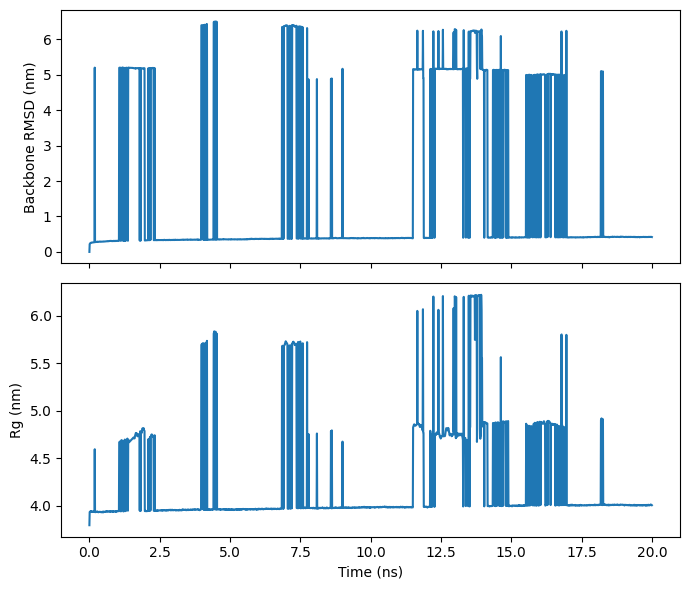

RMSD: last 5 ns mean 1.177 nm, sd 1.719, drift -0.4135 nm/ns
Rg: last 5 ns mean 4.155 nm, sd 0.338, drift -0.0786 nm/ns


In [ ]:
import numpy as np, matplotlib.pyplot as plt
r = np.loadtxt("rmsd.xvg", comments=("@","#"))
g = np.loadtxt("gyrate.xvg", comments=("@","#"))
tr, rm = r[:,0], r[:,1]
tg, rg = g[:,0]/1000, g[:,1]   # ps -> ns

fig, ax = plt.subplots(2,1, figsize=(7,6), sharex=True)
ax[0].plot(tr, rm); ax[0].set_ylabel("Backbone RMSD (nm)")
ax[1].plot(tg, rg); ax[1].set_ylabel("Rg (nm)"); ax[1].set_xlabel("Time (ns)")
plt.tight_layout(); plt.show()

for name,t,y in [("RMSD",tr,rm),("Rg",tg,rg)]:
    m = t > t.max()-5          # last 5 ns
    slope = np.polyfit(t[m], y[m], 1)[0]
    print(f"{name}: last 5 ns mean {y[m].mean():.3f} nm, sd {y[m].std():.3f}, drift {slope:.4f} nm/ns")

In [ ]:
%cd "/content/drive/My Drive/Legumin Hexamer MD"
!echo "Protein" | gmx trjconv -s md_20ns.tpr -f md_0-20ns_full.xtc -o protein_nj.xtc -pbc nojump
!echo "Backbone Protein" | gmx trjconv -s protein.tpr -f protein_nj.xtc -o protein_fit.xtc -fit rot+trans
!echo "Backbone Backbone" | gmx rms -s protein.tpr -f protein_fit.xtc -o rmsd.xvg -tu ns
!echo "Protein" | gmx gyrate -s protein.tpr -f protein_fit.xtc -o gyrate.xvg

/content/drive/My Drive/Legumin Hexamer MD
               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/My Drive/Legumin Hexamer MD
Command line:
  gmx trjconv -s md_20ns.tpr -f md_0-20ns_full.xtc -o protein_nj.xtc -pbc nojump

Note that major changes are planned in future for trjconv, to improve usability and utility.
Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for output
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
G

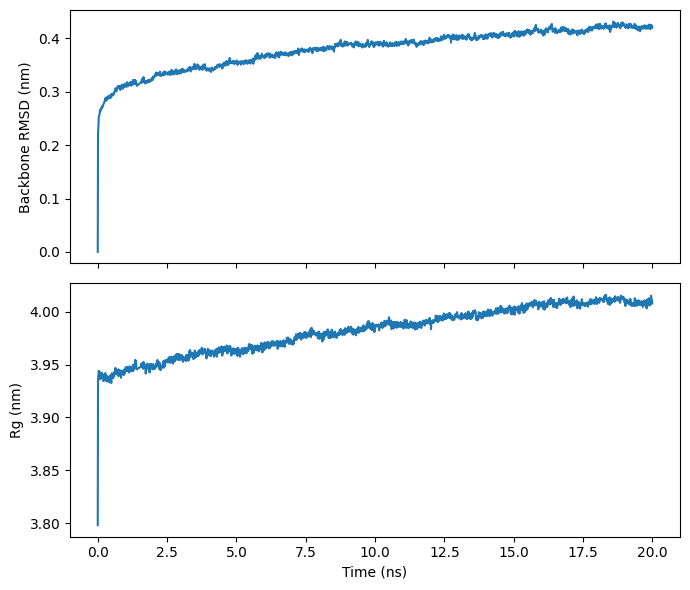

RMSD: last 5 ns mean 0.417 nm, sd 0.006, drift 0.0028 nm/ns
Rg: last 5 ns mean 4.008 nm, sd 0.003, drift 0.0011 nm/ns


In [ ]:
import numpy as np, matplotlib.pyplot as plt
r = np.loadtxt("rmsd.xvg", comments=("@","#"))
g = np.loadtxt("gyrate.xvg", comments=("@","#"))
tr, rm = r[:,0], r[:,1]
tg, rg = g[:,0]/1000, g[:,1]   # ps -> ns

fig, ax = plt.subplots(2,1, figsize=(7,6), sharex=True)
ax[0].plot(tr, rm); ax[0].set_ylabel("Backbone RMSD (nm)")
ax[1].plot(tg, rg); ax[1].set_ylabel("Rg (nm)"); ax[1].set_xlabel("Time (ns)")
plt.tight_layout(); plt.show()

for name,t,y in [("RMSD",tr,rm),("Rg",tg,rg)]:
    m = t > t.max()-5          # last 5 ns
    slope = np.polyfit(t[m], y[m], 1)[0]
    print(f"{name}: last 5 ns mean {y[m].mean():.3f} nm, sd {y[m].std():.3f}, drift {slope:.4f} nm/ns")

In [ ]:
%cd "/content/drive/My Drive/Legumin Hexamer MD"
!cp md_20ns.cpt md_20ns_final_safe.cpt
!gmx convert-tpr -s md_20ns.tpr -extend 10000 -o md_30ns.tpr

/content/drive/My Drive/Legumin Hexamer MD
             :-) GROMACS - gmx convert-tpr, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/My Drive/Legumin Hexamer MD
Command line:
  gmx convert-tpr -s md_20ns.tpr -extend 10000 -o md_30ns.tpr

Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Input file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                  10000000     
  Runtime for the run                            20000 ps  
  Run end step                                10000000     
  Run end time                                   20000 ps  

Extending remaining runtime by 10000 ps

Output file:
  Run start step                                     0     
  Run start time                                     0 ps  
  Step to be made during run                  15000000     
  Runtime

In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
nohup gmx mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu > run18.out 2>&1 &
sleep 90
tail -15 run18.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

Process is interrupted.


In [ ]:
%cd "/content/drive/My Drive/Legumin Hexamer MD"
!tail -25 run18.out
!tail -15 md_20ns.part0018.log
!gmx dump -s md_30ns.tpr 2>/dev/null | grep -E "^ *nsteps"
!gmx dump -cp md_20ns.cpt | grep -E "^ *(step|t|simulation part #) *="
!pgrep -a gmx || echo "nothing running"
!gmx --version | grep -iE "GPU support|^GROMACS version"

/content/drive/My Drive/Legumin Hexamer MD
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu


Back Off! I just backed up md_20ns.part0018.log to ./#md_20ns.part0018.log.1#
Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
E. Lindahl, B. Hess, D. van der Spoel
GROMACS 3.0: A package for molecular simulation and trajectory analysis
J. Mol. Mod.

In [ ]:
!pgrep -a gmx || echo "NOT RUNNING"
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv
!tail -8 "/content/drive/My Drive/Legumin Hexamer MD/run18.out"
!ls -la --time-style=long-iso "/content/drive/My Drive/Legumin Hexamer MD" | grep part0018

NOT RUNNING
utilization.gpu [%], memory.used [MiB]
0 %, 0 MiB

Fatal error:
Cannot run short-ranged nonbonded interactions on a GPU because no GPU is
detected.

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
-rw------- 1 root root      17752 2026-10-22 17:57 md_20ns.part0018.log
-rw------- 1 root root      17753 2026-10-22 17:53 #md_20ns.part0018.log.1#


In [ ]:
!mamba create -y -n gmx_cuda -c conda-forge "gromacs=2026.3=*cuda*"
!ls /usr/local/envs/gmx_cuda/bin*/gmx
!/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx --version | grep -iE "GPU support|^GROMACS version"

Streaming output truncated to the last 5000 lines.
Extracting         0%[+] 14.1s
Extracting         0%[+] 14.2s
Extracting         0%[+] 14.3s
Extracting         0%[+] 14.4s
Extracting         0%[+] 14.5s
Extracting         0%[+] 14.6s
Extracting         0%[+] 14.7s
Extracting         0%[+] 14.8s
Extracting         0%[+] 14.9s
Extracting         0%[+] 15.0s
Extracting         0%[+] 15.1s
Extracting         0%[+] 15.2s
Extracting         0%[+] 15.3s
Extracting         0%[+] 15.4s
Extracting         0%[+] 15.5s
Extracting         0%[+] 15.6s
Extracting         0%[+] 15.7s
Extracting         0%[+] 15.8s
Extracting         0%[+] 15.9s
Extracting         0%[+] 16.0s
Extracting         0%[+] 16.1s
Extracting         0%[+] 16.2s
Extracting         0%[+] 16.3s
Extracting         0%[+] 16.4s
Extracting         0%[+] 16.5s
Extracting         0%[+] 16.6s
Extracting         0%[+] 16.7s
Extracting         0%[+] 16.8s
Extracting         0%[+] 16.9s
Extracting         0%[+] 17.0s
Extracting         

In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
nohup $G mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns.cpt -noappend -nb gpu -pme gpu > run18.out 2>&1 &
sleep 90
tail -15 run18.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

Reading file md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 2 OpenMP threads 

starting mdrun 'Protein in water'
15000000 steps,  30000.0 ps (continuing from step 10000000,  20000.0 ps).
utilization.gpu [%], memory.used [MiB]
56 %, 225 MiB


In [ ]:
from google.colab import drive; drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
ls -la --time-style=long-iso md_20ns.part0018.*
for c in md_20ns.cpt md_20ns_prev.cpt; do echo "== $c"; $G dump -cp $c 2>/dev/null | grep -E "^ *(step|t) *="; done
echo "== xtc"; $G check -f md_20ns.part0018.xtc 2>&1 | grep -E "Reading frame|Last frame|^Step"
tail -4 md_20ns.part0018.log
true

-rw------- 1 root root    166008 2026-10-22 20:51 md_20ns.part0018.edr
-rw------- 1 root root    187406 2026-10-22 20:51 md_20ns.part0018.log
-rw------- 1 root root 173241276 2026-10-22 20:36 md_20ns.part0018.xtc
== md_20ns.cpt
step = 11239280
t = 22478.560000
== md_20ns_prev.cpt
step = 11126320
t = 22252.640000
== xtc
Reading frame       0 time 20000.000   
Reading frame     200 time 22000.000   
Step           232    10
   -2.70738e+06    5.44868e+05   -2.16251e+06   -1.29090e+06    3.08509e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.83422e+02   -1.20621e+02    0.00000e+00



shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
chdir: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected


In [ ]:
from google.colab import drive; drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
cp md_20ns.cpt md_20ns_t22478_safe.cpt
cp md_20ns_prev.cpt md_20ns_t22252_safe.cpt
nohup $G mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns_t22252_safe.cpt -noappend -nb gpu -pme gpu > run19.out 2>&1 &
sleep 90
tail -15 run19.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

Reading file md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 20 to 80, rlist from 1.022 to 1.157


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 2 OpenMP threads 

starting mdrun 'Protein in water'
15000000 steps,  30000.0 ps (continuing from step 11126320,  22252.6 ps).
utilization.gpu [%], memory.used [MiB]
53 %, 223 MiB


shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
chdir: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected


%cd /content
!pgrep -a gmx | cut -c1-70 || echo "NOT RUNNING"
!ls /content/drive/MyDrive/ >/dev/null 2>&1 && echo "Drive OK" || echo "Drive NOT mounted"
!ls -la --time-style=long-iso "/content/drive/My Drive/Legumin Hexamer MD" | grep part0019
!grep -E "^ +[0-9]+ +[0-9]+\.[0-9]+$" "/content/drive/My Drive/Legumin Hexamer MD/md_20ns.part0019.log" | tail -1

In [ ]:
import os
os.chdir('/content')
print(os.getcwd())

/content


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!pgrep -a gmx | cut -c1-80 || echo "NOT RUNNING"
!ls -la --time-style=long-iso "/content/drive/My Drive/Legumin Hexamer MD" | grep -E "part0019|\.cpt"
!grep -E "^ +[0-9]+ +[0-9]+\.[0-9]+$" "/content/drive/My Drive/Legumin Hexamer MD/md_20ns.part0019.log" | tail -1

-rw------- 1 root root    4808296 2026-10-14 18:09 md_10ns.cpt
-rw------- 1 root root    4808296 2026-10-14 18:09 md_10ns_prev.cpt
-rw------- 1 root root    4808296 2026-10-23 18:28 md_20ns.cpt
-rw------- 1 root root    4808296 2026-10-20 18:52 md_20ns_final_safe.cpt
-rw------- 1 root root       6336 2026-10-23 18:28 md_20ns.part0019.edr
-rw------- 1 root root      33872 2026-10-23 18:28 md_20ns.part0019.log
-rw------- 1 root root    5227780 2026-10-23 18:28 md_20ns.part0019.xtc
-rw------- 1 root root    4808296 2026-10-23 18:28 md_20ns_prev.cpt
-rw------- 1 root root    4808296 2026-10-19 17:55 md_20ns_prev_safe.cpt
-rw------- 1 root root    4808296 2026-10-20 17:17 md_20ns_safe2.cpt
-rw------- 1 root root    4808296 2026-10-19 17:55 md_20ns_safe.cpt
-rw------- 1 root root    4808296 2026-10-23 18:23 md_20ns_t22252_safe.cpt
-rw------- 1 root root    4808296 2026-10-23 18:23 md_20ns_t22478_safe.cpt
-rw------- 1 root root    4808296 2026-10-09 13:31 md_5ns.cpt
-rw------- 1 root root    

In [ ]:
!date
!pgrep -a gmx | cut -c1-80 || echo "NOT RUNNING"
!grep -E "^ +[0-9]+ +[0-9]+\.[0-9]+$" "/content/drive/My Drive/Legumin Hexamer MD/md_20ns.part0019.log" | tail -1

In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=$(ls /usr/local/envs/gmx_cuda/bin*/gmx | head -1)
pgrep -a gmx && { echo "ALREADY RUNNING"; exit 1; }
cp md_20ns.cpt md_20ns_t22320_safe.cpt
nohup $G mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns_t22320_safe.cpt -noappend -nb gpu -pme gpu -cpt 5 > run20.out 2>&1 &
sleep 90
grep "continuing from" run20.out
tail -8 run20.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

15000000 steps,  30000.0 ps (continuing from step 11160400,  22320.8 ps).
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 2 OpenMP threads 

starting mdrun 'Protein in water'
15000000 steps,  30000.0 ps (continuing from step 11160400,  22320.8 ps).
utilization.gpu [%], memory.used [MiB]
64 %, 223 MiB


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=$(ls /usr/local/envs/gmx_cuda/bin*/gmx | head -1)
$G check -f md_20ns.part0020.xtc 2>&1 | grep -E "Reading frame|Last frame|^Step"
for c in md_20ns.cpt md_20ns_prev.cpt; do echo $c $($G dump -cp $c 2>/dev/null | grep -E "^ *(t|simulation part #) =" | tr '\n' ' '); done
pgrep -a gmx | cut -c1-50 || echo "nothing running"

Reading frame       0 time 22330.000   
Reading frame     200 time 24330.000   
Step           243    10
md_20ns.cpt simulation part # = 20 t = 24756.320000
md_20ns_prev.cpt simulation part # = 20 t = 24683.360000


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=$(ls /usr/local/envs/gmx_cuda/bin*/gmx | head -1)
pgrep -a gmx && { echo "ALREADY RUNNING"; exit 1; }
cp md_20ns.cpt md_20ns_t24756_safe.cpt
nohup $G mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns_t24756_safe.cpt -noappend -nb gpu -pme gpu -cpt 5 > run21.out 2>&1 &
sleep 90
grep "continuing from" run21.out
tail -6 run21.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

15000000 steps,  30000.0 ps (continuing from step 12378160,  24756.3 ps).
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 2 OpenMP threads 

starting mdrun 'Protein in water'
15000000 steps,  30000.0 ps (continuing from step 12378160,  24756.3 ps).
utilization.gpu [%], memory.used [MiB]
60 %, 215 MiB


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=$(ls /usr/local/envs/gmx_cuda/bin*/gmx 2>/dev/null | head -1); echo "gmx: ${G:-MISSING}"
pgrep -a gmx | cut -c1-50 || echo "nothing running"
F=$(ls md_20ns.part*.xtc | sort | tail -1); echo "newest: $F"
python3 - "$F" <<'EOF'
import struct, os, sys
f = sys.argv[1]; sz = os.path.getsize(f); pos = 0; n = 0; last = None; first = None
with open(f, 'rb') as fh:
    while pos + 92 <= sz:
        fh.seek(pos); h = fh.read(92)
        magic, natoms, step, t = struct.unpack('>iiif', h[:16])
        if magic != 1995: break
        nb = struct.unpack('>i', h[88:92])[0]
        end = pos + 92 + ((nb + 3) & ~3)
        if end > sz: break
        if first is None: first = t
        last = t; n += 1; pos = end
print(f"frames={n} first={first:.1f} ps LAST FRAME={last:.1f} ps")
EOF
for c in md_20ns.cpt md_20ns_prev.cpt; do echo "$c $($G dump -cp $c 2>/dev/null | grep -E '^ *(t|simulation part #) *=' | tr '\n' ' ')"; done

gmx: /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
newest: md_20ns.part0021.xtc
frames=172 first=24760.0 ps LAST FRAME=26470.0 ps
md_20ns.cpt simulation part # = 21 t = 26518.560000 
md_20ns_prev.cpt simulation part # = 21 t = 26439.040000 


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
pgrep -a gmx && { echo "ALREADY RUNNING"; exit 1; }
cp md_20ns.cpt md_20ns_t26518_safe.cpt
cp md_20ns_prev.cpt md_20ns_t26439_safe.cpt
nohup $G mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns_t26439_safe.cpt -noappend -nb gpu -pme gpu -cpt 5 -maxh 1.8 > run22.out 2>&1 &
sleep 90
grep "continuing from" run22.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

15000000 steps,  30000.0 ps (continuing from step 13219520,  26439.0 ps).
utilization.gpu [%], memory.used [MiB]
51 %, 223 MiB


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=$(ls /usr/local/envs/gmx_cuda/bin*/gmx | head -1)
F=$(ls md_20ns.part0022.xtc | sort | tail -1); echo $F
$G check -f $F 2>&1 | grep -E "Reading frame +0 |Last frame|^Step"
for c in md_20ns.cpt md_20ns_prev.cpt; do echo $c $($G dump -cp $c 2>/dev/null | grep -E "^ *(t|simulation part #) *=" | tr '\n' ' '); done

md_20ns.part0022.xtc
Reading frame       0 time 26440.000   
Step           155    10
md_20ns.cpt simulation part # = 22 t = 27987.520000
md_20ns_prev.cpt simulation part # = 22 t = 27959.360000


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
pgrep -a gmx && { echo "ALREADY RUNNING"; exit 1; }
cp md_20ns.cpt md_20ns_t27987_safe.cpt
nohup $G mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns_t27987_safe.cpt -noappend -nb gpu -pme gpu -cpt 5 -maxh 1.8 > run23.out 2>&1 &
sleep 90
grep "continuing from" run23.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

15000000 steps,  30000.0 ps (continuing from step 13993760,  27987.5 ps).
utilization.gpu [%], memory.used [MiB]
69 %, 225 MiB


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
$G check -f md_20ns.part0023.xtc 2>&1 | grep -E "Reading frame +0 |Last frame|^Step"
$G dump -cp md_20ns.cpt 2>/dev/null | grep -E "^ *(t|simulation part #) *="

Reading frame       0 time 27990.000   
Step           166    10
simulation part # = 23
t = 29645.120000


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
pgrep -a gmx && { echo "ALREADY RUNNING"; exit 1; }
cp md_20ns.cpt md_20ns_t29645_safe.cpt
nohup $G mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns_t29645_safe.cpt -noappend -nb gpu -pme gpu -cpt 5 > run24.out 2>&1 &
sleep 90
grep "continuing from" run24.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

15000000 steps,  30000.0 ps (continuing from step 14822560,  29645.1 ps).
utilization.gpu [%], memory.used [MiB]
69 %, 217 MiB


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
[ -f md_20ns_t29645_safe.cpt ] || { echo "SAFE COPY MISSING"; exit 1; }
pgrep -a gmx && { echo "ALREADY RUNNING"; exit 1; }
nohup $G mdrun -s md_30ns.tpr -deffnm md_20ns -cpi md_20ns_t29645_safe.cpt -noappend -nb gpu -pme gpu -cpt 5 > run25.out 2>&1 &
sleep 90
grep "continuing from" run25.out
nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

15000000 steps,  30000.0 ps (continuing from step 14822560,  29645.1 ps).
utilization.gpu [%], memory.used [MiB]
64 %, 225 MiB


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
python3 - <<'EOF'
import struct, os
files = ["md_0-20ns_full.xtc"] + [f"md_20ns.part{i:04d}.xtc" for i in range(18, 25)]
prev = None
for f in files:
    if not os.path.exists(f): print(f"{f}: MISSING"); continue
    sz = os.path.getsize(f); pos = 0; n = 0; first = last = None
    with open(f, 'rb') as fh:
        while pos + 92 <= sz:
            fh.seek(pos); h = fh.read(92)
            magic, natoms, step, t = struct.unpack('>iiif', h[:16])
            if magic != 1995: break
            nb = struct.unpack('>i', h[88:92])[0]
            end = pos + 92 + ((nb + 3) & ~3)
            if end > sz: break
            if first is None: first = t
            last = t; n += 1; pos = end
    flag = ""
    if prev is not None and first > prev + 10.5: flag = f"  <-- GAP after {prev:.0f}"
    print(f"{f}: {n} frames, {first:.0f} -> {last:.0f} ps{flag}")
    prev = last
EOF

md_0-20ns_full.xtc: 1981 frames, 0 -> 20000 ps
md_20ns.part0018.xtc: 232 frames, 20000 -> 22310 ps
md_20ns.part0019.xtc: 7 frames, 22260 -> 22320 ps
md_20ns.part0020.xtc: 243 frames, 22330 -> 24750 ps
md_20ns.part0021.xtc: 172 frames, 24760 -> 26470 ps
md_20ns.part0022.xtc: 155 frames, 26440 -> 27980 ps
md_20ns.part0023.xtc: 166 frames, 27990 -> 29640 ps
md_20ns.part0024.xtc: 36 frames, 29650 -> 30000 ps


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=$(ls /usr/local/envs/gmx_cuda/bin*/gmx 2>/dev/null | head -1); G=${G:-gmx}
$G trjcat -f md_0-20ns_full.xtc md_20ns.part0018.xtc md_20ns.part0019.xtc md_20ns.part0020.xtc md_20ns.part0021.xtc md_20ns.part0022.xtc md_20ns.part0023.xtc md_20ns.part0024.xtc -o md_0_30ns_full.xtc 2>&1 | tail -8
ls -la md_0_30ns_full.xtc
$G check -f md_0_30ns_full.xtc 2>&1 | grep -E "Reading frame +0 |Last frame|^Step"


lasttime 24750

lasttime 26430

lasttime 27980

lasttime 29640
-rw------- 1 root root 2226117068 Oct 27 14:26 md_0_30ns_full.xtc
Reading frame       0 time    0.000   
Step          2981


In [ ]:
%%bash
cd "/content/drive/My Drive/Legumin Hexamer MD"
G=$(ls /usr/local/envs/gmx_cuda/bin*/gmx 2>/dev/null | head -1); G=${G:-gmx}
echo "Protein" | $G trjconv -s md_20ns.tpr -f md_0_30ns_full.xtc -o protein_nj30.xtc -pbc nojump
echo "Backbone Protein" | $G trjconv -s protein.tpr -f protein_nj30.xtc -o protein_fit30.xtc -fit rot+trans
echo "Backbone Backbone" | $G rms -s protein.tpr -f protein_fit30.xtc -o rmsd30.xvg -tu ns
echo "Protein" | $G gyrate -s protein.tpr -f protein_fit30.xtc -o gyrate30.xvg

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for least squares fit
Selected 4: 'Backbone'
Select group for output
Selected 1: 'Protein'
Selected 4: 'Backbone'
Selected 4: 'Backbone'


               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/My Drive/Legumin Hexamer MD
Command line:
  gmx trjconv -s md_20ns.tpr -f md_0_30ns_full.xtc -o protein_nj30.xtc -pbc nojump

Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_20ns.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) has 32220 elements
Group     9 (    SideChain-H) has

window  RMSD mean  drift/ns | Rg mean  drift/ns
 0- 5 ns  0.327  +0.0152 | 3.952  +0.0061
 5-10 ns  0.376  +0.0075 | 3.975  +0.0048
10-15 ns  0.398  +0.0042 | 3.994  +0.0033
15-20 ns  0.417  +0.0028 | 4.008  +0.0011
20-25 ns  0.427  +0.0013 | 4.013  +0.0005
25-30 ns  0.432  +0.0030 | 4.019  +0.0022


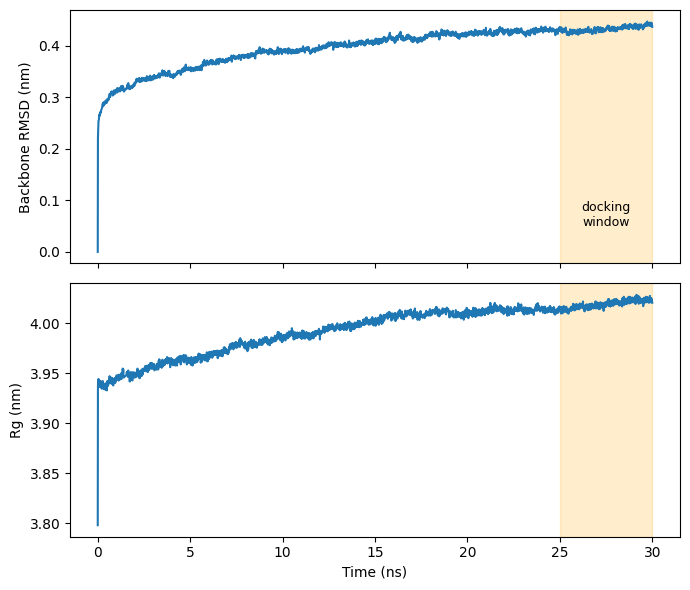

In [ ]:
import numpy as np, matplotlib.pyplot as plt
d = "/content/drive/My Drive/Legumin Hexamer MD/"
r = np.loadtxt(d+"rmsd30.xvg", comments=("@","#")); g = np.loadtxt(d+"gyrate30.xvg", comments=("@","#"))
tr, rm = r[:,0], r[:,1]; tg, rg = g[:,0]/1000, g[:,1]
print("window  RMSD mean  drift/ns | Rg mean  drift/ns")
for a in range(0, 30, 5):
    m = (tr>=a)&(tr<a+5); k = (tg>=a)&(tg<a+5)
    print(f"{a:2d}-{a+5:2d} ns  {rm[m].mean():.3f}  {np.polyfit(tr[m],rm[m],1)[0]:+.4f} | {rg[k].mean():.3f}  {np.polyfit(tg[k],rg[k],1)[0]:+.4f}")

fig, ax = plt.subplots(2,1,figsize=(7,6),sharex=True)
ax[0].plot(tr,rm); ax[0].set_ylabel("Backbone RMSD (nm)")
ax[1].plot(tg,rg); ax[1].set_ylabel("Rg (nm)"); ax[1].set_xlabel("Time (ns)")
for a_ in ax:
    a_.axvspan(25, 30, color="orange", alpha=0.2)
ax[0].text(27.5, 0.05, "docking\nwindow", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(d+"fig1_rmsd_rg.png", dpi=300)
plt.show()

In [ ]:
!gmx trjconv -s md_30ns.tpr -f md_0_30ns_full.xtc -o last5ns.xtc -b 25000 -e 30000 -pbc mol -center

/bin/bash: line 1: gmx: command not found


In [ ]:
!mamba create -y -n gmx_cuda -c conda-forge "gromacs=2026.3=*cuda*"

conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache
[+] 0.0s


Transaction

  Prefix: /usr/local/envs/gmx_cuda

  Updating specs:

   - gromacs[version="=2026.3",build="*cuda*"]


  Package                               Version  Build                  Channel           Size
────────────────────────────────────────────────────────────────────────────────────────────────
  Install:
────────────────────────────────────────────────────────────────────────────────────────────────

  + _openmp_mutex                           4.5  20_gnu                 conda-forge     Cached
  + alsa-lib                           1.2.16.1  h7cc23a3_1             conda-forge     Cached
  + binutils                             2.46.1  default_h4852527_103   conda-forge     Cached
  + binutils_impl_linux-64               2.46.1  default_hfdba357_103   conda-forge     Cached
  + binutils_linux-64                    2.46.1

In [ ]:
!which gmx
!gmx --version

/usr/local/bin/gmx
                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         OpenCL
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     clFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_ar

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"
!ls -lh md_30ns.tpr md_0_30ns_full.xtc

/content/drive/MyDrive/Legumin Hexamer MD
-rw------- 1 root root 2.1G Oct 27 14:24 md_0_30ns_full.xtc
-rw------- 1 root root  16M Oct 20 18:52 md_30ns.tpr


In [ ]:
!echo "Protein Protein" | gmx trjconv -s md_30ns.tpr -f md_0_30ns_full.xtc -o last5ns.xtc -b 25000 -e 30000 -pbc mol -center

               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx trjconv -s md_30ns.tpr -f md_0_30ns_full.xtc -o last5ns.xtc -b 25000 -e 30000 -pbc mol -center

Note that major changes are planned in future for trjconv, to improve usability and utility.
Will write xtc: Compressed trajectory (portable xdr format): xtc
Reading file md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for centering
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainC

In [ ]:
!gmx check -f last5ns.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx check -f last5ns.xtc

Checking file last5ns.xtc
Reading frame       0 time 25000.000   
# Atoms  46974
Precision 0.001 (nm)
Last frame        500 time 30000.000   


Item        #frames Timestep (ps)
Step           501    10
Time           501    10
Lambda           0
Coords         501    10
Velocities       0
Forces           0
Box            501    10

GROMACS reminds you: "Almost without exception, the talented women I have known have believed they had less ability than they actually had. And almost without exception, the talented men I have known believed they had more." (Gregory Petsko)



In [ ]:
!pwd
!ls -lh last5ns.xtc

/content/drive/MyDrive/Legumin Hexamer MD
-rw------- 1 root root 86M Oct 31 10:52 last5ns.xtc


In [ ]:
!cp /content/last5ns.xtc "/content/drive/MyDrive/Legumin Hexamer MD/"

cp: cannot stat '/content/last5ns.xtc': No such file or directory


In [ ]:
!echo "Protein" | gmx trjconv -s md_30ns.tpr -f last5ns.xtc -o frame.pdb -sep -skip 17

               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/drive/MyDrive/Legumin Hexamer MD
Command line:
  gmx trjconv -s md_30ns.tpr -f last5ns.xtc -o frame.pdb -sep -skip 17

Note that major changes are planned in future for trjconv, to improve usability and utility.
Will write pdb: Protein data bank file
Reading file md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Select group for output
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has 14754 elements
Group     8 (      SideChain) ha

In [ ]:
!mamba install -y -c conda-forge openbabel vina

[+] 0.0s
[+] 0.0s
[+] 0.1s
conda-forge/linux-64   1%
conda-forge/noarch     1%[+] 0.2s
conda-forge/linux-64   9%
conda-forge/noarch    19%[+] 0.3s
conda-forge/linux-64  17%
conda-forge/noarch    34%[+] 0.4s
conda-forge/linux-64  22%
conda-forge/noarch    43%[+] 0.5s
conda-forge/linux-64  26%
conda-forge/noarch    52%[+] 0.6s
conda-forge/linux-64  26%
conda-forge/noarch    52%[+] 0.7s
conda-forge/linux-64  26%
conda-forge/noarch    52%[+] 0.8s
conda-forge/linux-64  26%
conda-forge/noarch    52%[+] 0.9s
conda-forge/linux-64  26%
conda-forge/noarch    58%[+] 1.0s
conda-forge/linux-64  26%
conda-forge/noarch    58%[+] 1.1s
conda-forge/linux-64  26%
conda-forge/noarch    58%[+] 1.2s
conda-forge/linux-64  26%
conda-forge/noarch    58%[+] 1.3s
conda-forge/linux-64  26%
conda-forge/noarch    58%[+] 1.4s
conda-forge/linux-64  29%
conda-forge/noarch    58%[+] 1.5s
conda-forge/linux-64  29%
conda-forge/noarch    58%[+] 1.6s
conda-forge/linux-64  29%
conda-forge/noarch    58%[+] 1.7s
conda-forge/l

In [ ]:
%cd "/content/drive/MyDrive/Legumin Hexamer MD"
!ls -lh frame*.pdb

/content/drive/MyDrive/Legumin Hexamer MD
-rw------- 1 root root 3.6M Oct 31 10:56 frame0.pdb
-rw------- 1 root root 3.6M Oct 31 10:56 frame12.pdb
-rw------- 1 root root 3.6M Oct 31 10:56 frame18.pdb
-rw------- 1 root root 3.6M Oct 31 10:56 frame24.pdb
-rw------- 1 root root 3.6M Oct 31 10:56 frame29.pdb
-rw------- 1 root root 3.6M Oct 31 10:56 frame6.pdb


In [ ]:
%%bash
mkdir -p /content/dock
cp frame0.pdb frame6.pdb frame12.pdb frame18.pdb frame24.pdb frame29.pdb /content/dock/
cd /content/dock
for n in 0 6 12 18 24 29; do
  obabel frame$n.pdb -O rec_$n.pdbqt -xr
done
ls -lh rec_*.pdbqt
cp rec_*.pdbqt "/content/drive/MyDrive/Legumin Hexamer MD/"

-rw-r--r-- 1 root root 2.3M Oct 31 11:15 rec_0.pdbqt
-rw-r--r-- 1 root root 1.4M Oct 31 11:15 rec_12.pdbqt
-rw-r--r-- 1 root root    0 Oct 31 11:15 rec_18.pdbqt
-rw-r--r-- 1 root root    0 Oct 31 11:15 rec_24.pdbqt
-rw-r--r-- 1 root root    0 Oct 31 11:15 rec_29.pdbqt
-rw-r--r-- 1 root root 2.3M Oct 31 11:15 rec_6.pdbqt


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
mkdir -p /content/dock && cd /content/dock
for pair in "0 25000" "6 26020" "12 27040" "18 28060" "24 29080" "29 29930"; do
  set -- $pair
  echo "Protein" | gmx trjconv -s "$D/md_30ns.tpr" -f "$D/last5ns.xtc" -dump $2 -o frame$1.pdb
  obabel frame$1.pdb -O rec_$1.pdbqt -xr
done
ls -lh frame*.pdb rec_*.pdbqt
cp frame*.pdb rec_*.pdbqt "$D/"

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for output
Selected 1: 'Protein'
-rw-r--r-- 1 root root 3.6M Oct 31 11:19 frame0.pdb
-rw-r--r-- 1 root root 3.6M Oct 31 11:19 frame12.pdb
-rw-r--r-- 1 root root 3.6M Oct 31 11:19 frame18.pdb
-rw-r--r

shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
chdir: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/dock
Command line:
  gmx trjconv -s '/content/drive/MyDrive/Legumin Hexamer MD/md_30ns.tpr' -f '/content/drive/MyDrive/Legumin Hexamer MD/last5ns.xtc' -dump 25000 -o frame0.pdb

Will write pdb: Protein data bank file
Reading file /content/drive/MyDrive/Legumin Hexamer MD/md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file /content/drive/MyDrive/Legumin Hexamer MD/md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Grou

In [ ]:
%%bash
cd "/content/drive/MyDrive/Legumin Hexamer MD"
for n in 0 6 12 18 24 29; do
  a=$(grep -c "^ATOM" frame$n.pdb)
  r=$(grep -c "^ATOM" rec_$n.pdbqt)
  e=$(tail -n 1 frame$n.pdb)
  echo "frame$n: $(stat -c %s frame$n.pdb) B, ATOM=$a | rec_$n: $(stat -c %s rec_$n.pdbqt) B, ATOM=$r | last line: $e"
done

frame0: 3711166 B, ATOM=46974 | rec_0: 2397198 B, ATOM=29940 | last line: ENDMDL
frame6: 3711166 B, ATOM=46974 | rec_6: 2397198 B, ATOM=29940 | last line: ENDMDL
frame12: 3711166 B, ATOM=46974 | rec_12: 2397204 B, ATOM=29940 | last line: ENDMDL
frame18: 3711166 B, ATOM=46974 | rec_18: 2397204 B, ATOM=29940 | last line: ENDMDL
frame24: 3711166 B, ATOM=46974 | rec_24: 2397204 B, ATOM=29940 | last line: ENDMDL
frame29: 3711166 B, ATOM=46974 | rec_29: 2397204 B, ATOM=29940 | last line: ENDMDL


shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
chdir: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected


In [ ]:
import os, shutil, glob
os.makedirs("/content/dock", exist_ok=True)
D = "/content/drive/MyDrive/Legumin Hexamer MD"
for f in glob.glob(D+"/rec_*.pdbqt") + [D+"/frame0.pdb"]:
    shutil.copy(f, "/content/dock/")
import numpy as np
xyz = np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])]
                for l in open("/content/dock/frame0.pdb") if l.startswith("ATOM")])
c = (xyz.max(0)+xyz.min(0))/2
s = xyz.max(0)-xyz.min(0)+10
print("center", c.round(1), "size", s.round(1))

center [ 59.7 105.6  49.8] size [218.  124.7 115.7]


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
mkdir -p /content/dock && cd /content/dock
for pair in "0 25000" "6 26020" "12 27040" "18 28060" "24 29080" "29 29930"; do
  set -- $pair
  echo "Protein Protein Protein" | gmx trjconv -s "$D/md_30ns.tpr" -f "$D/last5ns.xtc" -dump $2 -pbc cluster -center -o frame$1.pdb
  obabel frame$1.pdb -O rec_$1.pdbqt -xr
done
ls -lh frame*.pdb rec_*.pdbqt
cp frame*.pdb rec_*.pdbqt "$D/"

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for clustering
Selected 1: 'Protein'
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'
Clustering iteration 6 of 6...
Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for clustering
Selected 1: 'Protein'
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6...
Clustering iteration 6 of 6.

shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
chdir: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
               :-) GROMACS - gmx trjconv, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
Data prefix:  /usr/local
Working dir:  /content/dock
Command line:
  gmx trjconv -s '/content/drive/MyDrive/Legumin Hexamer MD/md_30ns.tpr' -f '/content/drive/MyDrive/Legumin Hexamer MD/last5ns.xtc' -dump 25000 -pbc cluster -center -o frame0.pdb

Will write pdb: Protein data bank file
Reading file /content/drive/MyDrive/Legumin Hexamer MD/md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file /content/drive/MyDrive/Legumin Hexamer MD/md_30ns.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 200254 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) ha

In [ ]:
import numpy as np
for n in [0,6,12,18,24,29]:
    xyz = np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])]
                    for l in open(f"/content/dock/frame{n}.pdb") if l.startswith("ATOM")])
    print(n, (xyz.max(0)+xyz.min(0))/2, (xyz.max(0)-xyz.min(0)).round(1))

0 [105.607 105.607  49.784] [116.4 114.7 105.7]
6 [105.529 105.529  49.747] [115.9 111.  113.8]
12 [105.611 105.611  49.785] [115.9 113.3 122.6]
18 [105.5855 105.586   49.774 ] [117.  115.  111.2]
24 [105.5615 105.562   49.762 ] [121.3 117.3 113.4]
29 [105.569 105.569  49.766] [118.4 113.  109.4]


In [ ]:
%%bash
cd /content/dock
SMI=$(curl -s "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/31703/property/IsomericSMILES/TXT")
echo "$SMI"
obabel -:"$SMI" -O dox.pdbqt --gen3d -p 7.4
ls -lh dox.pdbqt

C[C@H]1[C@H]([C@H](C[C@@H](O1)O[C@H]2C[C@@](CC3=C2C(=C4C(=C3O)C(=O)C5=C(C4=O)C(=CC=C5)OC)O)(C(=O)CO)O)N)O
-rw-r--r-- 1 root root 4.9K Oct 31 11:26 dox.pdbqt


shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
chdir: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
curl: /usr/local/lib/libcurl.so.4: no version information available (required by curl)
1 molecule converted


In [ ]:
%%bash
cd /content/dock
grep -c "^ATOM\|^HETATM" dox.pdbqt
grep -E "TORSDOF|ROOT" dox.pdbqt
vina --version
ls -lh rec_*.pdbqt

46
ROOT
ENDROOT
TORSDOF 11
AutoDock Vina f458505-mod
-rw------- 1 root root 2.3M Oct 31 11:23 rec_0.pdbqt
-rw------- 1 root root 2.3M Oct 31 11:23 rec_12.pdbqt
-rw------- 1 root root 2.3M Oct 31 11:24 rec_18.pdbqt
-rw------- 1 root root 2.3M Oct 31 11:24 rec_24.pdbqt
-rw------- 1 root root 2.3M Oct 31 11:24 rec_29.pdbqt
-rw------- 1 root root 2.3M Oct 31 11:23 rec_6.pdbqt


shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
chdir: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected


In [ ]:
import os, shutil, glob, urllib.request
D = "/content/drive/MyDrive/Legumin Hexamer MD"
os.makedirs("/content/dock", exist_ok=True)
for f in glob.glob(D+"/rec_*.pdbqt"):
    shutil.copy(f, "/content/dock/")
url = "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/31703/property/IsomericSMILES/TXT"
smi = urllib.request.urlopen(url).read().decode().strip()
print(smi)
open("/content/dock/dox.smi","w").write(smi)

C[C@H]1[C@H]([C@H](C[C@@H](O1)O[C@H]2C[C@@](CC3=C2C(=C4C(=C3O)C(=O)C5=C(C4=O)C(=CC=C5)OC)O)(C(=O)CO)O)N)O


105

In [ ]:
%cd /content/dock
!obabel dox.smi -O dox.pdbqt --gen3d -p 7.4
!grep -c "^ATOM\|^HETATM" dox.pdbqt

/content/dock
1 molecule converted
46


In [ ]:
%%bash
cd /content/dock
time vina --receptor rec_0.pdbqt --ligand dox.pdbqt \
  --center_x 105.6 --center_y 105.6 --center_z 49.8 \
  --size_x 135 --size_y 135 --size_z 135 \
  --exhaustiveness 16 --num_modes 9 --cpu 2 --seed 1 \
  --out dock_0.pdbqt > dock_0.log
grep -m1 "^   1 " dock_0.log
cp dock_0.* "/content/drive/MyDrive/Legumin Hexamer MD/"



PDBQT parsing error: Unknown or inappropriate tag found in rigid receptor.
 > TITLE     Protein in water t= 25000.00000 step= 12500000

real	0m0.006s
user	0m0.004s
sys	0m0.001s


In [ ]:
%%bash
cd /content/dock
for n in 0 6 12 18 24 29; do
  grep -E "^(ATOM|HETATM)" rec_$n.pdbqt > tmp && mv tmp rec_$n.pdbqt
done
head -n 2 rec_0.pdbqt
grep -vcE "^(ATOM|HETATM)" rec_0.pdbqt
cp rec_*.pdbqt "/content/drive/MyDrive/Legumin Hexamer MD/"

ATOM      1  N   LEU A  22     130.702  98.392  11.079  1.00  0.00    +0.000 N 
ATOM      2  H1  LEU A  22     131.552  98.942  11.149  1.00  0.00    +0.000 HD
0


In [ ]:
%%bash
cd /content/dock
time vina --receptor rec_0.pdbqt --ligand dox.pdbqt \
  --center_x 105.6 --center_y 105.6 --center_z 49.8 \
  --size_x 135 --size_y 135 --size_z 135 \
  --exhaustiveness 16 --num_modes 9 --cpu 2 --seed 1 \
  --out dock_0.pdbqt > dock_0.log
grep -m1 "^   1 " dock_0.log
cp dock_0.* "/content/drive/MyDrive/Legumin Hexamer MD/"

   1       -9.857          0          0



real	6m19.635s
user	9m52.153s
sys	0m3.309s


In [ ]:
%%bash
cd /content/dock
for n in 6 12 18 24 29; do
  vina --receptor rec_$n.pdbqt --ligand dox.pdbqt \
    --center_x 105.6 --center_y 105.6 --center_z 49.8 \
    --size_x 135 --size_y 135 --size_z 135 \
    --exhaustiveness 16 --num_modes 9 --cpu 2 --seed 1 \
    --out dock_$n.pdbqt > dock_$n.log
  cp dock_$n.* "/content/drive/MyDrive/Legumin Hexamer MD/"
done
grep -H -m1 "^   1 " dock_*.log

dock_0.log:   1       -9.857          0          0
dock_12.log:   1       -9.177          0          0
dock_18.log:   1       -9.342          0          0
dock_24.log:   1       -9.886          0          0
dock_29.log:   1       -9.878          0          0
dock_6.log:   1       -10.02          0          0


In [ ]:
import numpy as np
for n in [0,6,12,18,24,29]:
    xyz=[]
    for l in open(f"/content/dock/dock_{n}.pdbqt"):
        if l.startswith("ENDMDL"): break
        if l.startswith(("ATOM","HETATM")):
            xyz.append([float(l[30:38]),float(l[38:46]),float(l[46:54])])
    c=np.mean(xyz,0)
    print(n, c.round(1), "dist from center:", round(float(np.linalg.norm(c-[105.6,105.6,49.8])),1))

0 [136.2 130.5  62.1] dist from center: 41.3
6 [121.8  95.5  34.4] dist from center: 24.5
12 [72.1 81.4 52. ] dist from center: 41.4
18 [90.9 68.7 44.8] dist from center: 40.0
24 [121.4  99.6  33.6] dist from center: 23.4
29 [117.7  95.9  31. ] dist from center: 24.3


In [ ]:
%%bash
cd /content/dock
run() {  # name cx cy cz
  for n in 0 6 12 18 24 29; do
    vina --receptor rec_$n.pdbqt --ligand dox.pdbqt \
      --center_x $2 --center_y $3 --center_z $4 \
      --size_x 30 --size_y 30 --size_z 30 \
      --exhaustiveness 32 --num_modes 9 --cpu 2 --seed 1 \
      --out dock_${1}_$n.pdbqt > dock_${1}_$n.log
    cp dock_${1}_$n.* "/content/drive/MyDrive/Legumin Hexamer MD/"
  done
}
run siteA 120.3 97.0 33.0
run center 105.6 105.6 49.8
grep -H -m1 "^   1 " dock_siteA_*.log dock_center_*.log

dock_siteA_0.log:   1       -9.393          0          0
dock_siteA_12.log:   1       -10.53          0          0
dock_siteA_18.log:   1       -10.11          0          0
dock_siteA_24.log:   1       -10.33          0          0
dock_siteA_29.log:   1       -10.61          0          0
dock_siteA_6.log:   1       -9.895          0          0
dock_center_0.log:   1       -9.308          0          0
dock_center_12.log:   1       -9.391          0          0
dock_center_18.log:   1       -9.502          0          0
dock_center_24.log:   1       -9.375          0          0
dock_center_29.log:   1       -9.239          0          0
dock_center_6.log:   1       -9.738          0          0


In [ ]:
!pip install -q pdb2pqr

In [ ]:
%%bash
cd /content/dock
ls -lh frame29.pdb frame6.pdb
curl -s "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/31703/property/IsomericSMILES/TXT" > dox.smi
cat dox.smi
obabel dox.smi -O dox.pdbqt --gen3d -p 7.4
grep -c "^ATOM\|^HETATM" dox.pdbqt
grep -E "TORSDOF|ROOT" dox.pdbqt
cp dox.pdbqt "/content/drive/MyDrive/Legumin Hexamer MD/"

-rw------- 1 root root 3.6M Oct 31 16:22 frame29.pdb
-rw------- 1 root root 3.6M Oct 31 16:22 frame6.pdb
C[C@H]1[C@H]([C@H](C[C@@H](O1)O[C@H]2C[C@@](CC3=C2C(=C4C(=C3O)C(=O)C5=C(C4=O)C(=CC=C5)OC)O)(C(=O)CO)O)N)O
46
ROOT
ENDROOT
TORSDOF 11


curl: /usr/local/lib/libcurl.so.4: no version information available (required by curl)
1 molecule converted


In [ ]:
%%bash
cd /content/dock
for n in 29 6; do
  for p in "74 7.4" "50 5.0"; do
    set -- $p
    pdb2pqr --ff=AMBER --with-ph=$2 --titration-state-method=propka --drop-water \
      --pdb-output frame${n}_pH$1.pdb frame$n.pdb frame${n}_pH$1.pqr
  done
done
ls -lh frame*_pH*

-rw-r--r-- 1 root root 562K Oct 31 16:29 frame29_pH50.log
-rw-r--r-- 1 root root 3.7M Oct 31 16:29 frame29_pH50.pdb
-rw-r--r-- 1 root root 3.2M Oct 31 16:29 frame29_pH50.pqr
-rw-r--r-- 1 root root 562K Oct 31 16:27 frame29_pH74.log
-rw-r--r-- 1 root root 3.7M Oct 31 16:27 frame29_pH74.pdb
-rw-r--r-- 1 root root 3.2M Oct 31 16:27 frame29_pH74.pqr
-rw-r--r-- 1 root root 560K Oct 31 16:33 frame6_pH50.log
-rw-r--r-- 1 root root 3.7M Oct 31 16:33 frame6_pH50.pdb
-rw-r--r-- 1 root root 3.2M Oct 31 16:33 frame6_pH50.pqr
-rw-r--r-- 1 root root 560K Oct 31 16:31 frame6_pH74.log
-rw-r--r-- 1 root root 3.7M Oct 31 16:31 frame6_pH74.pdb
-rw-r--r-- 1 root root 3.2M Oct 31 16:31 frame6_pH74.pqr


INFO:PDB2PQR v3.8.0: biomolecular structure conversion software.
INFO:Please cite:  Jurrus E, et al.  Improvements to the APBS biomolecular solvation software suite.  Protein Sci 27 112-128 (2018).
INFO:Please cite:  Dolinsky TJ, et al.  PDB2PQR: expanding and upgrading automated preparation of biomolecular structures for molecular simulations. Nucleic Acids Res 35 W522-W525 (2007).
INFO:Checking and transforming input arguments.
INFO:Loading topology files.
INFO:Loading molecule: frame29.pdb
ERROR:Error parsing line: invalid literal for int() with base 10: ''
ERROR:<REMARK    GENERATED BY TRJCONV>
ERROR:Truncating remaining errors for record type:REMARK

ERROR:['REMARK']
INFO:Dropping water from structure.
INFO:Setting up molecule.
INFO:Created biomolecule object with 2976 residues and 46974 atoms.
INFO:Setting termini states for biomolecule chains.
INFO:Loading forcefield.
INFO:Loading hydrogen topology definitions.
INFO:Attempting to repair 12 missing atoms in biomolecule.
INFO:Adde

In [ ]:
%%bash
cd /content/dock
for f in frame29_pH74 frame29_pH50 frame6_pH74 frame6_pH50; do
  echo "== $f"
  grep " CA " $f.pdb | cut -c18-20 | sort | uniq -c | grep -E "ASP|ASH|GLU|GLH|HIS|HID|HIE|HIP|LYS|LYN"
done

== frame29_pH74
    144 ASP
    312 GLU
     60 HIS
    132 LYS
== frame29_pH50
    144 ASP
    312 GLU
     60 HIS
    132 LYS
== frame6_pH74
    144 ASP
    312 GLU
     60 HIS
    132 LYS
== frame6_pH50
    144 ASP
    312 GLU
     60 HIS
    132 LYS


In [ ]:
%%bash
cd /content/dock
for f in frame29_pH74 frame29_pH50 frame6_pH74 frame6_pH50; do
  echo "== $f  total atoms: $(grep -c '^ATOM' $f.pdb)"
  awk 'substr($0,1,4)=="ATOM"{n=substr($0,13,4); gsub(/ /,"",n); r=substr($0,18,3);
    if(r=="ASP"&&n=="HD2")a++; if(r=="GLU"&&n=="HE2")g++;
    if(r=="HIS"&&n=="HD1")h1++; if(r=="HIS"&&n=="HE2")h2++}
    END{print "  ASP+H:",a+0,"  GLU+H:",g+0,"  HIS HD1:",h1+0,"  HIS HE2:",h2+0}' $f.pdb
done

== frame29_pH74  total atoms: 46984
  ASP+H: 3   GLU+H: 13   HIS HD1: 48   HIS HE2: 13
== frame29_pH50  total atoms: 47095
  ASP+H: 19   GLU+H: 68   HIS HD1: 56   HIS HE2: 38
== frame6_pH74  total atoms: 46986
  ASP+H: 5   GLU+H: 14   HIS HD1: 49   HIS HE2: 12
== frame6_pH50  total atoms: 47104
  ASP+H: 22   GLU+H: 72   HIS HD1: 56   HIS HE2: 40


In [ ]:
!ls -lh /content/dock/dox.pdbqt

-rw-r--r-- 1 root root 4.9K Oct 31 16:24 /content/dock/dox.pdbqt


In [ ]:
%%bash
cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
for n in 29 6; do for t in 74 50; do
  obabel frame${n}_pH$t.pdb -O rec_${n}_pH$t.pdbqt -xr
  grep -E "^(ATOM|HETATM)" rec_${n}_pH$t.pdbqt > tmp && mv tmp rec_${n}_pH$t.pdbqt
done; done
cp rec_*_pH*.pdbqt "$D"/
ls -lh rec_*_pH*.pdbqt

-rw-r--r-- 1 root root 2.3M Oct 31 16:42 rec_29_pH50.pdbqt
-rw-r--r-- 1 root root 2.3M Oct 31 16:42 rec_29_pH74.pdbqt
-rw-r--r-- 1 root root 2.3M Oct 31 16:42 rec_6_pH50.pdbqt
-rw-r--r-- 1 root root 2.3M Oct 31 16:42 rec_6_pH74.pdbqt


*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is frame29_pH74.pdb)

1 molecule converted
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is frame29_pH50.pdb)

1 molecule converted
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is frame6_pH74.pdb)

1 molecule converted
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is frame6_pH50.pdb)

1 molecule converted


In [ ]:
%%bash
cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
for n in 29 6; do for t in 74 50; do
  vina --receptor rec_${n}_pH$t.pdbqt --ligand dox.pdbqt \
    --center_x 120.3 --center_y 97.0 --center_z 33.0 \
    --size_x 30 --size_y 30 --size_z 30 \
    --exhaustiveness 32 --num_modes 9 --cpu 2 --seed 1 \
    --out dock_siteA_${n}_pH$t.pdbqt > dock_siteA_${n}_pH$t.log
  cp dock_siteA_${n}_pH$t.* "$D"/
done; done
grep -H -m1 "^   1 " dock_siteA_*_pH*.log

dock_siteA_29_pH50.log:   1       -10.59          0          0
dock_siteA_29_pH74.log:   1       -10.59          0          0
dock_siteA_6_pH50.log:   1       -9.904          0          0
dock_siteA_6_pH74.log:   1       -9.893          0          0


In [ ]:
def rename(src, dst):
    lines = open(src).read().splitlines()
    res = {}
    for l in lines:
        if l.startswith("ATOM"):
            res.setdefault((l[21], l[22:27]), set()).add(l[12:16].strip())
    out = []
    for l in lines:
        if l.startswith("ATOM"):
            a = res[(l[21], l[22:27])]; r = l[17:20]; new = r
            if r == "ASP" and "HD2" in a: new = "ASH"
            elif r == "GLU" and "HE2" in a: new = "GLH"
            elif r == "HIS":
                new = "HIP" if ("HD1" in a and "HE2" in a) else ("HID" if "HD1" in a else "HIE")
            l = l[:17] + new + l[20:]
        out.append(l)
    open(dst, "w").write("\n".join(out) + "\n")

from collections import Counter
for ph in ["74", "50"]:
    rename(f"/content/dock/frame29_pH{ph}.pdb", f"/content/dock/frame29_pH{ph}_ren.pdb")
    c = Counter(l[17:20] for l in open(f"/content/dock/frame29_pH{ph}_ren.pdb")
                if l.startswith("ATOM") and l[12:16].strip() == "CA")
    print(ph, {k: c[k] for k in ["ASP", "ASH", "GLU", "GLH", "HIP", "HID", "HIE"]})

74 {'ASP': 141, 'ASH': 3, 'GLU': 299, 'GLH': 13, 'HIP': 1, 'HID': 47, 'HIE': 12}
50 {'ASP': 125, 'ASH': 19, 'GLU': 244, 'GLH': 68, 'HIP': 34, 'HID': 22, 'HIE': 4}


In [ ]:
%%bash
gmx --version | head -3
D="/content/drive/MyDrive/Legumin Hexamer MD"
find "$D" -maxdepth 2 \( -name "topol*.top" -o -name "*.gro" -o -name "md_30ns.tpr" \) | head -20
grep -h "#include" "$D"/topol*.top 2>/dev/null | head -8
cd /content/dock
awk '$1=="ATOM" && $3=="SG"{print $4}' frame29_pH74_ren.pdb | sort | uniq -c

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/bin.AVX2_256/gmx
/content/drive/MyDrive/Legumin Hexamer MD/hex.gro
/content/drive/MyDrive/Legumin Hexamer MD/box.gro
/content/drive/MyDrive/Legumin Hexamer MD/solv.gro
/content/drive/MyDrive/Legumin Hexamer MD/ions.gro
/content/drive/MyDrive/Legumin Hexamer MD/topol.top
/content/drive/MyDrive/Legumin Hexamer MD/em.gro
/content/drive/MyDrive/Legumin Hexamer MD/nvt.gro
/content/drive/MyDrive/Legumin Hexamer MD/npt.gro
/content/drive/MyDrive/Legumin Hexamer MD/md.gro
/content/drive/MyDrive/Legumin Hexamer MD/complete_0-2.5ns_backup/npt.gro
/content/drive/MyDrive/Legumin Hexamer MD/complete_0-2.5ns_backup/topol.top
/content/drive/MyDrive/Legumin Hexamer MD/md_5ns.part0006.gro
/content/drive/MyDrive/Legumin Hexamer MD/md_10ns.part0010.gro
/content/drive/MyDrive/Legumin Hexamer MD/Backup 20ns/md_20ns.part0017.gro
/content/drive/MyDrive/Legumin Hexamer MD/Backup 20ns/md_20ns.part0024.gro
/content/drive/MyDr

In [ ]:
%%bash
FF=amber99sb-ildn
WATER=tip3p
for t in 74 50; do
  mkdir -p /content/md/ph$t && cd /content/md/ph$t
  cp /content/dock/frame29_pH${t}_ren.pdb .
  gmx pdb2gmx -f frame29_pH${t}_ren.pdb -o processed.gro -p topol.top \
    -ff $FF -water $WATER -ignh > pdb2gmx.log 2>&1
  echo "== pH$t"
  grep -i "total charge\|fatal\|error" pdb2gmx.log | head
done

== pH74
Total charge -3.000 e
Total charge -4.000 e
Total charge -5.000 e
Total charge -1.000 e
Total charge -3.000 e
Total charge -3.000 e
Total charge in system -19.000 e
== pH50
Total charge 17.000 e
Total charge 11.000 e
Total charge 16.000 e
Total charge 13.000 e
Total charge 14.000 e
Total charge 14.000 e
Total charge in system 85.000 e


In [ ]:
%%bash
cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
cp -n "$D"/dox.pdbqt "$D"/rec_*_pH*.pdbqt .
ls -lh dox.pdbqt rec_*_pH*.pdbqt
for n in 29 6; do for t in 74 50; do
  vina --receptor rec_${n}_pH$t.pdbqt --ligand dox.pdbqt \
    --center_x 105.6 --center_y 105.6 --center_z 49.8 \
    --size_x 30 --size_y 30 --size_z 30 \
    --exhaustiveness 32 --num_modes 9 --cpu 2 --seed 1 \
    --out dock_center_${n}_pH$t.pdbqt > dock_center_${n}_pH$t.log
  cp dock_center_${n}_pH$t.* "$D"/
done; done
grep -H -m1 "^   1 " dock_center_*_pH*.log

-rw-r--r-- 1 root root 4.9K Oct 31 16:24 dox.pdbqt
-rw-r--r-- 1 root root 2.3M Oct 31 16:42 rec_29_pH50.pdbqt
-rw-r--r-- 1 root root 2.3M Oct 31 16:42 rec_29_pH74.pdbqt
-rw-r--r-- 1 root root 2.3M Oct 31 16:42 rec_6_pH50.pdbqt
-rw-r--r-- 1 root root 2.3M Oct 31 16:42 rec_6_pH74.pdbqt
dock_center_29_pH50.log:   1       -9.247          0          0
dock_center_29_pH74.log:   1       -9.208          0          0
dock_center_6_pH50.log:   1       -9.692          0          0
dock_center_6_pH74.log:   1       -9.702          0          0


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


In [ ]:
!mamba install -y -c conda-forge fpocket

[+] 0.0s
[+] 0.0s
[+] 0.1s
conda-forge/linux-64  ⣾  
conda-forge/noarch     1%[+] 0.2s
conda-forge/linux-64   3%
conda-forge/noarch     6%[+] 0.3s
conda-forge/linux-64   8%
conda-forge/noarch    17%[+] 0.4s
conda-forge/linux-64  12%
conda-forge/noarch    21%[+] 0.5s
conda-forge/linux-64  14%
conda-forge/noarch    30%[+] 0.6s
conda-forge/linux-64  16%
conda-forge/noarch    35%[+] 0.7s
conda-forge/linux-64  18%
conda-forge/noarch    37%[+] 0.8s
conda-forge/linux-64  19%
conda-forge/noarch    40%[+] 0.9s
conda-forge/linux-64  21%
conda-forge/noarch    45%[+] 1.0s
conda-forge/linux-64  24%
conda-forge/noarch    50%[+] 1.1s
conda-forge/linux-64  25%
conda-forge/noarch    52%[+] 1.2s
conda-forge/linux-64  26%
conda-forge/noarch    55%[+] 1.3s
conda-forge/linux-64  28%
conda-forge/noarch    60%[+] 1.4s
conda-forge/linux-64  31%
conda-forge/noarch    65%[+] 1.5s
conda-forge/linux-64  33%
conda-forge/noarch    67%[+] 1.6s
conda-forge/linux-64  34%
conda-forge/noarch    72%[+] 1.7s
conda-forge/l

In [ ]:
%%bash
cd /content/dock
for t in 74 50; do
  fpocket -f frame29_pH$t.pdb
  echo "== pH$t"
  grep -m8 "Score :\|Volume :" frame29_pH${t}_out/frame29_pH${t}_info.txt
done

***** POCKET HUNTING BEGINS ***** 
***** POCKET HUNTING ENDS ***** 
== pH74
	Score : 	0.308
	Druggability Score : 	0.353
	Volume : 	411.909
	Score : 	0.152
	Druggability Score : 	0.072
	Volume : 	222.251
	Score : 	0.151
	Druggability Score : 	0.101
***** POCKET HUNTING BEGINS ***** 
***** POCKET HUNTING ENDS ***** 
== pH50
	Score : 	0.308
	Druggability Score : 	0.353
	Volume : 	420.038
	Score : 	0.152
	Druggability Score : 	0.072
	Volume : 	214.497
	Score : 	0.151
	Druggability Score : 	0.101


In [ ]:
%%bash
cd /content/dock
for t in 74 50; do
  echo "== pH$t"
  awk '/^Pocket/{p=$2}
       /^[ \t]*Score :/{s=$3}
       /^[ \t]*Druggability Score :/{d=$4}
       /^[ \t]*Volume :/{print "pocket",p,"score",s,"drug",d,"vol",$3}' \
       frame29_pH${t}_out/frame29_pH${t}_info.txt | head -10
  echo "-- centroids (x y z) of top 8"
  for i in 1 2 3 4 5 6 7 8; do
    awk -v i=$i '/^ATOM|^HETATM/{x+=substr($0,31,8);y+=substr($0,39,8);z+=substr($0,47,8);n++}
         END{printf "pocket%d %.1f %.1f %.1f (%d atoms)\n",i,x/n,y/n,z/n,n}' \
         frame29_pH${t}_out/pockets/pocket${i}_atm.pdb
  done
done

== pH74
pocket 1 score 0.308 drug 0.353 vol 411.909
pocket 2 score 0.152 drug 0.072 vol 222.251
pocket 3 score 0.151 drug 0.101 vol 584.114
pocket 4 score 0.151 drug 0.004 vol 176.107
pocket 5 score 0.148 drug 0.006 vol 267.344
pocket 6 score 0.140 drug 0.001 vol 4622.099
pocket 7 score 0.106 drug 0.409 vol 346.434
pocket 8 score 0.091 drug 0.030 vol 235.054
pocket 9 score 0.090 drug 0.001 vol 156.599
pocket 10 score 0.077 drug 0.104 vol 319.629
-- centroids (x y z) of top 8
pocket1 115.6 105.3 14.5 (47 atoms)
pocket2 78.7 122.5 66.0 (29 atoms)
pocket3 134.5 87.3 70.5 (59 atoms)
pocket4 107.7 75.9 48.6 (27 atoms)
pocket5 83.0 117.6 82.5 (35 atoms)
pocket6 94.6 99.6 44.8 (266 atoms)
pocket7 117.8 97.3 66.9 (41 atoms)
pocket8 123.5 90.1 65.4 (31 atoms)
== pH50
pocket 1 score 0.308 drug 0.353 vol 420.038
pocket 2 score 0.152 drug 0.072 vol 214.497
pocket 3 score 0.151 drug 0.101 vol 558.243
pocket 4 score 0.151 drug 0.004 vol 173.445
pocket 5 score 0.148 drug 0.006 vol 268.024
pocket 6 sc

In [ ]:
%%bash
cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
dock() {
  for t in 74 50; do
    vina --receptor rec_29_pH$t.pdbqt --ligand dox.pdbqt \
      --center_x $2 --center_y $3 --center_z $4 \
      --size_x $5 --size_y $5 --size_z $5 \
      --exhaustiveness 32 --num_modes 9 --cpu 2 --seed 1 \
      --out dock_$1_29_pH$t.pdbqt > dock_$1_29_pH$t.log
    cp dock_$1_29_pH$t.* "$D"/
  done
}
dock pk1 115.6 105.3 14.5 30
dock pk7 117.8 97.3 66.9 30
dock pk6 94.6 99.6 44.8 36
grep -H -m1 "^   1 " dock_pk*_29_pH*.log

dock_pk1_29_pH50.log:   1       -6.593          0          0
dock_pk1_29_pH74.log:   1       -6.566          0          0
dock_pk6_29_pH50.log:   1       -9.351          0          0
dock_pk6_29_pH74.log:   1       -9.357          0          0
dock_pk7_29_pH50.log:   1       -7.753          0          0
dock_pk7_29_pH74.log:   1        -7.79          0          0


In [ ]:
%%bash
cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
ls -lh frame29_pH*_ren.pdb frame29_pH74.pdb frame29_pH50.pdb
cp frame29_pH74_ren.pdb frame29_pH50_ren.pdb frame29_pH74.pdb frame29_pH50.pdb "$D"/
ls -lh "$D"/frame29_pH*

-rw-r--r-- 1 root root 3.7M Oct 31 16:29 frame29_pH50.pdb
-rw-r--r-- 1 root root 3.7M Oct 31 17:30 frame29_pH50_ren.pdb
-rw-r--r-- 1 root root 3.7M Oct 31 16:27 frame29_pH74.pdb
-rw-r--r-- 1 root root 3.7M Oct 31 17:30 frame29_pH74_ren.pdb
-rw------- 1 root root 3.7M Oct 31 20:08 /content/drive/MyDrive/Legumin Hexamer MD/frame29_pH50.pdb
-rw------- 1 root root 3.7M Oct 31 20:08 /content/drive/MyDrive/Legumin Hexamer MD/frame29_pH50_ren.pdb
-rw------- 1 root root 3.7M Oct 31 20:08 /content/drive/MyDrive/Legumin Hexamer MD/frame29_pH74.pdb
-rw------- 1 root root 3.7M Oct 31 20:08 /content/drive/MyDrive/Legumin Hexamer MD/frame29_pH74_ren.pdb


In [ ]:
import numpy as np, os
from collections import Counter
L = "/content/dock/"; D = "/content/drive/MyDrive/Legumin Hexamer MD/"
def p(f): return L+f if os.path.exists(L+f) else D+f

def rec(f):
    R=[]
    for l in open(f):
        if l.startswith("ATOM") and not l[12:16].strip().startswith("H"):
            R.append((l[21], l[22:27].strip(), l[17:20],
                      [float(l[30:38]), float(l[38:46]), float(l[46:54])]))
    return R

def pose(f):
    X=[]
    for l in open(f):
        if l.startswith("ENDMDL"): break
        if l.startswith(("ATOM","HETATM")) and not l[12:16].strip().startswith("H"):
            X.append([float(l[30:38]), float(l[38:46]), float(l[46:54])])
    return np.array(X)

out = {}
for ph in ("74","50"):
    R = rec(p(f"frame29_pH{ph}_ren.pdb"))
    lig = pose(p(f"dock_siteA_29_pH{ph}.pdbqt"))
    xyz = np.array([r[3] for r in R])
    d = np.linalg.norm(xyz[:,None,:]-lig[None,:,:], axis=2).min(axis=1)
    near = {(R[k][0],R[k][1],R[k][2]) for k in np.where(d<4.0)[0]}
    out[ph] = (lig, near)

l74,n74 = out["74"]; l50,n50 = out["50"]
print("pose atoms:", len(l74), len(l50))
if len(l74)==len(l50):
    print("pose RMSD (A):", round(float(np.sqrt(((l74-l50)**2).sum(1).mean())),2))
for ph,(lig,near) in out.items():
    c = Counter(r[2] for r in near)
    print(f"pH{ph}: pocket residues {len(near)}",
          {k:c[k] for k in ("ASP","ASH","GLU","GLH","HIS","HID","HIE","HIP") if c[k]})
print("pH5.0 protonated in pocket:",
      sorted(f"{r[0]}{r[1]} {r[2]}" for r in n50 if r[2] in ("ASH","GLH","HIP")))

pose atoms: 39 39
pose RMSD (A): 0.1
pH74: pocket residues 18 {'ASP': 1, 'GLU': 1}
pH50: pocket residues 19 {'ASP': 1, 'GLU': 1}
pH5.0 protonated in pocket: []


In [ ]:
%%bash
cd /content/dock
awk '$1=="ATOM" && $3=="CA" && ($4=="ASH"||$4=="GLH"||$4=="HIP"){print $5,$6,$4,$7,$8,$9}' frame29_pH50_ren.pdb | head -5

A 90 GLH 114.624 119.199 31.566
A 112 GLH 84.354 124.339 28.116
A 188 GLH 112.964 115.629 10.436
A 196 HIP 122.964 103.409 13.886
A 229 HIP 92.084 117.489 2.466


In [ ]:
import numpy as np
f = "/content/dock/frame29_pH50_ren.pdb"
CA, allat = [], []
for l in open(f):
    if l.startswith("ATOM"):
        x = [float(l[30:38]), float(l[38:46]), float(l[46:54])]
        if not l[12:16].strip().startswith("H"): allat.append(x)
        if l[12:16].strip() == "CA" and l[17:20] in ("ASH","GLH","HIP"):
            CA.append((l[21], l[22:27].strip(), l[17:20], x))
allat = np.array(allat); P = np.array([c[3] for c in CA])
print("flipped residues:", len(CA))
D = np.linalg.norm(P[:,None]-P[None], axis=2)
cnt = (D < 10).sum(1)
order = np.argsort(-cnt); picked = []
for i in order:
    c = P[D[i] < 10].mean(0)
    if all(np.linalg.norm(c - q) > 15 for q, *_ in picked):
        mem = [CA[j] for j in np.where(D[i] < 10)[0]]
        bur = int((np.linalg.norm(allat - c, axis=1) < 8).sum())
        picked.append((c, cnt[i], sorted({m[0] for m in mem}), bur))
    if len(picked) == 5: break
siteA = np.array([120.3, 97.0, 33.0])
for k, (c, n, ch, bur) in enumerate(picked, 1):
    print(f"hot{k}: ({c[0]:.1f}, {c[1]:.1f}, {c[2]:.1f}) flipped={n} chains={''.join(ch)} "
          f"atoms_within_8A={bur} dist_to_siteA={np.linalg.norm(c-siteA):.0f}A")

flipped residues: 121
hot1: (80.4, 79.3, 41.6) flipped=7 chains=BC atoms_within_8A=114 dist_to_siteA=44A
hot2: (96.9, 128.2, 40.9) flipped=6 chains=AF atoms_within_8A=99 dist_to_siteA=40A
hot3: (120.6, 85.3, 75.6) flipped=6 chains=D atoms_within_8A=122 dist_to_siteA=44A
hot4: (127.6, 104.3, 71.1) flipped=4 chains=DE atoms_within_8A=103 dist_to_siteA=39A
hot5: (82.8, 133.4, 43.8) flipped=3 chains=AF atoms_within_8A=116 dist_to_siteA=53A


In [ ]:
%%bash
cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
cp -n "$D"/dox.pdbqt "$D"/rec_29_pH*.pdbqt .
dock() {
  for t in 74 50; do
    vina --receptor rec_29_pH$t.pdbqt --ligand dox.pdbqt \
      --center_x $2 --center_y $3 --center_z $4 \
      --size_x 30 --size_y 30 --size_z 30 \
      --exhaustiveness 16 --num_modes 9 --cpu 2 --seed 1 \
      --out dock_$1_29_pH$t.pdbqt > dock_$1_29_pH$t.log
    cp dock_$1_29_pH$t.* "$D"/
  done
}
dock hot1 80.4 79.3 41.6
dock hot2 96.9 128.2 40.9
dock hot4 127.6 104.3 71.1
grep -H -m1 "^   1 " dock_hot*_29_pH*.log

dock_hot1_29_pH50.log:   1       -9.397          0          0
dock_hot1_29_pH74.log:   1       -9.284          0          0
dock_hot2_29_pH50.log:   1       -7.629          0          0
dock_hot2_29_pH74.log:   1       -7.663          0          0
dock_hot4_29_pH50.log:   1        -8.49          0          0
dock_hot4_29_pH74.log:   1       -8.425          0          0


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


In [ ]:
!mamba install -y -c conda-forge -c bioconda autodock autogrid

conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache
[+] 0.0s
[+] 0.0s
[+] 0.1s
bioconda/linux-64  30%
bioconda/noarch     2%bioconda/linux-64                                 
bioconda/noarch                                   

Pinned packages:

  - python=3.13

Pinned packages:

  - python_abi[version="=3.13",build="*cp313*"]

Pinned packages:

  - cuda-version*.*

Pinned packages:

  - python=3.13


Transaction

  Prefix: /usr/local

  Updating specs:

   - autodock
   - autogrid


  Package     Version  Build       Channel          Size
──────────────────────────────────────────────────────────
  Install:
──────────────────────────────────────────────────────────

  + autodock    4.2.6  h9948957_4  bioconda        285kB
  + autogrid    4.2.9  hb700be7_2  conda-forge      60kB

  Summary:

  Install: 2 packages

  Total download: 345kB

──────────────────────────────────────────────────────────

In [ ]:
%%bash
mkdir -p /content/dock && cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
cp -n "$D"/rec_29_pH74.pdbqt "$D"/rec_29_pH50.pdbqt "$D"/dock_hot1_29_pH50.pdbqt .
ls -lh rec_29_pH*.pdbqt dock_hot1_29_pH50.pdbqt
for t in 74 50; do
  echo -n "pH$t ASP296 chain C total charge: "
  awk 'substr($0,22,1)=="C" && substr($0,23,4)+0==296 {s+=$(NF-1)} END{print s}' rec_29_pH$t.pdbqt
done

-rw------- 1 root root  46K Nov  1 07:21 dock_hot1_29_pH50.pdbqt
-rw------- 1 root root 2.3M Nov  1 07:21 rec_29_pH50.pdbqt
-rw------- 1 root root 2.3M Nov  1 07:21 rec_29_pH74.pdbqt
pH74 ASP296 chain C total charge: 0
pH50 ASP296 chain C total charge: 0


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


In [ ]:
%%bash
cd /content/dock
echo "nonzero-charge atoms / total atoms:"
for t in 74 50; do awk '/^ATOM/{n++; if($(NF-1)+0!=0)z++} END{print "pH'$t'", z+0, n}' rec_29_pH$t.pdbqt; done
echo "residue 296, chain C (pH 5.0 file):"
awk 'substr($0,22,1)=="C" && substr($0,23,4)+0==296' rec_29_pH50.pdbqt | head -8

nonzero-charge atoms / total atoms:
pH74 0 29950
pH50 0 30061
residue 296, chain C (pH 5.0 file):
ATOM   2824  N   ASP C 296      82.194  73.859  46.436  1.00  0.00    +0.000 N 
ATOM   2825  CA  ASP C 296      82.234  72.469  46.046  1.00  0.00    +0.000 C 
ATOM   2826  CB  ASP C 296      83.674  72.179  45.456  1.00  0.00    +0.000 C 
ATOM   2827  CG  ASP C 296      84.104  72.989  44.256  1.00  0.00    +0.000 C 
ATOM   2828  OD2 ASP C 296      83.304  73.709  43.656  1.00  0.00    +0.000 OA
ATOM   2829  OD1 ASP C 296      85.294  72.899  43.926  1.00  0.00    +0.000 OA
ATOM   2830  C   ASP C 296      81.884  71.479  47.116  1.00  0.00    +0.000 C 
ATOM   2831  O   ASP C 296      82.304  71.569  48.286  1.00  0.00    +0.000 OA


In [ ]:
!mamba install -y -c conda-forge openbabel

conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache

Pinned packages:

  - python=3.13

Pinned packages:

  - python_abi[version="=3.13",build="*cp313*"]

Pinned packages:

  - cuda-version*.*

Pinned packages:

  - python=3.13


Transaction

  Prefix: /usr/local

  All requested packages already installed


Transaction starting
[+] 0.0s

Transaction finished



In [ ]:
import numpy as np, collections
for t in ("74","50"):
    lines = open(f"/content/dock/rec_29_pH{t}.pdbqt").read().splitlines()
    atoms=[]
    for k,l in enumerate(lines):
        if l.startswith("ATOM"):
            atoms.append((k,l[21],l[22:26].strip(),l[17:20].strip(),l[12:16].strip(),
                          np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])]),l.split()[-1]))
    res=collections.defaultdict(list)
    for a in atoms: res[(a[1],a[2])].append(a)
    def prot(R,names):
        hs=[a[5] for a in R if a[6]=="HD"]; os_=[a[5] for a in R if a[4] in names]
        return any(np.linalg.norm(h-o)<1.3 for h in hs for o in os_)
    q={}
    for key,R in res.items():
        rn=R[0][3]
        if rn in ("ASP","ASH") and not prot(R,("OD1","OD2")):
            for a in R:
                if a[4] in ("OD1","OD2"): q[a[0]]=-0.5
        elif rn in ("GLU","GLH") and not prot(R,("OE1","OE2")):
            for a in R:
                if a[4] in ("OE1","OE2"): q[a[0]]=-0.5
        elif rn=="LYS":
            for a in R:
                if a[4]=="NZ": q[a[0]]=1.0
        elif rn=="ARG":
            for a in R:
                if a[4] in ("NE","NH1","NH2"): q[a[0]]=0.333
        elif rn in ("HIS","HID","HIE","HIP") and prot(R,("ND1",)) and prot(R,("NE2",)):
            for a in R:
                if a[4] in ("ND1","NE2"): q[a[0]]=0.5
    out=[(l[:70]+f"{q.get(k,0.0):+6.3f}"+l[76:]) if l.startswith("ATOM") else l for k,l in enumerate(lines)]
    open(f"/content/dock/rec_29_pH{t}.pdbqt","w").write("\n".join(out)+"\n")
    d296=sum(q.get(a[0],0) for a in res.get(("C","296"),[]))
    print(f"pH{t}: total charge {sum(q.values()):.1f} | chain C ASP296 charge {d296:.1f}")
L=[]
for l in open("/content/dock/dock_hot1_29_pH50.pdbqt"):
    if l.startswith("ENDMDL"): break
    if l.startswith(("ATOM","HETATM")): L.append(l)
xyz=lambda l: np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])])
Hs=[xyz(l) for l in L if l.split()[-1]=="HD"]
print("ligand atoms:",len(L),"nonzero charge:",sum(float(l[70:76])!=0 for l in L))
for l in L:
    if l.split()[-1] in ("N","NA"):
        print("H on ligand N:",sum(np.linalg.norm(h-xyz(l))<1.3 for h in Hs))

pH74: total charge -19.3 | chain C ASP296 charge -1.0
pH50: total charge 84.7 | chain C ASP296 charge 0.0
ligand atoms: 46 nonzero charge: 0
H on ligand N: 2


In [ ]:
%%bash
cd /content/dock
awk '/^MODEL/{n++} n==1 && /^(ROOT|ENDROOT|BRANCH|ENDBRANCH|TORSDOF|ATOM|HETATM)/' dock_hot1_29_pH50.pdbqt > lig.pdbqt
python3 - <<'EOF'
import numpy as np
L=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in L]); c=xyz.mean(0)
lt=sorted({l.split()[-1] for l in L})
for t in ("74","50"):
    R=[l for l in open(f"rec_29_pH{t}.pdbqt") if l.startswith(("ATOM","HETATM"))]
    rt=sorted({l.split()[-1] for l in R})
    g=["npts 60 60 60","gridfld rec%s.maps.fld"%t,"spacing 0.375","receptor_types "+" ".join(rt),
       "ligand_types "+" ".join(lt),"receptor rec_29_pH%s.pdbqt"%t,
       "gridcenter %.3f %.3f %.3f"%tuple(c),"smooth 0.5"]
    g+=["map rec%s.%s.map"%(t,x) for x in lt]
    g+=["elecmap rec%s.e.map"%t,"dsolvmap rec%s.d.map"%t,"dielectric -0.1465"]
    open(f"rec{t}.gpf","w").write("\n".join(g)+"\n")
    d=["autodock_parameter_version 4.2","outlev 1","intelec","ligand_types "+" ".join(lt),
       "fld rec%s.maps.fld"%t]+["map rec%s.%s.map"%(t,x) for x in lt]
    d+=["elecmap rec%s.e.map"%t,"desolvmap rec%s.d.map"%t,"move lig.pdbqt",
        "about %.3f %.3f %.3f"%tuple(c),"epdb"]
    open(f"rec{t}.dpf","w").write("\n".join(d)+"\n")
EOF
for t in 74 50; do
  autogrid4 -p rec$t.gpf -l rec$t.glg
  autodock4 -p rec$t.dpf -l rec$t.dlg
  echo "== pH$t"; grep -i "electrostatic\|estimated free energy\|intermolecular" rec$t.dlg | head -8
done

== pH74
Electrostatic energies will be calculated for all non-bonds between moving atoms.
		Intermolecular Energy Analysis
Total Intermolecular Interaction Energy          = -17.8585 kcal/mol
Total Intermolecular vdW + Hbond + desolv Energy = -17.8585 kcal/mol
Total Intermolecular Electrostatic Energy        =  +0.0000 kcal/mol
Total Intermolecular + Intramolecular Energy     = -22.2530 kcal/mol
epdb: USER    Estimated Free Energy of Binding    =  -18.97 kcal/mol  [=(1)+(2)+(3)-(4)]
epdb: USER    (1) Final Intermolecular Energy     =  -17.86 kcal/mol
== pH50
Electrostatic energies will be calculated for all non-bonds between moving atoms.
		Intermolecular Energy Analysis
Total Intermolecular Interaction Energy          = -18.2249 kcal/mol
Total Intermolecular vdW + Hbond + desolv Energy = -18.2249 kcal/mol
Total Intermolecular Electrostatic Energy        =  +0.0000 kcal/mol
Total Intermolecular + Intramolecular Energy     = -22.6194 kcal/mol
epdb: USER    Estimated Free Energy of Bindi

In [ ]:
%%bash
cd /content/dock
awk '/^ATOM/ && $NF=="N" {print "ligand N charge:", $(NF-1)}' lig.pdbqt

In [ ]:
out=[]; types=set()
for l in open("/content/dock/lig.pdbqt"):
    l=l.rstrip("\n")
    if l.startswith(("ATOM","HETATM")):
        t=l.split()[-1]; types.add(t)
        if t.startswith("N"):
            l=l[:70]+"%+6.3f"%1.0+l[76:]
            print("charged:",l)
    out.append(l)
open("/content/dock/lig.pdbqt","w").write("\n".join(out)+"\n")
print("atom types:",sorted(types))

charged: ATOM     42  N   UNL     1      86.931  70.563  45.656  1.00  0.00    +1.000 NA
atom types: ['A', 'C', 'HD', 'NA', 'OA']


In [ ]:
%%bash
cd /content/dock
for t in 74 50; do
  autodock4 -p rec$t.dpf -l rec$t.dlg
  echo "== pH$t"
  grep -i "Electrostatic Energy\|Estimated Free Energy" rec$t.dlg | head -4
done

== pH74
Total Intermolecular Electrostatic Energy        =  -1.2604 kcal/mol
epdb: USER    Estimated Free Energy of Binding    =  -19.35 kcal/mol  [=(1)+(2)+(3)-(4)]
epdb: USER        Electrostatic Energy            =   -1.26 kcal/mol
== pH50
Total Intermolecular Electrostatic Energy        =  +1.0784 kcal/mol
epdb: USER    Estimated Free Energy of Binding    =  -17.37 kcal/mol  [=(1)+(2)+(3)-(4)]
epdb: USER        Electrostatic Energy            =   +1.08 kcal/mol


In [ ]:
import glob, os, numpy as np
from scipy.spatial import cKDTree

# 1) look for an existing hot1 docking config
for p in glob.glob("/content/**/*hot1*", recursive=True)+glob.glob("/content/drive/MyDrive/**/*hot1*", recursive=True):
    if os.path.isfile(p) and p.endswith((".txt",".conf",".cfg",".log")):
        print("==",p); print(open(p).read()[:600])

# 2) compute the B-C interface from the pH 7.4 receptor
A=[]
for l in open("/content/dock/rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        A.append((l[21],l[22:26].strip(),l[17:20].strip(),
                  np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])])))
B=[a for a in A if a[0]=="B"]; C=[a for a in A if a[0]=="C"]
tb=cKDTree([a[3] for a in B]); tc=cKDTree([a[3] for a in C])
ib=sorted({(B[i][1],B[i][2]) for s in tc.query_ball_tree(tb,4.5) for i in s},key=lambda x:int(x[0]))
ic=sorted({(C[i][1],C[i][2]) for s in tb.query_ball_tree(tc,4.5) for i in s},key=lambda x:int(x[0]))
pts=np.array([a[3] for a in B if (a[1],a[2]) in ib]+[a[3] for a in C if (a[1],a[2]) in ic])
print("\nchain B interface residues:",len(ib)); print(" ".join(f"{n}{r}" for r,n in ib))
print("chain C interface residues:",len(ic)); print(" ".join(f"{n}{r}" for r,n in ic))
print("\ninterface center: %.1f %.1f %.1f"%tuple(pts.mean(0)))
print("extent (A): %.1f %.1f %.1f"%tuple(pts.max(0)-pts.min(0)))
sw=[f"{n}{r}({c})" for c,L in (("B",ib),("C",ic)) for r,n in L if n in("HIS","ASP","GLU")]
print("\nHis/Asp/Glu at the interface:"," ".join(sw))

== /content/drive/MyDrive/Legumin Hexamer MD/dock_hot1_29_pH74.log
AutoDock Vina f458505-mod
#################################################################
# If you used AutoDock Vina in your work, please cite:          #
#                                                               #
# J. Eberhardt, D. Santos-Martins, A. F. Tillack, and S. Forli  #
# AutoDock Vina 1.2.0: New Docking Methods, Expanded Force      #
# Field, and Python Bindings, J. Chem. Inf. Model. (2021)       #
# DOI 10.1021/acs.jcim.1c00203                                  #
#                                                               #
# O. Trott, A. J. Olson,                      
== /content/drive/MyDrive/Legumin Hexamer MD/dock_hot1_29_pH50.log
AutoDock Vina f458505-mod
#################################################################
# If you used AutoDock Vina in your work, please cite:          #
#                                                               #
# J. Eberhardt, D. Santos-Martins, A. F. 

In [ ]:
import numpy as np, re, os
from scipy.spatial import cKDTree

def first(paths):
    for p in paths:
        if os.path.exists(p): return p
D="/content/drive/MyDrive/Legumin Hexamer MD"
cent={}
for t in ("74","50"):
    log=first([f"/content/dock/dock_hot1_29_pH{t}.log",f"{D}/dock_hot1_29_pH{t}.log"])
    pose=first([f"/content/dock/dock_hot1_29_pH{t}.pdbqt",f"{D}/dock_hot1_29_pH{t}.pdbqt"])
    print(f"\n===== pH{t[0]}.{t[1]} =====\nlog: {log}\npose: {pose}")
    sc=[l.rstrip() for l in open(log) if re.match(r"^\s*\d+\s+-?\d+\.\d+\s+\d+\.\d+\s+\d+\.\d+",l)]
    print("mode | affinity | rmsd lb | rmsd ub"); print("\n".join(sc[:5]))
    L=[]
    for l in open(pose):
        if l.startswith("ENDMDL"): break
        if l.startswith(("ATOM","HETATM")) and l.split()[-1]!="HD":
            L.append([float(l[30:38]),float(l[38:46]),float(l[46:54])])
    L=np.array(L); cent[t]=L.mean(0)
    print("ligand heavy atoms:",len(L),"| pose center: %.1f %.1f %.1f"%tuple(cent[t]))
    R=[]
    for l in open(f"/content/dock/rec_29_pH{t}.pdbqt"):
        if l.startswith("ATOM") and l.split()[-1]!="HD":
            R.append((l[21],l[22:26].strip(),l[17:20].strip(),
                      [float(l[30:38]),float(l[38:46]),float(l[46:54])]))
    tr=cKDTree([r[3] for r in R])
    idx={i for s in tr.query_ball_point(L,4.0) for i in s}
    res=sorted({(R[i][0],int(R[i][1]),R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
    print("residues within 4 A of the drug:",len(res))
    print(" ".join(f"{n}{r}({c})" for c,r,n in res))
    print("His/Asp/Glu/Lys/Arg:"," ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","ASH","GLU","GLH","LYS","ARG")))
print("\nshift of pose center between pH 7.4 and 5.0: %.1f A"%np.linalg.norm(cent["74"]-cent["50"]))


===== pH7.4 =====
log: /content/drive/MyDrive/Legumin Hexamer MD/dock_hot1_29_pH74.log
pose: /content/drive/MyDrive/Legumin Hexamer MD/dock_hot1_29_pH74.pdbqt
mode | affinity | rmsd lb | rmsd ub
   2       -8.883        2.2      7.617
   3       -8.217      2.537      7.767
   4       -7.837       2.02      5.125
   5       -7.682      2.613       7.53
   6       -7.394      16.47      20.97
ligand heavy atoms: 39 | pose center: 88.3 67.7 49.4
residues within 4 A of the drug: 18
PRO358(B) PHE111(C) GLU113(C) HIS129(C) VAL132(C) ILE255(C) SER257(C) PRO259(C) ASP294(C) ASP296(C) GLU297(C) GLU298(C) ARG306(C) ARG307(C) PRO478(E) LEU479(E) ASP480(E) ARG490(E)
His/Asp/Glu/Lys/Arg: GLU113(C) HIS129(C) ASP294(C) ASP296(C) GLU297(C) GLU298(C) ARG306(C) ARG307(C) ASP480(E) ARG490(E)

===== pH5.0 =====
log: /content/drive/MyDrive/Legumin Hexamer MD/dock_hot1_29_pH50.log
pose: /content/dock/dock_hot1_29_pH50.pdbqt
mode | affinity | rmsd lb | rmsd ub
   2       -9.079      1.515      1.998
   3  

In [ ]:
import numpy as np, subprocess, os, re
os.chdir("/content/dock")
lig=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
lt=sorted({l.split()[-1] for l in lig})

def acid(ch,n,o): return {(ch,n,o[0]):0.0,(ch,n,o[1]):0.0}
D=("OD1","OD2"); E=("OE1","OE2")
d296=acid("C",296,D)
h129={("C",129,"ND1"):0.5,("C",129,"NE2"):0.5}
patch={**acid("C",294,D),**acid("C",296,D),**acid("C",297,E),**acid("C",298,E),**acid("E",480,D)}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),("pH5.0","rec_29_pH50.pdbqt",{}),
   ("7.4 + Asp296 neutral","rec_29_pH74.pdbqt",d296),
   ("7.4 + His129 +1","rec_29_pH74.pdbqt",h129),
   ("7.4 + acid patch neutral","rec_29_pH74.pdbqt",patch)]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")

print("%-26s %10s %10s"%("receptor","elec","free E"))
for i,(label,src,ch) in enumerate(V):
    n=f"v{i}"
    out=[]
    for l in open(src):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        out.append(l)
    open(f"{n}.pdbqt","w").write("".join(out))
    rt=sorted({l.split()[-1] for l in out if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
seed 1
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    print("%-26s %10.2f %10.2f"%(label,
        num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t),
        num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)))

receptor                         elec     free E
pH7.4                             nan        nan
pH5.0                             nan        nan


KeyboardInterrupt: 

In [ ]:
%%bash
cd /content/dock
which autogrid4 autodock4
ls v0.* 2>&1 | head
echo "--- glg tail"; tail -8 v0.glg 2>&1
echo "--- dlg tail"; tail -8 v0.dlg 2>&1
echo "--- working gpf"; cat rec74.gpf
echo "--- working dpf"; cat rec74.dpf

/usr/local/bin/autogrid4
/usr/local/bin/autodock4
v0.A.map
v0.C.map
v0.dlg
v0.d.map
v0.dpf
v0.e.map
v0.glg
v0.gpf
v0.HD.map
v0.maps.fld
--- glg tail
 7	 d	    0.01	 1.48e+00	Desolvation Potential


 * Note:  Every pairwise-atomic interaction was clamped at 100000.00


autogrid4: Successful Completion.
Real= 2m 59.29s,  CPU= 5m 12.75s,  System= 0.30s
--- dlg tail
DPF> intelec

Electrostatic energies will be calculated for all non-bonds between moving atoms.
DPF> seed 1

autodock4: FATAL ERROR: Random number seed cannot be zero or one, or negative
autodock4: Unsuccessful Completion.

--- working gpf
npts 60 60 60
gridfld rec74.maps.fld
spacing 0.375
receptor_types A C HD N NA OA S
ligand_types A C HD NA OA
receptor rec_29_pH74.pdbqt
gridcenter 88.574 67.668 49.561
smooth 0.5
map rec74.A.map
map rec74.C.map
map rec74.HD.map
map rec74.NA.map
map rec74.OA.map
elecmap rec74.e.map
dsolvmap rec74.d.map
dielectric -0.1465
--- working dpf
autodock_parameter_version 4.2
outlev 1
intelec
ligand_ty

In [ ]:
import numpy as np, subprocess, os, re
os.chdir("/content/dock")
lig=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
lt=sorted({l.split()[-1] for l in lig})

def acid(ch,n,o): return {(ch,n,o[0]):0.0,(ch,n,o[1]):0.0}
D=("OD1","OD2"); E=("OE1","OE2")
d296=acid("C",296,D)
h129={("C",129,"ND1"):0.5,("C",129,"NE2"):0.5}
patch={**acid("C",294,D),**acid("C",296,D),**acid("C",297,E),**acid("C",298,E),**acid("E",480,D)}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),("pH5.0","rec_29_pH50.pdbqt",{}),
   ("7.4 + Asp296 neutral","rec_29_pH74.pdbqt",d296),
   ("7.4 + His129 +1","rec_29_pH74.pdbqt",h129),
   ("7.4 + acid patch neutral","rec_29_pH74.pdbqt",patch)]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")

print("%-26s %10s %10s"%("receptor","elec","free E"),flush=True)
for i,(label,src,ch) in enumerate(V):
    n=f"v{i}"
    out=[]
    for l in open(src):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        out.append(l)
    open(f"{n}.pdbqt","w").write("".join(out))
    rt=sorted({l.split()[-1] for l in out if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    have=all(os.path.exists(f"{n}.{t}.map") for t in lt+["e","d"]) and os.path.exists(f"{n}.maps.fld")
    if not have:
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-26s %10.2f %10.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:])

receptor                         elec     free E
pH7.4                           -1.26     -19.35
pH5.0                            1.08     -17.37
7.4 + Asp296 neutral              nan        nan
   ERROR: ['autodock4: FATAL ERROR: ERROR in readmap', 'autodock4: Unsuccessful Completion.']


KeyboardInterrupt: 

In [ ]:
%%bash
cd /content/dock
rm -f v2.* v3.* v4.*
ls v*.glg

v0.glg
v1.glg


In [ ]:
import numpy as np, subprocess, os, re, glob
os.chdir("/content/dock")
lig=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
lt=sorted({l.split()[-1] for l in lig})

def acid(ch,n,o): return {(ch,n,o[0]):0.0,(ch,n,o[1]):0.0}
D=("OD1","OD2"); E=("OE1","OE2")
d296=acid("C",296,D)
h129={("C",129,"ND1"):0.5,("C",129,"NE2"):0.5}
patch={**acid("C",294,D),**acid("C",296,D),**acid("C",297,E),**acid("C",298,E),**acid("E",480,D)}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),("pH5.0","rec_29_pH50.pdbqt",{}),
   ("7.4 + Asp296 neutral","rec_29_pH74.pdbqt",d296),
   ("7.4 + His129 +1","rec_29_pH74.pdbqt",h129),
   ("7.4 + acid patch neutral","rec_29_pH74.pdbqt",patch)]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")

def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("%-26s %10s %10s"%("receptor","elec","free E"),flush=True)
for i,(label,src,ch) in enumerate(V):
    n=f"v{i}"
    out=[]
    for l in open(src):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        out.append(l)
    open(f"{n}.pdbqt","w").write("".join(out))
    rt=sorted({l.split()[-1] for l in out if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-26s %10.2f %10.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

receptor                         elec     free E
pH7.4                           -1.26     -19.35
pH5.0                            1.08     -17.37
7.4 + Asp296 neutral            -0.61     -18.79
7.4 + His129 +1                 -1.16     -19.00
7.4 + acid patch neutral         0.01     -18.54


In [ ]:
import subprocess, os, re
subprocess.run("pip -q install propka", shell=True)
os.chdir("/content/dock")
ren={"HID":"HIS","HIE":"HIS","HIP":"HIS","ASH":"ASP","GLH":"GLU","CYX":"CYS","CYM":"CYS"}
out=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        rn=l[17:20]
        l=l[:17]+ren.get(rn,rn)+l[20:66]+"\n"
        out.append(l)
out.append("END\n")
open("p74.pdb","w").writelines(out)
r=subprocess.run("propka3 p74.pdb",shell=True,capture_output=True,text=True)
if not os.path.exists("p74.pka"):
    print("PROPKA failed:\n",(r.stdout+r.stderr)[-1500:])
else:
    want={("ASP","294","C"),("ASP","296","C"),("GLU","297","C"),("GLU","298","C"),
          ("ASP","480","E"),("HIS","129","C"),("HIS","265","C"),("HIS","383","C"),
          ("HIS","387","C"),("HIS","395","C")}
    txt=open("p74.pka").read()
    summ=txt.split("SUMMARY OF THIS PREDICTION")[-1]
    print("residue   pKa   (model pKa: Asp 3.8, Glu 4.5, His 6.5)")
    for l in summ.splitlines():
        p=l.split()
        if len(p)>=4 and (p[0],p[1],p[2]) in want:
            print(f"{p[0]} {p[1]} {p[2]}   {p[3]}")

residue   pKa   (model pKa: Asp 3.8, Glu 4.5, His 6.5)
ASP 294 C   2.68
ASP 296 C   5.02
ASP 480 E   3.50
GLU 297 C   3.83
GLU 298 C   3.69
HIS 129 C   3.07
HIS 265 C   5.92
HIS 383 C   3.91
HIS 387 C   5.85
HIS 395 C   3.38


In [ ]:
import numpy as np, subprocess, os, re, glob
os.chdir("/content/dock")
lig=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
lt=sorted({l.split()[-1] for l in lig})

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("7.4 + Asp296 half neutral","rec_29_pH74.pdbqt",d296h),
   ("realistic pH5 (D296 50%, H265/H387)","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("%-38s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,src,ch) in enumerate(V):
    n=f"w{i}"
    out=[]
    for l in open(src):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        out.append(l)
    open(f"{n}.pdbqt","w").write("".join(out))
    rt=sorted({l.split()[-1] for l in out if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-38s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

receptor                                   elec   free E
7.4 + Asp296 half neutral                 -0.94   -19.07
realistic pH5 (D296 50%, H265/H387)       -0.90   -19.03


In [ ]:
import numpy as np, subprocess, os, re, glob
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
src=[p for p in (f"/content/dock/dock_pk6_29_pH74.pdbqt",f"{D}/dock_pk6_29_pH74.pdbqt") if os.path.exists(p)][0]
print("pose file:",src)

out=[]
for l in open(src):
    if l.startswith("ENDMDL"): break
    if l.startswith(("ROOT","ENDROOT","BRANCH","ENDBRANCH","TORSDOF")): out.append(l.rstrip("\n"))
    elif l.startswith(("ATOM","HETATM")):
        l=l.rstrip("\n")
        if l.split()[-1].startswith("N"): l=l[:70]+"%+6.3f"%1.0+l[76:]
        out.append(l)
open("lig6.pdbqt","w").write("\n".join(out)+"\n")
lig=[l for l in out if l.startswith(("ATOM","HETATM"))]
print("ligand atoms:",len(lig),"| N charges:",[l[70:76] for l in lig if l.split()[-1].startswith("N")])
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
print("pose center: %.1f %.1f %.1f"%(cx,cy,cz))
lt=sorted({l.split()[-1] for l in lig})

R=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        R.append((l[21],int(l[22:26]),l[17:20].strip(),[float(l[30:38]),float(l[38:46]),float(l[46:54])]))
tr=cKDTree([r[3] for r in R])
idx={i for s in tr.query_ball_point(xyz,4.0) for i in s}
res=sorted({(R[i][0],R[i][1],R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
print("residues within 4 A:",len(res))
print(" ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","GLU","LYS","ARG")))

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("pH5.0 full (over-protonated)","rec_29_pH50.pdbqt",{}),
   ("pH5.0 realistic","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("\n%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,rsrc,ch) in enumerate(V):
    n=f"x{i}"
    o=[]
    for l in open(rsrc):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        o.append(l)
    open(f"{n}.pdbqt","w").write("".join(o))
    rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig6.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

pose file: /content/drive/MyDrive/Legumin Hexamer MD/dock_pk6_29_pH74.pdbqt
ligand atoms: 46 | N charges: ['+1.000']
pose center: 92.2 103.1 33.3
residues within 4 A: 15
ARG318(B) LYS323(B) ASP460(C) ARG461(C)

receptor                           elec   free E
pH7.4                              0.00   -16.14
pH5.0 full (over-protonated)       1.68   -14.46
pH5.0 realistic                    0.04   -16.10


In [ ]:
import numpy as np, subprocess, os, re, glob
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
src=[p for p in ("/content/dock/dock_center_29_pH74.pdbqt",f"{D}/dock_center_29_pH74.pdbqt") if os.path.exists(p)][0]
print("pose file:",src)
box=np.array([105.6,105.6,49.8])

out=[]
for l in open(src):
    if l.startswith("ENDMDL"): break
    if l.startswith("REMARK VINA RESULT"): print("best Vina score:",l.split()[3])
    if l.startswith(("ROOT","ENDROOT","BRANCH","ENDBRANCH","TORSDOF")): out.append(l.rstrip("\n"))
    elif l.startswith(("ATOM","HETATM")):
        l=l.rstrip("\n")
        if l.split()[-1].startswith("N"): l=l[:70]+"%+6.3f"%1.0+l[76:]
        out.append(l)
open("lig_c.pdbqt","w").write("\n".join(out)+"\n")
lig=[l for l in out if l.startswith(("ATOM","HETATM"))]
print("ligand atoms:",len(lig),"| N charges:",[l[70:76] for l in lig if l.split()[-1].startswith("N")])
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
print("pose center: %.1f %.1f %.1f | distance from box center: %.1f A"%(cx,cy,cz,np.linalg.norm(xyz.mean(0)-box)))
lt=sorted({l.split()[-1] for l in lig})

R=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        R.append((l[21],int(l[22:26]),l[17:20].strip(),[float(l[30:38]),float(l[38:46]),float(l[46:54])]))
tr=cKDTree([r[3] for r in R])
idx={i for s in tr.query_ball_point(xyz,4.0) for i in s}
res=sorted({(R[i][0],R[i][1],R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
print("residues within 4 A:",len(res))
print(" ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","GLU","LYS","ARG")))

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("pH5.0 full (over-protonated)","rec_29_pH50.pdbqt",{}),
   ("pH5.0 realistic","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("\n%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,rsrc,ch) in enumerate(V):
    n=f"y{i}"
    o=[]
    for l in open(rsrc):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        o.append(l)
    open(f"{n}.pdbqt","w").write("".join(o))
    rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig_c.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

pose file: /content/drive/MyDrive/Legumin Hexamer MD/dock_center_29_pH74.pdbqt
best Vina score: -9.208
ligand atoms: 46 | N charges: ['+1.000']
pose center: 96.8 102.1 47.5 | distance from box center: 9.7 A
residues within 4 A: 15
ASP331(A) GLU336(A) ASP331(B) GLU336(B) ARG375(B) ARG375(C)

receptor                           elec   free E
pH7.4                             -0.51   -17.34
pH5.0 full (over-protonated)       1.35   -15.49
pH5.0 realistic                   -0.48   -17.31


In [ ]:
import re
want={("ASP","331","A"),("ASP","331","B"),("GLU","336","A"),("GLU","336","B")}
txt=open("/content/dock/p74.pka").read()
summ=txt.split("SUMMARY OF THIS PREDICTION")[-1]
print("contact acids at the center site:")
rows=[]
for l in summ.splitlines():
    p=l.split()
    if len(p)>=4 and p[0] in ("ASP","GLU","HIS") and p[3].replace(".","",1).replace("-","",1).isdigit():
        rows.append((p[0],p[1],p[2],float(p[3])))
        if (p[0],p[1],p[2]) in want: print(f"  {p[0]} {p[1]} {p[2]}   pKa {p[3]}")
hi=[r for r in rows if (r[0]=="HIS" and r[3]>=6.0) or (r[0]!="HIS" and r[3]>=5.0)]
print("\nall residues likely to change charge near pH 5-6 (Asp/Glu >= 5.0, His >= 6.0):",len(hi))
print(" ".join(f"{a}{b}({c}):{d}" for a,b,c,d in hi))

contact acids at the center site:
  ASP 331 A   pKa 2.11
  ASP 331 B   pKa 2.45
  GLU 336 A   pKa 2.84
  GLU 336 B   pKa 2.92

all residues likely to change charge near pH 5-6 (Asp/Glu >= 5.0, His >= 6.0): 110
ASP276(A):6.68 ASP314(A):6.31 ASP370(A):5.63 ASP276(B):5.15 ASP294(B):6.36 ASP370(B):5.93 ASP139(C):5.08 ASP274(C):9.43 ASP296(C):5.02 ASP274(D):8.81 ASP294(D):10.69 ASP354(D):5.02 ASP296(E):6.79 ASP370(E):5.73 ASP139(F):5.29 ASP166(F):6.37 ASP276(F):6.02 ASP296(F):6.34 ASP370(F):6.59 GLU90(A):7.95 GLU112(A):6.11 GLU188(A):5.33 GLU273(A):5.27 GLU275(A):5.29 GLU277(A):7.19 GLU291(A):5.97 GLU292(A):8.4 GLU293(A):5.37 GLU295(A):6.14 GLU297(A):9.16 GLU309(A):5.27 GLU313(A):5.23 GLU335(A):5.86 GLU90(B):7.05 GLU112(B):5.51 GLU188(B):5.87 GLU275(B):7.92 GLU290(B):6.44 GLU291(B):8.12 GLU298(B):5.89 GLU311(B):6.09 GLU312(B):7.37 GLU317(B):6.37 GLU382(B):5.26 GLU34(C):5.97 GLU90(C):7.01 GLU113(C):6.1 GLU137(C):5.8 GLU221(C):5.25 GLU260(C):5.11 GLU272(C):5.0 GLU275(C):7.16 GLU292(C):6.66 GL

In [ ]:
import numpy as np, glob, os
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
cands=glob.glob("/content/dock/*siteA*29*pH74*.pdbqt")+glob.glob(f"{D}/*siteA*29*pH74*.pdbqt")
print("siteA pose files found:",cands)
src=cands[0]; print("using:",src)

L=[];
for l in open(src):
    if l.startswith("ENDMDL"): break
    if l.startswith(("ATOM","HETATM")) and l.split()[-1]!="HD":
        L.append((l[12:16].strip(),l.split()[-1],np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])])))
N=[a for a in L if a[1].startswith("N")][0][2]
cen=np.mean([a[2] for a in L],0)
print("amine N at %.1f %.1f %.1f | drug center %.1f %.1f %.1f"%(*N,*cen))

atoms=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        atoms.append((l[21],int(l[22:26]),l[17:20].strip(),l[12:16].strip(),
                      np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])])))
allxyz=np.array([a[4] for a in atoms]); tr=cKDTree(allxyz)
res={}
for a in atoms: res.setdefault((a[0],a[1],a[2]),{})[a[3]]=a[4]

rows=[]
for (c,n,rn),d in res.items():
    if rn in ("GLY","PRO","CYS","HIS"): continue
    ref=d.get("CB")
    if ref is None: continue
    dist=np.linalg.norm(ref-N)
    if 3.0<=dist<=8.0:
        sc=[np.linalg.norm(v-N) for k,v in d.items() if k not in("N","C","O","CA")]
        bur=len(tr.query_ball_point(ref,8.0))
        rows.append((dist,c,n,rn,min(sc) if sc else 99,bur))
rows.sort()
print("\nCB-N distance, chain, residue, closest side-chain atom to N, atoms within 8 A of CB")
for dist,c,n,rn,mn,bur in rows[:25]:
    tag=" (acid: mutating also removes an attraction)" if rn in("ASP","GLU") else (" (basic: mutating removes a repulsion)" if rn in("LYS","ARG") else "")
    print(f"{dist:5.1f}  {c}  {rn}{n:<4}  closest {mn:4.1f}  burial {bur:3d}{tag}")

siteA pose files found: ['/content/drive/MyDrive/Legumin Hexamer MD/dock_siteA_29_pH74.pdbqt']
using: /content/drive/MyDrive/Legumin Hexamer MD/dock_siteA_29_pH74.pdbqt
amine N at 123.4 104.5 34.5 | drug center 121.7 98.5 32.6

CB-N distance, chain, residue, closest side-chain atom to N, atoms within 8 A of CB
  4.3  E  GLN173   closest  2.9  burial 108
  4.4  A  ARG168   closest  4.4  burial  88 (basic: mutating removes a repulsion)
  4.5  F  LYS325   closest  3.8  burial 110 (basic: mutating removes a repulsion)
  6.0  F  ARG327   closest  4.1  burial  82 (basic: mutating removes a repulsion)
  7.0  A  ASN401   closest  4.9  burial 113
  7.7  A  ALA65    closest  7.7  burial 102
  8.0  E  ASN172   closest  8.0  burial 112


In [ ]:
import numpy as np, subprocess, os, re, glob
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
src=f"{D}/dock_siteA_29_pH74.pdbqt"
out=[]
for l in open(src):
    if l.startswith("ENDMDL"): break
    if l.startswith("REMARK VINA RESULT"): print("best Vina score:",l.split()[3])
    if l.startswith(("ROOT","ENDROOT","BRANCH","ENDBRANCH","TORSDOF")): out.append(l.rstrip("\n"))
    elif l.startswith(("ATOM","HETATM")):
        l=l.rstrip("\n")
        if l.split()[-1].startswith("N"): l=l[:70]+"%+6.3f"%1.0+l[76:]
        out.append(l)
open("lig_s.pdbqt","w").write("\n".join(out)+"\n")
lig=[l for l in out if l.startswith(("ATOM","HETATM"))]
print("ligand atoms:",len(lig),"| N charges:",[l[70:76] for l in lig if l.split()[-1].startswith("N")])
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
print("pose center: %.1f %.1f %.1f"%(cx,cy,cz))
lt=sorted({l.split()[-1] for l in lig})

R=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        R.append((l[21],int(l[22:26]),l[17:20].strip(),[float(l[30:38]),float(l[38:46]),float(l[46:54])]))
tr=cKDTree([r[3] for r in R])
idx={i for s in tr.query_ball_point(xyz,4.0) for i in s}
res=sorted({(R[i][0],R[i][1],R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
print("residues within 4 A:",len(res))
print(" ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","GLU","LYS","ARG")))

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("pH5.0 full (over-protonated)","rec_29_pH50.pdbqt",{}),
   ("pH5.0 realistic","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("\n%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,rsrc,ch) in enumerate(V):
    n=f"z{i}"
    o=[]
    for l in open(rsrc):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        o.append(l)
    open(f"{n}.pdbqt","w").write("".join(o))
    rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig_s.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

best Vina score: -10.592
ligand atoms: 46 | N charges: ['+1.000']
pose center: 121.7 98.5 32.6
residues within 4 A: 18
GLU30(A) ARG168(A) LYS325(B) ARG168(C) ARG327(D) ARG168(E) ASP175(E) LYS325(F) ARG327(F)

receptor                           elec   free E
pH7.4                              0.58   -19.23
pH5.0 full (over-protonated)       2.00   -17.81
pH5.0 realistic                    0.60   -19.21


In [5]:
!mamba install -y -c conda-forge openbabel vina fpocket
!mamba install -y -c conda-forge -c bioconda autodock autogrid
!pip install -q pdb2pqr propka

conda-forge/linux-64                                        Using cache
conda-forge/noarch                                          Using cache
[+] 0.0s
[+] 0.0s

Pinned packages:

  - python=3.13

Pinned packages:

  - python_abi[version="=3.13",build="*cp313*"]

Pinned packages:

  - cuda-version*.*

Pinned packages:

  - python=3.13


Transaction

  Prefix: /usr/local

  Updating specs:

   - openbabel
   - vina
   - fpocket


  Package                      Version  Build                 Channel           Size
──────────────────────────────────────────────────────────────────────────────────────
  Install:
──────────────────────────────────────────────────────────────────────────────────────

  + aws-c-auth                  0.10.4  h4610da3_2            conda-forge      135kB
  + aws-c-cal                   0.9.15  h6bbde05_1            conda-forge       57kB
  + aws-c-common                0.14.3  hb03c661_0            conda-forge      246kB
  + aws-c-compression            0.3.2  

In [ ]:
!vina --version
!obabel -V
!autogrid4 -u 2>&1 | head -3
!autodock4 -u 2>&1 | head -3
!propka3 --version
!pdb2pqr --version

AutoDock Vina f458505-mod
Open Babel 3.2.1 -- Aug 19 2026 -- 17:02:54
usage: AutoGrid 	-p parameter_filename
			-l log_filename
			-d (increment debug level)
usage: AutoDock 	-p parameter_filename
			-l log_filename
			-k (Keep original residue numbers)
propka3 3.5.1
pdb2pqr 3.8.0


In [ ]:
!fpocket -h 2>&1 | head -5

***** POCKET HUNTING BEGINS ***** 
! Invalid pdb name given.

:||: fpocket 4.0 :||:
        


In [ ]:
import os, shutil, glob
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")
D = "/content/drive/MyDrive/Legumin Hexamer MD/"
os.makedirs("/content/dock", exist_ok=True)
for pat in ["frame29*.pdb", "frame6*.pdb", "rec_29_pH*.pdbqt", "rec_6_pH*.pdbqt", "dock_*.pdbqt", "dock_*.log"]:
    for f in glob.glob(D + pat):
        shutil.copy(f, "/content/dock/")
print(sorted(os.listdir("/content/dock"))[:20])
print(len(os.listdir("/content/dock")), "files copied")
print("rec_29_pH74.pdbqt present:", os.path.exists("/content/dock/rec_29_pH74.pdbqt"))

['dock_0.log', 'dock_0.pdbqt', 'dock_12.log', 'dock_12.pdbqt', 'dock_18.log', 'dock_18.pdbqt', 'dock_24.log', 'dock_24.pdbqt', 'dock_29.log', 'dock_29.pdbqt', 'dock_6.log', 'dock_6.pdbqt', 'dock_center_0.log', 'dock_center_0.pdbqt', 'dock_center_12.log', 'dock_center_12.pdbqt', 'dock_center_18.log', 'dock_center_18.pdbqt', 'dock_center_24.log', 'dock_center_24.pdbqt']
86 files copied
rec_29_pH74.pdbqt present: True


In [ ]:
from google.colab import drive
try:
    drive.flush_and_unmount()
except Exception as e:
    print("unmount note:", e)
drive.mount("/content/drive", force_remount=True)
import os
print(os.path.exists("/content/drive/MyDrive/Legumin Hexamer MD"))

Mounted at /content/drive
True


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
cd /content/dock
curl -s "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/31703/property/IsomericSMILES/TXT" > dox.smi
cat dox.smi
obabel dox.smi -O dox_check.pdbqt --gen3d -p 7.4
grep -c "^ATOM\|^HETATM" dox_check.pdbqt
grep TORSDOF dox_check.pdbqt
cp dox.smi "$D/"

C[C@H]1[C@H]([C@H](C[C@@H](O1)O[C@H]2C[C@@](CC3=C2C(=C4C(=C3O)C(=O)C5=C(C4=O)C(=CC=C5)OC)O)(C(=O)CO)O)N)O
46
TORSDOF 11


shell-init: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
chdir: error retrieving current directory: getcwd: cannot access parent directories: Transport endpoint is not connected
curl: /usr/local/lib/libcurl.so.4: no version information available (required by curl)
1 molecule converted


In [ ]:
import subprocess, os
subprocess.run("pip -q install propka", shell=True)
os.chdir("/content/dock")
ren={"HID":"HIS","HIE":"HIS","HIP":"HIS","ASH":"ASP","GLH":"GLU","CYX":"CYS","CYM":"CYS"}
out=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        rn=l[17:20]
        out.append(l[:17]+ren.get(rn,rn)+l[20:66]+"\n")
out.append("END\n")
open("p74.pdb","w").writelines(out)
r=subprocess.run("propka3 p74.pdb",shell=True,capture_output=True,text=True)
if not os.path.exists("p74.pka"):
    print("PROPKA failed:\n",(r.stdout+r.stderr)[-1500:])
else:
    summ=open("p74.pka").read().split("SUMMARY OF THIS PREDICTION")[-1]
    rows=[l.split() for l in summ.splitlines() if len(l.split())>=4 and l.split()[0] in ("ASP","GLU","HIS")]
    def get(res,num): return {p[2]:p[3] for p in rows if p[0]==res and p[1]==num}
    print("Asp296 by chain:", get("ASP","296"))
    print("Asp294 by chain:", get("ASP","294"))
    n=sum(1 for p in rows if (p[0] in ("ASP","GLU") and float(p[3])>=5.0) or (p[0]=="HIS" and float(p[3])>=6.0))
    print("residues likely to change charge near pH 5-6:", n)
    for key in [("HIS","129"),("HIS","265"),("HIS","387"),("GLU","297"),("GLU","298"),("ASP","480")]:
        print(key, get(*key))
subprocess.run('cp p74.pka "/content/drive/MyDrive/Legumin Hexamer MD/"', shell=True)

Asp296 by chain: {'A': '1.51', 'B': '3.57', 'C': '5.02', 'D': '4.89', 'E': '6.79', 'F': '6.34'}
Asp294 by chain: {'A': '0.56', 'B': '6.36', 'C': '2.68', 'D': '10.69', 'E': '0.14', 'F': '0.83'}
residues likely to change charge near pH 5-6: 110
('HIS', '129') {'A': '3.36', 'B': '4.32', 'C': '3.07', 'D': '4.82', 'E': '6.25', 'F': '3.72'}
('HIS', '265') {'A': '6.36', 'B': '5.10', 'C': '5.92', 'D': '4.79', 'E': '6.33', 'F': '5.15'}
('HIS', '387') {'A': '5.64', 'B': '4.97', 'C': '5.85', 'D': '5.94', 'E': '6.79', 'F': '7.98'}
('GLU', '297') {'A': '9.16', 'B': '4.94', 'C': '3.83', 'D': '6.97', 'E': '3.87', 'F': '3.44'}
('GLU', '298') {'A': '3.87', 'B': '5.89', 'C': '3.69', 'D': '4.77', 'E': '3.54', 'F': '4.23'}
('ASP', '480') {'A': '3.40', 'B': '3.60', 'C': '2.32', 'D': '4.26', 'E': '3.50', 'F': '3.08'}


CompletedProcess(args='cp p74.pka "/content/drive/MyDrive/Legumin Hexamer MD/"', returncode=0)

In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files"
mkdir -p "$P"/{md_analysis,structures,ligand,docking_vina,pka,fpocket,autodock4}

# from Drive (already saved earlier)
cp -n "$D"/rmsd30.xvg "$D"/gyrate30.xvg "$D"/fig1_rmsd_rg.png "$P/md_analysis/" 2>/dev/null
cp -n "$D"/frame29*.pdb "$D"/frame6.pdb "$D"/rec_29_pH*.pdbqt "$D"/rec_6_pH*.pdbqt "$P/structures/" 2>/dev/null
cp -n "$D"/dock_*.pdbqt "$D"/dock_*.log "$P/docking_vina/" 2>/dev/null

# regenerated in this session
cd /content/dock 2>/dev/null
cp -f dox.smi dox_check.pdbqt "$P/ligand/" 2>/dev/null
cp -f "$D"/dox.pdbqt "$P/ligand/" 2>/dev/null
cp -f p74.pdb p74.pka "$P/pka/" 2>/dev/null
cp -f frame29_pH*_out/*_info.txt "$P/fpocket/" 2>/dev/null
cp -f *.gpf *.dpf *.dlg *.glg "$P/autodock4/" 2>/dev/null

echo "== saved in publication_files =="
find "$P" -type f | sed "s|$P/||" | sort | awk -F/ '{c[$1]++} END{for(k in c) print k, c[k]" files"}'

== saved in publication_files ==
pka 2 files
ligand 3 files
docking_vina 76 files
structures 10 files
md_analysis 3 files


In [ ]:
%%bash
cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
mkdir -p "$D/fpocket"
for t in 74 50; do
  fpocket -f frame29_pH$t.pdb
  echo "== pH$t"
  grep -E "^Pocket|Druggability Score|Volume :" frame29_pH${t}_out/frame29_pH${t}_info.txt | head -30
  cp frame29_pH${t}_out/frame29_pH${t}_info.txt "$D/fpocket/"
done

***** POCKET HUNTING BEGINS ***** 
***** POCKET HUNTING ENDS ***** 
== pH74
Pocket 1 :
	Druggability Score : 	0.353
	Volume : 	401.388
Pocket 2 :
	Druggability Score : 	0.072
	Volume : 	223.058
Pocket 3 :
	Druggability Score : 	0.101
	Volume : 	570.002
Pocket 4 :
	Druggability Score : 	0.004
	Volume : 	171.687
Pocket 5 :
	Druggability Score : 	0.006
	Volume : 	263.188
Pocket 6 :
	Druggability Score : 	0.001
	Volume : 	4550.728
Pocket 7 :
	Druggability Score : 	0.409
	Volume : 	347.180
Pocket 8 :
	Druggability Score : 	0.030
	Volume : 	236.705
Pocket 9 :
	Druggability Score : 	0.001
	Volume : 	158.369
Pocket 10 :
	Druggability Score : 	0.104
	Volume : 	313.340
***** POCKET HUNTING BEGINS ***** 
***** POCKET HUNTING ENDS ***** 
== pH50
Pocket 1 :
	Druggability Score : 	0.353
	Volume : 	412.546
Pocket 2 :
	Druggability Score : 	0.072
	Volume : 	211.954
Pocket 3 :
	Druggability Score : 	0.101
	Volume : 	587.978
Pocket 4 :
	Druggability Score : 	0.004
	Volume : 	174.539
Pocket 5 :
	Druggabi

In [ ]:
%%bash
mkdir -p /content/dock && cd /content/dock
D="/content/drive/MyDrive/Legumin Hexamer MD"
cp -n "$D"/rec_29_pH74.pdbqt "$D"/rec_29_pH50.pdbqt "$D"/dock_hot1_29_pH50.pdbqt .
ls -lh rec_29_pH*.pdbqt dock_hot1_29_pH50.pdbqt
for t in 74 50; do
  echo -n "pH$t ASP296 chain C total charge: "
  awk 'substr($0,22,1)=="C" && substr($0,23,4)+0==296 {s+=$(NF-1)} END{print s}' rec_29_pH$t.pdbqt
done

-rw------- 1 root root  46K Nov 22 05:19 dock_hot1_29_pH50.pdbqt
-rw------- 1 root root 2.3M Nov 22 05:19 rec_29_pH50.pdbqt
-rw------- 1 root root 2.3M Nov 22 05:19 rec_29_pH74.pdbqt
pH74 ASP296 chain C total charge: 0
pH50 ASP296 chain C total charge: 0


cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


In [ ]:
import numpy as np, collections
for t in ("74","50"):
    lines = open(f"/content/dock/rec_29_pH{t}.pdbqt").read().splitlines()
    atoms=[]
    for k,l in enumerate(lines):
        if l.startswith("ATOM"):
            atoms.append((k,l[21],l[22:26].strip(),l[17:20].strip(),l[12:16].strip(),
                          np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])]),l.split()[-1]))
    res=collections.defaultdict(list)
    for a in atoms: res[(a[1],a[2])].append(a)
    def prot(R,names):
        hs=[a[5] for a in R if a[6]=="HD"]; os_=[a[5] for a in R if a[4] in names]
        return any(np.linalg.norm(h-o)<1.3 for h in hs for o in os_)
    q={}
    for key,R in res.items():
        rn=R[0][3]
        if rn in ("ASP","ASH") and not prot(R,("OD1","OD2")):
            for a in R:
                if a[4] in ("OD1","OD2"): q[a[0]]=-0.5
        elif rn in ("GLU","GLH") and not prot(R,("OE1","OE2")):
            for a in R:
                if a[4] in ("OE1","OE2"): q[a[0]]=-0.5
        elif rn=="LYS":
            for a in R:
                if a[4]=="NZ": q[a[0]]=1.0
        elif rn=="ARG":
            for a in R:
                if a[4] in ("NE","NH1","NH2"): q[a[0]]=0.333
        elif rn in ("HIS","HID","HIE","HIP") and prot(R,("ND1",)) and prot(R,("NE2",)):
            for a in R:
                if a[4] in ("ND1","NE2"): q[a[0]]=0.5
    out=[(l[:70]+f"{q.get(k,0.0):+6.3f}"+l[76:]) if l.startswith("ATOM") else l for k,l in enumerate(lines)]
    open(f"/content/dock/rec_29_pH{t}.pdbqt","w").write("\n".join(out)+"\n")
    d296=sum(q.get(a[0],0) for a in res.get(("C","296"),[]))
    print(f"pH{t}: total charge {sum(q.values()):.1f} | chain C ASP296 charge {d296:.1f}")
L=[]
for l in open("/content/dock/dock_hot1_29_pH50.pdbqt"):
    if l.startswith("ENDMDL"): break
    if l.startswith(("ATOM","HETATM")): L.append(l)
xyz=lambda l: np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])])
Hs=[xyz(l) for l in L if l.split()[-1]=="HD"]
print("ligand atoms:",len(L),"nonzero charge:",sum(float(l[70:76])!=0 for l in L))
for l in L:
    if l.split()[-1] in ("N","NA"):
        print("H on ligand N:",sum(np.linalg.norm(h-xyz(l))<1.3 for h in Hs))

pH74: total charge -19.3 | chain C ASP296 charge -1.0
pH50: total charge 84.7 | chain C ASP296 charge 0.0
ligand atoms: 46 nonzero charge: 0
H on ligand N: 2


In [ ]:
%%bash
cd /content/dock
awk '/^MODEL/{n++} n==1 && /^(ROOT|ENDROOT|BRANCH|ENDBRANCH|TORSDOF|ATOM|HETATM)/' dock_hot1_29_pH50.pdbqt > lig.pdbqt
python3 - <<'EOF'
import numpy as np
L=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in L]); c=xyz.mean(0)
lt=sorted({l.split()[-1] for l in L})
for t in ("74","50"):
    R=[l for l in open(f"rec_29_pH{t}.pdbqt") if l.startswith(("ATOM","HETATM"))]
    rt=sorted({l.split()[-1] for l in R})
    g=["npts 60 60 60","gridfld rec%s.maps.fld"%t,"spacing 0.375","receptor_types "+" ".join(rt),
       "ligand_types "+" ".join(lt),"receptor rec_29_pH%s.pdbqt"%t,
       "gridcenter %.3f %.3f %.3f"%tuple(c),"smooth 0.5"]
    g+=["map rec%s.%s.map"%(t,x) for x in lt]
    g+=["elecmap rec%s.e.map"%t,"dsolvmap rec%s.d.map"%t,"dielectric -0.1465"]
    open(f"rec{t}.gpf","w").write("\n".join(g)+"\n")
    d=["autodock_parameter_version 4.2","outlev 1","intelec","ligand_types "+" ".join(lt),
       "fld rec%s.maps.fld"%t]+["map rec%s.%s.map"%(t,x) for x in lt]
    d+=["elecmap rec%s.e.map"%t,"desolvmap rec%s.d.map"%t,"move lig.pdbqt",
        "about %.3f %.3f %.3f"%tuple(c),"epdb"]
    open(f"rec{t}.dpf","w").write("\n".join(d)+"\n")
EOF
for t in 74 50; do
  autogrid4 -p rec$t.gpf -l rec$t.glg
  autodock4 -p rec$t.dpf -l rec$t.dlg
  echo "== pH$t"; grep -i "electrostatic\|estimated free energy\|intermolecular" rec$t.dlg | head -8
done

== pH74
Electrostatic energies will be calculated for all non-bonds between moving atoms.
		Intermolecular Energy Analysis
Total Intermolecular Interaction Energy          = -17.8585 kcal/mol
Total Intermolecular vdW + Hbond + desolv Energy = -17.8585 kcal/mol
Total Intermolecular Electrostatic Energy        =  +0.0000 kcal/mol
Total Intermolecular + Intramolecular Energy     = -22.2530 kcal/mol
epdb: USER    Estimated Free Energy of Binding    =  -18.97 kcal/mol  [=(1)+(2)+(3)-(4)]
epdb: USER    (1) Final Intermolecular Energy     =  -17.86 kcal/mol
== pH50
Electrostatic energies will be calculated for all non-bonds between moving atoms.
		Intermolecular Energy Analysis
Total Intermolecular Interaction Energy          = -18.2249 kcal/mol
Total Intermolecular vdW + Hbond + desolv Energy = -18.2249 kcal/mol
Total Intermolecular Electrostatic Energy        =  +0.0000 kcal/mol
Total Intermolecular + Intramolecular Energy     = -22.6194 kcal/mol
epdb: USER    Estimated Free Energy of Bindi

In [ ]:
out=[]; types=set()
for l in open("/content/dock/lig.pdbqt"):
    l=l.rstrip("\n")
    if l.startswith(("ATOM","HETATM")):
        t=l.split()[-1]; types.add(t)
        if t.startswith("N"):
            l=l[:70]+"%+6.3f"%1.0+l[76:]
            print("charged:",l)
    out.append(l)
open("/content/dock/lig.pdbqt","w").write("\n".join(out)+"\n")
print("atom types:",sorted(types))

charged: ATOM     42  N   UNL     1      86.931  70.563  45.656  1.00  0.00    +1.000 NA
atom types: ['A', 'C', 'HD', 'NA', 'OA']


In [ ]:
%%bash
cd /content/dock
for t in 74 50; do
  autodock4 -p rec$t.dpf -l rec$t.dlg
  echo "== pH$t"
  grep -i "Electrostatic Energy\|Estimated Free Energy" rec$t.dlg | head -4
done

== pH74
Total Intermolecular Electrostatic Energy        =  -1.2604 kcal/mol
epdb: USER    Estimated Free Energy of Binding    =  -19.35 kcal/mol  [=(1)+(2)+(3)-(4)]
epdb: USER        Electrostatic Energy            =   -1.26 kcal/mol
== pH50
Total Intermolecular Electrostatic Energy        =  +1.0784 kcal/mol
epdb: USER    Estimated Free Energy of Binding    =  -17.37 kcal/mol  [=(1)+(2)+(3)-(4)]
epdb: USER        Electrostatic Energy            =   +1.08 kcal/mol


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files/autodock4"
mkdir -p "$P/hot1"
cd /content/dock
cp -f rec74.gpf rec74.dpf rec74.dlg rec74.glg rec50.gpf rec50.dpf rec50.dlg rec50.glg "$P/hot1/"
cp -f v*.gpf v*.dpf v*.dlg v*.glg v*.pdbqt "$P/hot1/"
cp -f lig.pdbqt "$P/hot1/"
cp -f rec_29_pH74.pdbqt "$P/hot1/rec_29_pH74_charged.pdbqt"
cp -f rec_29_pH50.pdbqt "$P/hot1/rec_29_pH50_charged.pdbqt"
echo "files in Drive folder:"
ls "$P/hot1" | wc -l
ls "$P/hot1"

files in Drive folder:
36
lig.pdbqt
rec_29_pH50_charged.pdbqt
rec_29_pH74_charged.pdbqt
rec50.dlg
rec50.dpf
rec50.glg
rec50.gpf
rec74.dlg
rec74.dpf
rec74.glg
rec74.gpf
v0.dlg
v0.dpf
v0.glg
v0.gpf
v0.pdbqt
v1.dlg
v1.dpf
v1.glg
v1.gpf
v1.pdbqt
v2.dlg
v2.dpf
v2.glg
v2.gpf
v2.pdbqt
v3.dlg
v3.dpf
v3.glg
v3.gpf
v3.pdbqt
v4.dlg
v4.dpf
v4.glg
v4.gpf
v4.pdbqt


In [ ]:
import numpy as np, subprocess, os, re, glob
os.chdir("/content/dock")
lig=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
lt=sorted({l.split()[-1] for l in lig})

def acid(ch,n,o): return {(ch,n,o[0]):0.0,(ch,n,o[1]):0.0}
D=("OD1","OD2"); E=("OE1","OE2")
d296=acid("C",296,D)
h129={("C",129,"ND1"):0.5,("C",129,"NE2"):0.5}
patch={**acid("C",294,D),**acid("C",296,D),**acid("C",297,E),**acid("C",298,E),**acid("E",480,D)}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),("pH5.0","rec_29_pH50.pdbqt",{}),
   ("7.4 + Asp296 neutral","rec_29_pH74.pdbqt",d296),
   ("7.4 + His129 +1","rec_29_pH74.pdbqt",h129),
   ("7.4 + acid patch neutral","rec_29_pH74.pdbqt",patch)]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")

def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("%-26s %10s %10s"%("receptor","elec","free E"),flush=True)
for i,(label,src,ch) in enumerate(V):
    n=f"v{i}"
    out=[]
    for l in open(src):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        out.append(l)
    open(f"{n}.pdbqt","w").write("".join(out))
    rt=sorted({l.split()[-1] for l in out if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-26s %10.2f %10.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

receptor                         elec     free E
pH7.4                           -1.26     -19.35
pH5.0                            1.08     -17.37
7.4 + Asp296 neutral            -0.61     -18.79
7.4 + His129 +1                 -1.16     -19.00
7.4 + acid patch neutral         0.01     -18.54


In [ ]:
import numpy as np, subprocess, os, re, glob
os.chdir("/content/dock")
lig=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
lt=sorted({l.split()[-1] for l in lig})

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("7.4 + Asp296 half neutral","rec_29_pH74.pdbqt",d296h),
   ("realistic pH5 (D296 50%, H265/H387)","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("%-38s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,src,ch) in enumerate(V):
    n=f"w{i}"
    out=[]
    for l in open(src):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        out.append(l)
    open(f"{n}.pdbqt","w").write("".join(out))
    rt=sorted({l.split()[-1] for l in out if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-38s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

receptor                                   elec   free E
7.4 + Asp296 half neutral                 -0.94   -19.07
realistic pH5 (D296 50%, H265/H387)       -0.90   -19.03


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files/autodock4"
mkdir -p "$P/hot1"
cd /content/dock
cp -f rec74.gpf rec74.dpf rec74.dlg rec74.glg rec50.gpf rec50.dpf rec50.dlg rec50.glg "$P/hot1/"
cp -f v*.gpf v*.dpf v*.dlg v*.glg v*.pdbqt "$P/hot1/"
cp -f w*.gpf w*.dpf w*.dlg w*.glg w*.pdbqt "$P/hot1/"
cp -f lig.pdbqt "$P/hot1/"
cp -f rec_29_pH74.pdbqt "$P/hot1/rec_29_pH74_charged.pdbqt"
cp -f rec_29_pH50.pdbqt "$P/hot1/rec_29_pH50_charged.pdbqt"
echo "files in Drive folder:"
ls "$P/hot1" | wc -l

files in Drive folder:
46


In [ ]:
import numpy as np, subprocess, os, re, glob
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
src=[p for p in (f"/content/dock/dock_pk6_29_pH74.pdbqt",f"{D}/dock_pk6_29_pH74.pdbqt") if os.path.exists(p)][0]
print("pose file:",src)

out=[]
for l in open(src):
    if l.startswith("ENDMDL"): break
    if l.startswith(("ROOT","ENDROOT","BRANCH","ENDBRANCH","TORSDOF")): out.append(l.rstrip("\n"))
    elif l.startswith(("ATOM","HETATM")):
        l=l.rstrip("\n")
        if l.split()[-1].startswith("N"): l=l[:70]+"%+6.3f"%1.0+l[76:]
        out.append(l)
open("lig6.pdbqt","w").write("\n".join(out)+"\n")
lig=[l for l in out if l.startswith(("ATOM","HETATM"))]
print("ligand atoms:",len(lig),"| N charges:",[l[70:76] for l in lig if l.split()[-1].startswith("N")])
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
print("pose center: %.1f %.1f %.1f"%(cx,cy,cz))
lt=sorted({l.split()[-1] for l in lig})

R=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        R.append((l[21],int(l[22:26]),l[17:20].strip(),[float(l[30:38]),float(l[38:46]),float(l[46:54])]))
tr=cKDTree([r[3] for r in R])
idx={i for s in tr.query_ball_point(xyz,4.0) for i in s}
res=sorted({(R[i][0],R[i][1],R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
print("residues within 4 A:",len(res))
print(" ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","GLU","LYS","ARG")))

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("pH5.0 full (over-protonated)","rec_29_pH50.pdbqt",{}),
   ("pH5.0 realistic","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("\n%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,rsrc,ch) in enumerate(V):
    n=f"x{i}"
    o=[]
    for l in open(rsrc):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        o.append(l)
    open(f"{n}.pdbqt","w").write("".join(o))
    rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig6.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

pose file: /content/dock/dock_pk6_29_pH74.pdbqt
ligand atoms: 46 | N charges: ['+1.000']
pose center: 92.2 103.1 33.3
residues within 4 A: 15
ARG318(B) LYS323(B) ASP460(C) ARG461(C)

receptor                           elec   free E
pH7.4                              0.00   -16.14
pH5.0 full (over-protonated)       1.68   -14.46
pH5.0 realistic                    0.04   -16.10


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files/autodock4"
mkdir -p "$P/pocket6"
cd /content/dock
cp -f x*.gpf x*.dpf x*.dlg x*.glg x*.pdbqt "$P/pocket6/"
cp -f lig6.pdbqt "$P/pocket6/"
echo "files in pocket6 folder:"
ls "$P/pocket6" | wc -l

files in pocket6 folder:
16


In [ ]:
import numpy as np, subprocess, os, re, glob
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
src=[p for p in ("/content/dock/dock_center_29_pH74.pdbqt",f"{D}/dock_center_29_pH74.pdbqt") if os.path.exists(p)][0]
print("pose file:",src)
box=np.array([105.6,105.6,49.8])

out=[]
for l in open(src):
    if l.startswith("ENDMDL"): break
    if l.startswith("REMARK VINA RESULT"): print("best Vina score:",l.split()[3])
    if l.startswith(("ROOT","ENDROOT","BRANCH","ENDBRANCH","TORSDOF")): out.append(l.rstrip("\n"))
    elif l.startswith(("ATOM","HETATM")):
        l=l.rstrip("\n")
        if l.split()[-1].startswith("N"): l=l[:70]+"%+6.3f"%1.0+l[76:]
        out.append(l)
open("lig_c.pdbqt","w").write("\n".join(out)+"\n")
lig=[l for l in out if l.startswith(("ATOM","HETATM"))]
print("ligand atoms:",len(lig),"| N charges:",[l[70:76] for l in lig if l.split()[-1].startswith("N")])
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
print("pose center: %.1f %.1f %.1f | distance from box center: %.1f A"%(cx,cy,cz,np.linalg.norm(xyz.mean(0)-box)))
lt=sorted({l.split()[-1] for l in lig})

R=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        R.append((l[21],int(l[22:26]),l[17:20].strip(),[float(l[30:38]),float(l[38:46]),float(l[46:54])]))
tr=cKDTree([r[3] for r in R])
idx={i for s in tr.query_ball_point(xyz,4.0) for i in s}
res=sorted({(R[i][0],R[i][1],R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
print("residues within 4 A:",len(res))
print(" ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","GLU","LYS","ARG")))

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("pH5.0 full (over-protonated)","rec_29_pH50.pdbqt",{}),
   ("pH5.0 realistic","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("\n%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,rsrc,ch) in enumerate(V):
    n=f"y{i}"
    o=[]
    for l in open(rsrc):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        o.append(l)
    open(f"{n}.pdbqt","w").write("".join(o))
    rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig_c.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

pose file: /content/dock/dock_center_29_pH74.pdbqt
best Vina score: -9.208
ligand atoms: 46 | N charges: ['+1.000']
pose center: 96.8 102.1 47.5 | distance from box center: 9.7 A
residues within 4 A: 15
ASP331(A) GLU336(A) ASP331(B) GLU336(B) ARG375(B) ARG375(C)

receptor                           elec   free E
pH7.4                             -0.51   -17.34
pH5.0 full (over-protonated)       1.35   -15.49
pH5.0 realistic                   -0.48   -17.31


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files/autodock4"
mkdir -p "$P/centre_box"
cd /content/dock
cp -f y*.gpf y*.dpf y*.dlg y*.glg y*.pdbqt "$P/centre_box/"
cp -f lig_c.pdbqt "$P/centre_box/"
echo "files in centre_box folder:"
ls "$P/centre_box" | wc -l

files in centre_box folder:
16


In [ ]:
import numpy as np, subprocess, os, re, glob
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
src=f"{D}/dock_siteA_29_pH74.pdbqt"
out=[]
for l in open(src):
    if l.startswith("ENDMDL"): break
    if l.startswith("REMARK VINA RESULT"): print("best Vina score:",l.split()[3])
    if l.startswith(("ROOT","ENDROOT","BRANCH","ENDBRANCH","TORSDOF")): out.append(l.rstrip("\n"))
    elif l.startswith(("ATOM","HETATM")):
        l=l.rstrip("\n")
        if l.split()[-1].startswith("N"): l=l[:70]+"%+6.3f"%1.0+l[76:]
        out.append(l)
open("lig_s.pdbqt","w").write("\n".join(out)+"\n")
lig=[l for l in out if l.startswith(("ATOM","HETATM"))]
print("ligand atoms:",len(lig),"| N charges:",[l[70:76] for l in lig if l.split()[-1].startswith("N")])
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
print("pose center: %.1f %.1f %.1f"%(cx,cy,cz))
lt=sorted({l.split()[-1] for l in lig})

R=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        R.append((l[21],int(l[22:26]),l[17:20].strip(),[float(l[30:38]),float(l[38:46]),float(l[46:54])]))
tr=cKDTree([r[3] for r in R])
idx={i for s in tr.query_ball_point(xyz,4.0) for i in s}
res=sorted({(R[i][0],R[i][1],R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
print("residues within 4 A:",len(res))
print(" ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","GLU","LYS","ARG")))

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("pH5.0 full (over-protonated)","rec_29_pH50.pdbqt",{}),
   ("pH5.0 realistic","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("\n%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,rsrc,ch) in enumerate(V):
    n=f"z{i}"
    o=[]
    for l in open(rsrc):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        o.append(l)
    open(f"{n}.pdbqt","w").write("".join(o))
    rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig_s.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

best Vina score: -10.592
ligand atoms: 46 | N charges: ['+1.000']
pose center: 121.7 98.5 32.6
residues within 4 A: 18
GLU30(A) ARG168(A) LYS325(B) ARG168(C) ARG327(D) ARG168(E) ASP175(E) LYS325(F) ARG327(F)

receptor                           elec   free E
pH7.4                              0.58   -19.23
pH5.0 full (over-protonated)       2.00   -17.81
pH5.0 realistic                    0.60   -19.21


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files/autodock4"
mkdir -p "$P/hot1" "$P/pocket6" "$P/centre_box" "$P/siteA"
cd /content/dock
cp -f rec74.* rec50.* v*.gpf v*.dpf v*.dlg v*.glg v*.pdbqt w*.gpf w*.dpf w*.dlg w*.glg w*.pdbqt lig.pdbqt "$P/hot1/" 2>/dev/null
cp -f rec_29_pH74.pdbqt "$P/hot1/rec_29_pH74_charged.pdbqt"
cp -f rec_29_pH50.pdbqt "$P/hot1/rec_29_pH50_charged.pdbqt"
rm -f "$P"/hot1/rec74.*.map "$P"/hot1/rec50.*.map "$P"/hot1/rec74.maps.* "$P"/hot1/rec50.maps.*
cp -f x*.gpf x*.dpf x*.dlg x*.glg x*.pdbqt lig6.pdbqt "$P/pocket6/"
cp -f y*.gpf y*.dpf y*.dlg y*.glg y*.pdbqt lig_c.pdbqt "$P/centre_box/"
cp -f z*.gpf z*.dpf z*.dlg z*.glg z*.pdbqt lig_s.pdbqt "$P/siteA/"
for s in hot1 pocket6 centre_box siteA; do echo -n "$s: "; ls "$P/$s" | wc -l; done

hot1: 46
pocket6: 16
centre_box: 16
siteA: 16


In [ ]:
%%bash
ls "/content/drive/MyDrive/Legumin Hexamer MD" | grep -i "dock_"

dock_0.log
dock_0.pdbqt
dock_12.log
dock_12.pdbqt
dock_18.log
dock_18.pdbqt
dock_24.log
dock_24.pdbqt
dock_29.log
dock_29.pdbqt
dock_6.log
dock_6.pdbqt
dock_center_0.log
dock_center_0.pdbqt
dock_center_12.log
dock_center_12.pdbqt
dock_center_18.log
dock_center_18.pdbqt
dock_center_24.log
dock_center_24.pdbqt
dock_center_29.log
dock_center_29.pdbqt
dock_center_29_pH50.log
dock_center_29_pH50.pdbqt
dock_center_29_pH74.log
dock_center_29_pH74.pdbqt
dock_center_6.log
dock_center_6.pdbqt
dock_center_6_pH50.log
dock_center_6_pH50.pdbqt
dock_center_6_pH74.log
dock_center_6_pH74.pdbqt
dock_hot1_29_pH50.log
dock_hot1_29_pH50.pdbqt
dock_hot1_29_pH74.log
dock_hot1_29_pH74.pdbqt
dock_hot2_29_pH50.log
dock_hot2_29_pH50.pdbqt
dock_hot2_29_pH74.log
dock_hot2_29_pH74.pdbqt
dock_hot4_29_pH50.log
dock_hot4_29_pH50.pdbqt
dock_hot4_29_pH74.log
dock_hot4_29_pH74.pdbqt
dock_pk1_29_pH50.log
dock_pk1_29_pH50.pdbqt
dock_pk1_29_pH74.log
dock_pk1_29_pH74.pdbqt
dock_pk6_29_pH50.log
dock_pk6_29_pH50.pdbqt
dock_pk6

In [ ]:
import numpy as np, subprocess, os, re, glob
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
SITES=[("hot2","dock_hot2_29_pH50.pdbqt"),("hot4","dock_hot4_29_pH50.pdbqt")]

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("pH5.0 full (over-protonated)","rec_29_pH50.pdbqt",{}),
   ("pH5.0 realistic","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

R=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        R.append((l[21],int(l[22:26]),l[17:20].strip(),[float(l[30:38]),float(l[38:46]),float(l[46:54])]))
tr=cKDTree([r[3] for r in R])

for site,pf in SITES:
    print("\n=====",site,"|",pf,flush=True)
    out=[]
    for l in open(f"{D}/{pf}"):
        if l.startswith("ENDMDL"): break
        if l.startswith("REMARK VINA RESULT"): print("best Vina score:",l.split()[3])
        if l.startswith(("ROOT","ENDROOT","BRANCH","ENDBRANCH","TORSDOF")): out.append(l.rstrip("\n"))
        elif l.startswith(("ATOM","HETATM")):
            l=l.rstrip("\n")
            if l.split()[-1].startswith("N"): l=l[:70]+"%+6.3f"%1.0+l[76:]
            out.append(l)
    lf=f"lig_{site}.pdbqt"
    open(lf,"w").write("\n".join(out)+"\n")
    lig=[l for l in out if l.startswith(("ATOM","HETATM"))]
    print("ligand atoms:",len(lig),"| N charges:",[l[70:76] for l in lig if l.split()[-1].startswith("N")])
    xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
    cx,cy,cz=xyz.mean(0)
    print("pose center: %.1f %.1f %.1f"%(cx,cy,cz))
    lt=sorted({l.split()[-1] for l in lig})
    idx={i for s in tr.query_ball_point(xyz,4.0) for i in s}
    res=sorted({(R[i][0],R[i][1],R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
    print("residues within 4 A:",len(res))
    print(" ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","GLU","LYS","ARG")))
    print("%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
    for i,(label,rsrc,ch) in enumerate(V):
        n=f"{site}_{i}"
        o=[]
        for l in open(rsrc):
            if l.startswith("ATOM"):
                k=(l[21],int(l[22:26]),l[12:16].strip())
                if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
            o.append(l)
        open(f"{n}.pdbqt","w").write("".join(o))
        rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
        maps="\n".join(f"map {n}.{t}.map" for t in lt)
        open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
        open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move {lf}
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
        if not grid_ok(n):
            for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
                os.remove(f)
            subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
        subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
        t=open(f"{n}.dlg").read()
        e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
        f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
        print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
        if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)


===== hot2 | dock_hot2_29_pH50.pdbqt
best Vina score: -7.629
ligand atoms: 46 | N charges: ['+1.000']
pose center: 89.1 116.7 42.5
residues within 4 A: 16
GLU291(A) GLU292(A) ARG318(A) ARG461(F)
receptor                           elec   free E
pH7.4                              0.25   -16.80
pH5.0 full (over-protonated)       2.07   -13.61
pH5.0 realistic                    0.28   -16.77

===== hot4 | dock_hot4_29_pH50.pdbqt
best Vina score: -8.490
ligand atoms: 46 | N charges: ['+1.000']
pose center: 120.6 113.6 64.7
residues within 4 A: 17
ASP354(D) ASP370(D) ARG461(D) GLU291(E) ARG318(E) GLU335(E)
receptor                           elec   free E
pH7.4                             -0.12   -18.69
pH5.0 full (over-protonated)       1.65   -17.13
pH5.0 realistic                   -0.10   -18.67


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files/autodock4"
mkdir -p "$P/hot2" "$P/hot4"
cd /content/dock
cp -f hot2_*.gpf hot2_*.dpf hot2_*.dlg hot2_*.glg hot2_*.pdbqt lig_hot2.pdbqt "$P/hot2/"
cp -f hot4_*.gpf hot4_*.dpf hot4_*.dlg hot4_*.glg hot4_*.pdbqt lig_hot4.pdbqt "$P/hot4/"
for s in hot2 hot4; do echo -n "$s: "; ls "$P/$s" | wc -l; done

hot2: 16
hot4: 16


In [ ]:
import numpy as np, subprocess, os, re, glob
from scipy.spatial import cKDTree
os.chdir("/content/dock")
D="/content/drive/MyDrive/Legumin Hexamer MD"
SITES=[("pk1","dock_pk1_29_pH74.pdbqt"),("pk7","dock_pk7_29_pH74.pdbqt")]

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("pH5.0 full (over-protonated)","rec_29_pH50.pdbqt",{}),
   ("pH5.0 realistic","rec_29_pH74.pdbqt",{**d296h,**his})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

R=[]
for l in open("rec_29_pH74.pdbqt"):
    if l.startswith("ATOM") and l.split()[-1]!="HD":
        R.append((l[21],int(l[22:26]),l[17:20].strip(),[float(l[30:38]),float(l[38:46]),float(l[46:54])]))
tr=cKDTree([r[3] for r in R])

for site,pf in SITES:
    print("\n=====",site,"|",pf,flush=True)
    out=[]
    for l in open(f"{D}/{pf}"):
        if l.startswith("ENDMDL"): break
        if l.startswith("REMARK VINA RESULT"): print("best Vina score:",l.split()[3])
        if l.startswith(("ROOT","ENDROOT","BRANCH","ENDBRANCH","TORSDOF")): out.append(l.rstrip("\n"))
        elif l.startswith(("ATOM","HETATM")):
            l=l.rstrip("\n")
            if l.split()[-1].startswith("N"): l=l[:70]+"%+6.3f"%1.0+l[76:]
            out.append(l)
    lf=f"lig_{site}.pdbqt"
    open(lf,"w").write("\n".join(out)+"\n")
    lig=[l for l in out if l.startswith(("ATOM","HETATM"))]
    print("ligand atoms:",len(lig),"| N charges:",[l[70:76] for l in lig if l.split()[-1].startswith("N")])
    xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
    cx,cy,cz=xyz.mean(0)
    print("pose center: %.1f %.1f %.1f"%(cx,cy,cz))
    lt=sorted({l.split()[-1] for l in lig})
    idx={i for s in tr.query_ball_point(xyz,4.0) for i in s}
    res=sorted({(R[i][0],R[i][1],R[i][2]) for i in idx},key=lambda x:(x[0],x[1]))
    print("residues within 4 A:",len(res))
    print(" ".join(f"{n}{r}({c})" for c,r,n in res if n in("HIS","ASP","GLU","LYS","ARG")))
    print("%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
    for i,(label,rsrc,ch) in enumerate(V):
        n=f"{site}_{i}"
        o=[]
        for l in open(rsrc):
            if l.startswith("ATOM"):
                k=(l[21],int(l[22:26]),l[12:16].strip())
                if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
            o.append(l)
        open(f"{n}.pdbqt","w").write("".join(o))
        rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
        maps="\n".join(f"map {n}.{t}.map" for t in lt)
        open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
        open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move {lf}
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
        if not grid_ok(n):
            for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
                os.remove(f)
            subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
        subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
        t=open(f"{n}.dlg").read()
        e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
        f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
        print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
        if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)


===== pk1 | dock_pk1_29_pH74.pdbqt
best Vina score: -6.566
ligand atoms: 46 | N charges: ['+1.000']
pose center: 124.2 105.8 9.9
residues within 4 A: 9
HIS196(A) GLU203(A)
receptor                           elec   free E
pH7.4                             -0.08   -12.96
pH5.0 full (over-protonated)       1.60   -11.20
pH5.0 realistic                   -0.06   -12.94

===== pk7 | dock_pk7_29_pH74.pdbqt
best Vina score: -7.790
ligand atoms: 46 | N charges: ['+1.000']
pose center: 109.8 107.7 57.8
residues within 4 A: 12
ARG375(A) ARG461(A) ASP331(C) ARG375(D) ARG328(E) ASP331(E) GLU336(E) ARG375(E) GLU336(F)
receptor                           elec   free E
pH7.4                             -0.80   -14.16
pH5.0 full (over-protonated)       0.96   -12.40
pH5.0 realistic                   -0.77   -14.13


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files/autodock4"
mkdir -p "$P/hot2" "$P/hot4" "$P/pk1" "$P/pk7"
cd /content/dock
cp -f hot2_*.gpf hot2_*.dpf hot2_*.dlg hot2_*.glg hot2_*.pdbqt lig_hot2.pdbqt "$P/hot2/"
cp -f hot4_*.gpf hot4_*.dpf hot4_*.dlg hot4_*.glg hot4_*.pdbqt lig_hot4.pdbqt "$P/hot4/"
cp -f pk1_*.gpf pk1_*.dpf pk1_*.dlg pk1_*.glg pk1_*.pdbqt lig_pk1.pdbqt "$P/pk1/"
cp -f pk7_*.gpf pk7_*.dpf pk7_*.dlg pk7_*.glg pk7_*.pdbqt lig_pk7.pdbqt "$P/pk7/"
cp -f pk1his_*.gpf pk1his_*.dpf pk1his_*.dlg pk1his_*.glg pk1his_*.pdbqt "$P/pk1/" 2>/dev/null
for s in hot2 hot4 pk1 pk7; do echo -n "$s: "; ls "$P/$s" | wc -l; done

hot2: 16
hot4: 16
pk1: 16
pk7: 16


In [ ]:
import numpy as np, subprocess, os, re, glob
os.chdir("/content/dock")
lf="lig_pk1.pdbqt"
print("ligand file present:",os.path.exists(lf))
lig=[l for l in open(lf) if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
lt=sorted({l.split()[-1] for l in lig})
print("pose center: %.1f %.1f %.1f"%(cx,cy,cz))

his196_full={("A",196,"ND1"):0.5,("A",196,"NE2"):0.5}
his196_90={("A",196,"ND1"):0.45,("A",196,"NE2"):0.45}
d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
V=[("pH7.4","rec_29_pH74.pdbqt",{}),
   ("7.4 + His196 +1 (upper bound)","rec_29_pH74.pdbqt",his196_full),
   ("realistic pH5 + His196 (0.9)","rec_29_pH74.pdbqt",{**d296h,**his,**his196_90})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("\n%-34s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,rsrc,ch) in enumerate(V):
    n=f"pk1his_{i}"
    o=[]; hit=0
    for l in open(rsrc):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch:
                l=l[:70]+"%+6.3f"%ch[k]+l[76:]
                if k[1]==196: hit+=1
        o.append(l)
    open(f"{n}.pdbqt","w").write("".join(o))
    print("   His196 atoms charged:",hit,flush=True)
    rt=sorted({l.split()[-1] for l in o if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move {lf}
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        for f in glob.glob(f"{n}.*.map")+glob.glob(f"{n}.maps.*")+glob.glob(f"{n}.glg"):
            os.remove(f)
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-34s %8.2f %8.2f"%(label,e,f),flush=True)
    if e!=e: print("   ERROR:",t.strip().splitlines()[-2:],flush=True)

ligand file present: True
pose center: 124.2 105.8 9.9

receptor                               elec   free E
   His196 atoms charged: 0
pH7.4                                 -0.08   -12.96
   His196 atoms charged: 2
7.4 + His196 +1 (upper bound)          0.40   -12.28
   His196 atoms charged: 2
realistic pH5 + His196 (0.9)           0.37   -12.33


In [ ]:
%%bash
D="/content/drive/MyDrive/Legumin Hexamer MD"
P="$D/publication_files/autodock4"
mkdir -p "$P/pk1"
cd /content/dock
cp -f pk1_*.gpf pk1_*.dpf pk1_*.dlg pk1_*.glg pk1_*.pdbqt lig_pk1.pdbqt "$P/pk1/"
cp -f pk1his_*.gpf pk1his_*.dpf pk1his_*.dlg pk1his_*.glg pk1his_*.pdbqt "$P/pk1/"
echo -n "pk1: "; ls "$P/pk1" | wc -l

pk1: 31


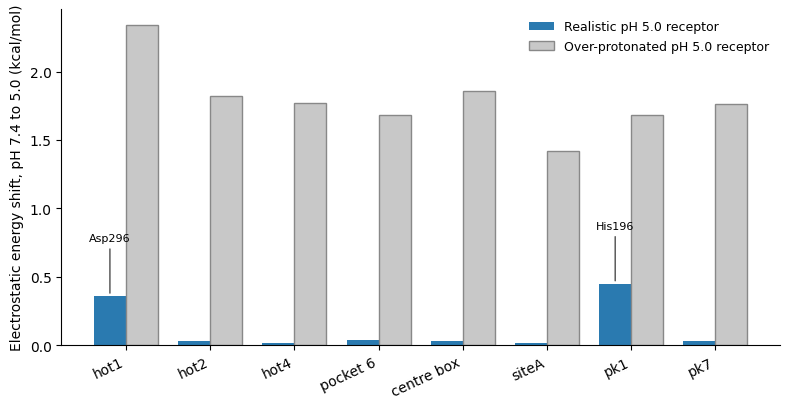

saved: /content/drive/MyDrive/Legumin Hexamer MD/publication_files/Figure3_pH_shifts.png


In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
sites=["hot1","hot2","hot4","pocket 6","centre box","siteA","pk1","pk7"]
realistic=[0.36,0.03,0.02,0.04,0.03,0.02,0.45,0.03]
overprot=[2.34,1.82,1.77,1.68,1.86,1.42,1.68,1.76]
x=np.arange(len(sites)); w=0.38
fig,ax=plt.subplots(figsize=(8,4.2))
ax.bar(x-w/2,realistic,w,label="Realistic pH 5.0 receptor",color="#2a7ab0")
ax.bar(x+w/2,overprot,w,label="Over-protonated pH 5.0 receptor",color="#c8c8c8",edgecolor="#888")
ax.annotate("His196",(6-w/2,0.45),xytext=(6-w/2,0.85),ha="center",fontsize=8,arrowprops=dict(arrowstyle="-",lw=0.7))
ax.annotate("Asp296",(0-w/2,0.36),xytext=(0-w/2,0.76),ha="center",fontsize=8,arrowprops=dict(arrowstyle="-",lw=0.7))
ax.set_xticks(x); ax.set_xticklabels(sites,rotation=25,ha="right")
ax.set_ylabel("Electrostatic energy shift, pH 7.4 to 5.0 (kcal/mol)")
ax.axhline(0,color="k",lw=0.6)
ax.legend(frameon=False,fontsize=9)
for s in ("top","right"): ax.spines[s].set_visible(False)
plt.tight_layout()
out="/content/drive/MyDrive/Legumin Hexamer MD/publication_files/Figure3_pH_shifts.png"
os.makedirs(os.path.dirname(out),exist_ok=True)
plt.savefig(out,dpi=300); plt.show(); print("saved:",out)

In [ ]:
import pandas as pd, os
D="/content/drive/MyDrive/Legumin Hexamer MD"
P=f"{D}/publication_files"
os.makedirs(P,exist_ok=True)

def vina(f):
    for l in open(f"{D}/{f}"):
        if l.startswith("REMARK VINA RESULT"): return float(l.split()[3])

# site, origin, pose file, (elec,dG) at pH7.4 / over-protonated / realistic
rows=[
 ("hot1","targeted","dock_hot1_29_pH50.pdbqt",(-1.26,-19.35),(1.08,-17.37),(-0.90,-19.03)),
 ("hot2","targeted","dock_hot2_29_pH50.pdbqt",(0.25,-16.80),(2.07,-13.61),(0.28,-16.77)),
 ("hot4","targeted","dock_hot4_29_pH50.pdbqt",(-0.12,-18.69),(1.65,-17.13),(-0.10,-18.67)),
 ("pocket6","targeted","dock_pk6_29_pH74.pdbqt",(0.00,-16.14),(1.68,-14.46),(0.04,-16.10)),
 ("centre_box","blind","dock_center_29_pH74.pdbqt",(-0.51,-17.34),(1.35,-15.49),(-0.48,-17.31)),
 ("siteA","blind","dock_siteA_29_pH74.pdbqt",(0.58,-19.23),(2.00,-17.81),(0.60,-19.21)),
 ("pk1","targeted","dock_pk1_29_pH74.pdbqt",(-0.08,-12.96),(1.60,-11.20),(-0.06,-12.94)),
 ("pk7","targeted","dock_pk7_29_pH74.pdbqt",(-0.80,-14.16),(0.96,-12.40),(-0.77,-14.13)),
]
out=[]
for s,o,f,a,b,c in rows:
    out.append(dict(site=s,origin=o,pose_file=f,vina_best=vina(f),
        elec_pH74=a[0],dG_pH74=a[1],elec_overprot=b[0],dG_overprot=b[1],
        elec_realistic=c[0],dG_realistic=c[1]))
df=pd.DataFrame(out)
df["shift_elec_realistic"]=(df.elec_realistic-df.elec_pH74).round(2)
df["shift_dG_realistic"]=(df.dG_realistic-df.dG_pH74).round(2)
df["shift_elec_overprot"]=(df.elec_overprot-df.elec_pH74).round(2)
df["shift_dG_overprot"]=(df.dG_overprot-df.dG_pH74).round(2)
df.to_csv(f"{P}/autodock4_summary_all_sites.csv",index=False)

ctrl=[
 ("hot1","pH7.4",-1.26,-19.35),("hot1","full pH5.0 (over-protonated)",1.08,-17.37),
 ("hot1","7.4 + Asp296 neutral",-0.61,-18.79),("hot1","7.4 + His129 +1",-1.16,-19.00),
 ("hot1","7.4 + acid patch neutral",0.01,-18.54),("hot1","7.4 + Asp296 half neutral",-0.94,-19.07),
 ("hot1","realistic pH5.0",-0.90,-19.03),
 ("pk1","pH7.4",-0.08,-12.96),("pk1","7.4 + His196 +1 (upper bound)",0.40,-12.28),
 ("pk1","realistic pH5.0 + His196 (0.9)",0.37,-12.33),("pk1","realistic pH5.0, His196 neutral",-0.06,-12.94),
]
cd=pd.DataFrame(ctrl,columns=["site","receptor","elec","dG"])
cd.to_csv(f"{P}/autodock4_controls.csv",index=False)

print(df.to_string(index=False))
print("\nsaved to",P)

      site   origin                 pose_file  vina_best  elec_pH74  dG_pH74  elec_overprot  dG_overprot  elec_realistic  dG_realistic  shift_elec_realistic  shift_dG_realistic  shift_elec_overprot  shift_dG_overprot
      hot1 targeted   dock_hot1_29_pH50.pdbqt     -9.397      -1.26   -19.35           1.08       -17.37           -0.90        -19.03                  0.36                0.32                 2.34               1.98
      hot2 targeted   dock_hot2_29_pH50.pdbqt     -7.629       0.25   -16.80           2.07       -13.61            0.28        -16.77                  0.03                0.03                 1.82               3.19
      hot4 targeted   dock_hot4_29_pH50.pdbqt     -8.490      -0.12   -18.69           1.65       -17.13           -0.10        -18.67                  0.02                0.02                 1.77               1.56
   pocket6 targeted    dock_pk6_29_pH74.pdbqt     -9.357       0.00   -16.14           1.68       -14.46            0.04        -16.

In [ ]:
import numpy as np, glob
D="/content/drive/MyDrive/Legumin Hexamer MD"
poses={"hot1":"dock_hot1_29_pH50.pdbqt","hot2":"dock_hot2_29_pH50.pdbqt","hot4":"dock_hot4_29_pH50.pdbqt",
 "pocket6":"dock_pk6_29_pH74.pdbqt","centre_box":"dock_center_29_pH74.pdbqt","siteA":"dock_siteA_29_pH74.pdbqt",
 "pk1":"dock_pk1_29_pH74.pdbqt","pk7":"dock_pk7_29_pH74.pdbqt"}
def centre(f):
    xyz=[]
    for l in open(f):
        if l.startswith("ENDMDL"): break
        if l.startswith(("ATOM","HETATM")) and l.split()[-1]!="HD":
            xyz.append([float(l[30:38]),float(l[38:46]),float(l[46:54])])
    return np.mean(xyz,0)
prot=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in open("/content/dock/rec_29_pH74.pdbqt") if l.startswith("ATOM")])
pc=prot.mean(0); box=np.array([105.6,105.6,49.8])
pk=[]
for f in glob.glob(D+"/**/*pocket*_atm.pdb",recursive=True):
    c=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in open(f) if l.startswith("ATOM")])
    if len(c): pk.append((f.replace(D,""),c.mean(0)))
print("fpocket pocket files found:",len(pk))
print("%-11s %-20s %8s %8s  nearest fpocket (distance A)"%("site","centre","d_box","d_prot"))
for s,f in poses.items():
    c=centre(f"{D}/{f}")
    near=min(((np.linalg.norm(c-p),n) for n,p in pk),default=(float("nan"),"none"))
    print("%-11s %-20s %8.1f %8.1f  %s (%.1f)"%(s,np.round(c,1),np.linalg.norm(c-box),np.linalg.norm(c-pc),near[1],near[0]))

fpocket pocket files found: 0
site        centre                  d_box   d_prot  nearest fpocket (distance A)
hot1        [88.4 67.5 49.8]         41.8     40.1  none (nan)
hot2        [ 89.1 116.7  42.5]      21.1     22.5  none (nan)
hot4        [120.6 113.6  64.7]      22.6     22.1  none (nan)
pocket6     [ 92.2 103.1  33.3]      21.4     23.2  none (nan)
centre_box  [ 96.8 102.1  47.5]       9.7      9.7  none (nan)
siteA       [121.7  98.5  32.6]      24.6     27.2  none (nan)
pk1         [124.2 105.8   9.9]      44.0     47.4  none (nan)
pk7         [109.8 107.7  57.8]       9.2      8.0  none (nan)


In [ ]:
import numpy as np, glob, os, shutil
D="/content/drive/MyDrive/Legumin Hexamer MD"
O=f"{D}/publication_files/pymol"; os.makedirs(O,exist_ok=True)
# EDIT these after the check: blind / fpocket / residue_cluster / centre
sites={"siteA":("dock_siteA_29_pH74.pdbqt","blind"),"centre_box":("dock_center_29_pH74.pdbqt","centre"),
 "pk1":("dock_pk1_29_pH74.pdbqt","fpocket"),"pocket6":("dock_pk6_29_pH74.pdbqt","fpocket"),"pk7":("dock_pk7_29_pH74.pdbqt","fpocket"),
 "hot1":("dock_hot1_29_pH50.pdbqt","residue_cluster"),"hot2":("dock_hot2_29_pH50.pdbqt","residue_cluster"),"hot4":("dock_hot4_29_pH50.pdbqt","residue_cluster")}
col={"blind":"orange","centre":"yellow","fpocket":"forest","residue_cluster":"magenta"}
fr=sorted(glob.glob(D+"/frame29*pH74*.pdb"))+sorted(glob.glob(D+"/frame29*.pdb"))
print("receptor candidates:",[os.path.basename(f) for f in fr][:5])
shutil.copy(fr[0],f"{O}/frame29.pdb"); print("using:",os.path.basename(fr[0]))
pml=["load frame29.pdb, hex","hide everything","show cartoon, hex","util.cbc hex","set cartoon_transparency, 0.5, hex","bg_color white"]
for s,(f,o) in sites.items():
    L=[];xyz=[]
    for l in open(f"{D}/{f}"):
        if l.startswith("ENDMDL"): break
        if l.startswith(("ATOM","HETATM")):
            L.append(l[:66].rstrip()+"\n")
            if l.split()[-1]!="HD": xyz.append([float(l[30:38]),float(l[38:46]),float(l[46:54])])
    open(f"{O}/pose_{s}.pdb","w").write("".join(L))
    c=np.mean(xyz,0)
    pml+=[f"load pose_{s}.pdb, {s}",f"show spheres, {s}",f"color {col[o]}, {s}",f"set sphere_scale, 0.5, {s}",
          f"pseudoatom lbl_{s}, pos=[{c[0]:.1f},{c[1]:.1f},{c[2]:.1f}], label={s}"]
pml+=["hide nonbonded","set label_size, 18","set label_color, black","set ray_opaque_background, on",
      "orient","ray 2400,1800","png figure_sites.png, dpi=300"]
open(f"{O}/fig_sites.pml","w").write("\n".join(pml)+"\n")
print("written to",O)

receptor candidates: ['frame29_pH74.pdb', 'frame29_pH74_ren.pdb', 'frame29.pdb', 'frame29_pH50.pdb', 'frame29_pH50_ren.pdb']
using: frame29_pH74.pdb
written to /content/drive/MyDrive/Legumin Hexamer MD/publication_files/pymol


In [9]:
import numpy as np, subprocess, os, re, glob
os.chdir("/content/dock")
lig=[l for l in open("lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
xyz=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"])
cx,cy,cz=xyz.mean(0)
lt=sorted({l.split()[-1] for l in lig})

d296h={("C",296,"OD1"):-0.25,("C",296,"OD2"):-0.25}
his={("C",265,"ND1"):0.45,("C",265,"NE2"):0.45,("C",387,"ND1"):0.45,("C",387,"NE2"):0.45}
e113={("C",113,"OE1"):-0.06,("C",113,"OE2"):-0.06}   # 88% neutralised
V=[("7.4 + Glu113 88% neutral","rec_29_pH74.pdbqt",e113),
   ("realistic pH5 + Glu113","rec_29_pH74.pdbqt",{**d296h,**his,**e113})]

def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def grid_ok(n):
    return os.path.exists(f"{n}.glg") and "Successful Completion" in open(f"{n}.glg").read()

print("%-30s %8s %8s"%("receptor","elec","free E"),flush=True)
for i,(label,src,ch) in enumerate(V):
    n=f"g{i}"
    out=[]
    for l in open(src):
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        out.append(l)
    open(f"{n}.pdbqt","w").write("".join(out))
    rt=sorted({l.split()[-1] for l in out if l.startswith("ATOM")})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {cx:.3f} {cy:.3f} {cz:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move lig.pdbqt
about {cx:.3f} {cy:.3f} {cz:.3f}
epdb
""")
    if not grid_ok(n):
        subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    e=num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t)
    f=num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t)
    print("%-30s %8.2f %8.2f"%(label,e,f),flush=True)
subprocess.run('mkdir -p "/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4/hot1" && cp g0.* g1.* "/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4/hot1/"',shell=True)

receptor                           elec   free E
7.4 + Glu113 88% neutral          -1.21   -19.48
realistic pH5 + Glu113            -0.85   -19.17


CompletedProcess(args='mkdir -p "/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4/hot1" && cp g0.* g1.* "/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4/hot1/"', returncode=0)

In [7]:
!which autogrid4 autodock4

/usr/local/bin/autogrid4
/usr/local/bin/autodock4


In [8]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
import os, glob, shutil
root="/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4"
lig=glob.glob(root+"/**/lig.pdbqt", recursive=True)
rec=glob.glob(root+"/**/rec_29_pH74_charged.pdbqt", recursive=True)
print(lig, rec)
os.makedirs("/content/dock", exist_ok=True)
shutil.copy(lig[0], "/content/dock/lig.pdbqt")
shutil.copy(rec[0], "/content/dock/rec_29_pH74.pdbqt")
print(os.listdir("/content/dock"))

Mounted at /content/drive
['/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4/hot1/lig.pdbqt'] ['/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4/hot1/rec_29_pH74_charged.pdbqt']
['lig.pdbqt', 'rec_29_pH74.pdbqt']


In [10]:
import numpy as np, subprocess, os, re, glob, shutil
os.chdir("/content/dock")
R="/content/drive/MyDrive/Legumin Hexamer MD/"
summ=open(glob.glob(R+"**/p74.pka",recursive=True)[0]).read().split("SUMMARY OF THIS PREDICTION")[-1]
pk={}
for l in summ.splitlines():
    p=l.split()
    if len(p)>=4 and p[0] in ("ASP","GLU","HIS"):
        try: pk[(p[0],int(p[1]),p[2])]=float(p[3])
        except: pass
fp=lambda p,ph:1/(1+10**(ph-p))
base={"hot2":(0.25,-16.80),"hot4":(-0.12,-18.69),"pocket6":(0.00,-16.14),"centre":(-0.51,-17.34),"pk1":(-0.08,-12.96)}
ligf={"hot2":"lig_hot2.pdbqt","hot4":"lig_hot4.pdbqt","pocket6":"lig6.pdbqt","centre":"lig_c.pdbqt","pk1":"lig_pk1.pdbqt"}
tit={"ASP":("OD1","OD2"),"GLU":("OE1","OE2"),"HIS":("ND1","NE2")}
b2={"ASH":"ASP","GLH":"GLU","HID":"HIS","HIE":"HIS","HIP":"HIS"}
recl=open("rec_29_pH74.pdbqt").read().splitlines(True)
RA=[(l[21],int(l[22:26]),b2.get(l[17:20].strip(),l[17:20].strip()),l[12:16].strip(),
     np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])])) for l in recl if l.startswith("ATOM")]
def num(p,t):
    m=re.search(p,t); return float(m.group(1)) if m else float("nan")
def run(n,ligfile,ch,c):
    out=[]
    for l in recl:
        if l.startswith("ATOM"):
            k=(l[21],int(l[22:26]),l[12:16].strip())
            if k in ch: l=l[:70]+"%+6.3f"%ch[k]+l[76:]
        out.append(l)
    open(f"{n}.pdbqt","w").write("".join(out))
    rt=sorted({l.split()[-1] for l in out if l.startswith("ATOM")})
    lt=sorted({l.split()[-1] for l in open(ligfile) if l.startswith(("ATOM","HETATM"))})
    maps="\n".join(f"map {n}.{t}.map" for t in lt)
    open(f"{n}.gpf","w").write(f"""npts 60 60 60
gridfld {n}.maps.fld
spacing 0.375
receptor_types {' '.join(rt)}
ligand_types {' '.join(lt)}
receptor {n}.pdbqt
gridcenter {c[0]:.3f} {c[1]:.3f} {c[2]:.3f}
smooth 0.5
{maps}
elecmap {n}.e.map
dsolvmap {n}.d.map
dielectric -0.1465
""")
    open(f"{n}.dpf","w").write(f"""autodock_parameter_version 4.2
outlev 1
intelec
ligand_types {' '.join(lt)}
fld {n}.maps.fld
{maps}
elecmap {n}.e.map
desolvmap {n}.d.map
move {ligfile}
about {c[0]:.3f} {c[1]:.3f} {c[2]:.3f}
epdb
""")
    subprocess.run(f"autogrid4 -p {n}.gpf -l {n}.glg",shell=True,capture_output=True)
    subprocess.run(f"autodock4 -p {n}.dpf -l {n}.dlg",shell=True,capture_output=True)
    t=open(f"{n}.dlg").read()
    return (num(r"Total Intermolecular Electrostatic Energy\s*=\s*([-+0-9.]+)",t),
            num(r"Estimated Free Energy of Binding\s*=\s*([-+0-9.]+)",t))
print("%-8s %-34s %7s %8s %7s"%("site","residues edited","elec","free E","shift"),flush=True)
for s in ligf:
    lp=glob.glob(R+"publication_files/autodock4/**/"+ligf[s],recursive=True)[0]
    shutil.copy(lp,f"{s}_lig.pdbqt")
    lig=[l for l in open(f"{s}_lig.pdbqt") if l.startswith(("ATOM","HETATM"))]
    c=np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])] for l in lig if l.split()[-1]!="HD"]).mean(0)
    N=[np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])]) for l in lig if l[12:16].strip()=="N"][0]
    near={}
    for a in RA:
        if a[2] in tit and a[3] in tit[a[2]]:
            k=(a[2],a[1],a[0]); near[k]=min(near.get(k,99),np.linalg.norm(a[4]-N))
    ch={}; names=[]
    for k,d in near.items():
        p=pk.get(k)
        if d<=10 and p and 4.0<=p<=7.5:
            dq=fp(p,5.0)-fp(p,7.4)
            for at in tit[k[0]]:
                ch[(k[2],k[1],at)]=(-0.5*(1-dq)) if k[0] in ("ASP","GLU") else (0.5*dq)
            names.append(f"{k[0]}{k[1]}{k[2]}")
    if s=="pk1":
        e0,f0=run("p_pk1_base",f"{s}_lig.pdbqt",{},c)
        print("%-8s %-34s %7.2f %8.2f   (expect -0.08 / -12.96)"%(s,"pH 7.4 check",e0,f0),flush=True)
    e,f=run("p_"+s,f"{s}_lig.pdbqt",ch,c)
    print("%-8s %-34s %7.2f %8.2f %+7.2f"%(s," ".join(names),e,f,e-base[s][0]),flush=True)
subprocess.run('mkdir -p "'+R+'publication_files/autodock4/pH_aware" && cp p_*.gpf p_*.dpf p_*.dlg p_*.glg "'+R+'publication_files/autodock4/pH_aware/"',shell=True)

site     residues edited                       elec   free E   shift
hot2     GLU291A ASP354F                       0.39   -16.97   +0.14
hot4     ASP354D GLU109E                       0.00   -18.67   +0.12
pocket6  GLU335B                               0.05   -16.11   +0.05
centre   GLU335A                              -0.36   -17.20   +0.15
pk1      pH 7.4 check                         -0.08   -12.96   (expect -0.08 / -12.96)
pk1      HIS196A                               0.28   -12.44   +0.36


CompletedProcess(args='mkdir -p "/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4/pH_aware" && cp p_*.gpf p_*.dpf p_*.dlg p_*.glg "/content/drive/MyDrive/Legumin Hexamer MD/publication_files/autodock4/pH_aware/"', returncode=0)

      site  titrated_near_amine  elec_shift_pHaware  dG_shift_pHaware  elec_shift_overprot  dG_shift_overprot  vina_best
      hot1            Asp296(C)                0.36              0.32                 2.34               1.98     -9.397
      hot2 Glu291(A); Asp354(F)                0.14             -0.17                 1.82               3.19     -7.629
      hot4 Asp354(D); Glu109(E)                0.12              0.02                 1.77               1.56     -8.490
   pocket6            Glu335(B)                0.05              0.03                 1.68               1.68     -9.357
centre_box            Glu335(A)                0.15              0.14                 1.86               1.85     -9.208
     siteA     none within 10 A                0.00              0.00                 1.42               1.42    -10.592
       pk1            His196(A)                0.36              0.52                 1.68               1.76     -6.566
       pk7     none within 10 A 

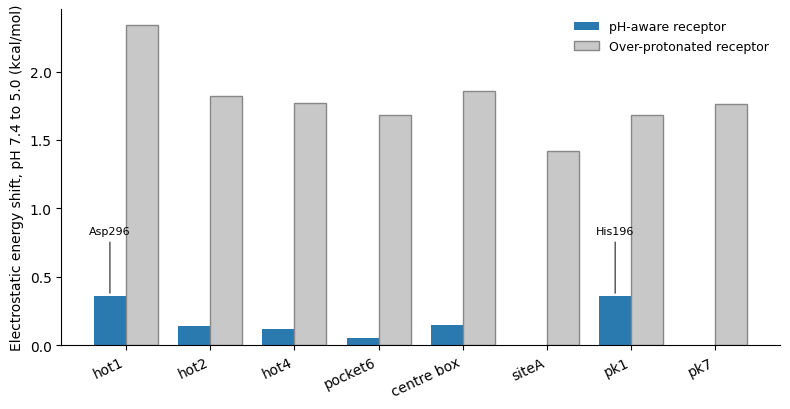

saved to /content/drive/MyDrive/Legumin Hexamer MD/publication_files


In [11]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, os
D="/content/drive/MyDrive/Legumin Hexamer MD"; P=f"{D}/publication_files"
def vina(f):
    for l in open(f"{D}/{f}"):
        if l.startswith("REMARK VINA RESULT"): return float(l.split()[3])
rows=[
("hot1","Asp296(C)","dock_hot1_29_pH50.pdbqt",0.36,0.32,2.34,1.98),
("hot2","Glu291(A); Asp354(F)","dock_hot2_29_pH50.pdbqt",0.14,-0.17,1.82,3.19),
("hot4","Asp354(D); Glu109(E)","dock_hot4_29_pH50.pdbqt",0.12,0.02,1.77,1.56),
("pocket6","Glu335(B)","dock_pk6_29_pH74.pdbqt",0.05,0.03,1.68,1.68),
("centre_box","Glu335(A)","dock_center_29_pH74.pdbqt",0.15,0.14,1.86,1.85),
("siteA","none within 10 A","dock_siteA_29_pH74.pdbqt",0.00,0.00,1.42,1.42),
("pk1","His196(A)","dock_pk1_29_pH74.pdbqt",0.36,0.52,1.68,1.76),
("pk7","none within 10 A","dock_pk7_29_pH74.pdbqt",0.00,0.00,1.76,1.76)]
df=pd.DataFrame(rows,columns=["site","titrated_near_amine","pose_file","elec_shift_pHaware","dG_shift_pHaware","elec_shift_overprot","dG_shift_overprot"])
df["vina_best"]=[vina(f) for f in df.pose_file]
df.to_csv(f"{P}/autodock4_summary_pH_aware.csv",index=False)
print(df.drop(columns="pose_file").to_string(index=False))

x=np.arange(len(df)); w=0.38
fig,ax=plt.subplots(figsize=(8,4.2))
ax.bar(x-w/2,df.elec_shift_pHaware,w,label="pH-aware receptor",color="#2a7ab0")
ax.bar(x+w/2,df.elec_shift_overprot,w,label="Over-protonated receptor",color="#c8c8c8",edgecolor="#888")
for i,r in df.iterrows():
    if r.elec_shift_pHaware>=0.3:
        ax.annotate(r.titrated_near_amine.split("(")[0],(i-w/2,r.elec_shift_pHaware),xytext=(i-w/2,r.elec_shift_pHaware+0.45),ha="center",fontsize=8,arrowprops=dict(arrowstyle="-",lw=0.7))
ax.set_xticks(x); ax.set_xticklabels(df.site.str.replace("_"," "),rotation=25,ha="right")
ax.set_ylabel("Electrostatic energy shift, pH 7.4 to 5.0 (kcal/mol)")
ax.axhline(0,color="k",lw=0.6); ax.legend(frameon=False,fontsize=9)
for s in ("top","right"): ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(f"{P}/Figure3_pH_aware_shifts.png",dpi=300); plt.show()
print("saved to",P)

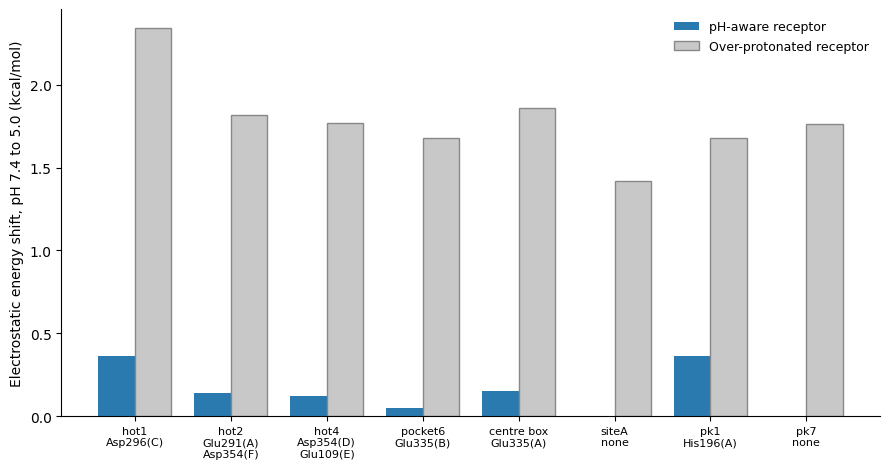

saved


In [12]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
P="/content/drive/MyDrive/Legumin Hexamer MD/publication_files"
df=pd.read_csv(f"{P}/autodock4_summary_pH_aware.csv")
labels=[]
for s,t in zip(df.site,df.titrated_near_amine):
    t="none" if t.startswith("none") else t.replace("; ","\n")
    labels.append(s.replace("_"," ")+"\n"+t)
x=np.arange(len(df)); w=0.38
fig,ax=plt.subplots(figsize=(9,4.8))
ax.bar(x-w/2,df.elec_shift_pHaware,w,label="pH-aware receptor",color="#2a7ab0")
ax.bar(x+w/2,df.elec_shift_overprot,w,label="Over-protonated receptor",color="#c8c8c8",edgecolor="#888")
ax.set_xticks(x); ax.set_xticklabels(labels,fontsize=8)
ax.set_ylabel("Electrostatic energy shift, pH 7.4 to 5.0 (kcal/mol)")
ax.axhline(0,color="k",lw=0.6); ax.legend(frameon=False,fontsize=9)
for s in ("top","right"): ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(f"{P}/Figure3_pH_aware_shifts.png",dpi=300); plt.show()
print("saved")

In [13]:
%%bash
P="/content/drive/MyDrive/Legumin Hexamer MD/publication_files"
mkdir -p "$P/superseded"
mv -f "$P/autodock4_summary_all_sites.csv" "$P/Figure3_pH_shifts.png" "$P/superseded/" 2>/dev/null
ls "$P"

autodock4
autodock4_controls.csv
autodock4_summary_pH_aware.csv
docking_vina
Figure3_pH_aware_shifts.png
fpocket
ligand
md_analysis
pka
pymol
structures
superseded


In [14]:
!mamba install -y -q -c conda-forge pymol-open-source
!which pymol

/usr/local/bin/pymol
